# Lab 1: Building and Evaluating Convolutional Neural Networks

Scalable Machine Learning - Tasks 1-6 and Challenge 2


This is an executed integration and presentation notebook. The 13 original training runs are preserved in the supplied artifacts. The following cells audit those records and render the final results; they do not rerun GPU training.


In [1]:
from pathlib import Path
import subprocess
import sys

SOURCE_REF = 'b0a439c3cd71c723283c0dc458d19be1f3d83aff'
COLAB = Path('/content').exists()
if COLAB:
    ROOT = Path('/content/ScalableMlLab_submission')
    if not (ROOT / '.git').exists():
        subprocess.check_call(['git', 'clone', '--no-checkout',
                               'https://github.com/Mrpooool/ScalableMlLab.git', str(ROOT)])
    subprocess.check_call(['git', '-C', str(ROOT), 'fetch', 'origin', SOURCE_REF])
    subprocess.check_call(['git', '-C', str(ROOT), 'checkout', '--detach', SOURCE_REF])
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           '-r', str(ROOT / 'lab1/requirements.txt')])
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / 'lab1/src/submission.py').exists())
sys.path.insert(0, str(ROOT / 'lab1/src'))
from submission import audit_results, show_task, show_implementation
print('Pinned source revision:', SOURCE_REF)
print('Saved GPU measurements will be audited and displayed; no GPU training is requested.')
audit_results(ROOT)


Pinned source revision: b0a439c3cd71c723283c0dc458d19be1f3d83aff
Saved GPU measurements will be audited and displayed; no GPU training is requested.
Display/audit runtime: Linux-6.6.159+-x86_64-with-glibc2.39 | Python 3.13.18 | torch 2.14.1+cpu | GPU used: none
PASS: disjoint 45k/5k split; 13 complete 30-epoch histories; 41 prediction conditions agree with saved metrics.
Saved measurements retain their original training and inference hardware.


,exp_id,epochs,training_device,best_val_acc,test_acc
0,t6_alexnet_cifar_no_aug_s42,30,Tesla T4,0.8296,0.8266
1,t4_resnet18_cifar_no_aug_s42,30,Tesla T4,0.8742,0.8658
2,t4_resnet18_cifar_crop_flip_s42,30,Tesla T4,0.9304,0.9308
3,t6_resnet18_cifar_crop_flip_s0,30,Tesla T4,0.9302,0.9279
4,t6_resnet18_cifar_crop_flip_s123,30,Tesla T4,0.9336,0.9292
5,t2_alexnet_cifar_baseline_s42,30,NVIDIA GeForce RTX 5070 Ti Laptop GPU,0.8300,0.8214
6,t2_resnet18_cifar_baseline_s42,30,NVIDIA GeForce RTX 5070 Ti Laptop GPU,0.8730,0.8701
7,t3_alexnet_reference_s42,30,Tesla T4,0.8346,0.8266
8,t3_alexnet_width_half_s42,30,Tesla T4,0.8130,0.8052
9,t3_alexnet_dropout_zero_s42,30,Tesla T4,0.8046,0.7991


## Experimental overview

We trained CIFAR-10 adaptations of AlexNet and ResNet-18, investigated capacity,
Dropout and L2 regularization, and evaluated clean, corrupted and adversarial
inputs. The evidence comprises two original baseline runs, six controlled AlexNet
runs and five augmentation/cost runs. Each run used 30 epochs and 1,350,000 training
examples. Challenge 2 evaluates frozen models on STL-10; Challenge 1 was not attempted.

The primary deliverable is `lab1/notebooks/lab1_submission.ipynb`. It executes the
artifact audit, checks the architecture implementation on CPU, and displays the
final measured tables and figures. Training was completed in earlier sessions;
executing this notebook re-displays and checks those results without retraining.
The original executed role notebooks, complete Python implementation, frozen
configurations and histories accompany it. These distinctions also apply to the
notebook's source-code appendix and reproduction instructions.

| Evidence group | Training hardware | Evaluation / inference hardware | Purpose |
|---|---|---|---|
| Original baselines (A), 2 runs | RTX 5070 Ti Laptop | RTX 5070 Ti Laptop | Tasks 1-2; checkpoints reused for Task 5 |
| Capacity / regularization (B), 6 runs | Tesla T4 | Tesla T4 | Task 3 controlled comparisons |
| Frozen A checkpoints, evaluated by B | Original A training | Tesla T4 | Task 5 prediction and attack analysis |
| Augmentation / cost (C), 5 runs | Tesla T4 | Jade RTX 2000 Ada Generation | Tasks 4, 6 and Challenge 2 |

All numerical cost rankings below stay within a hardware group and measurement
procedure. A's original timings remain provenance records; the shared same-device runs
provide the final architecture cost comparison. Moving outputs into Colab does
not change where a model was trained or benchmarked. A's original software was
PyTorch 2.11.0+cu128; B's T4 session used 2.14.1+cu130. The JSON records retain the
environment for each run. Differences between independent runs are not attributed
to hardware alone.



## Task 1: data preparation and reproducibility

Each CIFAR-10 example is a labelled 32 x 32 RGB image. The official 50,000 training
images and 10,000 test images are balanced across airplane, automobile, bird, cat,
deer, dog, frog, horse, ship and truck. Raw arrays are uint8 in [0,255]. We used a
stratified split with seed 2223, preserving 4,500 training and 500 validation images
per class. The official test set has 1,000 examples per class and was reserved for
evaluation after the experiment settings had been fixed.



Only the 45,000 training images contributed to channel statistics: mean
[0.4913, 0.4822, 0.4464] and standard deviation [0.2470, 0.2434, 0.2615]. Both
architectures receive the same normalized 32 x 32 inputs. The loaders preserve
raw [0,1] pixels and original image IDs; differentiable normalization is applied
before the model. This keeps Task 5's perturbation constraint in raw pixel units
and allows STL-10 images to use the same preprocessing after resizing.

`split_indices.json` stores the exact disjoint partitions. The shared seed module
sets Python, NumPy, PyTorch and CUDA randomness, and seeded generators fix batch
order. Training seed is 42 except for the shared additional seeds 0 and 123. Fixed seeds
make the procedure repeatable within an environment; floating-point kernels and
software versions can still affect predictions across devices. No test image is
used to compute normalization or select a checkpoint.



Image shape: [32, 32, 3] | dtype: uint8
Split counts: {'official_train_total': 50000, 'train_split': 45000, 'val_split': 5000, 'official_test': 10000}


,mean,std
red,0.491318,0.247001
green,0.482180,0.243401
blue,0.446389,0.261544


,train,val,test
airplane,4500,500,1000
automobile,4500,500,1000
bird,4500,500,1000
cat,4500,500,1000
deer,4500,500,1000
dog,4500,500,1000
frog,4500,500,1000
horse,4500,500,1000
ship,4500,500,1000
truck,4500,500,1000


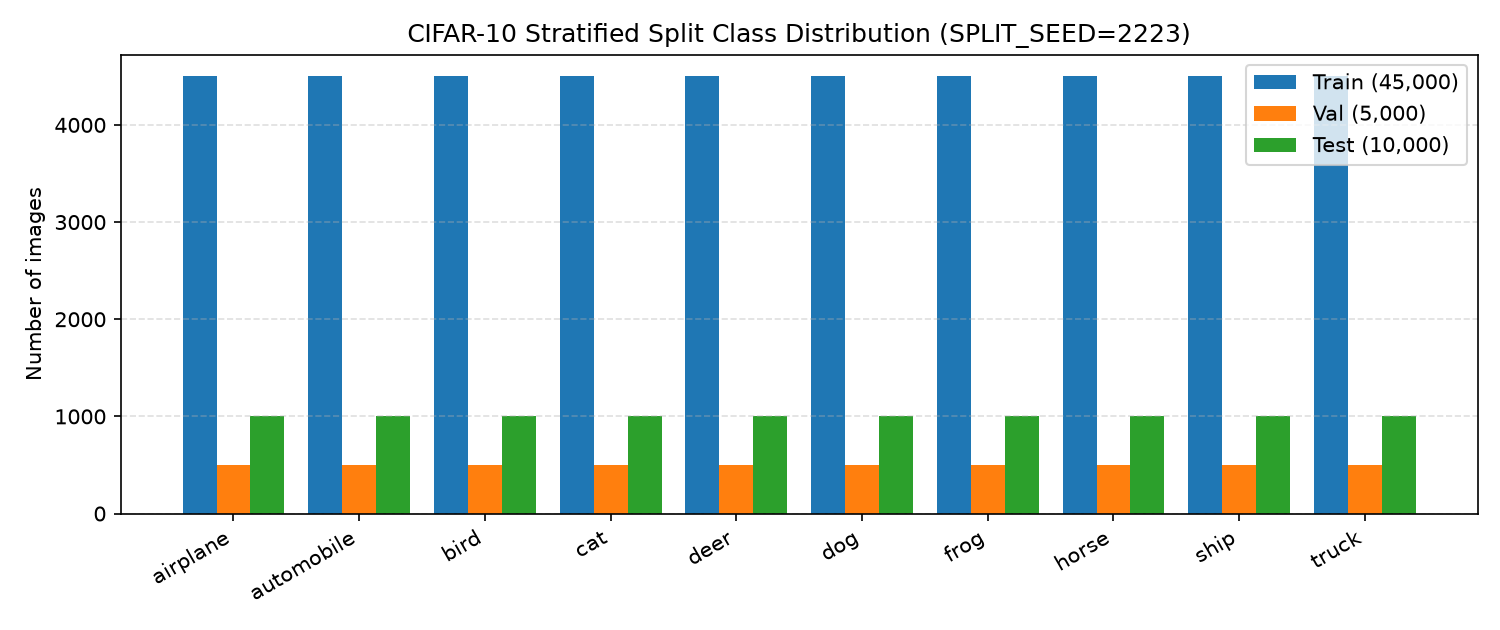

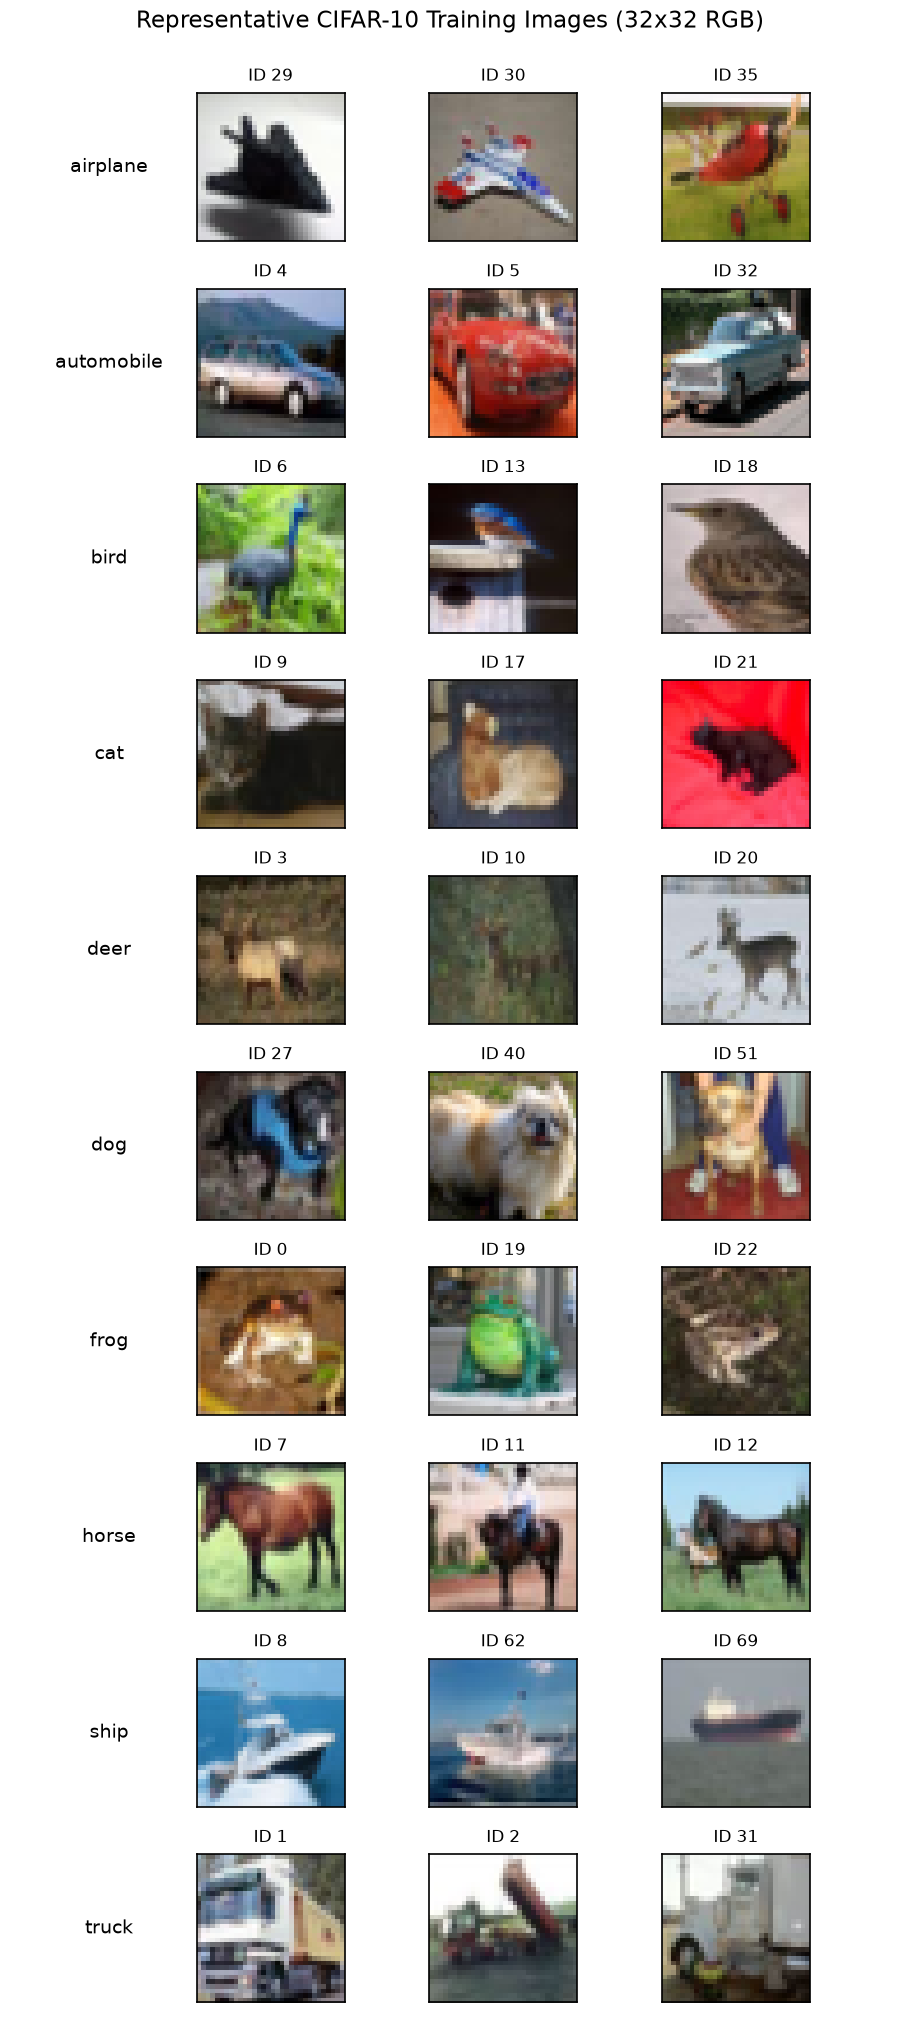

In [2]:
show_task(ROOT, '1')


## Task 2: implementation and baseline comparison

Both networks are implemented from PyTorch layers without pretrained weights or
`torchvision.models` constructors, following the course Part A9 adaptations.
AlexNet keeps five convolutions and three fully connected layers. Its ImageNet
11 x 11 stride-4 stem is replaced with 3 x 3 stride-1 padding-1 convolutions and
three 2 x 2 stride-2 max pools, preserving useful resolution on 32 x 32 images.
Its two hidden FC layers use ReLU and Dropout 0.5.

ResNet-18 uses a 3 x 3 stride-1 stem and omits ImageNet's initial max pool. Four
stages contain two residual blocks each, followed by global average pooling and
a ten-logit linear head. Each block uses two 3 x 3 convolutions with batch
normalization. The shortcut adds the input to the learned residual; a 1 x 1
projection aligns channels and resolution when they change. This path assists
gradient propagation through the deeper network. No softmax is applied before
cross-entropy, which consumes the raw logits.

| Architecture | Stage outputs (channels x height x width) | Head | Parameters |
|---|---|---|---:|
| AlexNetCIFAR | 64 x 16 x 16; 192 x 8 x 8; 256 x 4 x 4 | 4096 -> 1024 -> 512 -> 10 | 6,976,842 |
| ResNet18CIFAR | stem/stage1 64 x 32 x 32; stage2 128 x 16 x 16; stage3 256 x 8 x 8; stage4 512 x 4 x 4 | GAP -> 512 -> 10 | 11,173,962 |

AlexNet's last convolution group uses 384, 256 and 256 channels before pooling.
Convolution applies shared local filters across the image. For kernel size K,
padding P and stride S, output size is floor((H + 2P - K)/S) + 1. The 3 x 3,
stride-1, padding-1 layers retain spatial size; pooling or stride-2 stage entries
reduce it. Repeated local operations expand the receptive field, allowing later
features to combine edges, textures and object parts. AlexNet allocates roughly
67.7% of its parameters to its FC head, while ResNet's ten-class head contains
only 5,130 parameters.

Both baselines used FP32, batch size 128, SGD with momentum 0.9 and weight decay
5e-4, cosine annealing, no training augmentation and 30 epochs. Learning rates
were 0.01 for AlexNet and 0.1 for ResNet. These architecture-specific rates were
fixed before testing. Checkpoints maximize validation accuracy; lower validation
cross-entropy breaks ties. The budget is equal in examples and epochs, with
different measured compute costs. Train-evaluation passes disable Dropout and
use deterministic preprocessing, making their metrics comparable to validation.

| Metric | AlexNet | ResNet-18 |
|---|---:|---:|
| Selected epoch | 24 | 28 |
| Best validation accuracy | 0.8300 | 0.8730 |
| Selected validation CE | 0.9030 | 0.4223 |
| Original clean test accuracy | 0.8214 | 0.8701 |
| Original test CE | 0.9310 | 0.4357 |
| Original test macro F1 | 0.8205 | 0.8698 |
| Final deterministic training accuracy | 1.0000 | 1.0000 |

ResNet improved clean accuracy by 4.87 percentage points under the equal-epoch
budget. Both networks fitted the training data almost perfectly and retained a
validation gap. AlexNet's rising validation cross-entropy indicates increasingly
confident mistakes even while accuracy improves slightly. ResNet reached a
higher validation plateau and lower loss. These observations motivate controlled
regularization experiments in Task 3.


A's original RTX training times were 248.24 s and 684.97 s. Final cost conclusions
use the shared same-device T4 training and Jade inference measurements in Task 6. B's
later T4 evaluation of these same A weights produced 0.8702 for ResNet, one image
above A's original 0.8701. Task 2 preserves the original record; every Task 5
metric uses the later prediction arrays consistently.



alexnet_cifar {'total_params': 6976842, 'trainable_params': 6976842} | fresh CPU architecture check passed


,stage,shape
0,stage1,"[1, 64, 16, 16]"
1,stage2,"[1, 192, 8, 8]"
2,stage3,"[1, 256, 4, 4]"
3,classifier,"[1, 10]"


resnet18_cifar {'total_params': 11173962, 'trainable_params': 11173962} | fresh CPU architecture check passed


,stage,shape
0,stem,"[1, 64, 32, 32]"
1,stage1,"[1, 64, 32, 32]"
2,stage2,"[1, 128, 16, 16]"
3,stage3,"[1, 256, 8, 8]"
4,stage4,"[1, 512, 4, 4]"
5,head,"[1, 10]"


summary.csv


,exp_id,task,owner,model,seed,epochs,batch_size,optimizer,lr,weight_decay,...,total_train_time_sec,peak_gpu_mem_mb,best_epoch,best_val_acc,best_val_ce,final_train_eval_acc,clean_test_acc,macro_f1,bs1_latency_ms,bs128_throughput_imgs_per_sec
0,t2_alexnet_cifar_baseline_s42,task2,role_a,alexnet_cifar,42,30,128,sgd,0.01,0.0005,...,248.240,316.07,24,0.830,0.902950,1.0,0.8214,0.820482,3.059050,41853.673019
1,t2_resnet18_cifar_baseline_s42,task2,role_a,resnet18_cifar,42,30,128,sgd,0.10,0.0005,...,684.971,834.62,28,0.873,0.422264,1.0,0.8701,0.869797,11.627854,11404.723338


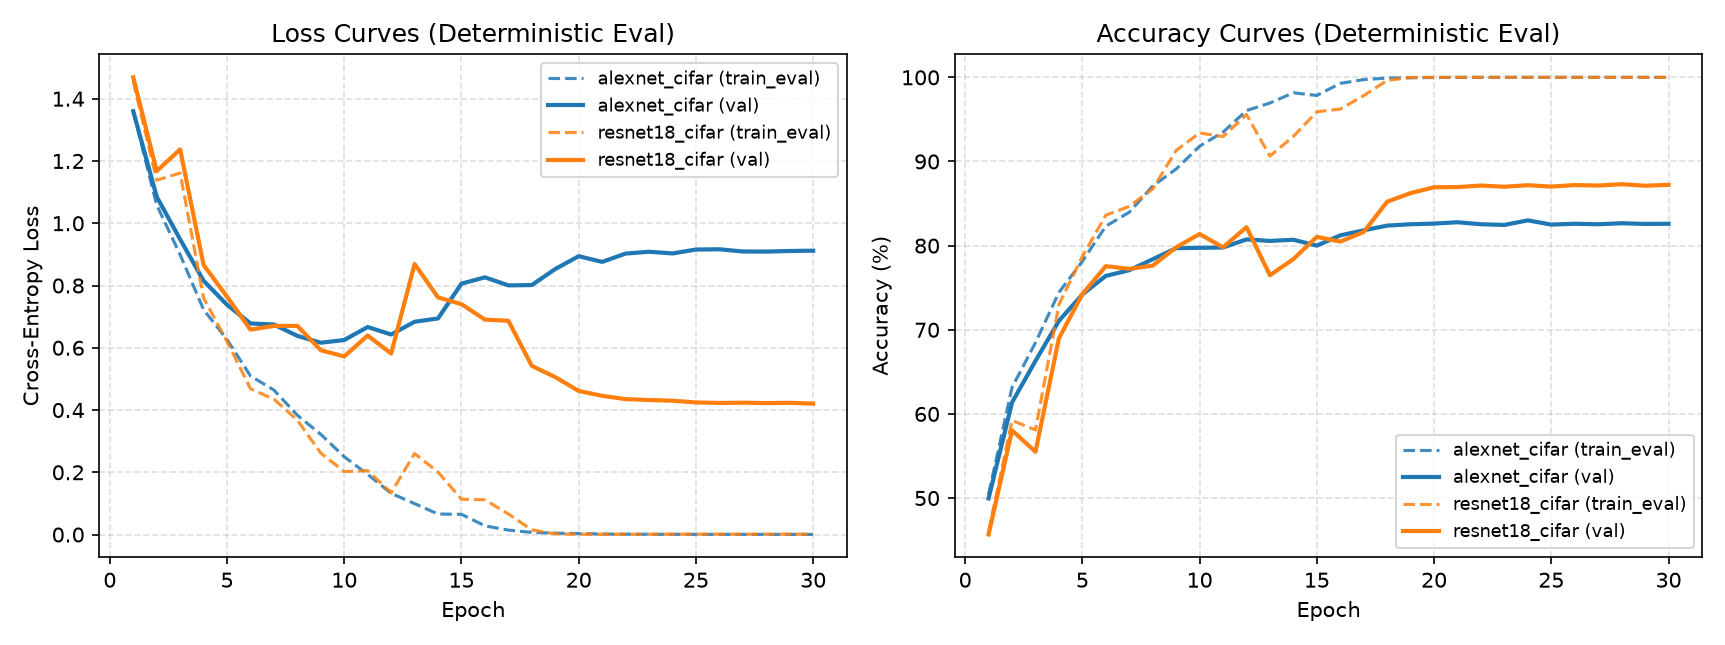

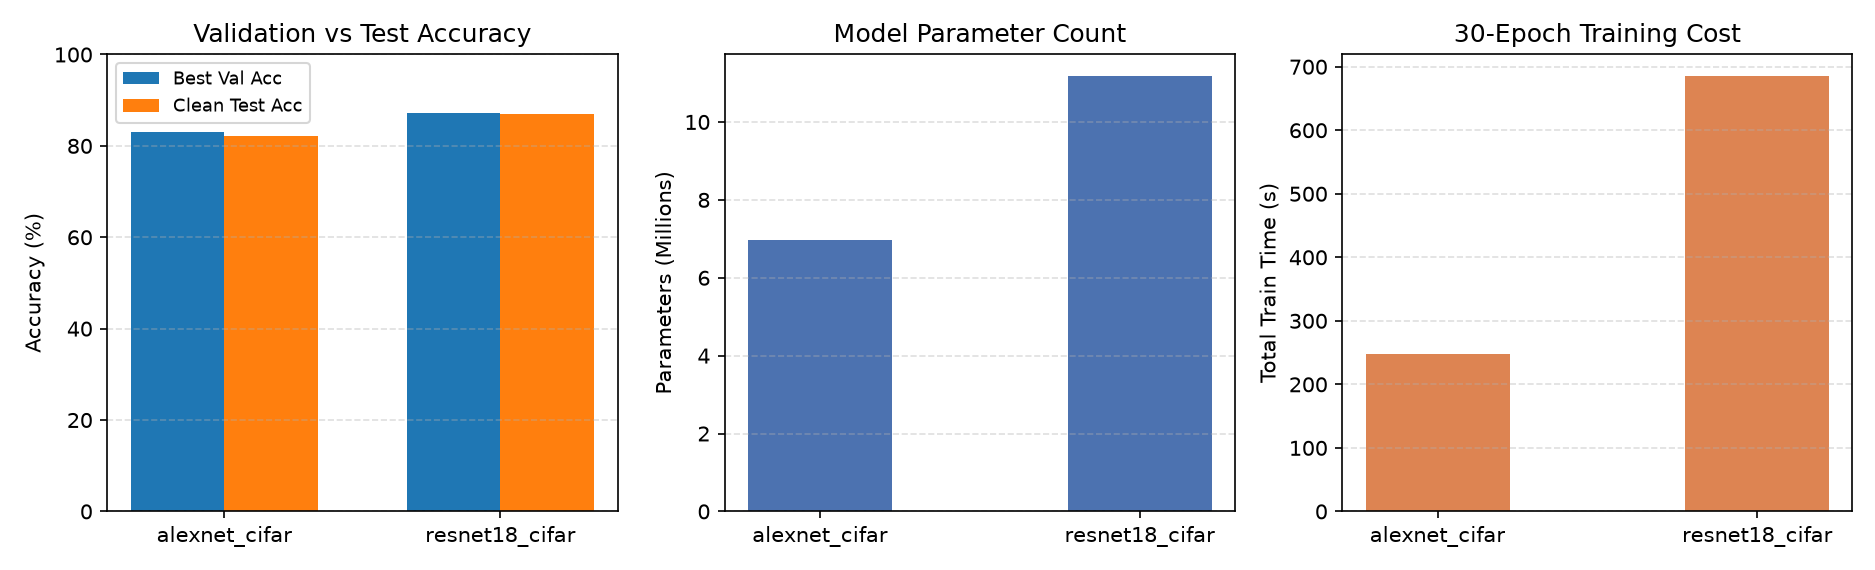

In [3]:
show_task(ROOT, '2')


## Task 3: capacity and regularization

### Controlled protocol

We used the team's CIFAR-10 pipeline and manually implemented networks. The frozen
stratified split (split seed 2223) divided the official 50,000-image training set
into 45,000 training and 5,000 validation images. We computed normalization
statistics from the training partition alone and reserved the 10,000-image official
test set for final evaluation after fixing the experimental protocol.

For Task 3, we trained AlexNetCIFAR for 30 epochs with seed 42 and batch size 128.
We used SGD with momentum 0.9, an initial learning rate of 0.01 and cosine annealing,
without training augmentation. Each run started from fresh weights and processed
1,350,000 training examples. We selected the checkpoint with the highest validation
accuracy, using lower validation cross-entropy to break ties.

After every epoch, we measured deterministic train_eval and validation metrics with
Dropout disabled. These cross-entropy values exclude the L2 penalty. All six runs
used the same Tesla T4, FP32 and PyTorch 2.14.1+cu130. Training time includes the
validation and train_eval passes after each epoch.

| Configuration | Convolution width | Dropout | SGD weight decay |
|---|---:|---:|---:|
| Reference | 1.0 | 0.5 | 5e-4 |
| Half width | 0.5 | 0.5 | 5e-4 |
| No dropout | 1.0 | 0 | 5e-4 |
| Moderate dropout | 1.0 | 0.25 | 5e-4 |
| No L2 | 1.0 | 0.5 | 0 |
| Weak L2 | 1.0 | 0.5 | 1e-4 |

Each capacity, Dropout or L2 comparison changes one factor from the same reference.
Width scaling changes the channel counts in all five convolutional layers. The FC
hidden dimensions remain 1024 and 512, while the FC input follows the final
feature-map width. Both hidden FC layers apply Dropout after ReLU. SGD weight decay
acts on all trainable parameters, including biases, without an additional L2 term
in the loss.

### Results and interpretation

Results use the checkpoints selected by validation accuracy. Accuracy is expressed
as a percentage. Training time and peak allocated GPU memory follow the shared
training procedure; batch-one latency measures the model forward pass using the
shared benchmark.

| Configuration | Parameters | Best val % (epoch) | Test % | Train s | Peak MiB | Batch-one ms |
|---|---:|---:|---:|---:|---:|---:|
| Reference | 6,976,842 | 83.46 (30) | 82.66 | 358.60 | 314.94 | 0.647 |
| Half width | 3,191,722 | 81.30 (29) | 80.52 | 175.93 | 160.59 | 0.661 |
| No dropout | 6,976,842 | 80.46 (15) | 79.91 | 371.39 | 314.94 | 0.659 |
| Dropout 0.25 | 6,976,842 | 81.38 (21) | 81.45 | 370.44 | 314.94 | 0.639 |
| No L2 | 6,976,842 | 83.14 (24) | 82.19 | 365.82 | 315.07 | 0.727 |
| Weak L2 | 6,976,842 | 83.14 (23) | 81.35 | 367.69 | 314.94 | 0.662 |

Halving convolutional width reduced the parameter count by 54.25%, training time by
50.94% and peak allocated memory by about 49%. This saving cost 2.16 percentage
points of validation accuracy and 2.14 points of test accuracy. Both models reached
approximately 100% deterministic training accuracy, while validation accuracy
plateaued near 81-83%. The smaller model could still fit the training set, so its
lower validation accuracy points to a generalization gap rather than persistent
training underfitting. Batch-one latency was 0.661 versus 0.647 ms: the smaller
parameter count gave no measured single-image speedup on T4.


With width and weight decay fixed, Dropout 0, 0.25 and 0.5 gave best validation
accuracies of 80.46%, 81.38% and 83.46%, respectively. The run without Dropout fitted
the training set faster and reached its best validation accuracy at epoch 15.
Validation cross-entropy then rose as training cross-entropy approached zero.
Dropout 0.5 slowed training fit and kept validation cross-entropy lower than the
other settings. All three runs fitted the training set by the end; the widening
train/validation gap supports overfitting, with little evidence of sustained
optimization failure.

Parameter counts were identical and training costs were similar across the Dropout
settings. Since Dropout is disabled during inference, the small latency differences
provide no evidence of a systematic Dropout inference cost. We used the
training-time random unit removal described by
[Srivastava et al. (2014)](https://jmlr.org/papers/v15/srivastava14a.html).


With weight decay 5e-4, best validation accuracy was 83.46%, compared with
83.14% for both 0 and 1e-4. Cross-entropy at the selected checkpoints was 0.887,
1.065 and 0.991, respectively. The stronger tested decay therefore appeared to
reduce confident validation errors more clearly than it improved accuracy. Test
accuracy was 82.66%, 82.19% and 81.35% in the same order, so the accuracy gain was
not monotonic across decay settings. Model size and training cost changed little.
The reference gave the best measured accuracy under this budget; half width gave
the largest training resource saving.




role_b_task3_summary.csv


,exp_id,name,width_mult,dropout,weight_decay,params,best_val_acc,best_val_ce,best_epoch,final_train_eval_acc,final_val_acc,training_sec,trained_samples,peak_gpu_mem_mb,device,test_acc,bs1_latency_ms
0,t3_alexnet_reference_s42,reference,1.0,0.50,0.0005,6976842,0.8346,0.886515,30,1.000000,0.8346,358.596,1350000,314.94,Tesla T4,0.8266,0.647171
1,t3_alexnet_width_half_s42,width_half,0.5,0.50,0.0005,3191722,0.8130,0.985985,29,0.999889,0.8128,175.935,1350000,160.59,Tesla T4,0.8052,0.660939
2,t3_alexnet_dropout_zero_s42,dropout_zero,1.0,0.00,0.0005,6976842,0.8046,1.134273,15,1.000000,0.8028,371.390,1350000,314.94,Tesla T4,0.7991,0.659253
3,t3_alexnet_dropout_quarter_s42,dropout_quarter,1.0,0.25,0.0005,6976842,0.8138,0.973340,21,1.000000,0.8126,370.438,1350000,314.94,Tesla T4,0.8145,0.639251
4,t3_alexnet_l2_zero_s42,l2_zero,1.0,0.50,0.0000,6976842,0.8314,1.064778,24,1.000000,0.8296,365.824,1350000,315.07,Tesla T4,0.8219,0.727297
5,t3_alexnet_l2_weak_s42,l2_weak,1.0,0.50,0.0001,6976842,0.8314,0.990880,23,1.000000,0.8280,367.689,1350000,314.94,Tesla T4,0.8135,0.661835


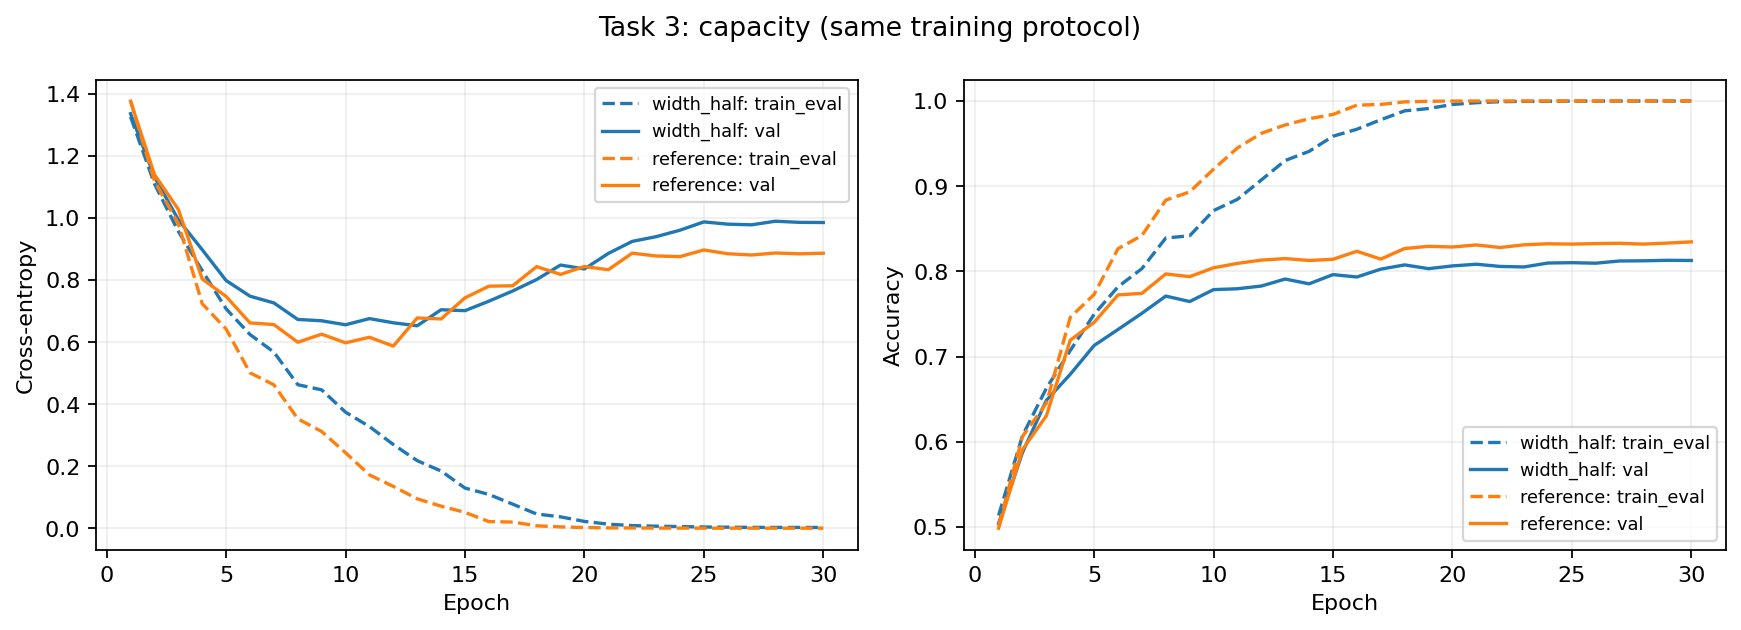

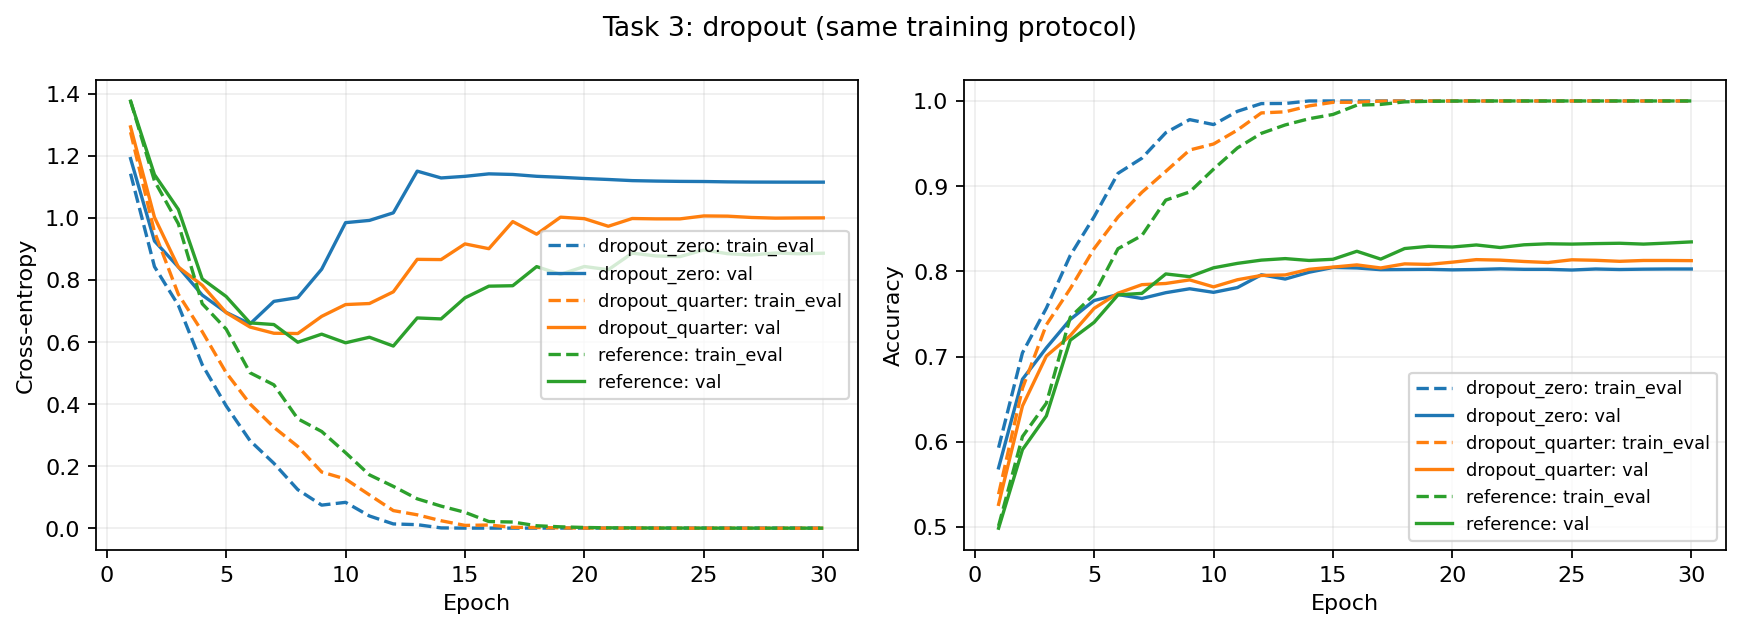

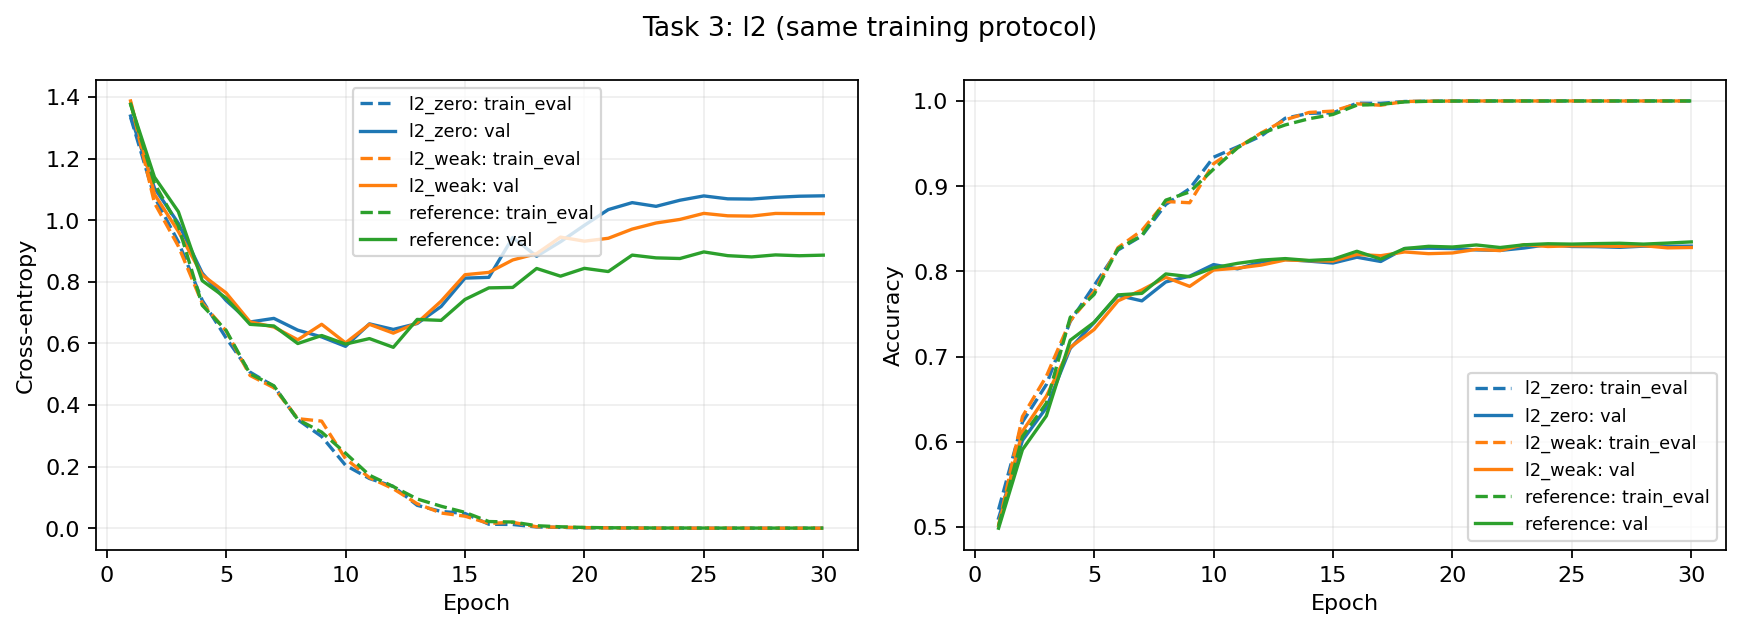

In [4]:
show_task(ROOT, '3')


## Task 4: augmentation and robustness

We compared two independently trained seed-42 ResNets from the shared frozen matrix.
Architecture, split, initialization seed, optimizer, schedule, batch size and
30-epoch budget were held fixed. The augmented condition adds a padded random
32 x 32 crop (padding 4) and horizontal flip (probability 0.5) to training only.
These small geometric changes usually preserve object identity; stronger crops
can remove the object and make the label ambiguous.

The evaluation recipe was fixed before evaluation in `corruptions_t4.json`.
Each of the same 10,000 test IDs receives a generator seeded by 2223 + image_id.
Rotation samples an angle uniformly in [-15,+15] degrees with bilinear resampling
and zero fill. Translation samples independent integer offsets in [-3,+3] pixels
with zero fill. Gaussian noise has standard deviation 0.05 and pixels are clamped
to [0,1]. Image IDs and corruption parameters match across models and sessions.

| Condition | No augmentation | Crop + flip | Accuracy difference |
|---|---:|---:|---:|
| Clean | 0.8658 | 0.9308 | +0.0650 |
| Rotation | 0.7680 | 0.8871 | +0.1191 |
| Translation | 0.8014 | 0.9281 | +0.1267 |
| Gaussian noise | 0.7133 | 0.6814 | -0.0319 |
| Mean of the three corruptions | 0.7609 | 0.8322 | +0.0713 |



Crop plus flip increased clean and geometric-corruption accuracy, with translation
accuracy almost matching clean accuracy. Noise performance fell by 3.19 points.
Among each model's own clean-correct predictions, rotation made 1,270/8,658
incorrect without augmentation and 593/9,308 with augmentation; translation made
1,032/8,658 and 173/9,308 incorrect. Noise made 1,767/8,658 and 2,658/9,308
incorrect. The resulting noise failure rates are 20.41% and 28.56%.

The augmented model's noise recall was lowest for dog (0.422), airplane (0.474)
and cat (0.543), while frog retained 0.966. Both networks fitted deterministic
training images closely (1.0000 and 0.9972 final train_eval accuracy). Training
fit alone therefore does not explain the noise weakness. Changes in reliance on
texture or coarse shape are possible explanations that this experiment does not
isolate. The notebook includes per-class drops and paired same-ID examples.


T4 training took 1,855.352 s without augmentation and 1,859.826 s with it, an
additional 4.474 s (0.24%). Both peaked at 802.99 MiB of allocated GPU memory.
On Jade, a full ResNet evaluation pass took approximately 1.418-1.435 s across
conditions. These end-to-end passes include data loading and CPU corruption;
they do not isolate the transform's computation time. A single mild corruption
realization supports conclusions about this suite and severity only.



role_c_summary.csv


,exp_id,task,model,seed,augmentation,device_name,training_device_name,inference_device_name,total_params,best_epoch,...,mean_corrupted_acc,stl10_10way_acc,stl10_9way_masked_acc,stl10_frog_leakage_rate,domain_drop_9way,total_train_time_sec,peak_gpu_mem_mb,bs1_latency_ms,bs128_latency_ms_per_batch,bs128_throughput_imgs_per_sec
0,t6_alexnet_cifar_no_aug_s42,task6,alexnet_cifar,42,none,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,6976842,28,...,0.720667,0.667500,0.682500,0.031389,0.148500,353.666,316.91,0.308709,4.496393,28467.264682
1,t4_resnet18_cifar_no_aug_s42,task4,resnet18_cifar,42,none,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,11173962,28,...,0.760900,0.710694,0.726667,0.035139,0.141667,1855.352,802.99,0.905939,16.795464,7621.105181
2,t4_resnet18_cifar_crop_flip_s42,task4,resnet18_cifar,42,crop32_pad4_hflip05,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,11173962,30,...,0.832200,0.801389,0.810833,0.018472,0.123056,1859.826,802.99,0.914313,16.856545,7593.489759
3,t6_resnet18_cifar_crop_flip_s0,task6,resnet18_cifar,0,crop32_pad4_hflip05,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,11173962,30,...,0.825300,0.800972,0.812778,0.023889,0.115556,1858.514,802.99,0.852418,16.898406,7574.679098
4,t6_resnet18_cifar_crop_flip_s123,task6,resnet18_cifar,123,crop32_pad4_hflip05,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,11173962,29,...,0.822100,0.799306,0.809306,0.018889,0.121917,1856.025,802.99,0.849120,16.892198,7577.462514


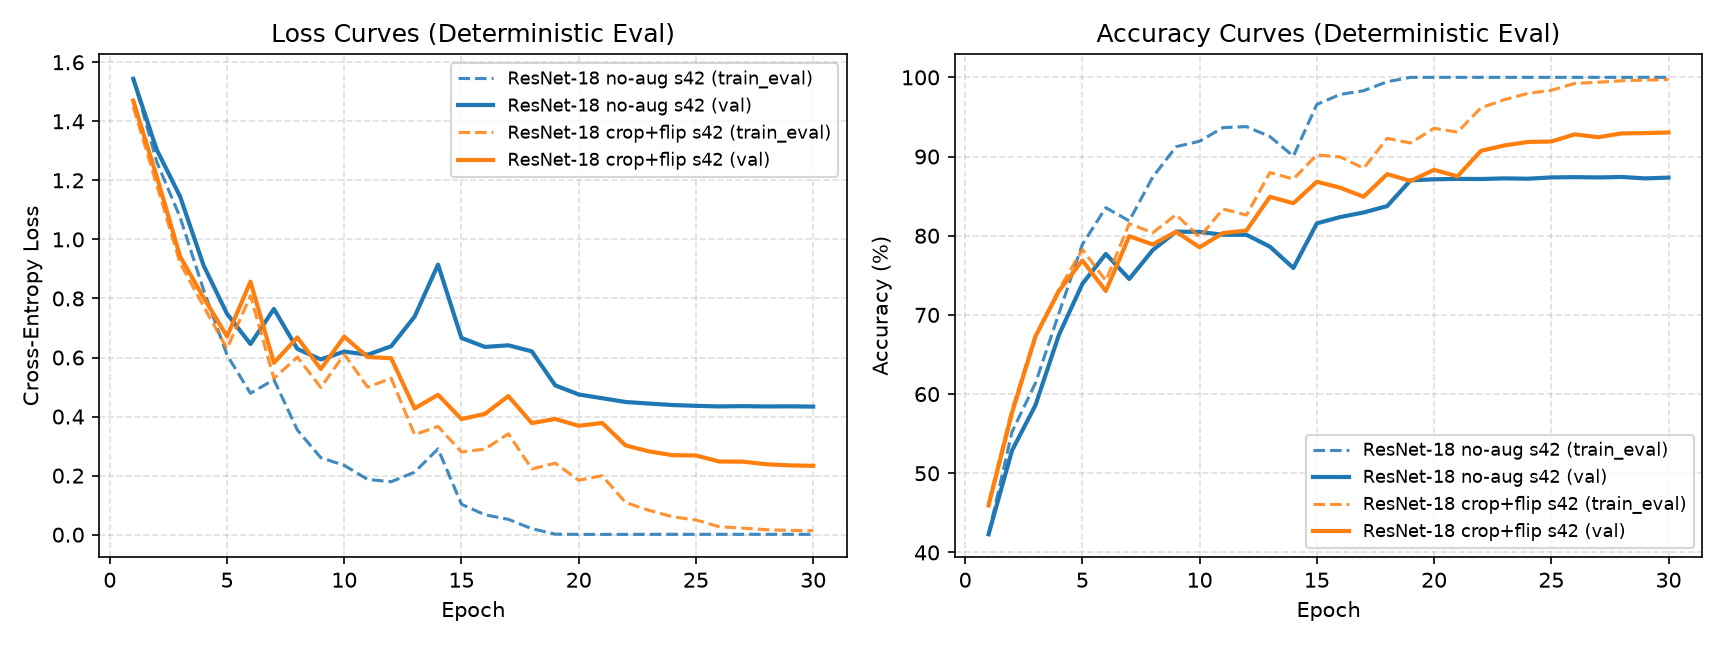

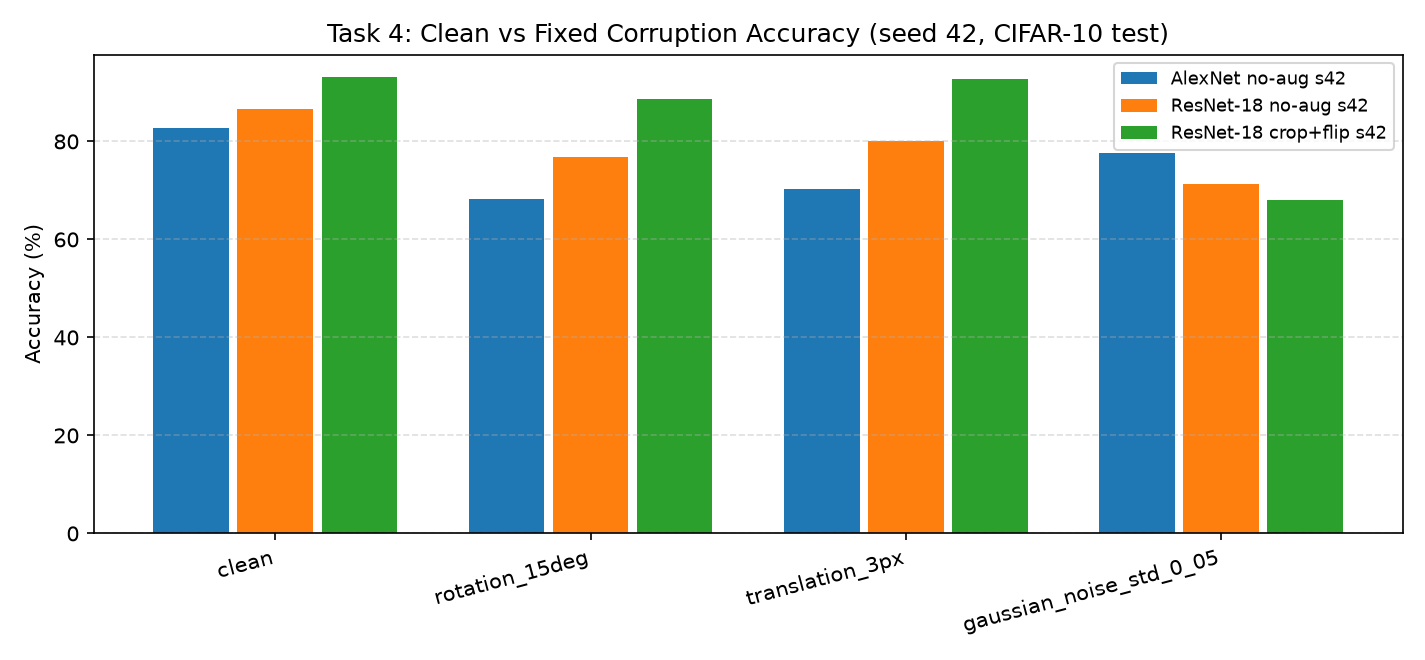

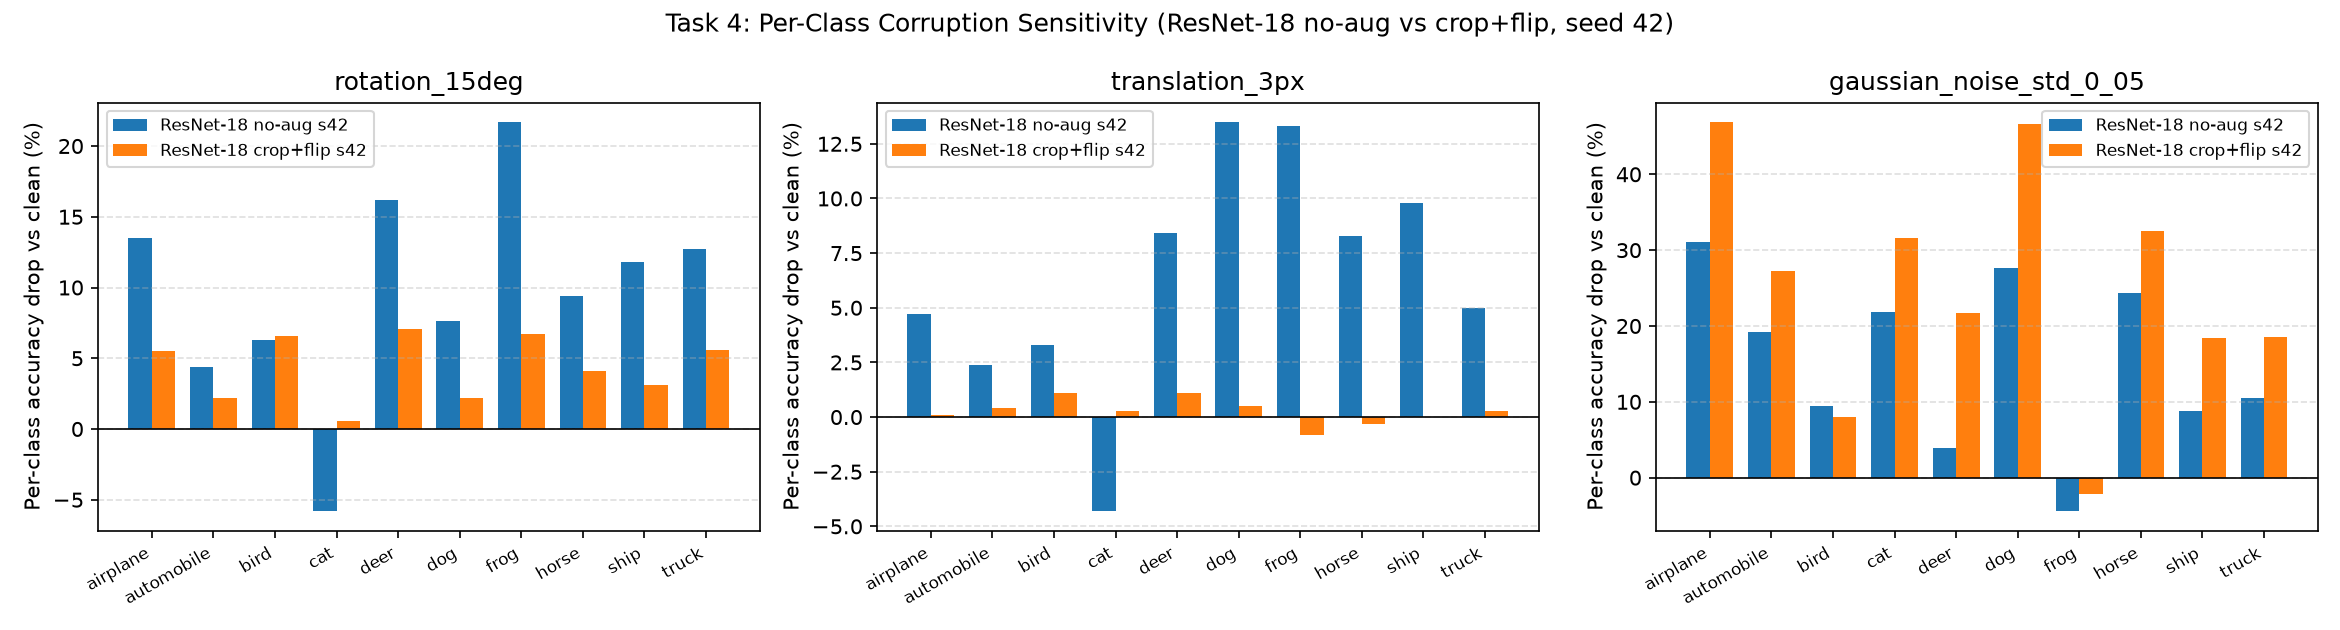

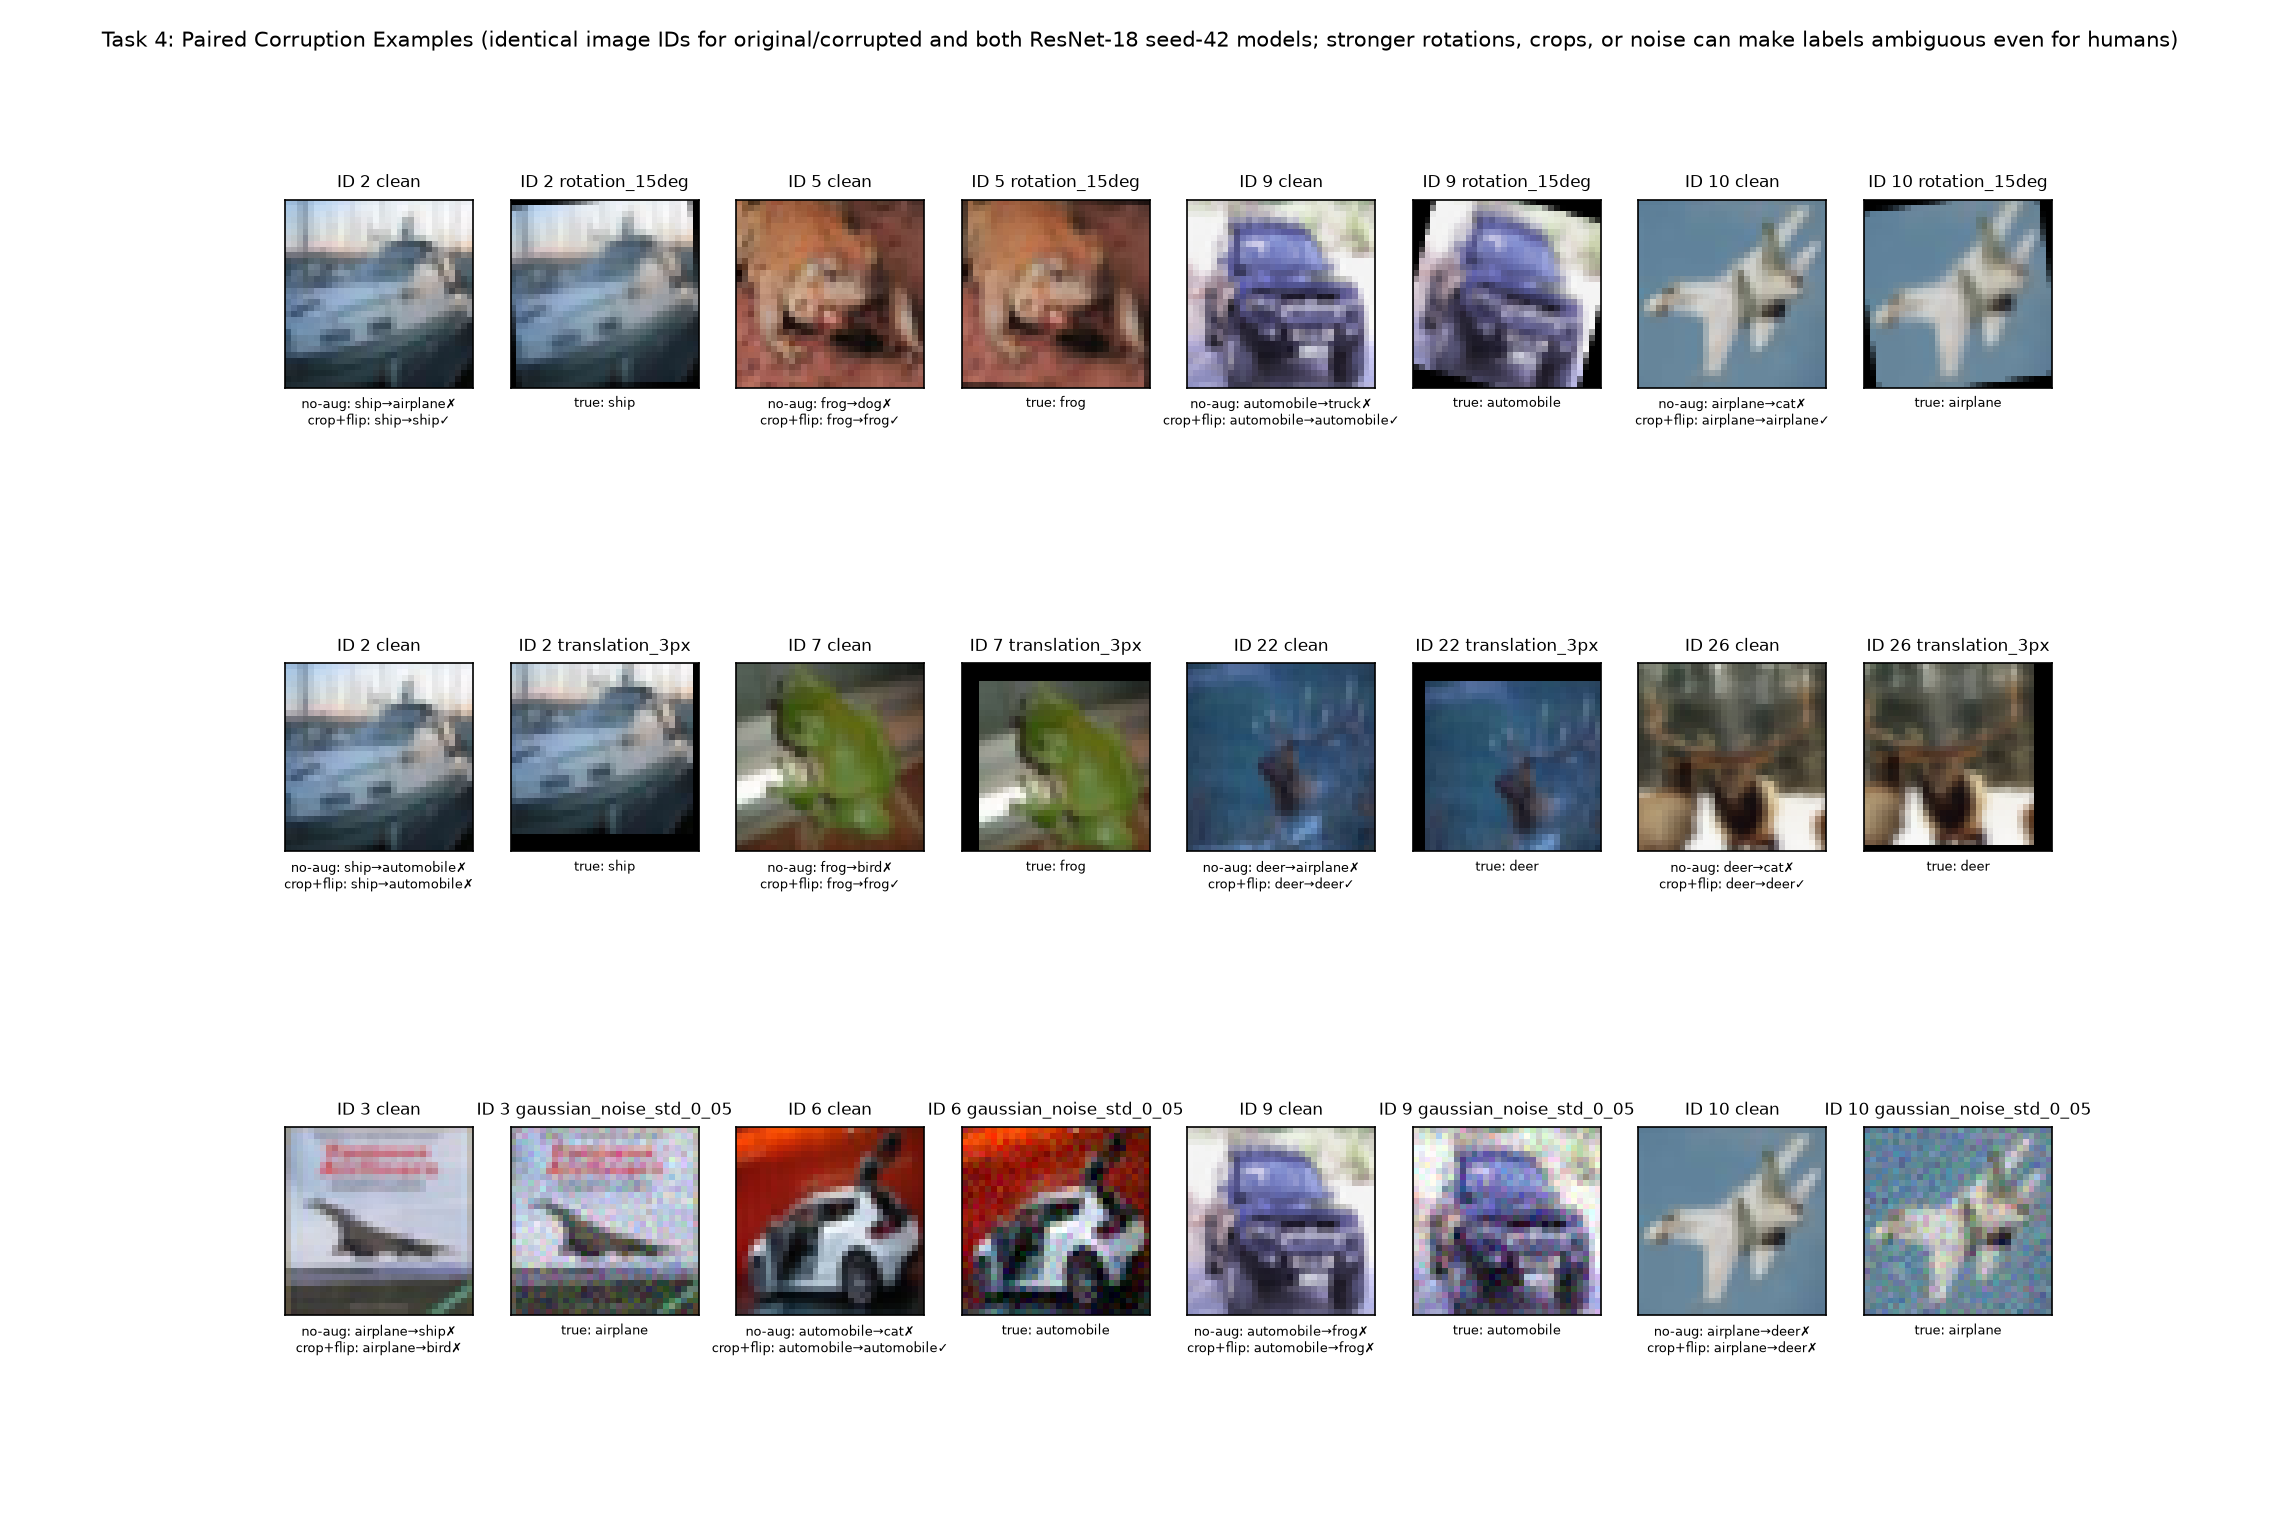

In [5]:
show_task(ROOT, '4')


## Task 5: predictions and adversarial examples

### Evaluation protocol

For prediction analysis, we used the team's frozen `t2_alexnet_cifar_baseline_s42` and
`t2_resnet18_cifar_baseline_s42` weights, trained by Role A at source revision `b1f9a7e`.
We checked each checkpoint's identity, model options and normalization statistics
before loading and recorded its SHA256. We measured accuracy, cross-entropy and
macro F1, with per-class precision/recall/F1 and row-normalized confusion matrices.
Correct and incorrect examples follow ascending image-ID order.

Untargeted FGSM takes a gradient-sign step to increase true-label cross-entropy
through the differentiable normalization step. We defined epsilon in raw [0,1]
pixel coordinates:

\[
x_{adv}=\mathrm{clip}_{[0,1]}(x+\epsilon\,\mathrm{sign}(\nabla_x L)).
\]

We tested budgets of 0, 2/255, 4/255 and 8/255. Every perturbation had to stay within
the valid pixel range and change each pixel channel by at most epsilon, with a
numerical tolerance of 1e-6. The network stayed in evaluation mode with fixed
parameters while input gradients remained enabled. Adversarial accuracy covers all
evaluation images. Attack success rate (ASR) counts the fraction of originally
correct predictions that become incorrect after perturbation. The zero-budget
condition checks that predictions remain unchanged.

The random control adds uniform noise in [-epsilon, epsilon] under the same budget,
using a separate fixed generator for each image ID. We also evaluated the shared frozen
rotation, translation and Gaussian-noise conditions on the same images and
checkpoints. These conditions measure sensitivity to ordinary corruptions, while
FGSM follows a model-dependent direction that increases loss. Their severity
definitions differ from the L-infinity attack budget.

### Results and interpretation

| Frozen baseline | Clean accuracy % | Cross-entropy | Macro F1 | Cat recall % | Dog recall % |
|---|---:|---:|---:|---:|---:|
| AlexNetCIFAR | 82.14 | 0.931 | 0.8205 | 63.2 | 73.9 |
| ResNet18CIFAR | 87.02 | 0.436 | 0.8699 | 74.3 | 79.2 |

ResNet correctly classified 488 more test images than AlexNet and had higher recall
in all ten classes. Cats were the hardest class for both models, followed by several
other animal classes. Automobile recall was 91.5% for AlexNet and 94.0% for ResNet.
The confusion matrices show frequent cat/dog errors in both directions.
Each CIFAR-10 test class contains 1,000 images, so the row fractions are directly
comparable. Full precision/recall/F1 results are in `t5_*_classes.csv`.



The example grids include clear successes alongside confident mistakes. Both models
predicted deer for test image 24, a dog, with confidence 0.95 for AlexNet and 0.99
for ResNet. For image 35, a bird, AlexNet predicted truck and ResNet predicted ship.
Fine object detail is limited at 32×32 resolution. Clutter, viewpoint and similar
animal shapes are plausible contributors in these examples, although we did not
test those explanations with feature attribution. The grids use the first five
correct and incorrect predictions by ID to avoid manually choosing striking errors.



Role A's original training histories show near-perfect final training fit for both
evaluated checkpoints, with a persistent validation gap. AlexNet's validation
cross-entropy rises after its early minimum even as validation accuracy improves
slightly, indicating more confident errors. After fluctuations in the middle
epochs, ResNet reaches a higher validation plateau and lower validation
cross-entropy. Both curves show overfitting despite good final training fit. These
histories belong to the evaluated checkpoints; the new Task 3 reference is a separate
training run.


### Optimized perturbations and random controls

All conditions cover the 10,000 official test images. ASR uses the 8,214 originally
correct AlexNet predictions or the 8,702 originally correct ResNet predictions.

| Model | Epsilon | FGSM accuracy % | FGSM ASR % | Random accuracy % | Random ASR % |
|---|---:|---:|---:|---:|---:|
| AlexNet | 0 | 82.14 | 0.00 | 82.14 | 0.00 |
| AlexNet | 2/255 | 46.50 | 43.39 | 82.07 | 0.32 |
| AlexNet | 4/255 | 27.49 | 66.53 | 82.07 | 0.61 |
| AlexNet | 8/255 | 19.01 | 76.86 | 81.67 | 1.67 |
| ResNet | 0 | 87.02 | 0.00 | 87.02 | 0.00 |
| ResNet | 2/255 | 28.34 | 67.43 | 87.03 | 0.47 |
| ResNet | 4/255 | 11.64 | 86.62 | 87.02 | 1.06 |
| ResNet | 8/255 | 4.78 | 94.51 | 86.07 | 2.93 |


At 8/255, FGSM reduced AlexNet accuracy by 63.13 percentage points and ResNet accuracy
by 82.24 points. Random noise under the same budget caused drops of 0.47 and 0.95
points. Both checkpoints were therefore much more sensitive to the gradient-directed
perturbation. The budget matches the maximum permitted change in each condition.
The perturbation magnitudes still have different distributions: uniform noise
samples the interior of the permitted box, while FGSM usually moves pixels to its
boundary.

ResNet had higher clean accuracy but lower resistance to this untargeted white-box
FGSM attack. That result applies to the two frozen checkpoints and this attack; it
does not establish a general robustness ranking of the architectures. Random-noise
accuracy can stay unchanged while ASR is positive because some initially incorrect
predictions also become correct.

At epsilon 8/255, image 0 changes from cat to dog for AlexNet and from cat to frog
for ResNet. Image 1 changes from ship to automobile for both models. FGSM also fails
on some images: the first retained failures are image 11 for AlexNet and image 23
for ResNet, both of which remain truck. Each row shows the original image, an
amplified perturbation and the actual attacked image. The middle panel displays
`clip(0.5 + 8*delta, 0, 1)` to make the perturbation visible. The input fed to the
model still changes by at most 8/255 per channel.



FGSM uses a single gradient-sign step, following
[Goodfellow, Shlens and Szegedy](https://arxiv.org/abs/1412.6572). Remaining correct
after that step does not certify robustness throughout the permitted region.
Iterative attacks with restarts would give a stronger follow-up evaluation. Each
Task 5 JSON also stores the separate rotation, translation and Gaussian-noise
results for the shared frozen settings and the same Role A checkpoints. Those severity
parameters are not equivalent to the L-infinity budget.

### Paired comparison with the frozen corruption suite

We applied the shared exact per-image corruption recipe to the same 10,000 images and Role
A weights used for FGSM. We measured these results directly on those weights;
the shared independently trained checkpoints have separate metrics.

| Evaluation condition | AlexNet accuracy % | ResNet accuracy % |
|---|---:|---:|
| Clean | 82.14 | 87.02 |
| Rotation, maximum 15 degrees | 70.17 | 78.70 |
| Translation, maximum 3 pixels | 70.56 | 81.00 |
| Gaussian noise, standard deviation 0.05 | 77.20 | 73.86 |
| Uniform random L-infinity noise, epsilon 8/255 | 81.67 | 86.07 |
| FGSM, epsilon 8/255 | 19.01 | 4.78 |

ResNet retained higher accuracy under the geometric transformations, whereas AlexNet
retained higher accuracy under Gaussian noise. Their ranking therefore depends on
the corruption family. Gaussian noise has a different magnitude distribution and a
larger standard deviation than the uniform control, so their numerical differences
reflect direction, distribution and severity together. The uniform control
under the same budget is the closer comparison for assessing FGSM's model-dependent
direction.



role_b_task5_clean.csv


,exp_id,source_exp_id,accuracy,ce,macro_f1
0,t5_t2_alexnet_cifar_baseline_s42,t2_alexnet_cifar_baseline_s42,0.8214,0.931000,0.820482
1,t5_t2_resnet18_cifar_baseline_s42,t2_resnet18_cifar_baseline_s42,0.8702,0.435732,0.869897


role_b_task5_attacks.csv


,source_exp_id,num_samples,clean_accuracy,accuracy,clean_correct_count,successful_count,asr,method,targeted,norm,epsilon,max_observed_linf,ce,evaluation_time_sec,random_seed
0,t2_alexnet_cifar_baseline_s42,10000,0.8214,0.8214,8214,0,0.000000,fgsm,False,linf,0.000000,0.000000,0.931000,1.440110,NaN
1,t2_alexnet_cifar_baseline_s42,10000,0.8214,0.4650,8214,3564,0.433893,fgsm,False,linf,0.007843,0.007843,4.415311,2.652829,NaN
2,t2_alexnet_cifar_baseline_s42,10000,0.8214,0.2749,8214,5465,0.665327,fgsm,False,linf,0.015686,0.015686,8.474964,2.670277,NaN
3,t2_alexnet_cifar_baseline_s42,10000,0.8214,0.1901,8214,6313,0.768566,fgsm,False,linf,0.031373,0.031373,13.324855,2.680068,NaN
4,t2_alexnet_cifar_baseline_s42,10000,0.8214,0.8214,8214,0,0.000000,random_linf,False,linf,0.000000,0.000000,0.931000,1.467030,2223.0
5,t2_alexnet_cifar_baseline_s42,10000,0.8214,0.8207,8214,26,0.003165,random_linf,False,linf,0.007843,0.007843,0.930377,1.527496,2223.0
6,t2_alexnet_cifar_baseline_s42,10000,0.8214,0.8207,8214,50,0.006087,random_linf,False,linf,0.015686,0.015686,0.931065,1.458540,2223.0
7,t2_alexnet_cifar_baseline_s42,10000,0.8214,0.8167,8214,137,0.016679,random_linf,False,linf,0.031373,0.031373,0.939469,1.447628,2223.0
8,t2_resnet18_cifar_baseline_s42,10000,0.8702,0.8702,8702,0,0.000000,fgsm,False,linf,0.000000,0.000000,0.435732,6.197688,NaN
9,t2_resnet18_cifar_baseline_s42,10000,0.8702,0.2834,8702,5868,0.674328,fgsm,False,linf,0.007843,0.007843,4.406083,13.360838,NaN


t5_t2_alexnet_cifar_baseline_s42_classes.csv


,class,precision,recall,f1-score,support
0,airplane,0.822243,0.865,0.843080,1000.0
1,automobile,0.906838,0.915,0.910901,1000.0
2,bird,0.749495,0.742,0.745729,1000.0
3,cat,0.682505,0.632,0.656282,1000.0
4,deer,0.803410,0.801,0.802203,1000.0
5,dog,0.751016,0.739,0.744960,1000.0
6,frog,0.855199,0.880,0.867422,1000.0
7,horse,0.856299,0.870,0.863095,1000.0
8,ship,0.887033,0.903,0.894945,1000.0
9,truck,0.885598,0.867,0.876200,1000.0


t5_t2_resnet18_cifar_baseline_s42_classes.csv


,class,precision,recall,f1-score,support
0,airplane,0.879293,0.896,0.887568,1000.0
1,automobile,0.938124,0.940,0.939061,1000.0
2,bird,0.834034,0.794,0.813525,1000.0
3,cat,0.737103,0.743,0.740040,1000.0
4,deer,0.861476,0.852,0.856712,1000.0
5,dog,0.816495,0.792,0.804061,1000.0
6,frog,0.872849,0.913,0.892473,1000.0
7,horse,0.904478,0.909,0.906733,1000.0
8,ship,0.923304,0.939,0.931086,1000.0
9,truck,0.931452,0.924,0.927711,1000.0


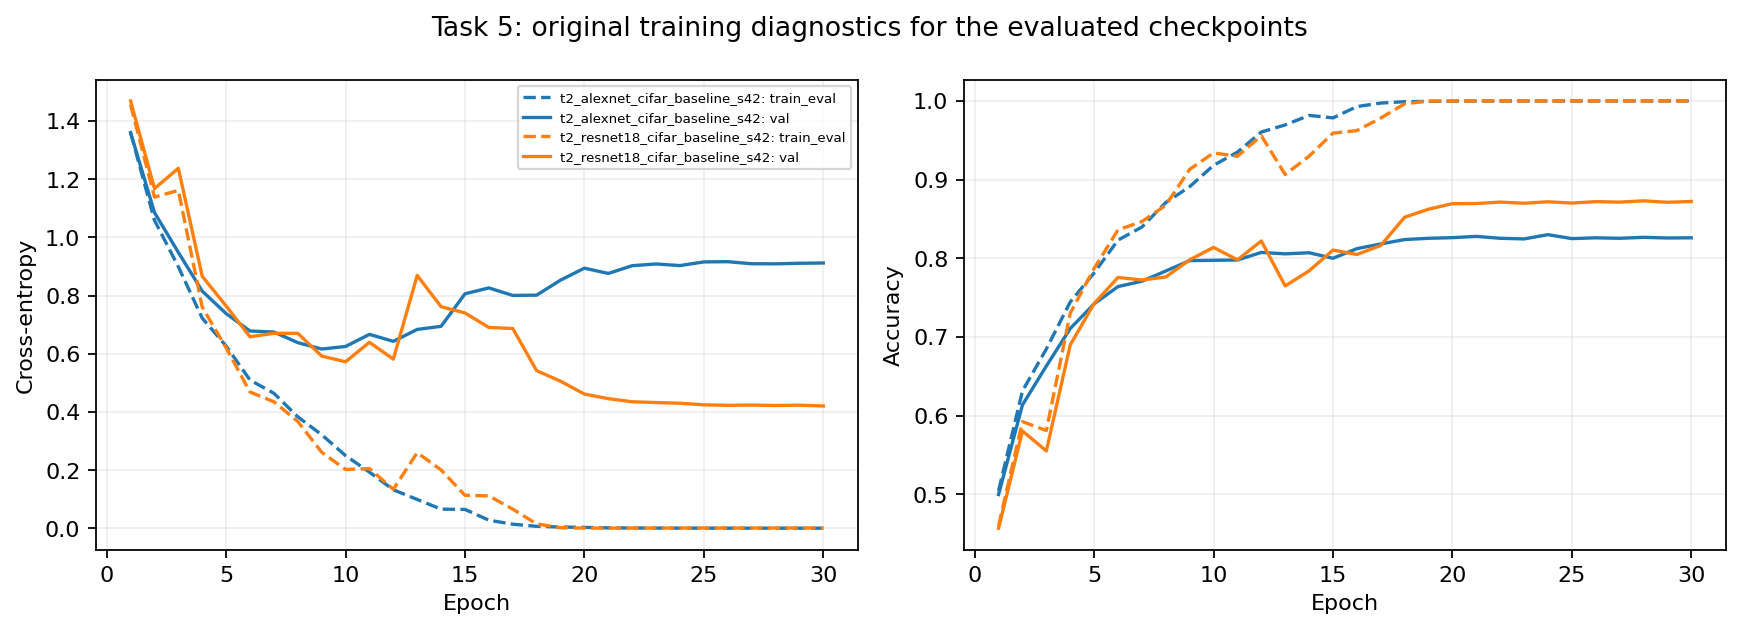

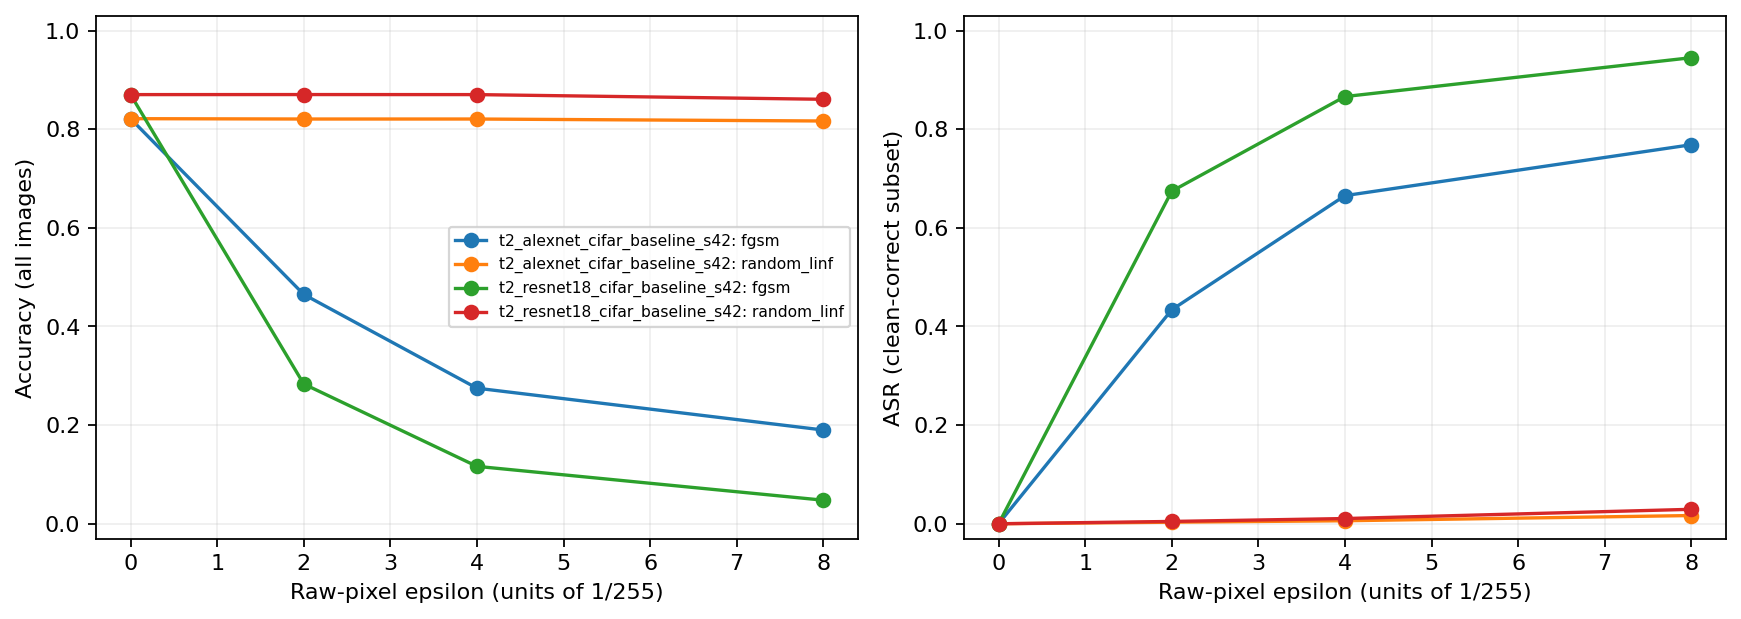

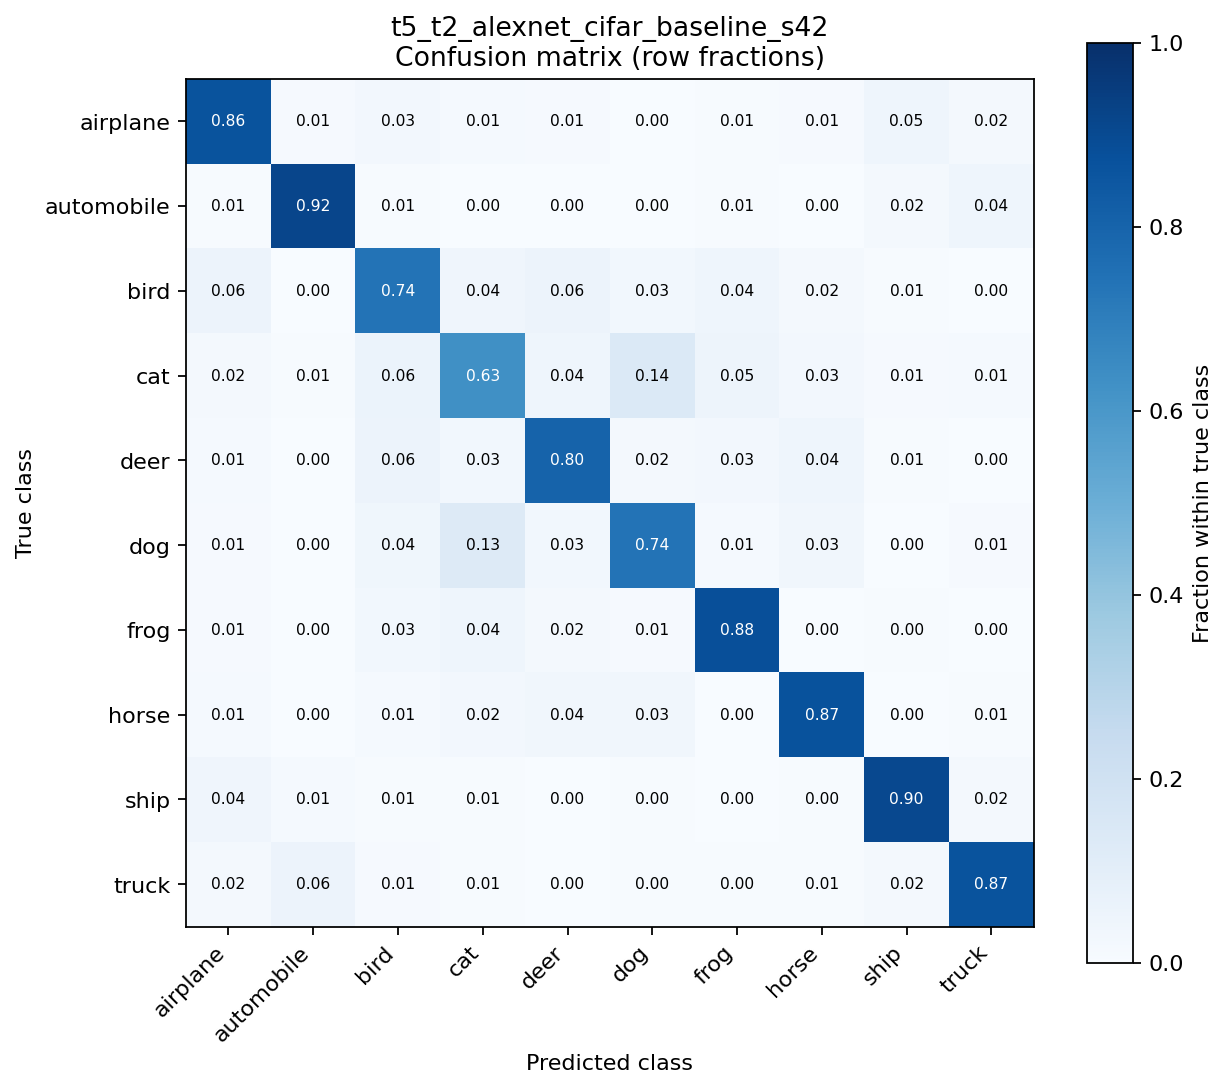

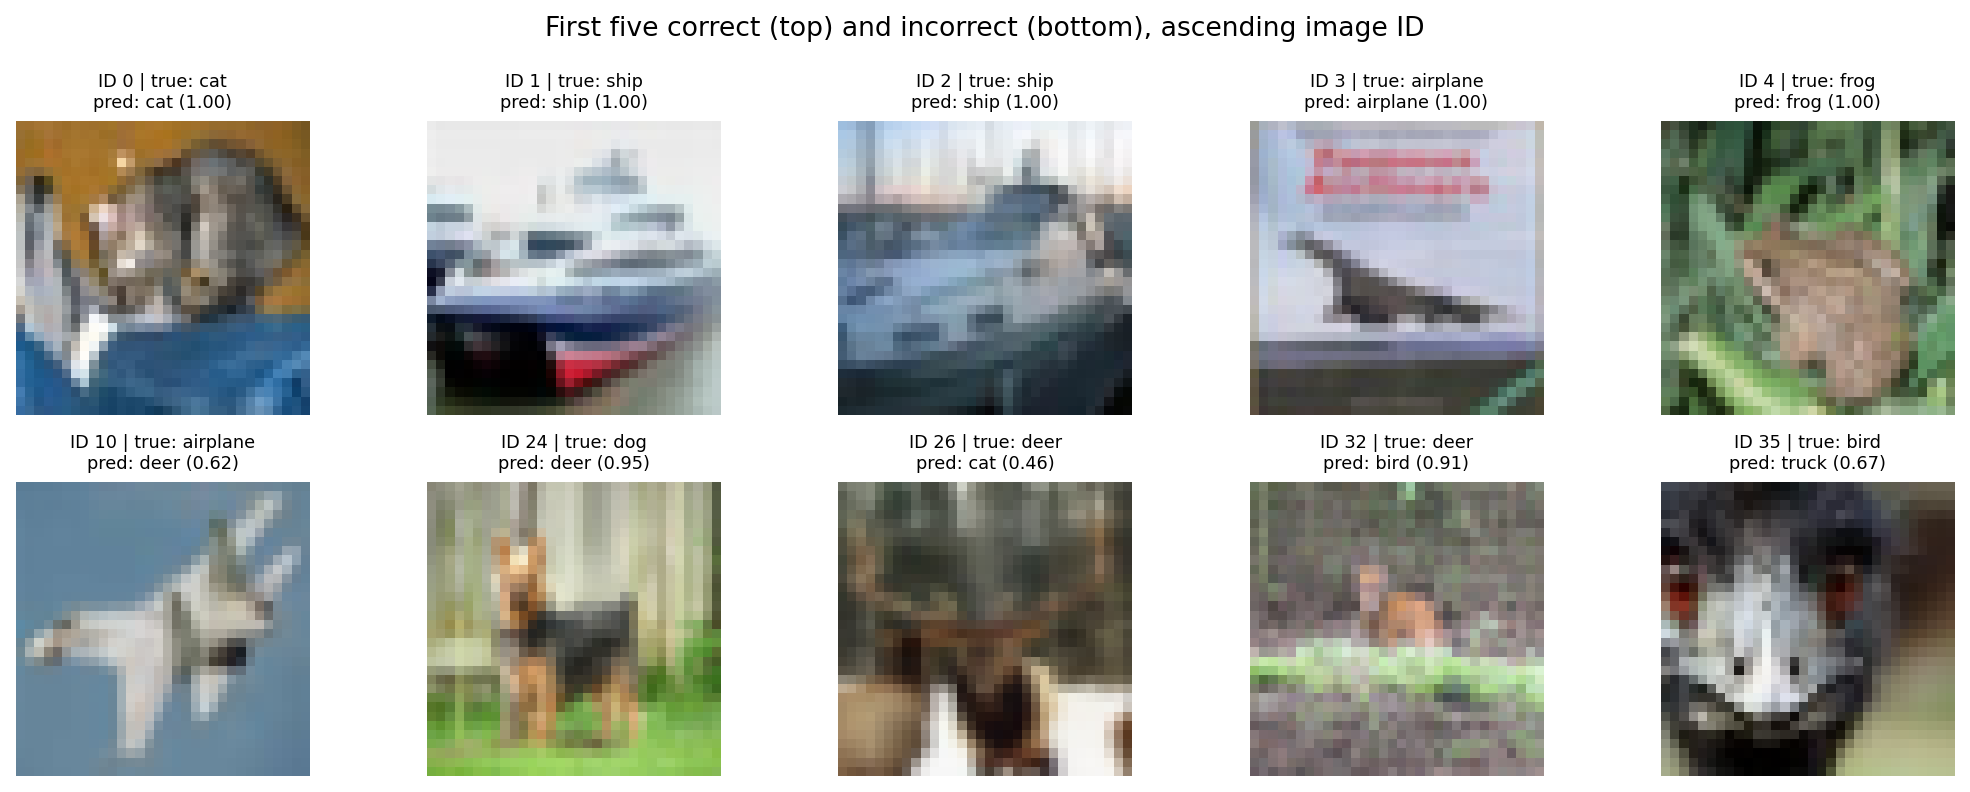

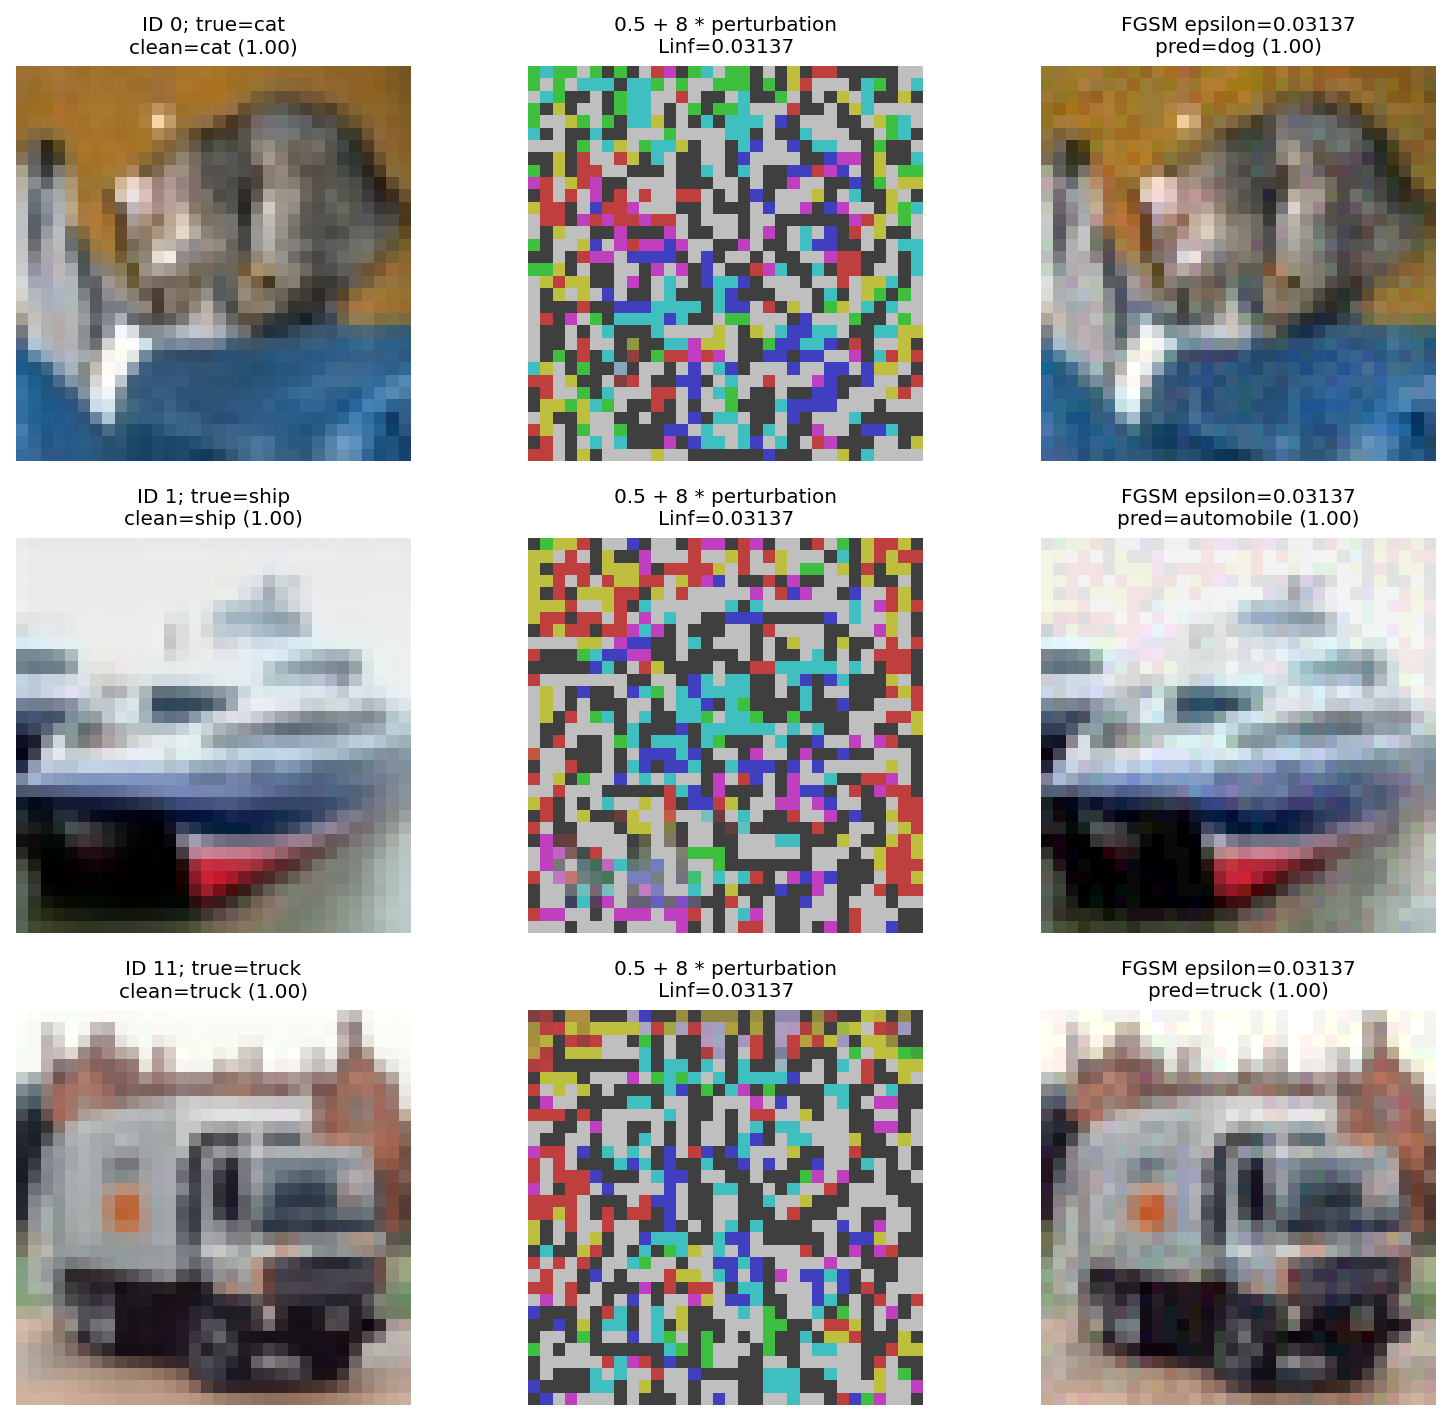

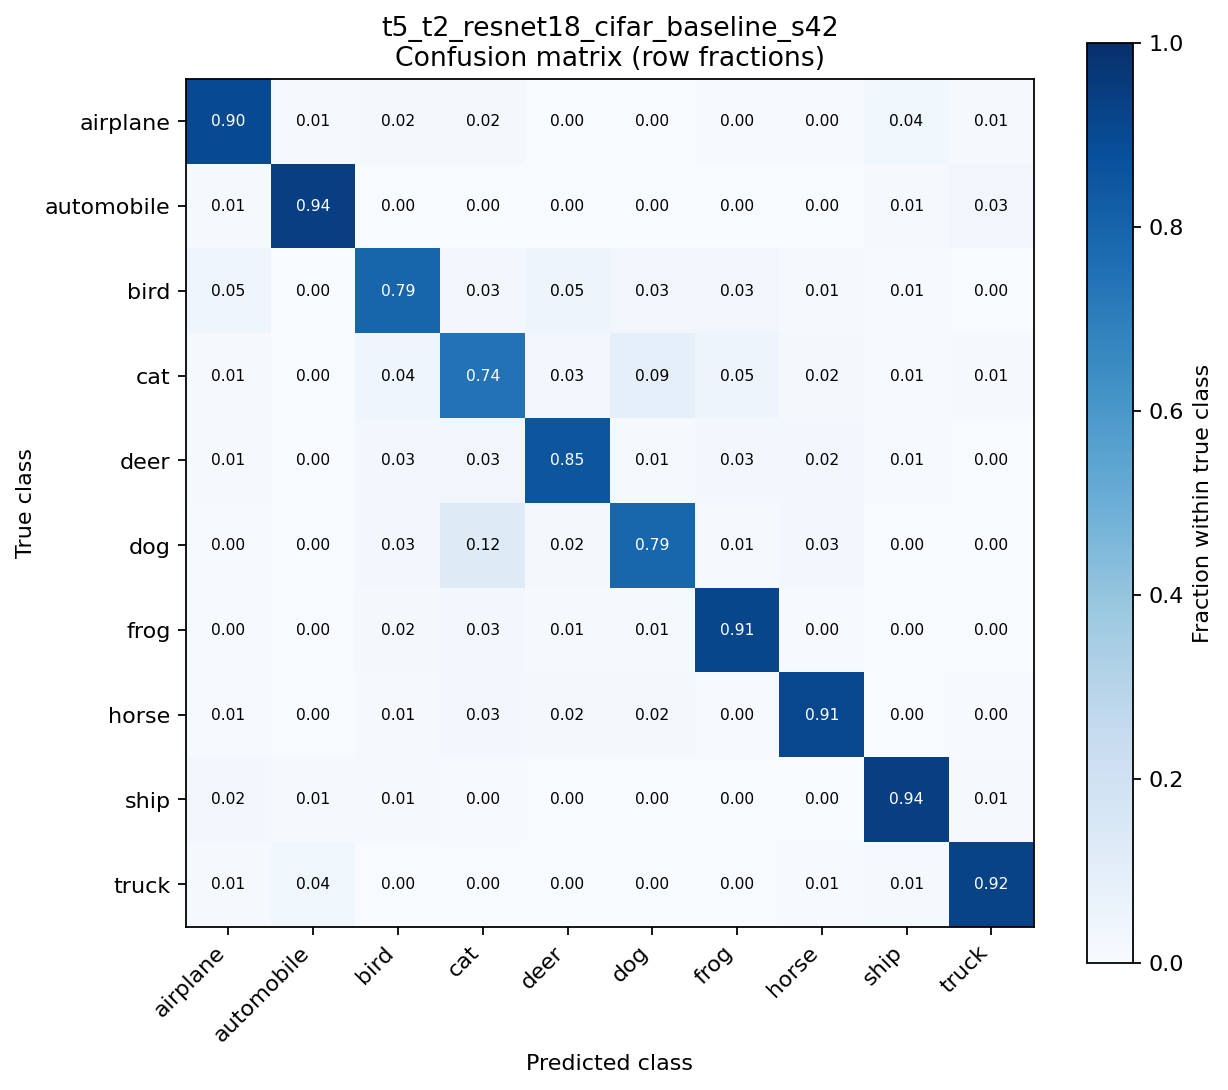

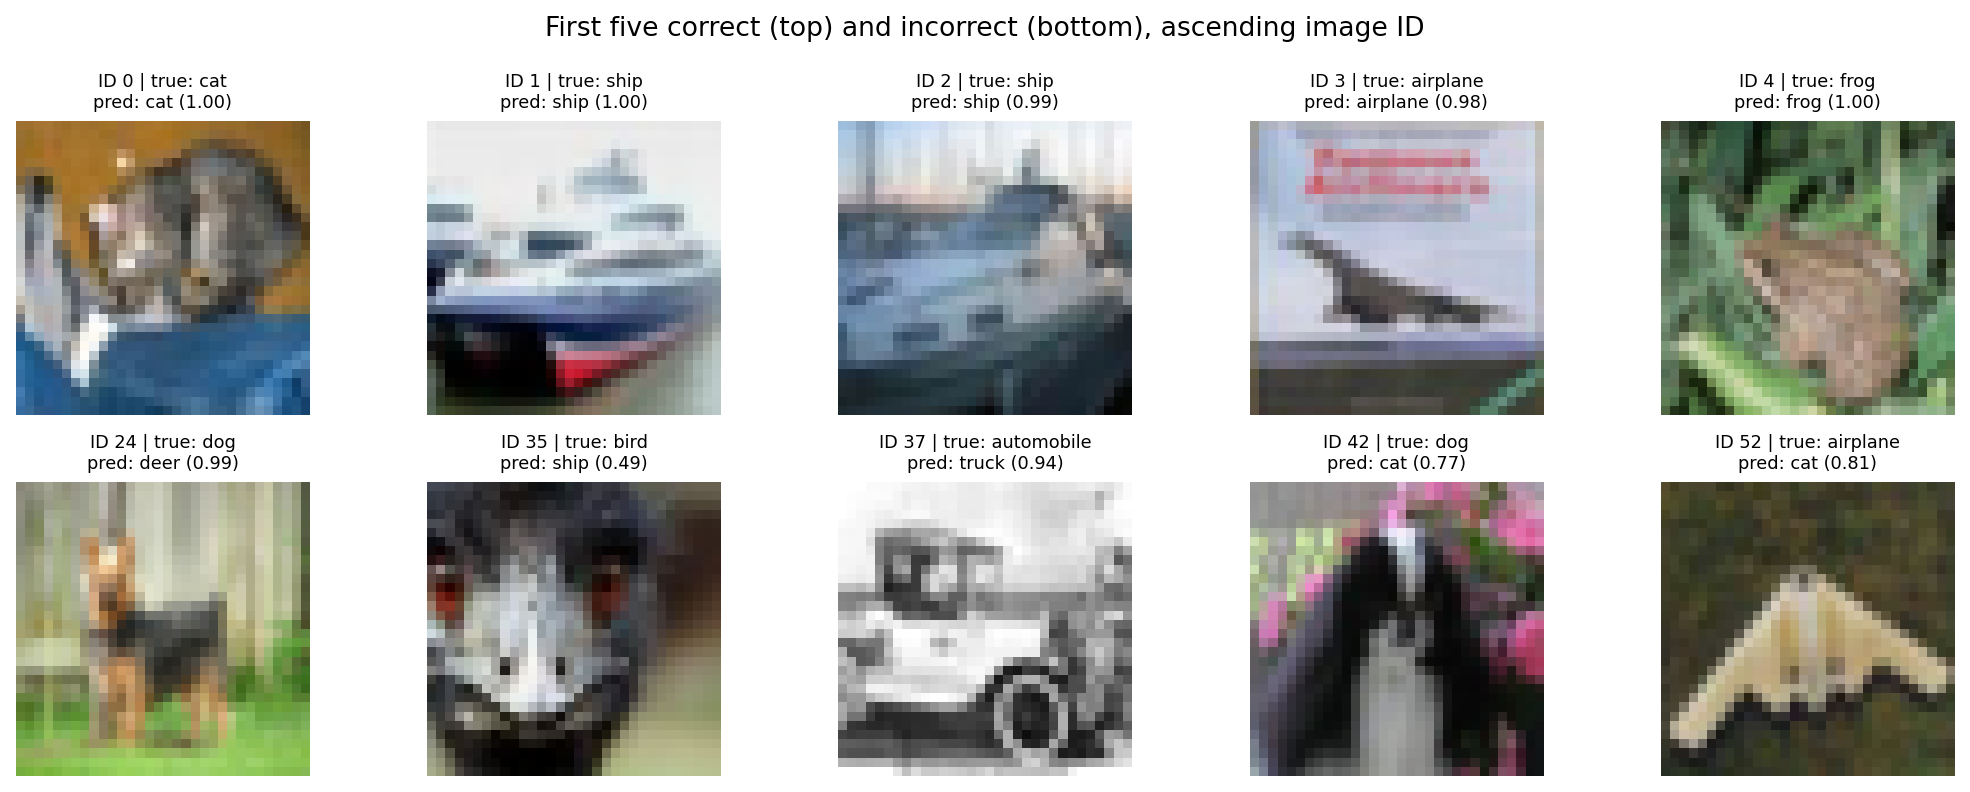

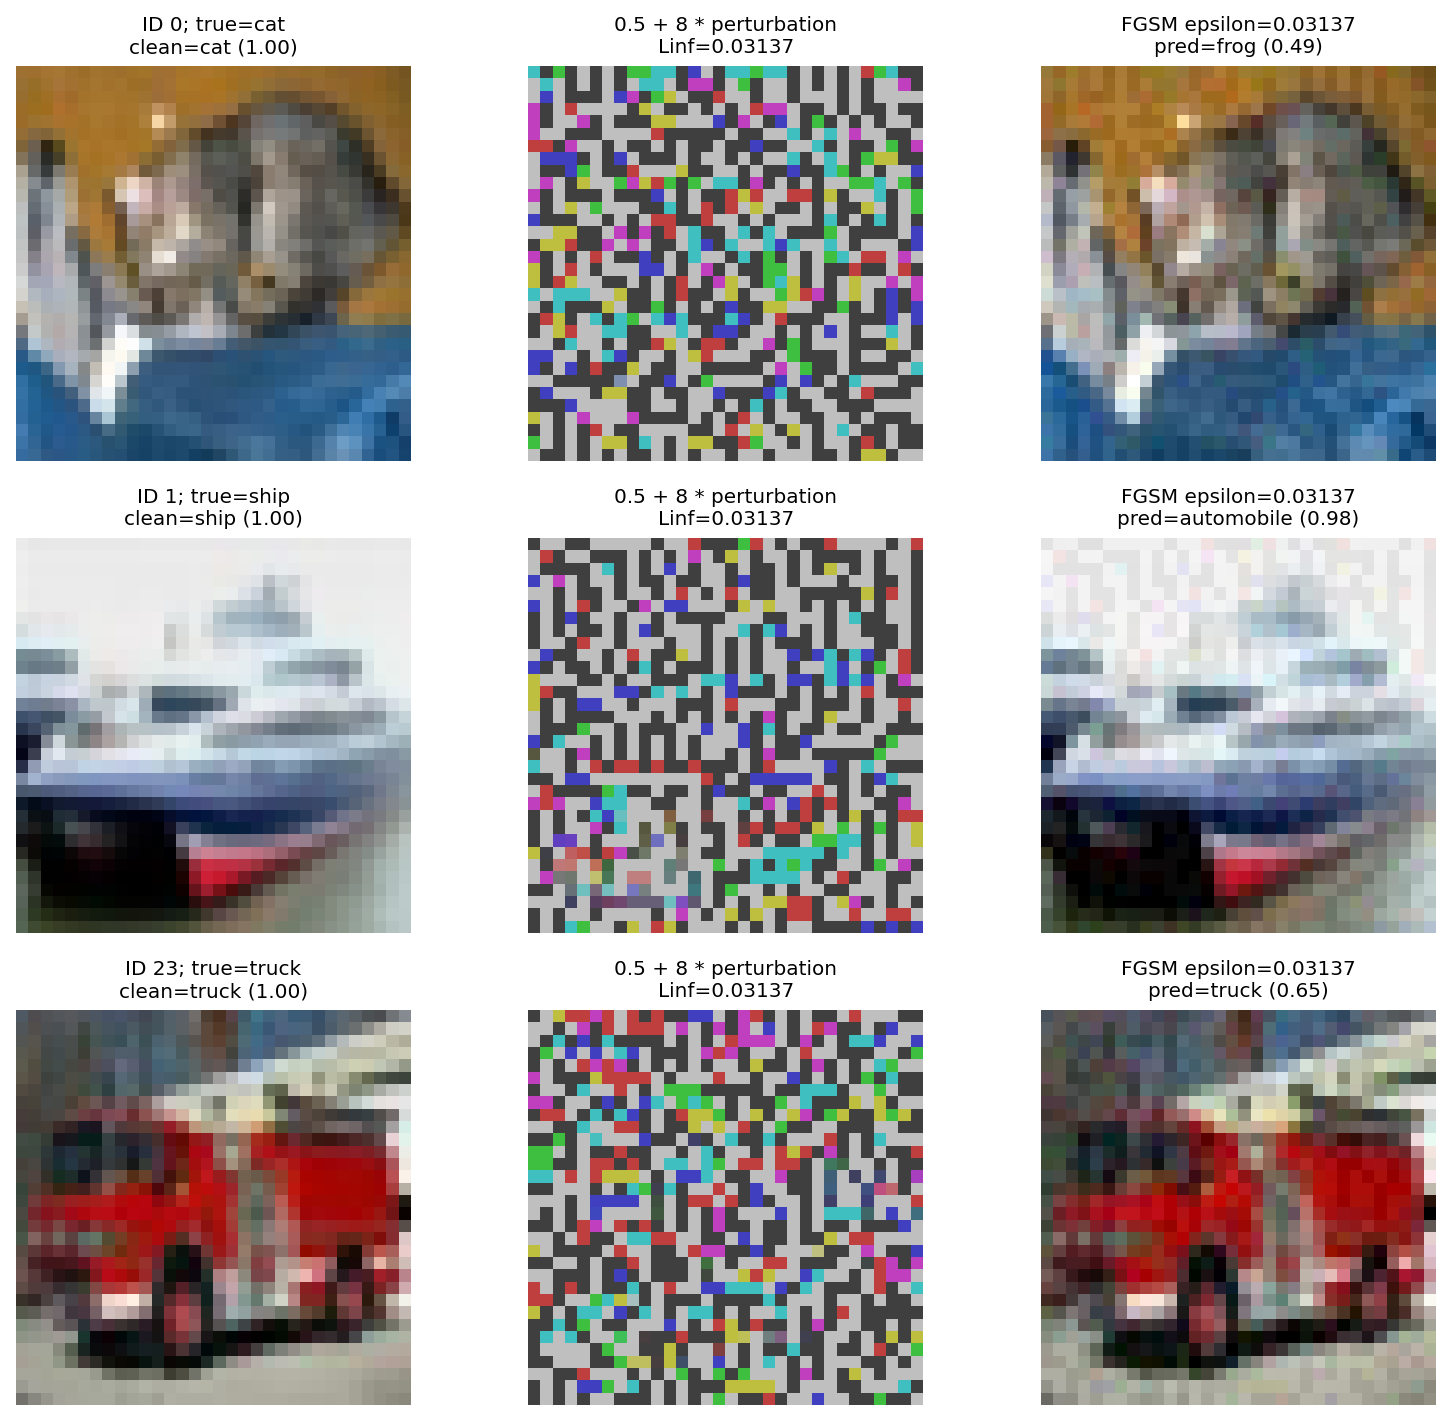

In [6]:
show_task(ROOT, '5')


## Challenge 2: held-out domain generalization

We evaluated the three seed-42 C models on STL-10 after freezing model and
augmentation choices. No STL labels were used for fitting or selection. STL-10's
8,000 test images are 96 x 96 pixels. Removing monkey, which has no CIFAR class,
leaves 7,200 images in nine shared classes. STL's car label maps to CIFAR's
automobile; CIFAR's frog class has no STL counterpart. Bilinear resizing with
antialiasing produces 32 x 32 inputs, followed by CIFAR training normalization.

We report ten-logit accuracy and the fraction predicted as frog, then restrict
argmax to the nine shared logits. The matching CIFAR reference uses its 9,000
shared-class test images. Domain drop equals CIFAR shared-nine accuracy minus
STL masked-nine accuracy; paired IDs are shared across the evaluated models.

| Model (seed 42) | CIFAR 9-way | STL 10-way | Frog leakage | STL 9-way | Domain drop |
|---|---:|---:|---:|---:|---:|
| AlexNet, no augmentation | 0.8310 | 0.6675 | 0.0314 | 0.6825 | 0.1485 |
| ResNet, no augmentation | 0.8683 | 0.7107 | 0.0351 | 0.7267 | 0.1417 |
| ResNet, crop + flip | 0.9339 | 0.8014 | 0.0185 | 0.8108 | 0.1231 |


The augmented ResNet transferred best among these three frozen models and had
the smallest domain drop. Its largest per-class drops were dog (0.3013), cat
(0.2118) and horse (0.1507); ship and deer dropped least (0.0395 and 0.0420).
All three models struggled with dog. Reduced texture after resizing and domain
differences are plausible contributors, but the evaluation does not isolate them.
The notebook includes nine-class confusion matrices and deterministic paired
failure examples from the union of the models' error sets. A selected example
can be correct for one model and wrong for another.



role_c_summary.csv


,exp_id,task,model,seed,augmentation,device_name,training_device_name,inference_device_name,total_params,best_epoch,...,mean_corrupted_acc,stl10_10way_acc,stl10_9way_masked_acc,stl10_frog_leakage_rate,domain_drop_9way,total_train_time_sec,peak_gpu_mem_mb,bs1_latency_ms,bs128_latency_ms_per_batch,bs128_throughput_imgs_per_sec
0,t6_alexnet_cifar_no_aug_s42,task6,alexnet_cifar,42,none,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,6976842,28,...,0.720667,0.667500,0.682500,0.031389,0.148500,353.666,316.91,0.308709,4.496393,28467.264682
1,t4_resnet18_cifar_no_aug_s42,task4,resnet18_cifar,42,none,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,11173962,28,...,0.760900,0.710694,0.726667,0.035139,0.141667,1855.352,802.99,0.905939,16.795464,7621.105181
2,t4_resnet18_cifar_crop_flip_s42,task4,resnet18_cifar,42,crop32_pad4_hflip05,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,11173962,30,...,0.832200,0.801389,0.810833,0.018472,0.123056,1859.826,802.99,0.914313,16.856545,7593.489759
3,t6_resnet18_cifar_crop_flip_s0,task6,resnet18_cifar,0,crop32_pad4_hflip05,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,11173962,30,...,0.825300,0.800972,0.812778,0.023889,0.115556,1858.514,802.99,0.852418,16.898406,7574.679098
4,t6_resnet18_cifar_crop_flip_s123,task6,resnet18_cifar,123,crop32_pad4_hflip05,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,11173962,29,...,0.822100,0.799306,0.809306,0.018889,0.121917,1856.025,802.99,0.849120,16.892198,7577.462514


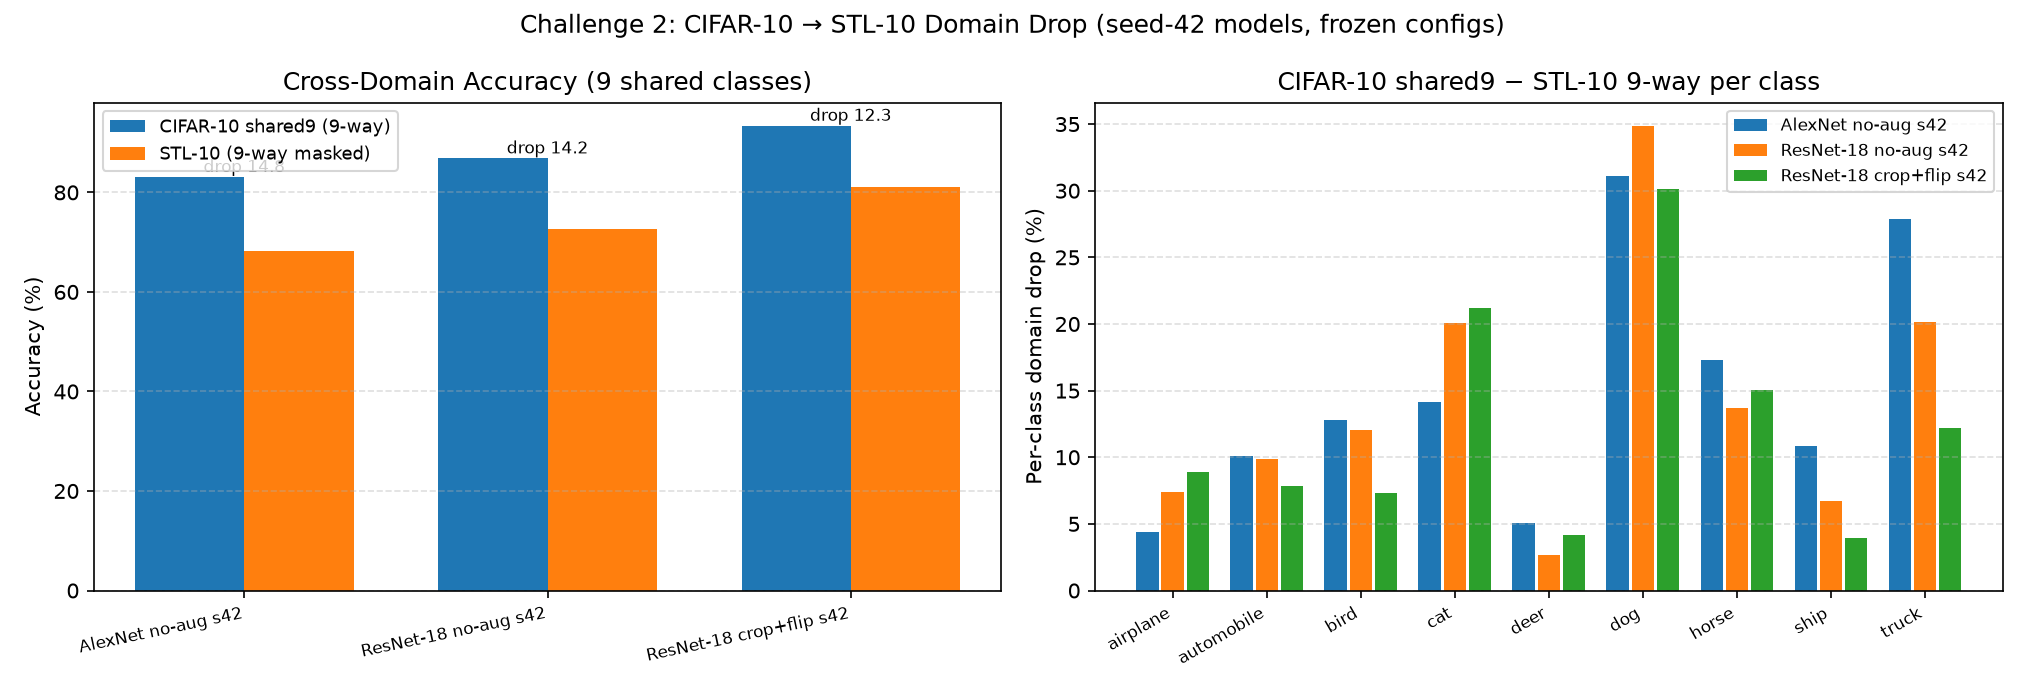

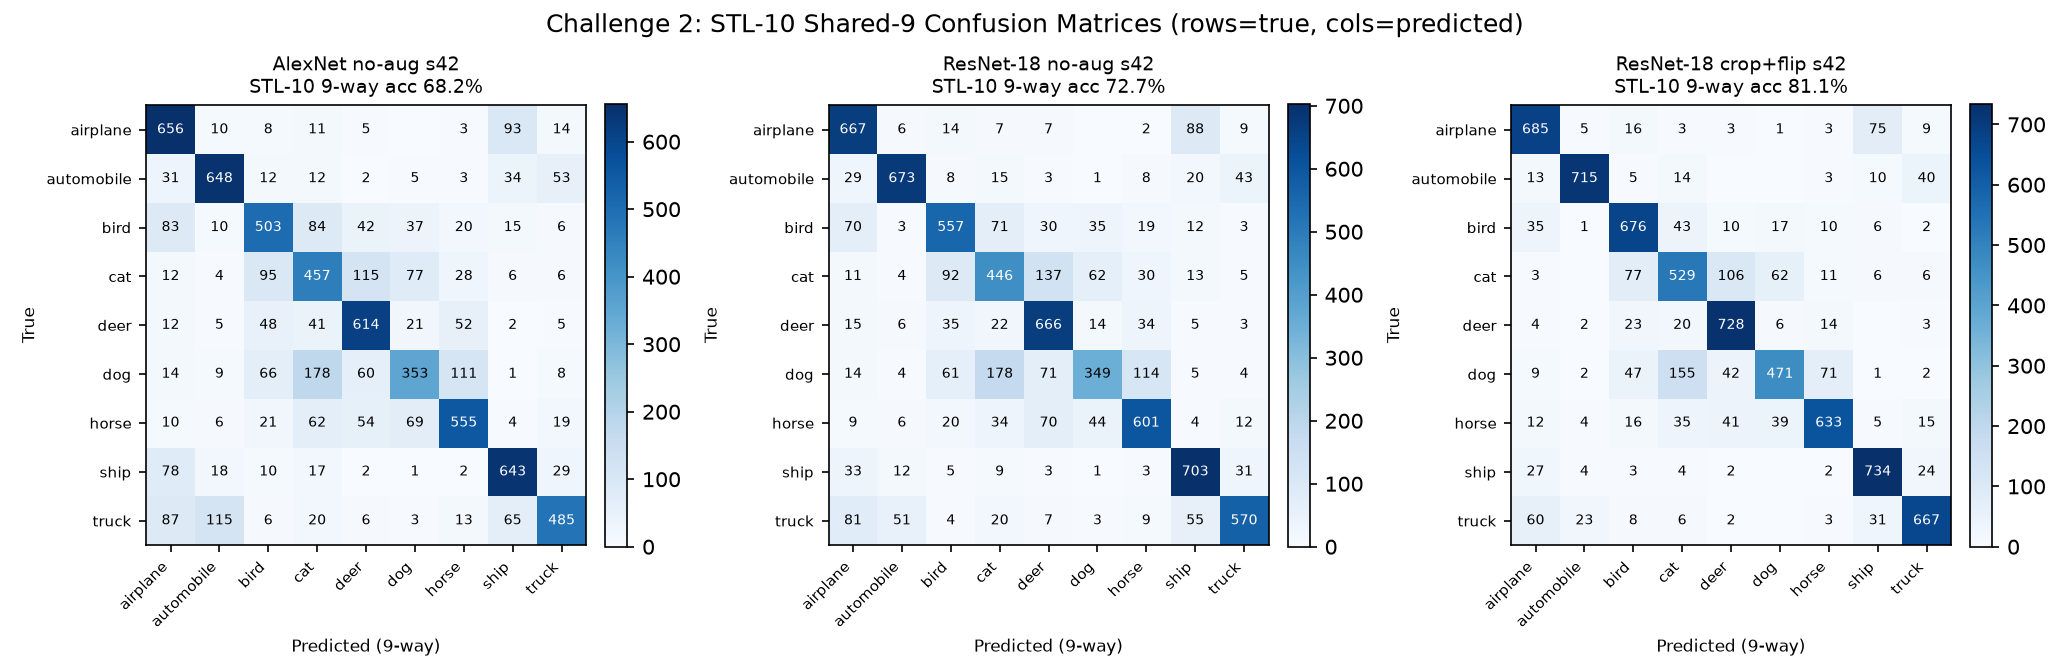

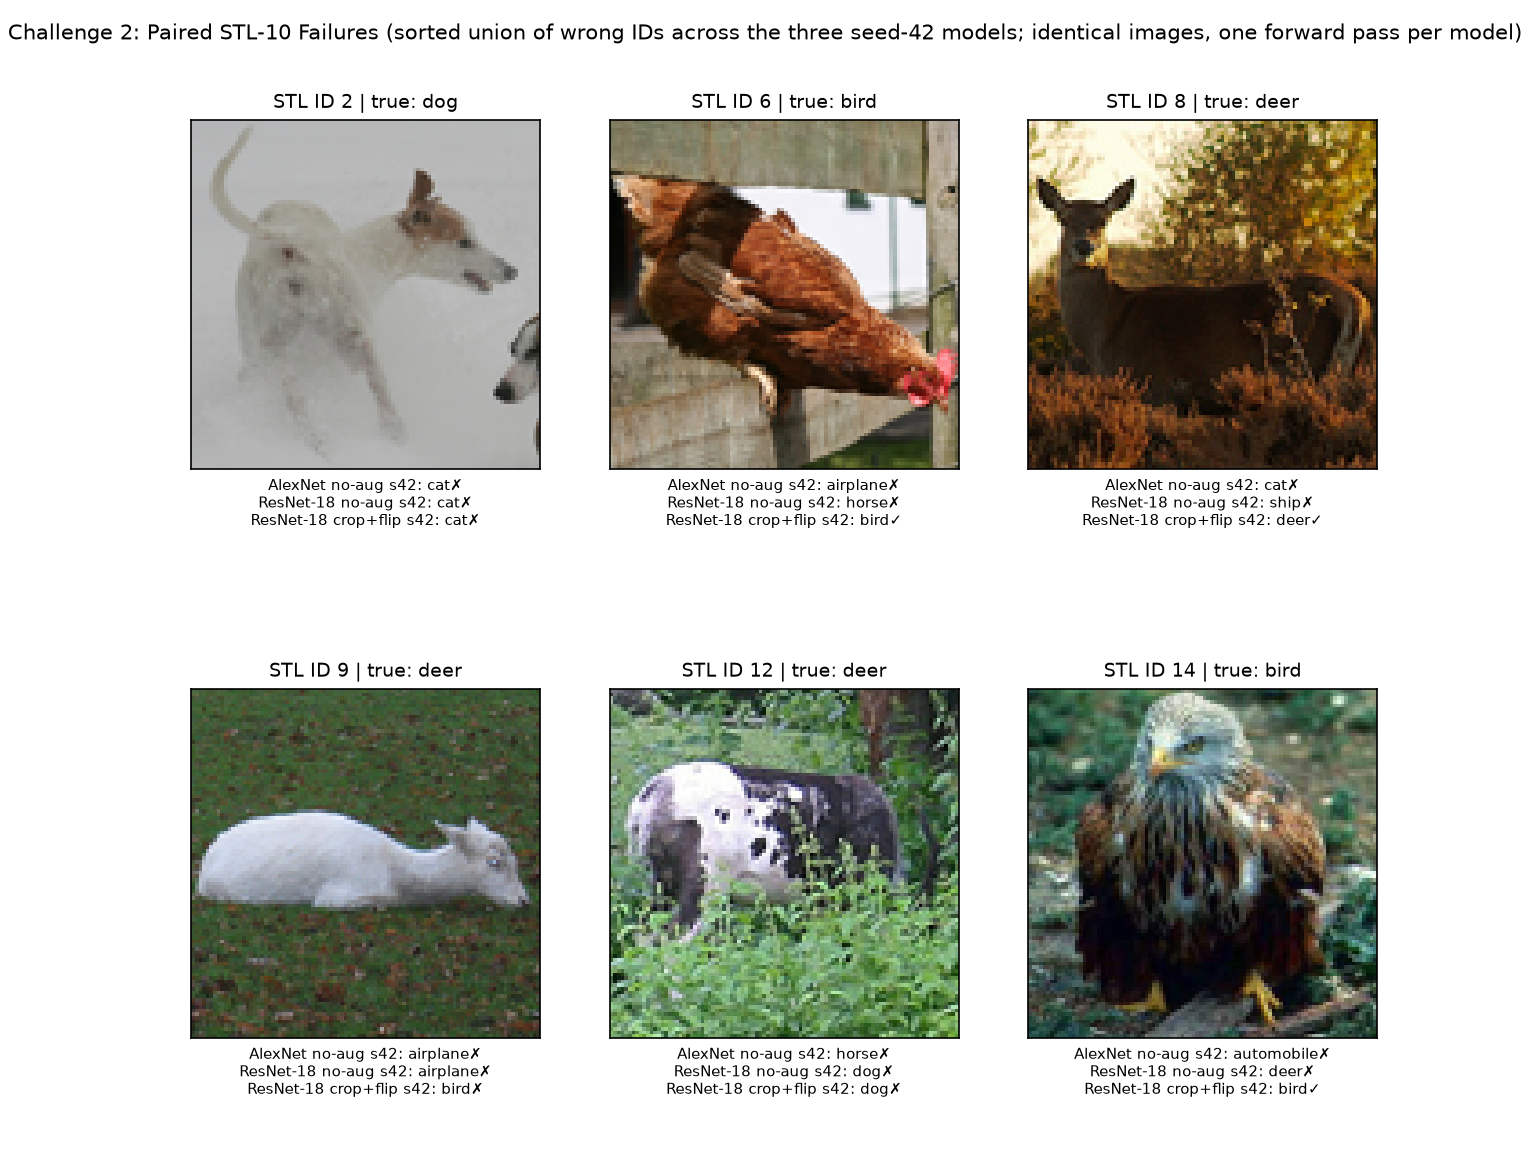

In [7]:
show_task(ROOT, 'challenge2')


## Task 6: cost, sensitivity and recommendation

The final architecture comparison uses the shared five-run matrix. Training was measured
on Tesla T4; all inference measurements below were collected on the Jade RTX 2000
Ada Generation GPU in FP32. Forward benchmarks use resident tensors, 10 warmups,
50 measured forwards, synchronization around timed regions, and batch sizes 1 and
128. They exclude data loading, preprocessing and transfers. Training time includes
validation and deterministic training-set evaluation after each epoch. Peak memory
is allocated CUDA memory in MiB (2^20 bytes), rather than total device reservation.

| Configuration | Parameters | T4 training s | T4 peak MiB | Clean accuracy | Mean corrupt accuracy |
|---|---:|---:|---:|---:|---:|
| AlexNet, no aug, seed 42 | 6.98M | 353.7 | 316.9 | 0.8266 | 0.7207 |
| ResNet, no aug, seed 42 | 11.17M | 1855.4 | 803.0 | 0.8658 | 0.7609 |
| ResNet, crop + flip, seed 42 | 11.17M | 1859.8 | 803.0 | 0.9308 | 0.8322 |
| ResNet, crop + flip, seed 0 | 11.17M | 1858.5 | 803.0 | 0.9279 | 0.8253 |
| ResNet, crop + flip, seed 123 | 11.17M | 1856.0 | 803.0 | 0.9292 | 0.8221 |

| Configuration | Jade batch-1 ms | Jade batch-128 ms/batch | Jade images/s |
|---|---:|---:|---:|
| AlexNet, no aug, seed 42 | 0.309 | 4.50 | 28467 |
| ResNet, no aug, seed 42 | 0.906 | 16.80 | 7621 |
| ResNet, crop + flip, seed 42 | 0.914 | 16.86 | 7593 |
| ResNet, crop + flip, seed 0 | 0.852 | 16.90 | 7575 |
| ResNet, crop + flip, seed 123 | 0.849 | 16.89 | 7577 |


For a roughly 31-minute T4 training budget, we choose the crop-plus-flip ResNet
family on clean accuracy, the fixed CIFAR corruption suite and measured cost.
Relative to the no-augmentation ResNet, it adds 0.24% training time with the same
peak memory, while improving clean and geometric accuracy. STL-10 was held out
from this choice. Gaussian noise remains a weakness: the seed-42 augmented model
scored 0.6814 versus 0.7133 without augmentation.

When single-image latency or throughput dominates, the shared AlexNet offers 0.309 ms
latency, about one third of the augmented ResNet's, and approximately 3.7 times
the batch-128 throughput. Its 354 s training cost is substantially lower, with
10.42 points less clean accuracy and 11.15 points less mean-corruption accuracy.
Within B's separate T4 controlled matrix, halving AlexNet's convolution width
halved training cost and memory, but reduced test accuracy by 2.14 points and
gave no measured batch-one speedup. Smaller parameter count alone is insufficient
evidence of faster inference.

The Task 5 threat model adds a separate constraint to any recommendation. The
frozen A ResNet had strong clean accuracy and 4.78% FGSM accuracy at 8/255; the
frozen A AlexNet had 19.01%. The augmented C ResNet was not attacked here. Its
geometric robustness cannot be used as evidence of adversarial robustness, and
the Task 5 ranking applies only to the attacked checkpoints and single-step FGSM.

### Training duration, random seed and hardware

Validation accuracy at epochs 10, 20 and 30 was 0.8046/0.8236/0.8294 for the shared
AlexNet, 0.8048/0.8712/0.8734 for its no-augmentation ResNet and
0.7854/0.8832/0.9304 for its augmented seed-42 ResNet. Their cumulative T4 times
were about 112/233/354 s, 620/1238/1855 s and 622/1241/1860 s. The augmented
model trailed at epoch 10 and improved substantially later; an early cutoff
would change the conclusion. These are checkpoints along one 30-epoch cosine
schedule, not separately optimized 10- or 20-epoch schedules.


Across augmented ResNet seeds 0, 42 and 123, clean accuracy was 0.9293 +/- 0.0015
(sample standard deviation), mean-corruption accuracy 0.8265 +/- 0.0052 and noise
accuracy 0.6712 +/- 0.0100. Noise varied most, ranging from 0.6615 to 0.6814;
seed 42 had the highest noise accuracy as well as the highest clean and mean
corruption accuracy in these three runs. This supports the family-level result
without establishing an optimal seed. The no-augmentation comparison and all
Task 3 ablations have one seed, so their small differences need replication.

A's RTX and the shared T4 runs have different machines, software and sessions. Their
training-time ratios (about 1.42 for AlexNet and 2.71 for ResNet) describe those
observed environments and do not isolate a GPU effect. T4, Jade and RTX latency
values are not combined into a single speed ranking. In particular, B's T4
forward latency is compared only within its own six-run matrix.

### Most useful next experiments

We would first hold the augmented seed-42 ResNet setup fixed and add training-time
Gaussian noise with standard deviation 0.05 as the only change. Evaluation on the
same frozen suite would test whether noise exposure improves noise accuracy while
preserving clean and geometric performance. That experiment has not been run.
For an adversarial deployment, iterative attacks with restarts on the frozen
recommended checkpoint would be the next evaluation; FGSM failures provide no
robustness certificate. Paired multi-seed repeats of the reference and half-width
AlexNet would clarify whether its resource/accuracy tradeoff is stable.



role_c_summary.csv


,exp_id,task,model,seed,augmentation,device_name,training_device_name,inference_device_name,total_params,best_epoch,...,mean_corrupted_acc,stl10_10way_acc,stl10_9way_masked_acc,stl10_frog_leakage_rate,domain_drop_9way,total_train_time_sec,peak_gpu_mem_mb,bs1_latency_ms,bs128_latency_ms_per_batch,bs128_throughput_imgs_per_sec
0,t6_alexnet_cifar_no_aug_s42,task6,alexnet_cifar,42,none,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,6976842,28,...,0.720667,0.667500,0.682500,0.031389,0.148500,353.666,316.91,0.308709,4.496393,28467.264682
1,t4_resnet18_cifar_no_aug_s42,task4,resnet18_cifar,42,none,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,11173962,28,...,0.760900,0.710694,0.726667,0.035139,0.141667,1855.352,802.99,0.905939,16.795464,7621.105181
2,t4_resnet18_cifar_crop_flip_s42,task4,resnet18_cifar,42,crop32_pad4_hflip05,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,11173962,30,...,0.832200,0.801389,0.810833,0.018472,0.123056,1859.826,802.99,0.914313,16.856545,7593.489759
3,t6_resnet18_cifar_crop_flip_s0,task6,resnet18_cifar,0,crop32_pad4_hflip05,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,11173962,30,...,0.825300,0.800972,0.812778,0.023889,0.115556,1858.514,802.99,0.852418,16.898406,7574.679098
4,t6_resnet18_cifar_crop_flip_s123,task6,resnet18_cifar,123,crop32_pad4_hflip05,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,11173962,29,...,0.822100,0.799306,0.809306,0.018889,0.121917,1856.025,802.99,0.849120,16.892198,7577.462514


task6_seed_sensitivity.csv


,metric,mean,sample_std,min,max
0,best_val_acc,0.931400,0.001908,0.930200,0.933600
1,clean_test_acc,0.929300,0.001453,0.927900,0.930800
2,rotation_15deg_acc,0.882300,0.004176,0.879500,0.887100
3,translation_3px_acc,0.926133,0.001710,0.925000,0.928100
4,gaussian_noise_std_0_05_acc,0.671167,0.009962,0.661500,0.681400
5,mean_corrupted_acc,0.826533,0.005162,0.822100,0.832200
6,stl10_9way_masked_acc,0.810972,0.001740,0.809306,0.812778
7,domain_drop_9way,0.120176,0.004042,0.115556,0.123056
8,total_train_time_sec,1858.121667,1.930633,1856.025000,1859.826000


task6_training_duration.csv


,exp_id,model,seed,augmentation,epoch,val_acc,cumulative_train_time_sec
0,t6_alexnet_cifar_no_aug_s42,alexnet_cifar,42,none,10,0.8046,112.300796
1,t6_alexnet_cifar_no_aug_s42,alexnet_cifar,42,none,20,0.8236,233.422015
2,t6_alexnet_cifar_no_aug_s42,alexnet_cifar,42,none,30,0.8294,353.633997
3,t4_resnet18_cifar_no_aug_s42,resnet18_cifar,42,none,10,0.8048,620.370612
4,t4_resnet18_cifar_no_aug_s42,resnet18_cifar,42,none,20,0.8712,1237.622316
5,t4_resnet18_cifar_no_aug_s42,resnet18_cifar,42,none,30,0.8734,1855.161050
6,t4_resnet18_cifar_crop_flip_s42,resnet18_cifar,42,crop32_pad4_hflip05,10,0.7854,622.241989
7,t4_resnet18_cifar_crop_flip_s42,resnet18_cifar,42,crop32_pad4_hflip05,20,0.8832,1241.473428
8,t4_resnet18_cifar_crop_flip_s42,resnet18_cifar,42,crop32_pad4_hflip05,30,0.9304,1859.618124
9,t6_resnet18_cifar_crop_flip_s0,resnet18_cifar,0,crop32_pad4_hflip05,10,0.7956,621.131254


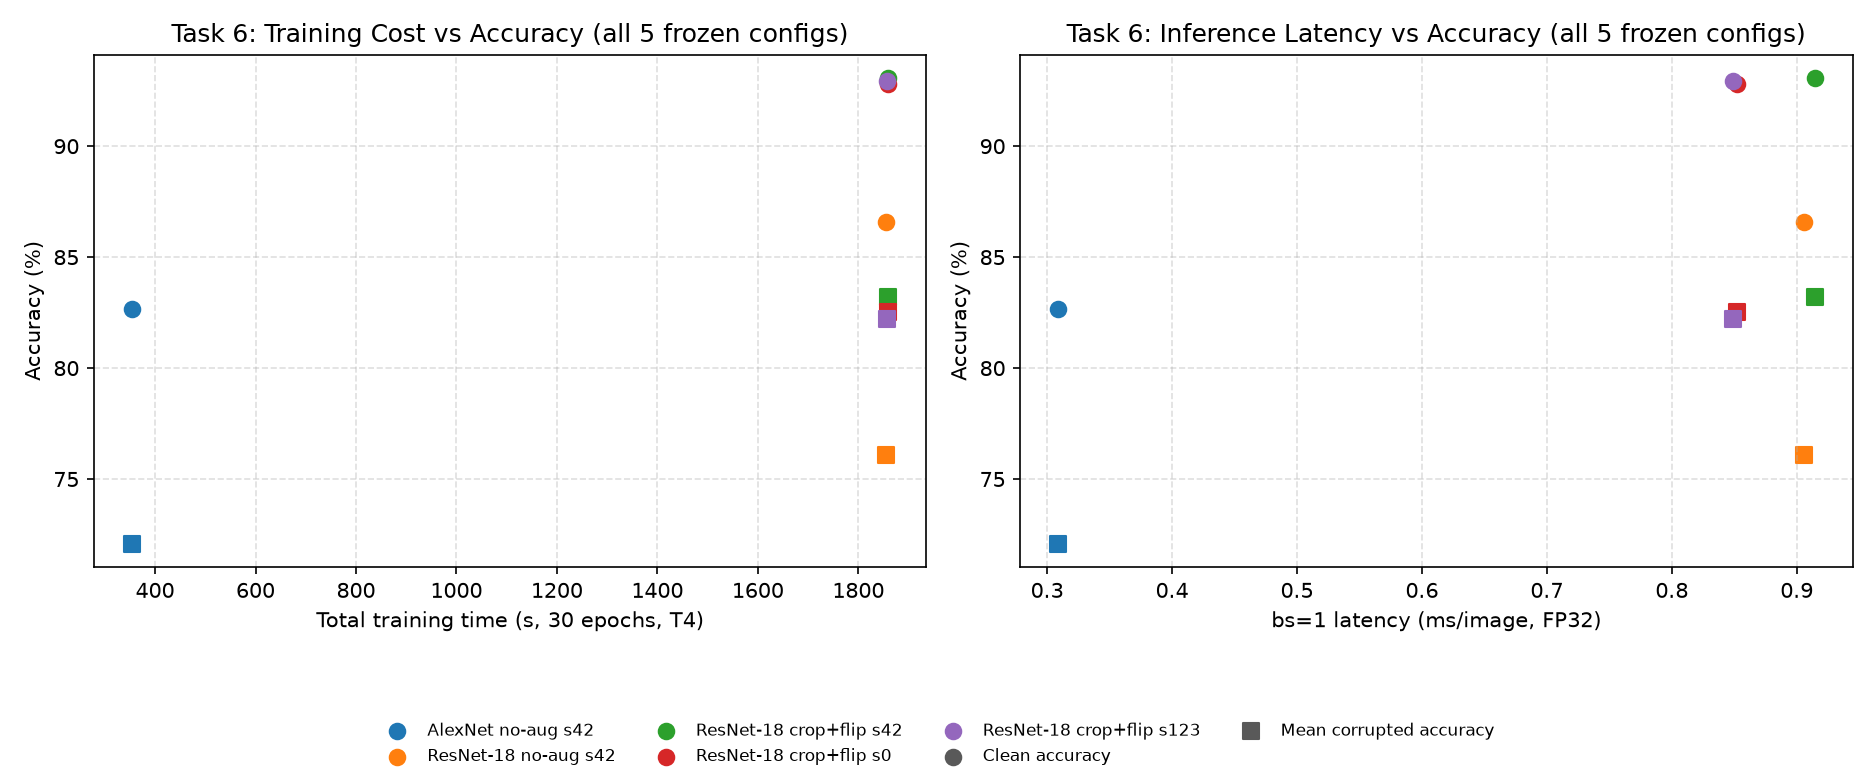

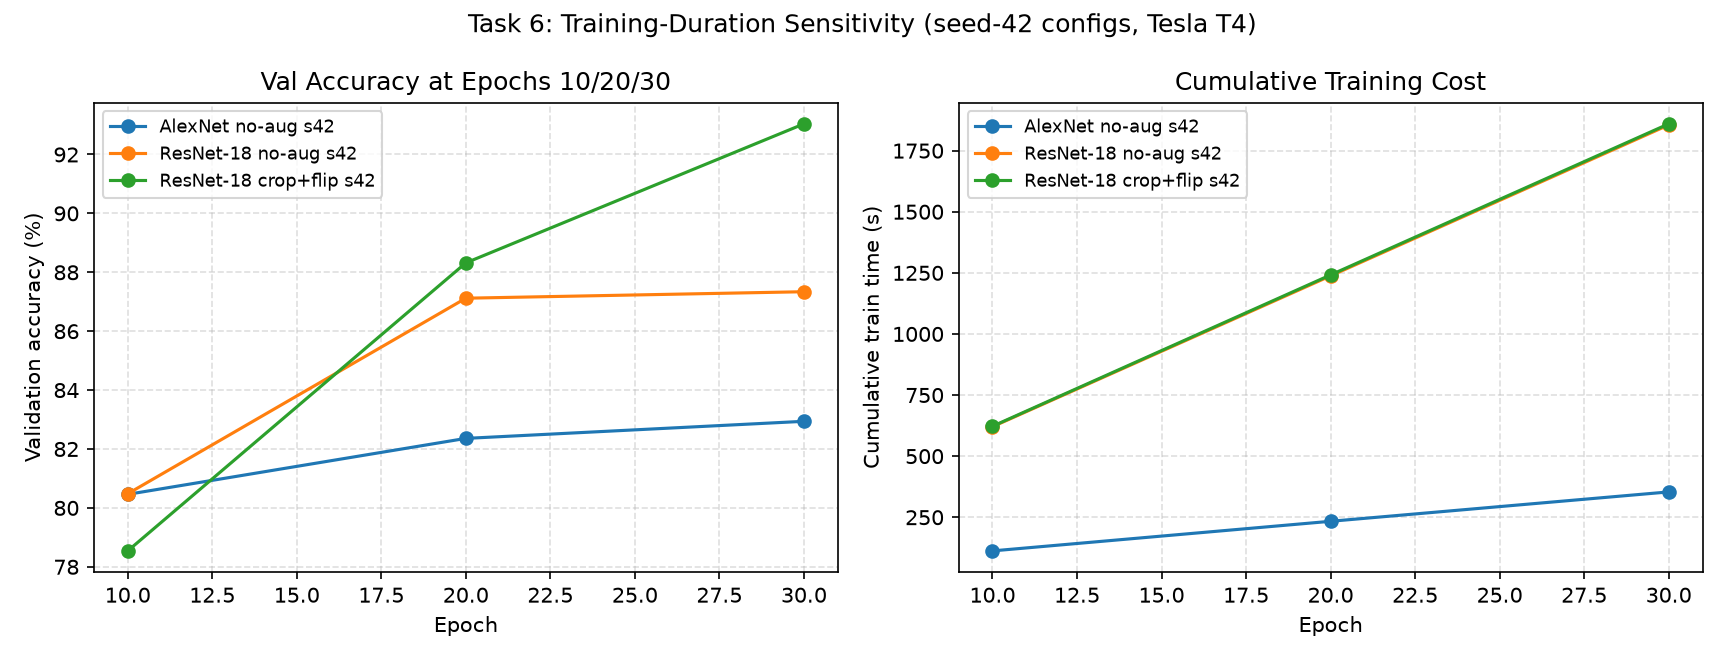

In [8]:
show_task(ROOT, '6')


## Reproduction, validation and references

The executed submission notebook presents these final results and the full source
appendix. `submission_source.zip` supplies all Python modules, tests, configurations,
split IDs, result JSON/CSV files, histories, prediction archives and figures.
`submission_instructions.md` gives display and full-training commands. A's notebook
now displays its saved original artifacts; B and C retain their original executed
training/evaluation notebooks. Data and model weights are kept outside Git and
the submission source archive. Exact weight locations are listed in
`checkpoints_manifest.json` and the shared Drive checkpoints folder.

The integration audit checks the disjoint 45k/5k split, all 13 continuous 30-epoch
histories, validation-selected epochs and 41 paired prediction conditions against
their saved metrics. Fresh CPU shape tracing checks the implemented architecture
against A's recorded profiles. This verifies consistency of the supplied artifacts;
it does not repeat their GPU training or timings. The repository's 34 existing
unit tests also passed. The original C records have an unknown Git commit field;
their source files and recorded outputs are preserved, and the submission's hash
inventory identifies the supplied snapshot without inventing a historical commit.

The course original is the submission standard:
[Lab Assignment 1](https://docs.google.com/document/d/1_WypZO1CwatDjMs1Mm4kfbG2GtAOk8y6/edit).
Implementation and method references are:

- Krizhevsky, Nair and Hinton, [CIFAR-10 dataset](https://www.cs.toronto.edu/~kriz/cifar.html).
- Course [Part A9 / Part B starting notebook](https://colab.research.google.com/drive/1ZsygMpALqkvHszLP_k1WaR8bilzjE3Iz).
- Krizhevsky, Sutskever and Hinton (2012), [ImageNet Classification with Deep Convolutional Neural Networks](https://proceedings.neurips.cc/paper/2012/hash/c399862d3b9d6b76c8436e924a68c45b-Abstract.html).
- He et al. (2016), [Deep Residual Learning for Image Recognition](https://arxiv.org/abs/1512.03385).
- Srivastava et al. (2014), [Dropout: A Simple Way to Prevent Neural Networks from Overfitting](https://jmlr.org/papers/v15/srivastava14a.html).
- Goodfellow, Shlens and Szegedy (2015), [Explaining and Harnessing Adversarial Examples](https://arxiv.org/abs/1412.6572).
- Coates, Ng and Lee (2011), [STL-10 dataset and paper](https://cs.stanford.edu/~acoates/stl10/).
- [PyTorch documentation](https://pytorch.org/docs/stable/index.html), for layers, SGD, scheduling and CUDA measurement APIs.
- Team [ScalableMlLab repository](https://github.com/Mrpooool/ScalableMlLab), frozen experiment contract and accompanying implementation.


## Full implementation and frozen configuration appendix

The following text cells embed the complete supplied Python implementation and settings for offline reading. The last executed cell prints the file hashes. Exact split IDs are in the accompanying archive. Full training commands and weight locations are in `submission_instructions.md`.


### lab1/src/__init__.py

```python
"""Shared core modules for Scalable ML Lab 1 (CIFAR-10 CNNs)."""

```


### lab1/src/adversarial.py

```python
"""Raw-pixel FGSM and paired, equal-budget random-noise evaluation for Task 5."""

from __future__ import annotations

import time

import numpy as np
import torch
from torch import nn

from data import prepare_inputs
from metrics import synchronize


def fgsm(model, raw, targets, stats, epsilon):
    """Untargeted L-infinity FGSM; parameter gradients and weights are unchanged.

    Caller sets eval mode. Normalization remains in the differentiable forward;
    epsilon is measured in raw [0, 1] pixels, not normalized coordinates.
    """
    if not 0 <= epsilon <= 1:
        raise ValueError("epsilon must be in [0, 1]")
    if epsilon == 0:
        return raw.detach().clone()
    with torch.enable_grad():
        inputs = raw.detach().clone().requires_grad_(True)
        loss = nn.functional.cross_entropy(model(prepare_inputs(inputs, stats)), targets)
        gradient, = torch.autograd.grad(loss, inputs)
    return (inputs.detach() + epsilon * gradient.sign()).clamp(0, 1)


def random_linf(raw, ids, epsilon, seed=2223):
    """Uniform [-epsilon, epsilon] noise, reproducible per original image ID."""
    noise = torch.stack([
        torch.rand(raw.shape[1:], generator=torch.Generator().manual_seed(seed + int(i)))
        for i in ids
    ]).to(device=raw.device, dtype=raw.dtype)
    return (raw + epsilon * (2 * noise - 1)).clamp(0, 1)


def summarize_attack(clean_predictions, predictions, targets):
    """ASR counts only originally correct samples; accuracy counts all samples."""
    clean_correct = np.asarray(clean_predictions) == np.asarray(targets)
    wrong = np.asarray(predictions) != np.asarray(targets)
    denominator = int(clean_correct.sum())
    successful = int((clean_correct & wrong).sum())
    return {
        "num_samples": int(len(targets)),
        "clean_accuracy": float(clean_correct.mean()),
        "accuracy": float((~wrong).mean()),
        "clean_correct_count": denominator,
        "successful_count": successful,
        "asr": successful / denominator if denominator else None,
    }


def evaluate_attack(model, loader, stats, device, epsilon, method="fgsm", seed=2223):
    """Evaluate every image, preserving IDs and returning JSON metrics + arrays."""
    if method not in ("fgsm", "random_linf"):
        raise ValueError(f"Unsupported perturbation: {method}")
    was_training = model.training
    model.eval()
    batches = {key: [] for key in ("ids", "targets", "clean_predictions", "predictions", "probabilities")}
    maximum_norm = loss_sum = 0.0
    synchronize(device)
    started = time.perf_counter()
    try:
        for raw, targets, ids in loader:
            raw, targets = raw.to(device), targets.to(device)
            with torch.no_grad():
                clean_predictions = model(prepare_inputs(raw, stats)).argmax(1)
            perturbed = (fgsm(model, raw, targets, stats, epsilon) if method == "fgsm"
                         else random_linf(raw, ids, epsilon, seed))
            norm = float((perturbed - raw).abs().max().item())
            if norm > epsilon + 1e-6 or perturbed.min() < 0 or perturbed.max() > 1:
                raise AssertionError("Perturbation violates the raw-pixel constraint")
            maximum_norm = max(maximum_norm, norm)
            with torch.no_grad():
                logits = model(prepare_inputs(perturbed, stats))
                loss_sum += nn.functional.cross_entropy(logits, targets, reduction="sum").item()
                probabilities = logits.softmax(1)
            values = (ids, targets, clean_predictions, logits.argmax(1), probabilities)
            for key, value in zip(batches, values):
                batches[key].append(value.detach().cpu().numpy())
    finally:
        model.train(was_training)
    synchronize(device)
    arrays = {key: np.concatenate(value) for key, value in batches.items()}
    metrics = summarize_attack(arrays["clean_predictions"], arrays["predictions"], arrays["targets"])
    metrics.update({
        "method": method, "targeted": False, "norm": "linf", "epsilon": epsilon,
        "max_observed_linf": maximum_norm, "ce": loss_sum / metrics["num_samples"],
        "evaluation_time_sec": time.perf_counter() - started,
        "random_seed": seed if method == "random_linf" else None,
    })
    return metrics, arrays

```


### lab1/src/corruptions.py

```python
"""Deterministic per-image test-set corruptions for Role C Task 4.

All corruptions are seeded per (seed, image_id) with a fresh CPU generator, so the
same image always receives the same corruption regardless of DataLoader worker count,
batch order, or evaluation run. Outputs keep the raw [0, 1] CHW tensor semantics of
``RawImages``; size, target, and image ID are never altered.
"""

from __future__ import annotations

import json
from pathlib import Path
from typing import Any, Sequence

import torch
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as TF

from data import RawImages

EXPECTED_CORRUPTION_NAMES: tuple[str, ...] = (
    "rotation_15deg",
    "translation_3px",
    "gaussian_noise_std_0_05",
)

KNOWN_KINDS: tuple[str, ...] = ("rotation", "translation", "gaussian_noise")

# Fields each kind must carry beyond name/kind.
_REQUIRED_FIELDS: dict[str, tuple[str, ...]] = {
    "rotation": ("max_degrees", "fill"),
    "translation": ("max_translate_pixels", "fill"),
    "gaussian_noise": ("std",),
}

_NUM_EXPECTED_IDS = 10_000


def _validate_spec(spec: dict[str, Any]) -> None:
    if not isinstance(spec, dict):
        raise ValueError(f"corruption spec must be a dict, got {type(spec).__name__}")
    kind = spec.get("kind")
    if kind not in KNOWN_KINDS:
        raise ValueError(f"unknown corruption kind: {kind!r}")
    missing = [field for field in _REQUIRED_FIELDS[kind] if field not in spec]
    if missing:
        raise ValueError(f"corruption spec {spec.get('name')!r} missing fields: {missing}")


def load_corruption_config(path: str | Path) -> dict[str, Any]:
    """Load and validate the frozen corruption protocol config.

    Enforces version 1, the cifar10/test fields, exactly 10,000 unique ascending
    image IDs (0..9999), and the three fixed corruption specs in order.
    """
    path = Path(path)
    with path.open("r", encoding="utf-8") as fh:
        config = json.load(fh)

    if int(config.get("version", -1)) != 1:
        raise ValueError(f"unsupported corruption config version: {config.get('version')!r}")
    if config.get("dataset") != "cifar10":
        raise ValueError(f"unexpected dataset: {config.get('dataset')!r}")
    if config.get("split") != "test":
        raise ValueError(f"unexpected split: {config.get('split')!r}")
    if not isinstance(config.get("seed"), int):
        raise ValueError("seed must be an integer")

    image_ids = config.get("image_ids")
    if not isinstance(image_ids, list):
        raise ValueError("image_ids must be a list")
    if len(image_ids) != _NUM_EXPECTED_IDS:
        raise ValueError(f"expected {_NUM_EXPECTED_IDS} image_ids, got {len(image_ids)}")
    if len(set(image_ids)) != len(image_ids):
        raise ValueError("image_ids contain duplicates")
    if image_ids != sorted(image_ids):
        raise ValueError("image_ids must be in ascending order")
    if image_ids != list(range(_NUM_EXPECTED_IDS)):
        raise ValueError("image_ids must be exactly list(range(10000))")

    corruptions = config.get("corruptions")
    if not isinstance(corruptions, list):
        raise ValueError("corruptions must be a list")
    names = [spec.get("name") for spec in corruptions if isinstance(spec, dict)]
    if names != list(EXPECTED_CORRUPTION_NAMES):
        raise ValueError(f"unexpected corruption names/order: {names!r}")
    for spec in corruptions:
        _validate_spec(spec)

    return config


def apply_corruption(
    raw: torch.Tensor,
    image_id: int,
    spec: dict[str, Any],
    seed: int,
) -> torch.Tensor:
    """Apply a single corruption spec to one raw [0, 1] CHW tensor.

    A fresh CPU generator is seeded with ``seed + image_id`` on every call, making the
    corruption a pure function of (seed, image_id, spec, pixel values). Geometric
    transforms use bilinear interpolation and the configured fill; every output is
    clamped to [0, 1]. Shape, dtype, target, and ID semantics are unchanged.
    """
    if raw.ndim != 3:
        raise ValueError(f"expected a CHW tensor, got shape {tuple(raw.shape)}")
    _validate_spec(spec)
    generator = torch.Generator().manual_seed(int(seed) + int(image_id))

    kind = spec["kind"]
    if kind == "rotation":
        max_degrees = float(spec["max_degrees"])
        angle = (float(torch.rand(1, generator=generator).item()) * 2.0 - 1.0) * max_degrees
        out = TF.affine(
            raw,
            angle=angle,
            translate=[0, 0],
            scale=1.0,
            shear=[0.0, 0.0],
            interpolation=InterpolationMode.BILINEAR,
            fill=float(spec["fill"]),
        )
        out = out.clamp_(0.0, 1.0)
    elif kind == "translation":
        max_t = int(spec["max_translate_pixels"])
        dx = int(torch.randint(-max_t, max_t + 1, (1,), generator=generator).item())
        dy = int(torch.randint(-max_t, max_t + 1, (1,), generator=generator).item())
        out = TF.affine(
            raw,
            angle=0.0,
            translate=[dx, dy],
            scale=1.0,
            shear=[0.0, 0.0],
            interpolation=InterpolationMode.BILINEAR,
            fill=float(spec["fill"]),
        )
        out = out.clamp_(0.0, 1.0)
    else:  # gaussian_noise
        std = float(spec["std"])
        noise = torch.randn(raw.shape, generator=generator, dtype=raw.dtype)
        out = (raw + noise * std).clamp_(0.0, 1.0)

    return out.contiguous()


class CorruptedImages(Dataset):
    """RawImages over a fixed ID list with one corruption spec applied per sample.

    Returns (corrupted_tensor, target, image_id) in the same (target, ID) order as the
    underlying ``RawImages``, so corrupted and clean loaders align sample-by-sample.
    """

    def __init__(
        self,
        test_dataset: Dataset,
        image_ids: Sequence[int],
        spec: dict[str, Any],
        seed: int,
    ) -> None:
        _validate_spec(spec)
        self.base = RawImages(test_dataset, ids=image_ids)
        self.spec = spec
        self.seed = int(seed)

    def __len__(self) -> int:
        return len(self.base)

    def __getitem__(self, idx: int) -> tuple[torch.Tensor, int, int]:
        raw, target, image_id = self.base[idx]
        corrupted = apply_corruption(raw, image_id, self.spec, self.seed)
        return corrupted, target, image_id


def make_corruption_loaders(
    test_dataset: Dataset,
    config: dict[str, Any],
    batch_size: int = 128,
    num_workers: int = 2,
    pin_memory: bool | None = None,
) -> dict[str, DataLoader]:
    """Build clean + one loader per corruption spec, all deterministic and ID-aligned.

    Every loader iterates the config's image_ids in the same ascending order with
    ``shuffle=False``; corruption randomness comes from per-sample generators, so
    num_workers=0 and num_workers=2 produce bit-identical inputs.
    """
    if pin_memory is None:
        pin_memory = torch.cuda.is_available()

    ids = [int(i) for i in config["image_ids"]]
    seed = int(config["seed"])
    common_kwargs: dict[str, Any] = {
        "batch_size": batch_size,
        "num_workers": num_workers,
        "pin_memory": pin_memory,
        "shuffle": False,
    }

    loaders: dict[str, DataLoader] = {
        "clean": DataLoader(RawImages(test_dataset, ids=ids), **common_kwargs)
    }
    for spec in config["corruptions"]:
        loaders[spec["name"]] = DataLoader(
            CorruptedImages(test_dataset, ids, spec, seed),
            **common_kwargs,
        )
    return loaders

```


### lab1/src/data.py

```python
"""Dataset loading, fixed train/val split, preprocessing, and DataLoader builders."""

from __future__ import annotations

import json
from pathlib import Path
from typing import Any, Callable, Sequence

import numpy as np
import torch
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.datasets.utils import download_and_extract_archive
from torchvision.transforms import functional as TF

from seed import make_generator, worker_init_fn

CIFAR10_MIRROR_URLS: tuple[str, ...] = (
    "https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz",
    "https://dataset.bj.bcebos.com/cifar/cifar-10-python.tar.gz",
)
CIFAR10_FILENAME = "cifar-10-python.tar.gz"
CIFAR10_MD5 = "c58f30108f718f92721af3b95e74349a"

SPLIT_SEED = 2223
VAL_RATIO = 0.1

CIFAR10_CLASSES: tuple[str, ...] = (
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
)

# Challenge 2: exact label mapping from STL-10 (excluding 7: monkey) to CIFAR-10 indices.
STL10_TO_CIFAR10: dict[int, int] = {
    0: 0,  # airplane -> airplane
    1: 2,  # bird -> bird
    2: 1,  # car -> automobile
    3: 3,  # cat -> cat
    4: 4,  # deer -> deer
    5: 5,  # dog -> dog
    6: 7,  # horse -> horse
    8: 8,  # ship -> ship
    9: 9,  # truck -> truck
}

CIFAR10_SHARED_9_IDS: tuple[int, ...] = (0, 1, 2, 3, 4, 5, 7, 8, 9)
CIFAR10_FROG_CLASS_ID = 6


def load_cifar10_datasets(
    data_root: str | Path,
) -> tuple[datasets.CIFAR10, datasets.CIFAR10]:
    """Load CIFAR-10 train and test splits, preferring the fast Brainchip mirror."""
    root = Path(data_root)
    root.mkdir(parents=True, exist_ok=True)
    try:
        train_ds = datasets.CIFAR10(root, train=True, download=False)
        test_ds = datasets.CIFAR10(root, train=False, download=False)
        return train_ds, test_ds
    except RuntimeError:
        pass

    for mirror_url in CIFAR10_MIRROR_URLS:
        try:
            download_and_extract_archive(
                mirror_url,
                download_root=str(root),
                filename=CIFAR10_FILENAME,
                md5=CIFAR10_MD5,
            )
            train_ds = datasets.CIFAR10(root, train=True, download=False)
            test_ds = datasets.CIFAR10(root, train=False, download=False)
            return train_ds, test_ds
        except Exception:
            continue

    train_ds = datasets.CIFAR10(root, train=True, download=True)
    test_ds = datasets.CIFAR10(root, train=False, download=True)
    return train_ds, test_ds


def compute_train_stats(
    train_dataset: datasets.CIFAR10,
    train_ids: Sequence[int],
    batch_size: int = 256,
) -> dict[str, list[float]]:
    """Compute per-channel RGB mean and std on training split images only."""
    ids = np.asarray(train_ids, dtype=np.int64)
    channel_sum = np.zeros(3, dtype=np.float64)
    channel_square_sum = np.zeros(3, dtype=np.float64)
    pixel_count = 0

    for start in range(0, len(ids), batch_size):
        batch_ids = ids[start : start + batch_size]
        pixels = train_dataset.data[batch_ids].astype(np.float64) / 255.0
        channel_sum += pixels.sum(axis=(0, 1, 2))
        channel_square_sum += np.square(pixels).sum(axis=(0, 1, 2))
        pixel_count += int(np.prod(pixels.shape[:3]))

    mean = channel_sum / pixel_count
    std = np.sqrt(np.maximum(channel_square_sum / pixel_count - mean**2, 1e-12))
    return {"mean": mean.tolist(), "std": std.tolist()}


def get_or_create_split(
    train_dataset: datasets.CIFAR10,
    split_path: str | Path,
    val_ratio: float = VAL_RATIO,
    split_seed: int = SPLIT_SEED,
) -> dict[str, Any]:
    """Load the frozen stratified train/val split or create and persist it once."""
    path = Path(split_path)
    if path.exists():
        with path.open("r", encoding="utf-8") as fh:
            payload = json.load(fh)
        train_ids = payload["train_ids"]
        val_ids = payload["val_ids"]
        assert set(train_ids).isdisjoint(val_ids), "Train and val splits overlap!"
        assert len(train_ids) + len(val_ids) == len(train_dataset), "Split size mismatch!"
        return payload

    labels = np.asarray(train_dataset.targets)
    train_ids, val_ids = train_test_split(
        np.arange(len(train_dataset)),
        test_size=val_ratio,
        stratify=labels,
        random_state=split_seed,
    )
    train_ids = np.sort(train_ids).tolist()
    val_ids = np.sort(val_ids).tolist()
    assert set(train_ids).isdisjoint(val_ids)

    stats = compute_train_stats(train_dataset, train_ids)
    payload = {
        "split_seed": int(split_seed),
        "val_ratio": float(val_ratio),
        "num_train": len(train_ids),
        "num_val": len(val_ids),
        "stats": stats,
        "train_ids": train_ids,
        "val_ids": val_ids,
    }
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp_path = path.with_suffix(path.suffix + ".tmp")
    with tmp_path.open("w", encoding="utf-8") as fh:
        json.dump(payload, fh, indent=2)
    tmp_path.replace(path)
    return payload


class RawImages(Dataset):
    """Dataset wrapper returning raw [0, 1] CHW tensor, integer label, and original image ID.

    Uses a bit-exact uint8->CHW fast path for numpy-backed datasets (e.g. torchvision CIFAR10)
    when no PIL transform is requested, avoiding redundant NumPy->PIL->Tensor conversions.
    """

    def __init__(
        self,
        dataset: Dataset,
        ids: Sequence[int] | None = None,
        pil_transform: Callable | None = None,
        tensor_transform: Callable | None = None,
    ) -> None:
        self.dataset = dataset
        self.ids = list(range(len(dataset))) if ids is None else [int(i) for i in ids]
        self.pil_transform = pil_transform
        self.tensor_transform = tensor_transform

        self._fast_images: torch.Tensor | None = None
        self._fast_targets: list[int] | None = None
        if (
            pil_transform is None
            and hasattr(dataset, "data")
            and hasattr(dataset, "targets")
            and isinstance(dataset.data, np.ndarray)
            and dataset.data.ndim == 4
            and dataset.data.dtype == np.uint8
        ):
            # [N, H, W, C] uint8 -> contiguous [N, C, H, W] uint8 in RAM (~150 MB for CIFAR-10).
            self._fast_images = torch.from_numpy(dataset.data).permute(0, 3, 1, 2).contiguous()
            self._fast_targets = [int(t) for t in dataset.targets]

    def __len__(self) -> int:
        return len(self.ids)

    def __getitem__(self, idx: int) -> tuple[torch.Tensor, int, int]:
        image_id = self.ids[idx]
        if self._fast_images is not None and self._fast_targets is not None:
            tensor = self._fast_images[image_id].to(dtype=torch.float32).div_(255.0)
            target = self._fast_targets[image_id]
        else:
            image, target = self.dataset[image_id]
            if self.pil_transform is not None:
                image = self.pil_transform(image)
            tensor = TF.to_tensor(image) if not isinstance(image, torch.Tensor) else image
            target = int(target)

        if self.tensor_transform is not None:
            tensor = self.tensor_transform(tensor)
        return tensor, target, image_id


def prepare_inputs(
    raw: torch.Tensor,
    stats: dict[str, Sequence[float]],
    size: int = 32,
) -> torch.Tensor:
    """Differentiably resize (if needed) and normalize raw [0, 1] image tensors."""
    if raw.shape[-2:] != (size, size):
        resized = nn.functional.interpolate(
            raw,
            size=(size, size),
            mode="bilinear",
            align_corners=False,
            antialias=True,
        )
    else:
        resized = raw
    mean = resized.new_tensor(stats["mean"])[None, :, None, None]
    std = resized.new_tensor(stats["std"])[None, :, None, None]
    return (resized - mean) / std


class TensorBatchLoader:
    """Fast, bit-exact batch iterator for uint8 numpy-backed datasets (e.g., CIFAR-10).

    Slices contiguous [N, C, H, W] uint8 tensors by batch directly, avoiding per-sample
    Python __getitem__ + default_collate overhead while preserving exact (raw, targets, ids)
    output semantics and deterministic per-epoch shuffling.
    """

    def __init__(
        self,
        images_chw_uint8: torch.Tensor,
        targets: torch.Tensor,
        ids: torch.Tensor,
        batch_size: int = 128,
        shuffle: bool = False,
        seed: int = 42,
    ) -> None:
        self.images = images_chw_uint8
        self.targets = targets
        self.ids = ids
        self.batch_size = int(batch_size)
        self.shuffle = bool(shuffle)
        self.generator = make_generator(seed) if shuffle else None

    def __len__(self) -> int:
        n = len(self.ids)
        return (n + self.batch_size - 1) // self.batch_size

    def __iter__(self):
        n = len(self.ids)
        if self.shuffle:
            order = torch.randperm(n, generator=self.generator)
        else:
            order = torch.arange(n)

        for start in range(0, n, self.batch_size):
            batch_idx = order[start : start + self.batch_size]
            raw = self.images[batch_idx].to(dtype=torch.float32).div_(255.0)
            yield raw, self.targets[batch_idx], self.ids[batch_idx]


def _can_use_fast_loader(dataset: Dataset) -> bool:
    return (
        hasattr(dataset, "data")
        and hasattr(dataset, "targets")
        and isinstance(dataset.data, np.ndarray)
        and dataset.data.ndim == 4
        and dataset.data.dtype == np.uint8
    )


def _build_fast_loader(
    dataset: Dataset,
    ids: Sequence[int] | None,
    batch_size: int,
    shuffle: bool,
    seed: int = 42,
) -> TensorBatchLoader:
    idx_list = list(range(len(dataset))) if ids is None else [int(i) for i in ids]
    idx_arr = np.asarray(idx_list, dtype=np.int64)
    imgs = torch.from_numpy(dataset.data[idx_arr]).permute(0, 3, 1, 2).contiguous()
    targets = torch.tensor([int(dataset.targets[i]) for i in idx_list], dtype=torch.long)
    id_tensor = torch.tensor(idx_list, dtype=torch.long)
    return TensorBatchLoader(
        images_chw_uint8=imgs,
        targets=targets,
        ids=id_tensor,
        batch_size=batch_size,
        shuffle=shuffle,
        seed=seed,
    )


def make_loaders(
    train_dataset: Dataset,
    test_dataset: Dataset,
    train_ids: Sequence[int],
    val_ids: Sequence[int],
    batch_size: int = 128,
    seed: int = 42,
    train_pil_transform: Callable | None = None,
    train_tensor_transform: Callable | None = None,
    num_workers: int = 2,
    pin_memory: bool | None = None,
) -> dict[str, Any]:
    """Create train, deterministic train_eval, val, and test batch loaders."""
    if pin_memory is None:
        pin_memory = torch.cuda.is_available()

    common_kwargs: dict[str, Any] = {
        "batch_size": batch_size,
        "num_workers": num_workers,
        "pin_memory": pin_memory,
    }
    if num_workers > 0:
        common_kwargs["worker_init_fn"] = worker_init_fn

    use_fast_train = (
        train_pil_transform is None
        and train_tensor_transform is None
        and _can_use_fast_loader(train_dataset)
    )
    if use_fast_train:
        train_loader: Any = _build_fast_loader(
            train_dataset, train_ids, batch_size=batch_size, shuffle=True, seed=seed
        )
    else:
        train_loader = DataLoader(
            RawImages(
                train_dataset,
                train_ids,
                pil_transform=train_pil_transform,
                tensor_transform=train_tensor_transform,
            ),
            shuffle=True,
            generator=make_generator(seed),
            **common_kwargs,
        )

    train_eval_loader: Any = (
        _build_fast_loader(train_dataset, train_ids, batch_size=batch_size, shuffle=False)
        if _can_use_fast_loader(train_dataset)
        else DataLoader(RawImages(train_dataset, train_ids), shuffle=False, **common_kwargs)
    )
    val_loader: Any = (
        _build_fast_loader(train_dataset, val_ids, batch_size=batch_size, shuffle=False)
        if _can_use_fast_loader(train_dataset)
        else DataLoader(RawImages(train_dataset, val_ids), shuffle=False, **common_kwargs)
    )
    test_loader: Any = (
        _build_fast_loader(test_dataset, None, batch_size=batch_size, shuffle=False)
        if _can_use_fast_loader(test_dataset)
        else DataLoader(RawImages(test_dataset), shuffle=False, **common_kwargs)
    )

    return {
        "train": train_loader,
        "train_eval": train_eval_loader,
        "val": val_loader,
        "test": test_loader,
    }


class STL10Shared9Dataset(Dataset):
    """Held-out STL-10 test set filtered to the 9 classes shared with CIFAR-10."""

    def __init__(self, stl10_dataset: datasets.STL10) -> None:
        self.dataset = stl10_dataset
        labels = np.asarray(stl10_dataset.labels, dtype=np.int64)
        self.valid_indices = [
            int(idx) for idx, lbl in enumerate(labels) if int(lbl) in STL10_TO_CIFAR10
        ]

    def __len__(self) -> int:
        return len(self.valid_indices)

    def __getitem__(self, idx: int) -> tuple[torch.Tensor, int, int]:
        orig_id = self.valid_indices[idx]
        image, stl_label = self.dataset[orig_id]
        cifar_label = STL10_TO_CIFAR10[int(stl_label)]
        tensor = TF.to_tensor(image) if not isinstance(image, torch.Tensor) else image
        return tensor, cifar_label, orig_id


def make_stl10_test_loader(
    data_root: str | Path,
    batch_size: int = 128,
    num_workers: int = 2,
    pin_memory: bool | None = None,
) -> DataLoader:
    """Download/load STL-10 test split filtered and mapped to CIFAR-10's 9 shared classes."""
    root = Path(data_root)
    root.mkdir(parents=True, exist_ok=True)
    stl_test = datasets.STL10(root=str(root), split="test", download=True)
    if pin_memory is None:
        pin_memory = torch.cuda.is_available()
    return DataLoader(
        STL10Shared9Dataset(stl_test),
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=pin_memory,
    )

```


### lab1/src/io_utils.py

```python
"""Atomic JSON/CSV I/O, environment capture, and checkpoint manifest management."""

from __future__ import annotations

import csv
import json
import subprocess
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

import numpy as np
import torch


def utc_now_iso() -> str:
    """Return current UTC timestamp in ISO-8601 format."""
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")


def get_git_commit(repo_root: str | Path | None = None) -> str:
    """Return the current short git commit SHA, or 'unknown' if unavailable."""
    try:
        cmd = ["git", "rev-parse", "--short", "HEAD"]
        result = subprocess.run(
            cmd,
            cwd=str(repo_root) if repo_root is not None else None,
            capture_output=True,
            text=True,
            check=True,
        )
        return result.stdout.strip() or "unknown"
    except Exception:
        return "unknown"


def get_environment_info(
    device: torch.device | str,
    precision: str = "fp32",
    platform_name: str | None = None,
) -> dict[str, Any]:
    """Capture hardware and PyTorch environment metadata for reproducibility."""
    dev = torch.device(device)
    if platform_name is None:
        platform_name = "colab" if Path("/content").exists() else "local"
    device_name = torch.cuda.get_device_name(dev) if dev.type == "cuda" else "CPU"
    return {
        "platform": platform_name,
        "device_name": device_name,
        "precision": precision,
        "torch_version": torch.__version__,
        "cuda_version": torch.version.cuda if torch.cuda.is_available() else None,
    }


def save_json(data: dict[str, Any], path: str | Path) -> Path:
    """Atomically write JSON with UTF-8 encoding."""
    target = Path(path)
    target.parent.mkdir(parents=True, exist_ok=True)
    tmp_path = target.with_suffix(target.suffix + ".tmp")
    with tmp_path.open("w", encoding="utf-8") as fh:
        json.dump(data, fh, indent=2, ensure_ascii=False)
    tmp_path.replace(target)
    return target


def load_json(path: str | Path) -> dict[str, Any]:
    """Load a UTF-8 JSON file."""
    with Path(path).open("r", encoding="utf-8") as fh:
        return json.load(fh)


def save_numpy_archive(arrays: dict[str, np.ndarray], path: str | Path) -> Path:
    """Atomically write a compressed .npz archive via a temporary file handle."""
    target = Path(path)
    target.parent.mkdir(parents=True, exist_ok=True)
    tmp_path = target.with_suffix(target.suffix + ".tmp")
    with tmp_path.open("wb") as fh:
        np.savez_compressed(fh, **arrays)
    tmp_path.replace(target)
    return target


def save_history_csv(history: list[dict[str, Any]], path: str | Path) -> Path:
    """Write per-epoch training/validation history rows to CSV."""
    target = Path(path)
    target.parent.mkdir(parents=True, exist_ok=True)
    if not history:
        return target
    fieldnames = list(history[0].keys())
    tmp_path = target.with_suffix(target.suffix + ".tmp")
    with tmp_path.open("w", encoding="utf-8", newline="") as fh:
        writer = csv.DictWriter(fh, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(history)
    tmp_path.replace(target)
    return target


def register_checkpoint(manifest_path: str | Path, entry: dict[str, Any]) -> Path:
    """Upsert a checkpoint entry (keyed by exp_id) into checkpoints_manifest.json."""
    path = Path(manifest_path)
    if path.exists():
        manifest = load_json(path)
    else:
        manifest = {"version": "1.0", "checkpoints": []}

    checkpoints = [
        item for item in manifest.get("checkpoints", []) if item.get("exp_id") != entry["exp_id"]
    ]
    checkpoints.append(entry)
    manifest["checkpoints"] = checkpoints
    return save_json(manifest, path)


def load_checkpoint_weights(
    model: torch.nn.Module,
    ckpt_path: str | Path,
    device: torch.device | str,
) -> dict[str, Any]:
    """Load saved state_dict into model and return checkpoint metadata."""
    payload = torch.load(Path(ckpt_path), map_location=device, weights_only=False)
    state_dict = payload["model_state_dict"] if "model_state_dict" in payload else payload
    model.load_state_dict(state_dict)
    return payload


def aggregate_results_to_csv(results_dir: str | Path, out_csv: str | Path) -> list[dict[str, Any]]:
    """Aggregate all lab1/results/*.json experiment logs into a flat summary.csv."""
    res_dir = Path(results_dir)
    rows: list[dict[str, Any]] = []
    for json_path in sorted(res_dir.glob("*.json")):
        if json_path.name == "checkpoints_manifest.json":
            continue
        data = load_json(json_path)
        if "exp_id" not in data:
            continue
        cfg = data.get("config", {})
        env = data.get("environment", {})
        stats = data.get("model_stats", {})
        tr = data.get("training", {})
        ev = data.get("evaluation", {})
        inf = data.get("inference_benchmark", {})
        rows.append(
            {
                "exp_id": data.get("exp_id"),
                "task": data.get("task"),
                "owner": data.get("owner"),
                "model": cfg.get("model"),
                "seed": cfg.get("seed"),
                "epochs": cfg.get("epochs"),
                "batch_size": cfg.get("batch_size"),
                "optimizer": cfg.get("optimizer"),
                "lr": cfg.get("lr"),
                "weight_decay": cfg.get("weight_decay"),
                "dropout": cfg.get("dropout"),
                "augmentation": cfg.get("augmentation"),
                "device_name": env.get("device_name"),
                "total_params": stats.get("total_params"),
                "num_trained_samples": tr.get("num_trained_samples"),
                "total_train_time_sec": tr.get("total_train_time_sec"),
                "peak_gpu_mem_mb": tr.get("peak_gpu_mem_mb"),
                "best_epoch": tr.get("best_epoch"),
                "best_val_acc": tr.get("best_val_acc"),
                "best_val_ce": tr.get("best_val_ce"),
                "final_train_eval_acc": tr.get("final_train_eval_acc"),
                "clean_test_acc": ev.get("clean_test_acc"),
                "macro_f1": ev.get("macro_f1"),
                "bs1_latency_ms": inf.get("bs1_latency_ms"),
                "bs128_throughput_imgs_per_sec": inf.get("bs128_throughput_imgs_per_sec"),
            }
        )

    if rows:
        save_history_csv(rows, out_csv)
    return rows

```


### lab1/src/metrics.py

```python
"""Evaluation metrics, cross-domain STL-10 scoring, and synchronized inference benchmarks."""

from __future__ import annotations

import time
from typing import Any, Sequence

import numpy as np
import torch
from sklearn.metrics import f1_score
from torch import nn
from torch.utils.data import DataLoader

from data import (
    CIFAR10_CLASSES,
    CIFAR10_FROG_CLASS_ID,
    CIFAR10_SHARED_9_IDS,
    prepare_inputs,
)


def synchronize(device: torch.device | str) -> None:
    """Synchronize CUDA stream for accurate GPU timing."""
    dev = torch.device(device)
    if dev.type == "cuda" and torch.cuda.is_available():
        torch.cuda.synchronize(dev)


def compute_per_class_accuracy(
    targets: np.ndarray,
    predictions: np.ndarray,
    class_names: Sequence[str] = CIFAR10_CLASSES,
) -> dict[str, float | None]:
    """Compute accuracy per class; classes with no samples map to None."""
    targets_arr = np.asarray(targets)
    preds_arr = np.asarray(predictions)
    per_class: dict[str, float | None] = {}
    for cls_id, cls_name in enumerate(class_names):
        cls_mask = targets_arr == cls_id
        if cls_mask.any():
            per_class[cls_name] = float(np.mean(preds_arr[cls_mask] == cls_id))
        else:
            per_class[cls_name] = None
    return per_class


@torch.inference_mode()
def evaluate_model(
    model: nn.Module,
    loader: DataLoader,
    stats: dict[str, Sequence[float]],
    device: torch.device | str,
    input_size: int = 32,
) -> dict[str, Any]:
    """Deterministically evaluate a model on a RawImages DataLoader."""
    dev = torch.device(device)
    was_training = model.training
    model.eval()
    loss_sum = 0.0
    all_ids: list[int] = []
    all_targets: list[int] = []
    all_probs: list[np.ndarray] = []

    try:
        for raw, targets, ids in loader:
            raw = raw.to(dev, non_blocking=True)
            targets = targets.to(dev, non_blocking=True)
            logits = model(prepare_inputs(raw, stats, input_size))
            loss_sum += nn.functional.cross_entropy(logits, targets, reduction="sum").item()
            all_ids.extend(ids.tolist())
            all_targets.extend(targets.cpu().tolist())
            all_probs.append(logits.softmax(dim=1).cpu().numpy())
    finally:
        model.train(was_training)

    probabilities = np.concatenate(all_probs, axis=0)
    targets_arr = np.asarray(all_targets, dtype=np.int64)
    predictions = probabilities.argmax(axis=1)
    accuracy = float(np.mean(predictions == targets_arr))
    macro_f1 = float(f1_score(targets_arr, predictions, average="macro", zero_division=0))

    return {
        "ce": float(loss_sum / len(targets_arr)),
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "num_samples": int(len(targets_arr)),
        "per_class_accuracy": compute_per_class_accuracy(targets_arr, predictions),
        "ids": np.asarray(all_ids, dtype=np.int64),
        "targets": targets_arr,
        "predictions": predictions,
        "probabilities": probabilities,
    }


def evaluate_cifar10_shared9(eval_result: dict[str, Any]) -> dict[str, Any]:
    """Compute CIFAR-10 accuracy on the 9 classes shared with STL-10 (excluding frog)."""
    targets = eval_result["targets"]
    probs = eval_result["probabilities"]
    mask = np.isin(targets, CIFAR10_SHARED_9_IDS)

    targets_9 = targets[mask]
    probs_9 = probs[mask]
    preds_10way = probs_9.argmax(axis=1)

    masked_probs = probs_9.copy()
    masked_probs[:, CIFAR10_FROG_CLASS_ID] = -np.inf
    preds_9way = masked_probs.argmax(axis=1)

    per_class_acc_9way: dict[str, float] = {}
    for cls_id in CIFAR10_SHARED_9_IDS:
        cls_mask = targets_9 == cls_id
        if cls_mask.any():
            per_class_acc_9way[CIFAR10_CLASSES[cls_id]] = float(
                np.mean(preds_9way[cls_mask] == cls_id)
            )

    return {
        "num_samples": int(mask.sum()),
        "cifar10_shared9_10way_acc": float(np.mean(preds_10way == targets_9)),
        "cifar10_shared9_9way_masked_acc": float(np.mean(preds_9way == targets_9)),
        "cifar10_shared9_frog_leakage_rate": float(np.mean(preds_10way == CIFAR10_FROG_CLASS_ID)),
        "per_class_acc_9way": per_class_acc_9way,
    }


@torch.inference_mode()
def evaluate_stl10_cross_domain(
    model: nn.Module,
    stl10_loader: DataLoader,
    cifar_train_stats: dict[str, Sequence[float]],
    device: torch.device | str,
    input_size: int = 32,
) -> dict[str, Any]:
    """Evaluate a frozen CIFAR-10 model on held-out STL-10 (9 shared classes).

    Reports both unmodified 10-way accuracy (with frog leakage rate) and 9-way masked accuracy.
    """
    dev = torch.device(device)
    was_training = model.training
    model.eval()
    all_ids: list[int] = []
    all_targets: list[int] = []
    all_logits: list[np.ndarray] = []

    try:
        for raw, targets, ids in stl10_loader:
            raw = raw.to(dev, non_blocking=True)
            logits = model(prepare_inputs(raw, cifar_train_stats, input_size))
            all_ids.extend(ids.tolist())
            all_targets.extend(targets.tolist())
            all_logits.append(logits.cpu().numpy())
    finally:
        model.train(was_training)

    ids_arr = np.asarray(all_ids, dtype=np.int64)
    targets_arr = np.asarray(all_targets, dtype=np.int64)
    logits_arr = np.concatenate(all_logits, axis=0)
    preds_10way = logits_arr.argmax(axis=1)

    masked_logits = logits_arr.copy()
    masked_logits[:, CIFAR10_FROG_CLASS_ID] = -np.inf
    preds_9way = masked_logits.argmax(axis=1)

    per_class_9way: dict[str, float] = {}
    for cls_id in CIFAR10_SHARED_9_IDS:
        cls_mask = targets_arr == cls_id
        if cls_mask.any():
            per_class_9way[CIFAR10_CLASSES[cls_id]] = float(
                np.mean(preds_9way[cls_mask] == cls_id)
            )

    return {
        "num_samples": int(len(targets_arr)),
        "stl10_10way_acc": float(np.mean(preds_10way == targets_arr)),
        "stl10_frog_leakage_rate": float(np.mean(preds_10way == CIFAR10_FROG_CLASS_ID)),
        "stl10_9way_masked_acc": float(np.mean(preds_9way == targets_arr)),
        "stl10_9way_macro_f1": float(
            f1_score(
                targets_arr,
                preds_9way,
                labels=list(CIFAR10_SHARED_9_IDS),
                average="macro",
                zero_division=0,
            )
        ),
        "per_class_acc_9way": per_class_9way,
        "ids": ids_arr,
        "targets": targets_arr,
        "predictions_10way": preds_10way,
        "predictions_9way": preds_9way,
    }


def build_cross_domain_summary(cifar9: dict[str, Any], stl10: dict[str, Any]) -> dict[str, Any]:
    """Combine CIFAR-10 shared9 and STL-10 results into a JSON-safe summary.

    Total and per-class domain drop use the CIFAR-10 shared9 9-way masked accuracy minus
    the STL-10 9-way masked accuracy.
    """
    cifar_acc = float(cifar9["cifar10_shared9_9way_masked_acc"])
    stl_acc = float(stl10["stl10_9way_masked_acc"])
    per_class_cifar = cifar9["per_class_acc_9way"]
    per_class_stl = stl10["per_class_acc_9way"]
    per_class_drop: dict[str, float] = {}
    for cls_id in CIFAR10_SHARED_9_IDS:
        cls_name = CIFAR10_CLASSES[cls_id]
        if cls_name in per_class_cifar and cls_name in per_class_stl:
            per_class_drop[cls_name] = float(per_class_cifar[cls_name]) - float(
                per_class_stl[cls_name]
            )
    return {
        "num_cifar10_shared9": int(cifar9["num_samples"]),
        "num_stl10": int(stl10["num_samples"]),
        "cifar10_test_9way_acc": cifar_acc,
        "stl10_10way_acc": float(stl10["stl10_10way_acc"]),
        "stl10_frog_leakage_rate": float(stl10["stl10_frog_leakage_rate"]),
        "stl10_9way_masked_acc": stl_acc,
        "stl10_9way_macro_f1": float(stl10["stl10_9way_macro_f1"]),
        "domain_drop_9way": cifar_acc - stl_acc,
        "per_class_cifar10_9way_acc": {k: float(v) for k, v in per_class_cifar.items()},
        "per_class_stl10_9way_acc": {k: float(v) for k, v in per_class_stl.items()},
        "per_class_domain_drop_9way": per_class_drop,
    }


@torch.inference_mode()
def benchmark_inference(
    model: nn.Module,
    stats: dict[str, Sequence[float]],
    device: torch.device | str,
    input_size: int = 32,
    warmup_runs: int = 10,
    measured_runs: int = 50,
    precision: str = "fp32",
) -> dict[str, Any]:
    """Measure model-only inference latency at bs=1 and throughput at bs=128."""
    dev = torch.device(device)
    was_training = model.training
    model.eval()
    device_name = torch.cuda.get_device_name(dev) if dev.type == "cuda" else "CPU"

    def _time_batch(batch_size: int) -> float:
        raw = torch.rand(batch_size, 3, input_size, input_size, device=dev)
        prepared = prepare_inputs(raw, stats, input_size)
        for _ in range(warmup_runs):
            _ = model(prepared)
        synchronize(dev)
        started = time.perf_counter()
        for _ in range(measured_runs):
            _ = model(prepared)
        synchronize(dev)
        return (time.perf_counter() - started) / measured_runs

    try:
        sec_bs1 = _time_batch(1)
        sec_bs128 = _time_batch(128)
    finally:
        model.train(was_training)

    return {
        "device_name": device_name,
        "precision": precision,
        "bs1_latency_ms": float(sec_bs1 * 1000.0),
        "bs128_latency_ms_per_batch": float(sec_bs128 * 1000.0),
        "bs128_throughput_imgs_per_sec": float(128.0 / max(sec_bs128, 1e-12)),
        "warmup_runs": int(warmup_runs),
        "measured_runs": int(measured_runs),
    }

```


### lab1/src/models.py

```python
"""From-scratch CIFAR-10 CNN architectures aligned with ID2223 Part A9.

No pretrained weights or torchvision.models constructors are used.
"""

from __future__ import annotations

from typing import Any, Sequence

import torch
from torch import nn


class AlexNetCIFAR(nn.Module):
    """Part A9 CIFAR-10 adapted AlexNet (3x32x32 input).

    Default configuration matches the Part A9 table:
      Conv1(3->64) + Pool -> Conv2(64->192) + Pool -> Conv3(192->384)
      -> Conv4(384->256) -> Conv5(256->256) + Pool -> Flatten(4096)
      -> FC1(4096->1024) + Drop -> FC2(1024->512) + Drop -> FC3(512->10)
    """

    def __init__(
        self,
        num_classes: int = 10,
        dropout: float = 0.5,
        width_mult: float = 1.0,
        fc_hidden1: int = 1024,
        fc_hidden2: int = 512,
        use_bn: bool = False,
    ) -> None:
        super().__init__()
        c1 = max(8, int(round(64 * width_mult)))
        c2 = max(16, int(round(192 * width_mult)))
        c3 = max(32, int(round(384 * width_mult)))
        c4 = max(32, int(round(256 * width_mult)))
        c5 = max(32, int(round(256 * width_mult)))

        def conv_block(in_ch: int, out_ch: int) -> list[nn.Module]:
            layers: list[nn.Module] = [
                nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=not use_bn)
            ]
            if use_bn:
                layers.append(nn.BatchNorm2d(out_ch))
            layers.append(nn.ReLU(inplace=True))
            return layers

        self.stage1 = nn.Sequential(*conv_block(3, c1), nn.MaxPool2d(kernel_size=2, stride=2))
        self.stage2 = nn.Sequential(*conv_block(c1, c2), nn.MaxPool2d(kernel_size=2, stride=2))
        self.stage3 = nn.Sequential(
            *conv_block(c2, c3),
            *conv_block(c3, c4),
            *conv_block(c4, c5),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(c5 * 4 * 4, fc_hidden1),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(fc_hidden1, fc_hidden2),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(fc_hidden2, num_classes),
        )
        self._init_weights()

    def _init_weights(self) -> None:
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
                if module.bias is not None:
                    nn.init.zeros_(module.bias)
            elif isinstance(module, nn.BatchNorm2d):
                nn.init.ones_(module.weight)
                nn.init.zeros_(module.bias)
            elif isinstance(module, nn.Linear):
                nn.init.kaiming_normal_(module.weight, mode="fan_in", nonlinearity="relu")
                nn.init.zeros_(module.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        return self.classifier(x)


class BasicBlock(nn.Module):
    """Standard ResNet basic residual block (2x 3x3 Conv + BN, ReLU after skip addition)."""

    def __init__(self, in_channels: int, out_channels: int, stride: int = 1) -> None:
        super().__init__()
        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=False,
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False,
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        if stride != 1 or in_channels != out_channels:
            self.shortcut: nn.Module = nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False,
                ),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)
        return self.relu(out)


class ResNetCIFAR(nn.Module):
    """Part A9 CIFAR-10 adapted ResNet (default ResNet-18: layers=(2, 2, 2, 2), base_width=64).

    Uses a 3x3 stride-1 stem without initial max pooling to preserve 32x32 resolution.
    Configurable layers, base_width, and head dropout support Task 3 ablations cleanly.
    """

    def __init__(
        self,
        layers: Sequence[int] = (2, 2, 2, 2),
        base_width: int = 64,
        dropout: float = 0.0,
        num_classes: int = 10,
    ) -> None:
        super().__init__()
        if len(layers) != 4:
            raise ValueError(f"Expected 4 stage block counts, got {layers}")

        widths = (base_width, base_width * 2, base_width * 4, base_width * 8)
        self.stem = nn.Sequential(
            nn.Conv2d(3, widths[0], kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(widths[0]),
            nn.ReLU(inplace=True),
        )
        self.stage1 = self._make_stage(widths[0], widths[0], num_blocks=layers[0], stride=1)
        self.stage2 = self._make_stage(widths[0], widths[1], num_blocks=layers[1], stride=2)
        self.stage3 = self._make_stage(widths[1], widths[2], num_blocks=layers[2], stride=2)
        self.stage4 = self._make_stage(widths[2], widths[3], num_blocks=layers[3], stride=2)
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(p=dropout),
            nn.Linear(widths[3], num_classes),
        )
        self._init_weights()

    @staticmethod
    def _make_stage(
        in_channels: int,
        out_channels: int,
        num_blocks: int,
        stride: int,
    ) -> nn.Sequential:
        blocks = [BasicBlock(in_channels, out_channels, stride=stride)]
        for _ in range(1, num_blocks):
            blocks.append(BasicBlock(out_channels, out_channels, stride=1))
        return nn.Sequential(*blocks)

    def _init_weights(self) -> None:
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(module, nn.BatchNorm2d):
                nn.init.ones_(module.weight)
                nn.init.zeros_(module.bias)
            elif isinstance(module, nn.Linear):
                nn.init.kaiming_normal_(module.weight, mode="fan_in", nonlinearity="relu")
                nn.init.zeros_(module.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        return self.head(x)


def build_model(
    name: str,
    options: dict[str, Any] | None = None,
    device: torch.device | str | None = None,
) -> tuple[nn.Module, int]:
    """Instantiate a CIFAR-10 model by name and return (model, input_size)."""
    opts = dict(options) if options else {}
    if name == "alexnet_cifar":
        model: nn.Module = AlexNetCIFAR(**opts)
    elif name in ("resnet18_cifar", "resnet_cifar"):
        model = ResNetCIFAR(**opts)
    else:
        raise ValueError(f"Unknown model name: {name!r}")

    if device is not None:
        model = model.to(device)
    return model, 32


def count_parameters(model: nn.Module) -> dict[str, int]:
    """Return total and trainable parameter counts."""
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return {"total_params": int(total), "trainable_params": int(trainable)}


@torch.inference_mode()
def trace_shapes(
    model: nn.Module,
    input_size: int = 32,
    device: torch.device | str | None = None,
) -> list[dict[str, Any]]:
    """Trace top-level stage output shapes using forward hooks (aligned with Part A4)."""
    if device is None:
        device = next(model.parameters()).device

    rows: list[dict[str, Any]] = []
    hooks = []

    def make_hook(stage_name: str):
        def _hook(_module, _inputs, output):
            rows.append({"stage": stage_name, "shape": list(output.shape)})

        return _hook

    for stage_name, layer in model.named_children():
        hooks.append(layer.register_forward_hook(make_hook(stage_name)))

    was_training = model.training
    model.eval()
    try:
        dummy = torch.zeros(1, 3, input_size, input_size, device=device)
        logits = model(dummy)
        assert logits.shape == (1, 10) and torch.isfinite(logits).all()
    finally:
        for hook in hooks:
            hook.remove()
        model.train(was_training)

    return rows

```


### lab1/src/plots.py

```python
"""Reusable Matplotlib plotting helpers for Lab 1 tasks and report figures."""

from __future__ import annotations

import csv
from pathlib import Path
from typing import Any, Sequence

import matplotlib
import numpy as np
import pandas as pd
import torch

from corruptions import apply_corruption
from data import CIFAR10_CLASSES, CIFAR10_SHARED_9_IDS
from io_utils import load_json

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402


def plot_class_distribution(
    train_targets: Sequence[int],
    val_targets: Sequence[int],
    test_targets: Sequence[int],
    class_names: Sequence[str],
    out_path: str | Path,
) -> Path:
    """Save a grouped bar chart showing CIFAR-10 train / val / test class counts."""
    target = Path(out_path)
    target.parent.mkdir(parents=True, exist_ok=True)

    n_classes = len(class_names)
    tr_counts = np.bincount(np.asarray(train_targets), minlength=n_classes)
    va_counts = np.bincount(np.asarray(val_targets), minlength=n_classes)
    te_counts = np.bincount(np.asarray(test_targets), minlength=n_classes)

    x = np.arange(n_classes)
    width = 0.27

    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.bar(x - width, tr_counts, width=width, label=f"Train ({len(train_targets):,})")
    ax.bar(x, va_counts, width=width, label=f"Val ({len(val_targets):,})")
    ax.bar(x + width, te_counts, width=width, label=f"Test ({len(test_targets):,})")
    ax.set_xticks(x)
    ax.set_xticklabels(class_names, rotation=30, ha="right")
    ax.set_ylabel("Number of images")
    ax.set_title("CIFAR-10 Stratified Split Class Distribution (SPLIT_SEED=2223)")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend()
    fig.tight_layout()
    fig.savefig(target, dpi=150)
    plt.close(fig)
    return target


def plot_sample_grid(
    images_hwc_uint8: np.ndarray,
    targets: Sequence[int],
    ids: Sequence[int],
    class_names: Sequence[str],
    out_path: str | Path,
    per_class: int = 3,
) -> Path:
    """Save a representative grid of CIFAR-10 images (one row per class or 2x5)."""
    target = Path(out_path)
    target.parent.mkdir(parents=True, exist_ok=True)

    labels = np.asarray(targets)
    id_arr = np.asarray(ids)
    n_classes = len(class_names)

    fig, axes = plt.subplots(n_classes, per_class, figsize=(per_class * 2.0, n_classes * 1.35))
    for cls_idx in range(n_classes):
        matches = np.flatnonzero(labels == cls_idx)[:per_class]
        for col_idx, pos in enumerate(matches):
            ax = axes[cls_idx, col_idx] if per_class > 1 else axes[cls_idx]
            ax.imshow(images_hwc_uint8[pos])
            if col_idx == 0:
                ax.set_ylabel(class_names[cls_idx], rotation=0, labelpad=42, va="center", fontsize=9)
            ax.set_title(f"ID {int(id_arr[pos])}", fontsize=8)
            ax.set_xticks([])
            ax.set_yticks([])
    fig.suptitle("Representative CIFAR-10 Training Images (32x32 RGB)", y=0.995, fontsize=11)
    fig.tight_layout()
    fig.savefig(target, dpi=150)
    plt.close(fig)
    return target


def plot_baseline_learning_curves(
    histories: dict[str, list[dict[str, Any]]],
    out_path: str | Path,
) -> Path:
    """Plot deterministic train_eval vs val loss and accuracy curves for multiple models."""
    target = Path(out_path)
    target.parent.mkdir(parents=True, exist_ok=True)

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    for idx, (label, rows) in enumerate(histories.items()):
        df = pd.DataFrame(rows)
        color = colors[idx % len(colors)]
        axes[0].plot(
            df["epoch"],
            df["train_eval_ce"],
            linestyle="--",
            color=color,
            alpha=0.85,
            label=f"{label} (train_eval)",
        )
        axes[0].plot(
            df["epoch"],
            df["val_ce"],
            linestyle="-",
            color=color,
            linewidth=2.0,
            label=f"{label} (val)",
        )
        axes[1].plot(
            df["epoch"],
            df["train_eval_acc"] * 100.0,
            linestyle="--",
            color=color,
            alpha=0.85,
            label=f"{label} (train_eval)",
        )
        axes[1].plot(
            df["epoch"],
            df["val_acc"] * 100.0,
            linestyle="-",
            color=color,
            linewidth=2.0,
            label=f"{label} (val)",
        )

    axes[0].set(xlabel="Epoch", ylabel="Cross-Entropy Loss", title="Loss Curves (Deterministic Eval)")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy (%)", title="Accuracy Curves (Deterministic Eval)")
    for ax in axes:
        ax.grid(True, linestyle="--", alpha=0.4)
        ax.legend(fontsize=8.5)
    fig.tight_layout()
    fig.savefig(target, dpi=150)
    plt.close(fig)
    return target


def plot_baseline_comparison(
    records: Sequence[dict[str, Any]],
    out_path: str | Path,
) -> Path:
    """Save a 3-panel summary bar chart comparing accuracy, params/memory, and speed."""
    target = Path(out_path)
    target.parent.mkdir(parents=True, exist_ok=True)

    names = [r["config"]["model"] for r in records]
    val_accs = [r["training"]["best_val_acc"] * 100.0 for r in records]
    test_accs = [(r["evaluation"]["clean_test_acc"] or 0.0) * 100.0 for r in records]
    params_m = [r["model_stats"]["total_params"] / 1e6 for r in records]
    train_secs = [r["training"]["total_train_time_sec"] for r in records]

    x = np.arange(len(names))
    fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8))

    w = 0.34
    axes[0].bar(x - w / 2, val_accs, width=w, label="Best Val Acc")
    axes[0].bar(x + w / 2, test_accs, width=w, label="Clean Test Acc")
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(names)
    axes[0].set_ylabel("Accuracy (%)")
    axes[0].set_title("Validation vs Test Accuracy")
    axes[0].set_ylim(0, 100)
    axes[0].grid(axis="y", linestyle="--", alpha=0.4)
    axes[0].legend(fontsize=8.5)

    axes[1].bar(x, params_m, width=0.45, color="#4C72B0")
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(names)
    axes[1].set_ylabel("Parameters (Millions)")
    axes[1].set_title("Model Parameter Count")
    axes[1].grid(axis="y", linestyle="--", alpha=0.4)

    axes[2].bar(x, train_secs, width=0.45, color="#DD8452")
    axes[2].set_xticks(x)
    axes[2].set_xticklabels(names)
    axes[2].set_ylabel("Total Train Time (s)")
    axes[2].set_title("30-Epoch Training Cost")
    axes[2].grid(axis="y", linestyle="--", alpha=0.4)

    fig.tight_layout()
    fig.savefig(target, dpi=150)
    plt.close(fig)
    return target


# ---------------------------------------------------------------------------
# Role C figures (Task 4 corruptions, Challenge 2 STL-10, Task 6 tradeoffs).
#
# Numeric figures read the saved result JSONs / CSV tables; per-image figures read
# the saved prediction NPZ archives. Pixels are reconstructed from the original
# CIFAR-10/STL-10 datasets by image ID, and CIFAR-10 corruptions are rebuilt with
# the frozen ``apply_corruption`` spec, so no model inference ever happens here.
# ---------------------------------------------------------------------------

ROLE_C_EXP_IDS: tuple[str, ...] = (
    "t6_alexnet_cifar_no_aug_s42",
    "t4_resnet18_cifar_no_aug_s42",
    "t4_resnet18_cifar_crop_flip_s42",
    "t6_resnet18_cifar_crop_flip_s0",
    "t6_resnet18_cifar_crop_flip_s123",
)

# The three seed-42 models used for the Task 4 / Challenge 2 comparison figures.
ROLE_C_SEED42_EXP_IDS: tuple[str, ...] = (
    "t6_alexnet_cifar_no_aug_s42",
    "t4_resnet18_cifar_no_aug_s42",
    "t4_resnet18_cifar_crop_flip_s42",
)

ROLE_C_RESNET_NO_AUG_S42 = "t4_resnet18_cifar_no_aug_s42"
ROLE_C_RESNET_AUG_S42 = "t4_resnet18_cifar_crop_flip_s42"

ROLE_C_MODEL_SHORT: dict[str, str] = {
    "alexnet_cifar": "AlexNet",
    "resnet18_cifar": "ResNet-18",
}
ROLE_C_AUG_SHORT: dict[str, str] = {
    "none": "no-aug",
    "crop32_pad4_hflip05": "crop+flip",
}

_MODEL_LABEL_MAX = 24


def _role_c_label(record: dict[str, Any], max_len: int = _MODEL_LABEL_MAX) -> str:
    cfg = record["config"]
    model = ROLE_C_MODEL_SHORT.get(cfg["model"], cfg["model"])
    aug = ROLE_C_AUG_SHORT.get(cfg["augmentation"], cfg["augmentation"])
    return f"{model} {aug} s{cfg['seed']}"[:max_len]


def _role_c_condition_names(corruption_config: dict[str, Any]) -> list[str]:
    return ["clean"] + [str(spec["name"]) for spec in corruption_config["corruptions"]]


def _mean_corrupted_accuracy(record: dict[str, Any], condition_names: Sequence[str]) -> float:
    corrupted = record["evaluation"]["corrupted_metrics"]
    values = [float(corrupted[name]["accuracy"]) for name in condition_names[1:]]
    return sum(values) / len(values)


def _read_history_csv(history_path: str | Path) -> list[dict[str, Any]]:
    with Path(history_path).open("r", encoding="utf-8", newline="") as fh:
        rows = []
        for row in csv.DictReader(fh):
            rows.append({key: float(value) for key, value in row.items()})
    for row in rows:
        row["epoch"] = int(row["epoch"])
    return rows


def _load_prediction_npz(predictions_dir: str | Path, exp_id: str) -> dict[str, np.ndarray]:
    path = Path(predictions_dir) / f"{exp_id}.npz"
    with np.load(path) as archive:
        return {key: archive[key] for key in archive.files}


def _id_prediction_map(ids: np.ndarray, predictions: np.ndarray) -> dict[int, int]:
    return {int(i): int(p) for i, p in zip(np.asarray(ids), np.asarray(predictions))}


def _cifar_corrupted_hwc_uint8(
    test_dataset: Any,
    image_id: int,
    spec: dict[str, Any],
    corruption_config: dict[str, Any],
) -> np.ndarray:
    """Rebuild the corrupted pixels for one CIFAR-10 test ID with the frozen spec."""
    hwc = np.asarray(test_dataset.data[int(image_id)])
    raw = torch.from_numpy(hwc).permute(2, 0, 1).to(torch.float32).div_(255.0)
    corrupted = apply_corruption(raw, int(image_id), spec, int(corruption_config["seed"]))
    out = (corrupted.permute(1, 2, 0).numpy() * 255.0).round().clip(0, 255)
    return out.astype(np.uint8)


def _stl_hwc_uint8(stl10_dataset: Any, orig_id: int) -> np.ndarray:
    image, _stl_label = stl10_dataset[int(orig_id)]
    return np.asarray(image)


def _hide_axis(ax: Any) -> None:
    ax.axis("off")


def _finish_figure(fig: Any, target: str | Path, tight: bool = True) -> Path:
    target = Path(target)
    target.parent.mkdir(parents=True, exist_ok=True)
    if tight:
        fig.tight_layout()
    fig.savefig(target, dpi=150)
    plt.close(fig)
    return target


def plot_role_c_learning_curves(
    histories: dict[str, list[dict[str, Any]]],
    out_path: str | Path,
) -> Path:
    """Reuse the baseline learning-curve helper for the ResNet no-aug vs crop+flip pair."""
    return plot_baseline_learning_curves(histories, out_path)


def plot_role_c_corruption_accuracy(
    records: Sequence[dict[str, Any]],
    condition_names: Sequence[str],
    out_path: str | Path,
) -> Path:
    """Grouped bars: clean + fixed corruptions accuracy for the seed-42 models."""
    conditions = list(condition_names)
    x = np.arange(len(conditions))
    width = 0.8 / max(len(records), 1)

    fig, ax = plt.subplots(figsize=(9.5, 4.4))
    for idx, record in enumerate(records):
        corrupted = record["evaluation"]["corrupted_metrics"]
        values = [float(corrupted[name]["accuracy"]) * 100.0 for name in conditions]
        offset = (idx - (len(records) - 1) / 2) * width
        ax.bar(x + offset, values, width=width * 0.9, label=_role_c_label(record))

    ax.set_xticks(x)
    ax.set_xticklabels(conditions, rotation=15, ha="right")
    ax.set_ylabel("Accuracy (%)")
    ax.set_title("Task 4: Clean vs Fixed Corruption Accuracy (seed 42, CIFAR-10 test)")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend(fontsize=8.5)
    return _finish_figure(fig, out_path)


def plot_role_c_per_class_drops(
    no_aug_record: dict[str, Any],
    aug_record: dict[str, Any],
    corruption_names: Sequence[str],
    class_names: Sequence[str],
    out_path: str | Path,
) -> Path:
    """One panel per corruption: per-class accuracy drop vs clean for both ResNet-18 models."""
    names = list(class_names)
    x = np.arange(len(names))
    width = 0.38
    labels = [_role_c_label(no_aug_record), _role_c_label(aug_record)]

    fig, axes = plt.subplots(1, len(corruption_names), figsize=(5.2 * len(corruption_names), 4.2))
    axes = np.atleast_1d(axes)
    for ax, condition in zip(axes, corruption_names):
        for offset_idx, record in enumerate((no_aug_record, aug_record)):
            corrupted = record["evaluation"]["corrupted_metrics"]
            clean_pc = corrupted["clean"]["per_class_accuracy"]
            cond_pc = corrupted[condition]["per_class_accuracy"]
            drops = [
                (float(clean_pc[cls]) - float(cond_pc[cls])) * 100.0
                if clean_pc.get(cls) is not None and cond_pc.get(cls) is not None
                else np.nan
                for cls in names
            ]
            ax.bar(
                x + (offset_idx - 0.5) * width,
                drops,
                width=width,
                label=labels[offset_idx],
            )
        ax.axhline(0.0, color="black", linewidth=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels(names, rotation=30, ha="right", fontsize=8)
        ax.set_ylabel("Per-class accuracy drop vs clean (%)")
        ax.set_title(condition)
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        ax.legend(fontsize=8)
    fig.suptitle("Task 4: Per-Class Corruption Sensitivity (ResNet-18 no-aug vs crop+flip, seed 42)")
    return _finish_figure(fig, out_path)


def _select_flip_ids(
    npz_data: dict[str, np.ndarray],
    condition: str,
    max_ids: int,
) -> list[int]:
    """Deterministic (ascending-ID) pick of clean-correct -> corrupted-wrong image IDs."""
    ids = np.asarray(npz_data["cifar_clean_ids"])
    targets = np.asarray(npz_data["cifar_clean_targets"])
    clean_preds = np.asarray(npz_data["cifar_clean_predictions"])
    corr_preds = np.asarray(npz_data[f"cifar_{condition}_predictions"])
    flipped = (clean_preds == targets) & (corr_preds != targets)
    positions = np.flatnonzero(flipped)[:max_ids]
    return [int(ids[pos]) for pos in positions]


def plot_role_c_corruption_examples(
    no_aug_npz: dict[str, np.ndarray],
    aug_npz: dict[str, np.ndarray],
    test_dataset: Any,
    corruption_config: dict[str, Any],
    class_names: Sequence[str],
    out_path: str | Path,
    max_per_corruption: int = 4,
) -> Path:
    """Paired original/corrupted CIFAR-10 examples for IDs the no-aug model flips.

    The same image IDs are shown for the original, the corrupted version, and both
    ResNet-18 models' predictions, so the pairing is deterministic across panels.
    """
    specs = list(corruption_config["corruptions"])
    max_cols = 2 * max_per_corruption
    class_list = list(class_names)
    no_aug_maps = {
        condition: _id_prediction_map(no_aug_npz[f"cifar_{condition}_ids"], no_aug_npz[f"cifar_{condition}_predictions"])
        for condition in ("clean", *(spec["name"] for spec in specs))
    }
    aug_maps = {
        condition: _id_prediction_map(aug_npz[f"cifar_{condition}_ids"], aug_npz[f"cifar_{condition}_predictions"])
        for condition in ("clean", *(spec["name"] for spec in specs))
    }
    true_targets = _id_prediction_map(no_aug_npz["cifar_clean_ids"], no_aug_npz["cifar_clean_targets"])
    no_aug_label = "no-aug"
    aug_label = "crop+flip"

    fig, axes = plt.subplots(len(specs), max_cols, figsize=(1.9 * max_cols, 3.4 * len(specs)))
    axes = np.asarray(axes).reshape(len(specs), max_cols)
    top_fraction = 0.90  # leaves room for the suptitle; must match subplots_adjust below

    for row_idx, spec in enumerate(specs):
        condition = spec["name"]
        selected = _select_flip_ids(no_aug_npz, condition, max_per_corruption)
        for col_idx in range(max_cols):
            _hide_axis(axes[row_idx, col_idx])
        if not selected:
            row_center_y = top_fraction * (1.0 - (row_idx + 0.5) / len(specs))
            fig.text(
                0.5,
                row_center_y,
                f"{condition}: no clean-correct → corrupted-wrong IDs",
                ha="center",
                va="center",
                fontsize=9,
            )
            continue
        for pair_idx, image_id in enumerate(selected):
            orig_ax = axes[row_idx, 2 * pair_idx]
            corr_ax = axes[row_idx, 2 * pair_idx + 1]
            orig_ax.axis("on")
            corr_ax.axis("on")
            true_name = class_list[true_targets[image_id]]

            orig_ax.imshow(np.asarray(test_dataset.data[image_id]))
            orig_ax.set_title(f"ID {image_id} clean", fontsize=8)
            no_aug_clean = class_list[no_aug_maps["clean"][image_id]]
            no_aug_corr = class_list[no_aug_maps[condition][image_id]]
            aug_clean = class_list[aug_maps["clean"][image_id]]
            aug_corr = class_list[aug_maps[condition][image_id]]
            no_aug_mark = "✓" if no_aug_maps[condition][image_id] == true_targets[image_id] else "✗"
            aug_mark = "✓" if aug_maps[condition][image_id] == true_targets[image_id] else "✗"
            orig_ax.set_xlabel(
                f"{no_aug_label}: {no_aug_clean}→{no_aug_corr}{no_aug_mark}\n"
                f"{aug_label}: {aug_clean}→{aug_corr}{aug_mark}",
                fontsize=6,
            )
            orig_ax.set_xticks([])
            orig_ax.set_yticks([])

            corrupted_hwc = _cifar_corrupted_hwc_uint8(test_dataset, image_id, spec, corruption_config)
            corr_ax.imshow(corrupted_hwc)
            corr_ax.set_title(f"ID {image_id} {condition}", fontsize=8)
            corr_ax.set_xlabel(f"true: {true_name}", fontsize=6)
            corr_ax.set_xticks([])
            corr_ax.set_yticks([])

    fig.suptitle(
        "Task 4: Paired Corruption Examples (identical image IDs for original/corrupted "
        "and both ResNet-18 seed-42 models; stronger rotations, crops, or noise can make "
        "labels ambiguous even for humans)",
        fontsize=10,
    )
    fig.subplots_adjust(hspace=0.65, top=top_fraction)
    return _finish_figure(fig, out_path, tight=False)


def plot_role_c_domain_drop(
    records: Sequence[dict[str, Any]],
    class_names: Sequence[str],
    shared_ids: Sequence[int],
    out_path: str | Path,
) -> Path:
    """Challenge 2: CIFAR-10 shared9 vs STL-10 9-way accuracy, total and per-class drop."""
    labels = [_role_c_label(record) for record in records]
    shared_names = [class_names[cls_id] for cls_id in shared_ids]

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

    x = np.arange(len(records))
    width = 0.36
    cifar_accs = [r["evaluation"]["challenge2_stl10"]["cifar10_test_9way_acc"] * 100.0 for r in records]
    stl_accs = [r["evaluation"]["challenge2_stl10"]["stl10_9way_masked_acc"] * 100.0 for r in records]
    axes[0].bar(x - width / 2, cifar_accs, width=width, label="CIFAR-10 shared9 (9-way)")
    axes[0].bar(x + width / 2, stl_accs, width=width, label="STL-10 (9-way masked)")
    for idx, record in enumerate(records):
        drop = record["evaluation"]["challenge2_stl10"]["domain_drop_9way"] * 100.0
        top = max(cifar_accs[idx], stl_accs[idx])
        axes[0].text(idx, top + 1.0, f"drop {drop:.1f}", ha="center", fontsize=8)
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(labels, rotation=12, ha="right", fontsize=8)
    axes[0].set_ylabel("Accuracy (%)")
    axes[0].set_title("Cross-Domain Accuracy (9 shared classes)")
    axes[0].grid(axis="y", linestyle="--", alpha=0.4)
    axes[0].legend(fontsize=8.5)

    xp = np.arange(len(shared_names))
    width_p = 0.8 / max(len(records), 1)
    for idx, record in enumerate(records):
        per_class = record["evaluation"]["challenge2_stl10"]["per_class_domain_drop_9way"]
        drops = [float(per_class[cls]) * 100.0 for cls in shared_names]
        offset = (idx - (len(records) - 1) / 2) * width_p
        axes[1].bar(xp + offset, drops, width=width_p * 0.9, label=labels[idx])
    axes[1].set_xticks(xp)
    axes[1].set_xticklabels(shared_names, rotation=30, ha="right", fontsize=8)
    axes[1].set_ylabel("Per-class domain drop (%)")
    axes[1].set_title("CIFAR-10 shared9 − STL-10 9-way per class")
    axes[1].grid(axis="y", linestyle="--", alpha=0.4)
    axes[1].legend(fontsize=8)

    fig.suptitle("Challenge 2: CIFAR-10 → STL-10 Domain Drop (seed-42 models, frozen configs)")
    return _finish_figure(fig, out_path)


def plot_role_c_stl10_confusion(
    records: Sequence[dict[str, Any]],
    class_names: Sequence[str],
    shared_ids: Sequence[int],
    predictions_dir: str | Path,
    out_path: str | Path,
) -> Path:
    """Challenge 2: shared-9-class confusion matrices for STL-10 (from prediction NPZs)."""
    shared_names = [class_names[cls_id] for cls_id in shared_ids]
    id_to_idx = {int(cls_id): idx for idx, cls_id in enumerate(shared_ids)}
    n_models = len(records)

    fig, axes = plt.subplots(1, n_models, figsize=(4.6 * n_models, 4.4))
    axes = np.atleast_1d(axes)
    for ax, record in zip(axes, records):
        npz_data = _load_prediction_npz(predictions_dir, record["exp_id"])
        targets = np.asarray(npz_data["stl10_targets"])
        preds = np.asarray(npz_data["stl10_predictions_9way"])
        counts = np.zeros((len(shared_ids), len(shared_ids)), dtype=np.int64)
        for true_id, pred_id in zip(targets, preds):
            true_id = int(true_id)
            pred_id = int(pred_id)
            if true_id in id_to_idx and pred_id in id_to_idx:
                counts[id_to_idx[true_id], id_to_idx[pred_id]] += 1

        image = ax.imshow(counts, cmap="Blues", vmin=0)
        max_count = counts.max() if counts.size else 0
        for row_idx in range(counts.shape[0]):
            for col_idx in range(counts.shape[1]):
                value = int(counts[row_idx, col_idx])
                if value == 0:
                    continue
                ax.text(
                    col_idx,
                    row_idx,
                    str(value),
                    ha="center",
                    va="center",
                    fontsize=6.5,
                    color="white" if value > 0.6 * max_count else "black",
                )
        ax.set_xticks(np.arange(len(shared_names)))
        ax.set_yticks(np.arange(len(shared_names)))
        ax.set_xticklabels(shared_names, rotation=45, ha="right", fontsize=7)
        ax.set_yticklabels(shared_names, fontsize=7)
        ax.set_xlabel("Predicted (9-way)", fontsize=8)
        ax.set_ylabel("True", fontsize=8)
        acc = record["evaluation"]["challenge2_stl10"]["stl10_9way_masked_acc"] * 100.0
        ax.set_title(f"{_role_c_label(record)}\nSTL-10 9-way acc {acc:.1f}%", fontsize=9)
        fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    fig.suptitle("Challenge 2: STL-10 Shared-9 Confusion Matrices (rows=true, cols=predicted)")
    return _finish_figure(fig, out_path)


def _select_stl_failure_ids(
    prediction_data: Sequence[dict[str, np.ndarray]],
    max_ids: int,
) -> list[int]:
    """Deterministic sorted union (ascending STL ID) of 9-way-wrong IDs across models."""
    wrong: set[int] = set()
    for npz_data in prediction_data:
        targets = np.asarray(npz_data["stl10_targets"])
        preds = np.asarray(npz_data["stl10_predictions_9way"])
        for image_id, ok in zip(npz_data["stl10_ids"], preds == targets):
            if not ok:
                wrong.add(int(image_id))
    return sorted(wrong)[:max_ids]


def plot_role_c_stl10_failures(
    records: Sequence[dict[str, Any]],
    stl10_dataset: Any,
    class_names: Sequence[str],
    predictions_dir: str | Path,
    out_path: str | Path,
    max_ids: int = 6,
) -> Path:
    """Challenge 2: same STL-10 image with all three seed-42 models' 9-way predictions."""
    prediction_data = [
        _load_prediction_npz(predictions_dir, record["exp_id"]) for record in records
    ]
    selected = _select_stl_failure_ids(prediction_data, max_ids)
    n_rows = 2
    n_cols = 3
    class_list = list(class_names)
    model_labels = [_role_c_label(record, max_len=26) for record in records]
    per_model_maps: list[dict[int, tuple[int, int]]] = []
    for npz_data in prediction_data:
        per_model_maps.append(
            {
                int(image_id): (int(true_id), int(pred_id))
                for image_id, true_id, pred_id in zip(
                    npz_data["stl10_ids"],
                    npz_data["stl10_targets"],
                    npz_data["stl10_predictions_9way"],
                )
            }
        )

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.4 * n_cols, 3.9 * n_rows))
    flat_axes = np.asarray(axes).reshape(-1)
    for ax in flat_axes:
        _hide_axis(ax)
    if not selected:
        flat_axes[0].axis("on")
        flat_axes[0].text(
            0.5,
            0.5,
            "all seed-42 models are correct on every STL-10 image",
            ha="center",
            va="center",
            fontsize=9,
        )
        flat_axes[0].set_xticks([])
        flat_axes[0].set_yticks([])
    for ax, image_id in zip(flat_axes, selected):
        ax.axis("on")
        ax.imshow(_stl_hwc_uint8(stl10_dataset, image_id))
        lines = []
        true_name = None
        for pred_map, model_label in zip(per_model_maps, model_labels):
            if image_id not in pred_map:
                continue
            true_id, pred_id = pred_map[image_id]
            true_name = class_list[true_id]
            mark = "✓" if pred_id == true_id else "✗"
            lines.append(f"{model_label}: {class_list[pred_id]}{mark}")
        ax.set_title(f"STL ID {image_id} | true: {true_name}", fontsize=9)
        ax.set_xlabel("\n".join(lines), fontsize=7)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(
        "Challenge 2: Paired STL-10 Failures (sorted union of wrong IDs across the three "
        "seed-42 models; identical images, one forward pass per model)",
        fontsize=10,
    )
    fig.subplots_adjust(hspace=0.6, top=0.90)
    return _finish_figure(fig, out_path, tight=False)


def plot_role_c_tradeoffs(
    records: Sequence[dict[str, Any]],
    condition_names: Sequence[str],
    out_path: str | Path,
) -> Path:
    """Task 6: training time / single-image latency vs clean and mean-corrupted accuracy."""
    labels = [_role_c_label(record, max_len=24) for record in records]
    clean_accs = [float(r["evaluation"]["clean_test_acc"]) * 100.0 for r in records]
    mean_corrupted = [
        _mean_corrupted_accuracy(record, condition_names) * 100.0 for record in records
    ]
    train_secs = [float(r["training"]["total_train_time_sec"]) for r in records]
    bs1_ms = [float(r["inference_benchmark"]["bs1_latency_ms"]) for r in records]

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
    colors = plt.get_cmap("tab10").colors
    config_handles = []
    for ax, x_values, x_label in (
        (axes[0], train_secs, "Total training time (s, 30 epochs, T4)"),
        (axes[1], bs1_ms, "bs=1 latency (ms/image, FP32)"),
    ):
        for index, (x_val, clean_val, corr_val, label) in enumerate(
            zip(x_values, clean_accs, mean_corrupted, labels)
        ):
            color = colors[index % len(colors)]
            clean_handle = ax.scatter(
                [x_val], [clean_val], marker="o", s=55, color=color, label=label
            )
            ax.scatter([x_val], [corr_val], marker="s", s=55, color=color)
            if ax is axes[0]:
                config_handles.append(clean_handle)
        ax.set_xlabel(x_label)
        ax.set_ylabel("Accuracy (%)")
        ax.grid(True, linestyle="--", alpha=0.4)
    metric_handles = [
        axes[0].scatter([], [], marker="o", s=55, color="0.35", label="Clean accuracy"),
        axes[0].scatter(
            [], [], marker="s", s=55, color="0.35", label="Mean corrupted accuracy"
        ),
    ]
    axes[0].set_title("Task 6: Training Cost vs Accuracy (all 5 frozen configs)")
    axes[1].set_title("Task 6: Inference Latency vs Accuracy (all 5 frozen configs)")
    fig.legend(
        handles=[*config_handles, *metric_handles],
        loc="lower center",
        ncol=4,
        fontsize=8,
        frameon=False,
    )
    fig.tight_layout(rect=(0, 0.16, 1, 1))
    return _finish_figure(fig, out_path, tight=False)


def plot_role_c_training_duration(
    duration_csv_path: str | Path,
    exp_ids: Sequence[str],
    out_path: str | Path,
) -> Path:
    """Task 6: validation accuracy and cumulative train time at epochs 10/20/30 (seed-42)."""
    df = pd.read_csv(duration_csv_path)
    selected = df[df["exp_id"].isin(list(exp_ids))]
    labels = {
        exp_id: (
            f"{ROLE_C_MODEL_SHORT.get(row['model'], row['model'])} "
            f"{ROLE_C_AUG_SHORT.get(row['augmentation'], row['augmentation'])} "
            f"s{int(row['seed'])}"
        )
        for exp_id, row in selected.groupby("exp_id").first().iterrows()
    }

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
    for exp_id in exp_ids:
        sub = selected[selected["exp_id"] == exp_id].sort_values("epoch")
        if sub.empty:
            continue
        label = labels.get(exp_id, exp_id)
        axes[0].plot(sub["epoch"], sub["val_acc"] * 100.0, marker="o", label=label)
        axes[1].plot(
            sub["epoch"],
            sub["cumulative_train_time_sec"],
            marker="o",
            label=label,
        )
    axes[0].set(xlabel="Epoch", ylabel="Validation accuracy (%)", title="Val Accuracy at Epochs 10/20/30")
    axes[1].set(xlabel="Epoch", ylabel="Cumulative train time (s)", title="Cumulative Training Cost")
    for ax in axes:
        ax.grid(True, linestyle="--", alpha=0.4)
        ax.legend(fontsize=8.5)
    fig.suptitle("Task 6: Training-Duration Sensitivity (seed-42 configs, Tesla T4)")
    return _finish_figure(fig, out_path)


def generate_role_c_plots(
    results_dir: str | Path,
    test_dataset: Any,
    stl10_dataset: Any,
    corruption_config: dict[str, Any],
    out_dir: str | Path | None = None,
) -> dict[str, Path]:
    """Generate all nine Role C figures from saved JSON/CSV/NPZ artifacts.

    No model is loaded and no CIFAR-10 test or STL-10 batch is evaluated here: numeric
    figures read the five result JSONs and the saved CSV tables, per-image figures read
    the prediction NPZ archives, and pixels are reconstructed by image ID from the
    original datasets (CIFAR-10 corruptions rebuilt with the frozen spec).

    ``stl10_dataset`` must be the raw torchvision STL-10 dataset (``stl10_loader.dataset
    .dataset``), whose original IDs match the NPZ ``stl10_ids``. Returns
    ``{figure filename: saved path}``.
    """
    results_dir = Path(results_dir)
    figures_dir = Path(out_dir) if out_dir is not None else results_dir / "figures"
    figures_dir.mkdir(parents=True, exist_ok=True)

    condition_names = _role_c_condition_names(corruption_config)
    records = [load_json(results_dir / f"{exp_id}.json") for exp_id in ROLE_C_EXP_IDS]
    by_id = {record["exp_id"]: record for record in records}
    seed42_records = [by_id[exp_id] for exp_id in ROLE_C_SEED42_EXP_IDS]
    no_aug = by_id[ROLE_C_RESNET_NO_AUG_S42]
    aug = by_id[ROLE_C_RESNET_AUG_S42]
    class_names = list(CIFAR10_CLASSES)
    shared_ids = list(CIFAR10_SHARED_9_IDS)
    predictions_dir = results_dir / "predictions"

    paths: dict[str, Path] = {}

    histories = {
        _role_c_label(no_aug): _read_history_csv(
            results_dir / "histories" / f"{no_aug['exp_id']}.csv"
        ),
        _role_c_label(aug): _read_history_csv(
            results_dir / "histories" / f"{aug['exp_id']}.csv"
        ),
    }
    paths["t4_learning_curves.png"] = plot_role_c_learning_curves(
        histories, figures_dir / "t4_learning_curves.png"
    )
    paths["t4_corruption_accuracy.png"] = plot_role_c_corruption_accuracy(
        seed42_records, condition_names, figures_dir / "t4_corruption_accuracy.png"
    )
    paths["t4_per_class_drops.png"] = plot_role_c_per_class_drops(
        no_aug,
        aug,
        condition_names[1:],
        class_names,
        figures_dir / "t4_per_class_drops.png",
    )
    no_aug_npz = _load_prediction_npz(predictions_dir, no_aug["exp_id"])
    aug_npz = _load_prediction_npz(predictions_dir, aug["exp_id"])
    paths["t4_corruption_examples.png"] = plot_role_c_corruption_examples(
        no_aug_npz,
        aug_npz,
        test_dataset,
        corruption_config,
        class_names,
        figures_dir / "t4_corruption_examples.png",
    )
    paths["challenge2_domain_drop.png"] = plot_role_c_domain_drop(
        seed42_records,
        class_names,
        shared_ids,
        figures_dir / "challenge2_domain_drop.png",
    )
    paths["challenge2_stl10_confusion.png"] = plot_role_c_stl10_confusion(
        seed42_records,
        class_names,
        shared_ids,
        predictions_dir,
        figures_dir / "challenge2_stl10_confusion.png",
    )
    paths["challenge2_stl10_failures.png"] = plot_role_c_stl10_failures(
        seed42_records,
        stl10_dataset,
        class_names,
        predictions_dir,
        figures_dir / "challenge2_stl10_failures.png",
    )
    paths["t6_tradeoffs.png"] = plot_role_c_tradeoffs(
        records, condition_names, figures_dir / "t6_tradeoffs.png"
    )
    paths["t6_training_duration.png"] = plot_role_c_training_duration(
        results_dir / "task6_training_duration.csv",
        ROLE_C_SEED42_EXP_IDS,
        figures_dir / "t6_training_duration.png",
    )
    return paths

```


### lab1/src/role_b_analysis.py

```python
"""Tables and figures from Role B's measured results; no training logic."""

from __future__ import annotations

from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import classification_report, confusion_matrix

from adversarial import fgsm
from data import CIFAR10_CLASSES, RawImages, prepare_inputs
from io_utils import save_history_csv, save_json


def save_figure(fig, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)


def plot_task3(records, results_dir):
    """Three controlled comparisons; both curves use deterministic eval mode."""
    results_dir = Path(results_dir)
    by_name = {r["role_b"]["name"]: r for r in records}
    groups = {
        "capacity": ["width_half", "reference"],
        "dropout": ["dropout_zero", "dropout_quarter", "reference"],
        "l2": ["l2_zero", "l2_weak", "reference"],
    }
    rows = []
    for record in records:
        cfg, tr = record["config"], record["training"]
        rows.append({
            "exp_id": record["exp_id"], "name": record["role_b"]["name"],
            "width_mult": cfg["model_options"]["width_mult"],
            "dropout": cfg["dropout"], "weight_decay": cfg["weight_decay"],
            "params": record["model_stats"]["total_params"],
            "best_val_acc": tr["best_val_acc"], "best_val_ce": tr["best_val_ce"],
            "best_epoch": tr["best_epoch"],
            "final_train_eval_acc": tr["final_train_eval_acc"],
            "final_val_acc": pd.read_csv(results_dir / "histories" / f"{record['exp_id']}.csv").iloc[-1]["val_acc"],
            "training_sec": tr["total_train_time_sec"],
            "trained_samples": tr["num_trained_samples"],
            "peak_gpu_mem_mb": tr["peak_gpu_mem_mb"],
            "device": record["environment"]["device_name"],
            "test_acc": record["evaluation"]["clean_test_acc"],
            "bs1_latency_ms": record["inference_benchmark"].get("bs1_latency_ms"),
        })
    save_history_csv(rows, results_dir / "role_b_task3_summary.csv")
    for group, names in groups.items():
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        for index, name in enumerate(names):
            record = by_name[name]
            history = pd.read_csv(results_dir / "histories" / f"{record['exp_id']}.csv")
            for axis, metric in zip(axes, ("ce", "acc")):
                color = f"C{index}"
                axis.plot(history.epoch, history[f"train_eval_{metric}"], "--", color=color,
                          label=f"{name}: train_eval")
                axis.plot(history.epoch, history[f"val_{metric}"], color=color, label=f"{name}: val")
                axis.set(xlabel="Epoch", ylabel="Cross-entropy" if metric == "ce" else "Accuracy")
                axis.grid(alpha=0.2)
        axes[0].legend(fontsize=8)
        axes[1].legend(fontsize=8)
        fig.suptitle(f"Task 3: {group} (same training protocol)")
        fig.tight_layout()
        save_figure(fig, results_dir / "figures" / "role_b" / f"t3_{group}.png")
    return rows


def prediction_analysis(evaluation, dataset, out_dir, exp_id):
    """Report every class; pick examples by image ID rather than manual selection."""
    out_dir = Path(out_dir)
    ids, targets, predictions, probabilities = (
        evaluation[key] for key in ("ids", "targets", "predictions", "probabilities")
    )
    labels = list(range(10))
    report = classification_report(targets, predictions, labels=labels,
                                   target_names=CIFAR10_CLASSES, output_dict=True, zero_division=0)
    matrix = confusion_matrix(targets, predictions, labels=labels)
    save_json({"classification_report": report, "confusion_matrix": matrix.tolist()},
              out_dir / f"{exp_id}_classes.json")
    save_history_csv([{"class": name, **report[name]} for name in CIFAR10_CLASSES],
                     out_dir / f"{exp_id}_classes.csv")
    normalized = matrix / np.maximum(matrix.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(8, 7))
    mesh = ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    for i in labels:
        for j in labels:
            ax.text(j, i, f"{normalized[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if normalized[i, j] > 0.55 else "black")
    ax.set(xticks=labels, yticks=labels, xticklabels=CIFAR10_CLASSES,
           yticklabels=CIFAR10_CLASSES, xlabel="Predicted class", ylabel="True class",
           title=f"{exp_id}\nConfusion matrix (row fractions)")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    fig.colorbar(mesh, ax=ax, label="Fraction within true class")
    fig.tight_layout()
    save_figure(fig, out_dir / "figures" / "role_b" / f"{exp_id}_confusion.png")

    fig, axes = plt.subplots(2, 5, figsize=(13, 5))
    selections = []
    for row, correct in enumerate((True, False)):
        positions = np.flatnonzero((predictions == targets) == correct)
        positions = positions[np.argsort(ids[positions])][:5]
        for ax in axes[row]:
            ax.axis("off")
        for ax, pos in zip(axes[row], positions):
            image_id = int(ids[pos])
            raw, _, _ = RawImages(dataset, [image_id])[0]
            ax.imshow(raw.permute(1, 2, 0).numpy())
            ax.set_title(f"ID {image_id} | true: {CIFAR10_CLASSES[targets[pos]]}\n"
                         f"pred: {CIFAR10_CLASSES[predictions[pos]]} ({probabilities[pos].max():.2f})",
                         fontsize=8)
            selections.append({"image_id": image_id, "correct": correct})
    fig.suptitle("First five correct (top) and incorrect (bottom), ascending image ID")
    fig.tight_layout()
    save_figure(fig, out_dir / "figures" / "role_b" / f"{exp_id}_predictions.png")
    return {"classification_report": report, "confusion_matrix": matrix.tolist(),
            "example_selection": selections}


def plot_baseline_diagnostics(source_ids, history_dir, out_dir):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for index, exp_id in enumerate(source_ids):
        history = pd.read_csv(Path(history_dir) / f"{exp_id}.csv")
        for axis, metric in zip(axes, ("ce", "acc")):
            for split, style in (("train_eval", "--"), ("val", "-")):
                axis.plot(history.epoch, history[f"{split}_{metric}"], style, color=f"C{index}",
                          label=f"{exp_id}: {split}")
            axis.set(xlabel="Epoch", ylabel="Cross-entropy" if metric == "ce" else "Accuracy")
            axis.grid(alpha=0.2)
    axes[0].legend(fontsize=6)
    fig.suptitle("Task 5: original training diagnostics for the evaluated checkpoints")
    fig.tight_layout()
    save_figure(fig, Path(out_dir) / "figures/role_b/t5_training_diagnostics.png")


def plot_attack_examples(model, dataset, stats, arrays, epsilon, device, path):
    """Show first two successes and first failure among clean-correct images."""
    clean_correct = arrays["clean_predictions"] == arrays["targets"]
    successful = clean_correct & (arrays["predictions"] != arrays["targets"])
    failed = clean_correct & ~successful
    chosen = list(np.flatnonzero(successful)[:2]) + list(np.flatnonzero(failed)[:1])
    if not chosen:
        chosen = [0]
    fig, axes = plt.subplots(len(chosen), 3, figsize=(10, 3 * len(chosen)), squeeze=False)
    was_training = model.training
    model.eval()
    try:
        for row, pos in enumerate(chosen):
            image_id = int(arrays["ids"][pos])
            raw, target, _ = RawImages(dataset, [image_id])[0]
            raw = raw.unsqueeze(0).to(device)
            adv = fgsm(model, raw, torch.tensor([target], device=device), stats, epsilon)
            delta = adv - raw
            with torch.no_grad():
                clean_p = model(prepare_inputs(raw, stats)).softmax(1)[0].cpu().numpy()
                adv_p = model(prepare_inputs(adv, stats)).softmax(1)[0].cpu().numpy()
            images = (raw, (0.5 + 8 * delta).clamp(0, 1), adv)
            titles = (
                f"ID {image_id}; true={CIFAR10_CLASSES[target]}\n"
                f"clean={CIFAR10_CLASSES[clean_p.argmax()]} ({clean_p.max():.2f})",
                f"0.5 + 8 * perturbation\nLinf={delta.abs().max().item():.5f}",
                f"FGSM epsilon={epsilon:.5f}\n"
                f"pred={CIFAR10_CLASSES[adv_p.argmax()]} ({adv_p.max():.2f})",
            )
            for ax, image, title in zip(axes[row], images, titles):
                ax.imshow(image[0].detach().cpu().permute(1, 2, 0).numpy())
                ax.set_title(title, fontsize=9)
                ax.axis("off")
    finally:
        model.train(was_training)
    fig.tight_layout()
    save_figure(fig, path)


def plot_attacks(rows, out_dir):
    out_dir = Path(out_dir)
    save_history_csv(rows, out_dir / "role_b_task5_attacks.csv")
    table = pd.DataFrame(rows)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for (exp_id, method), group in table.groupby(["source_exp_id", "method"], sort=False):
        label = f"{exp_id}: {method}"
        axes[0].plot(group.epsilon * 255, group.accuracy, marker="o", label=label)
        axes[1].plot(group.epsilon * 255, group.asr, marker="o", label=label)
    for ax, ylabel in zip(axes, ("Accuracy (all images)", "ASR (clean-correct subset)")):
        ax.set(xlabel="Raw-pixel epsilon (units of 1/255)", ylabel=ylabel, ylim=(-0.03, 1.03))
        ax.grid(alpha=0.2)
    axes[0].legend(fontsize=7)
    fig.tight_layout()
    save_figure(fig, out_dir / "figures" / "role_b" / "t5_fgsm_vs_random.png")

```


### lab1/src/run_phase2_baselines.py

```python
"""Phase 2 (Role A) runner: Task 1 CIFAR-10 EDA + Task 2 AlexNet & ResNet-18 30-epoch baselines."""

from __future__ import annotations

import platform
import sys
from pathlib import Path

import numpy as np
import torch

REPO_ROOT = Path(__file__).resolve().parents[2]
SRC_DIR = REPO_ROOT / "lab1" / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from data import (  # noqa: E402
    CIFAR10_CLASSES,
    get_or_create_split,
    load_cifar10_datasets,
    make_loaders,
)
from io_utils import aggregate_results_to_csv, load_json, save_json  # noqa: E402
from models import build_model, count_parameters, trace_shapes  # noqa: E402
from plots import (  # noqa: E402
    plot_baseline_comparison,
    plot_baseline_learning_curves,
    plot_class_distribution,
    plot_sample_grid,
)
from train import ExperimentConfig, run_experiment  # noqa: E402


def run_task1_eda(train_ds, test_ds, split_info: dict, results_dir: Path) -> dict:
    """Compute Task 1 dataset statistics and save EDA figures."""
    train_ids = np.asarray(split_info["train_ids"], dtype=np.int64)
    val_ids = np.asarray(split_info["val_ids"], dtype=np.int64)
    all_train_targets = np.asarray(train_ds.targets, dtype=np.int64)
    test_targets = np.asarray(test_ds.targets, dtype=np.int64)

    train_targets = all_train_targets[train_ids]
    val_targets = all_train_targets[val_ids]

    fig_dir = results_dir / "figures"
    dist_fig = plot_class_distribution(
        train_targets, val_targets, test_targets, CIFAR10_CLASSES, fig_dir / "t1_class_distribution.png"
    )
    grid_fig = plot_sample_grid(
        train_ds.data[train_ids],
        train_targets,
        train_ids,
        CIFAR10_CLASSES,
        fig_dir / "t1_sample_grid.png",
        per_class=3,
    )

    summary = {
        "dataset": "CIFAR-10",
        "image_shape_hwc": list(train_ds.data.shape[1:]),
        "dtype": str(train_ds.data.dtype),
        "pixel_min": int(train_ds.data.min()),
        "pixel_max": int(train_ds.data.max()),
        "split_seed": split_info["split_seed"],
        "val_ratio": split_info["val_ratio"],
        "counts": {
            "official_train_total": int(len(train_ds)),
            "train_split": int(len(train_ids)),
            "val_split": int(len(val_ids)),
            "official_test": int(len(test_ds)),
        },
        "class_distribution": {
            cls: {
                "train": int(np.sum(train_targets == idx)),
                "val": int(np.sum(val_targets == idx)),
                "test": int(np.sum(test_targets == idx)),
            }
            for idx, cls in enumerate(CIFAR10_CLASSES)
        },
        "train_only_stats": split_info["stats"],
        "figures": {
            "class_distribution": str(dist_fig.relative_to(REPO_ROOT).as_posix()),
            "sample_grid": str(grid_fig.relative_to(REPO_ROOT).as_posix()),
        },
    }
    save_json(summary, results_dir / "task1_data_summary.json")
    return summary


def run_task2_baselines(
    train_ds,
    test_ds,
    split_info: dict,
    baseline_cfg: dict,
    device: torch.device,
    results_dir: Path,
    checkpoint_dir: Path,
) -> tuple[list[dict], dict[str, list[dict]]]:
    """Trace architectures and run full 30-epoch baseline training for AlexNet & ResNet-18."""
    stats = split_info["stats"]
    train_ids = split_info["train_ids"]
    val_ids = split_info["val_ids"]
    num_workers = 0 if platform.system() == "Windows" else 2

    arch_profiles = {}
    for model_name in ("alexnet_cifar", "resnet18_cifar"):
        mcfg = baseline_cfg["baselines"][model_name]
        probe, input_size = build_model(model_name, mcfg["model_options"], device=device)
        arch_profiles[model_name] = {
            "input_size": input_size,
            "parameters": count_parameters(probe),
            "stage_shapes": trace_shapes(probe, input_size=input_size, device=device),
        }
        del probe
    save_json(arch_profiles, results_dir / "task2_architecture_profiles.json")

    manifest_path = results_dir / "checkpoints_manifest.json"
    records: list[dict] = []
    histories: dict[str, list[dict]] = {}

    for model_name in ("alexnet_cifar", "resnet18_cifar"):
        mcfg = baseline_cfg["baselines"][model_name]
        loaders = make_loaders(
            train_dataset=train_ds,
            test_dataset=test_ds,
            train_ids=train_ids,
            val_ids=val_ids,
            batch_size=baseline_cfg["batch_size"],
            seed=baseline_cfg["default_seed"],
            num_workers=num_workers,
        )
        exp_id = f"t2_{model_name}_baseline_s{baseline_cfg['default_seed']}"
        cfg = ExperimentConfig(
            exp_id=exp_id,
            task="task2",
            owner="role_a",
            model=model_name,
            model_options=mcfg["model_options"],
            seed=baseline_cfg["default_seed"],
            epochs=baseline_cfg["epochs"],
            batch_size=baseline_cfg["batch_size"],
            optimizer=mcfg["optimizer"],
            lr=mcfg["lr"],
            momentum=mcfg["momentum"],
            weight_decay=mcfg["weight_decay"],
            scheduler=mcfg["scheduler"],
            augmentation="none",
            eval_train_every=1,
            notes=f"Task 2 baseline {model_name} ({baseline_cfg['epochs']} epochs, no augmentation)",
        )
        print(f"\n>>> Starting {exp_id} ({cfg.epochs} epochs, lr={cfg.lr}, device={device}) ...")
        _, record, history = run_experiment(
            config=cfg,
            loaders=loaders,
            stats=stats,
            device=device,
            results_dir=results_dir,
            checkpoint_dir=checkpoint_dir,
            manifest_path=manifest_path,
            drive_rel_prefix="checkpoints",
            evaluate_test=True,
            run_benchmark=True,
            repo_root=REPO_ROOT,
            show_progress=False,
        )
        records.append(record)
        histories[model_name] = history
        print(
            f"<<< Finished {exp_id}: "
            f"best_epoch={record['training']['best_epoch']}, "
            f"best_val_acc={record['training']['best_val_acc']:.4f}, "
            f"clean_test_acc={record['evaluation']['clean_test_acc']:.4f}, "
            f"macro_f1={record['evaluation']['macro_f1']:.4f}, "
            f"train_sec={record['training']['total_train_time_sec']:.1f}s, "
            f"peak_mem={record['training']['peak_gpu_mem_mb']:.1f}MB"
        )

    fig_dir = results_dir / "figures"
    plot_baseline_learning_curves(histories, fig_dir / "t2_learning_curves.png")
    plot_baseline_comparison(records, fig_dir / "t2_baseline_comparison.png")
    aggregate_results_to_csv(results_dir, results_dir / "summary.csv")
    return records, histories


def main() -> None:
    lab1_dir = REPO_ROOT / "lab1"
    data_dir = lab1_dir / "data"
    results_dir = lab1_dir / "results"
    checkpoint_dir = lab1_dir / "checkpoints"

    train_ds, test_ds = load_cifar10_datasets(data_dir)
    split_info = get_or_create_split(train_ds, lab1_dir / "configs" / "split_indices.json")
    baseline_cfg = load_json(lab1_dir / "configs" / "baseline.json")

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Device:", device, "| GPU:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

    t1_summary = run_task1_eda(train_ds, test_ds, split_info, results_dir)
    print("Task 1 EDA complete:", t1_summary["counts"])

    run_task2_baselines(
        train_ds=train_ds,
        test_ds=test_ds,
        split_info=split_info,
        baseline_cfg=baseline_cfg,
        device=device,
        results_dir=results_dir,
        checkpoint_dir=checkpoint_dir,
    )
    print("\nPhase 2 complete! Summary saved to lab1/results/summary.csv")


if __name__ == "__main__":
    main()

```


### lab1/src/run_role_b_experiments.py

```python
"""Role B Task 3 / Task 5, reusing the team's models and training loop."""

from __future__ import annotations

import argparse
import copy
import hashlib
import json
from dataclasses import asdict
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from adversarial import evaluate_attack
from corruptions import load_corruption_config, make_corruption_loaders
from data import get_or_create_split, load_cifar10_datasets, make_loaders
from io_utils import (get_environment_info, get_git_commit, load_json, register_checkpoint,
                      save_history_csv, save_json, save_numpy_archive, utc_now_iso)
from metrics import benchmark_inference, evaluate_model
from models import build_model
from role_b_analysis import (plot_attack_examples, plot_attacks, plot_baseline_diagnostics, plot_task3,
                             prediction_analysis)
from seed import set_seed
from train import ExperimentConfig, run_experiment

ROOT = Path(__file__).resolve().parents[2]
MATRIX_PATH = ROOT / "lab1/configs/role_b_experiments.json"


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def provenance():
    """Hashes identify uncommitted source as well as the base Git revision."""
    paths = sorted((ROOT / "lab1/src").glob("*.py")) + [
        MATRIX_PATH, ROOT / "lab1/configs/baseline.json", ROOT / "lab1/configs/split_indices.json",
    ]
    base_commit = get_git_commit(ROOT)
    archive_revision = ROOT / "lab1/role_b_source_revision.json"
    if base_commit == "unknown" and archive_revision.is_file():
        base_commit = load_json(archive_revision)["base_commit"]
    return {"base_commit": base_commit, "working_tree": "source snapshot identified by SHA256",
            "sha256": {p.relative_to(ROOT).as_posix(): sha256(p) for p in paths}}


def build_config(spec, smoke=False):
    baseline = load_json(ROOT / "lab1/configs/baseline.json")
    base = copy.deepcopy(baseline["baselines"]["alexnet_cifar"])
    options = base.pop("model_options")
    options.update(width_mult=spec["width_mult"], dropout=spec["dropout"])
    base["weight_decay"] = spec["weight_decay"]
    return ExperimentConfig(
        exp_id=f"t3_alexnet_{spec['name']}_s42", task="task3", owner="role_b",
        **base, model_options=options, seed=42, epochs=1 if smoke else baseline["epochs"],
        batch_size=baseline["batch_size"], augmentation="none", eval_train_every=1,
        notes="Role B controlled comparison; fresh initialization; smoke" if smoke else
              "Role B controlled comparison; fresh initialization; full training",
    )


def validate_training(record, config, checkpoint_path, history_path, num_train):
    """Refuse partial or differently configured runs instead of silently reusing them."""
    expected = asdict(config)
    for key, value in expected.items():
        if record["config"].get(key) != value:
            raise ValueError(f"Cached experiment differs at {key}: {config.exp_id}")
    history = pd.read_csv(history_path)
    if history.epoch.tolist() != list(range(1, config.epochs + 1)):
        raise ValueError(f"Incomplete history: {config.exp_id}")
    if record["training"]["num_trained_samples"] != config.epochs * num_train:
        raise ValueError(f"Incomplete trained-sample budget: {config.exp_id}")
    if history[["train_eval_acc", "train_eval_ce", "val_acc", "val_ce"]].isna().any().any():
        raise ValueError(f"Missing deterministic diagnostics: {config.exp_id}")
    if not Path(checkpoint_path).is_file():
        raise FileNotFoundError(checkpoint_path)
    if record["role_b"]["checkpoint_sha256"] != sha256(checkpoint_path):
        raise ValueError(f"Checkpoint does not match record: {config.exp_id}")
    for relative, digest in record["role_b"]["source"]["sha256"].items():
        if Path(relative).name in ("data.py", "models.py", "train.py", "seed.py", "metrics.py",
                                   "baseline.json", "split_indices.json", "role_b_experiments.json"):
            if sha256(ROOT / relative) != digest:
                raise ValueError(f"Training input changed since cached run: {relative}")


def load_model(checkpoint_path, stats, device):
    payload = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    cfg = payload["config"]
    for key in ("mean", "std"):
        if not np.allclose(payload["stats"][key], stats[key], rtol=0, atol=1e-8):
            raise ValueError("Checkpoint preprocessing differs from frozen split")
    model, _ = build_model(cfg["model"], cfg["model_options"], device=device)
    model.load_state_dict(payload["model_state_dict"], strict=True)
    return model, payload


def train_task3(matrix, train_ds, test_ds, split, args, device, smoke=False):
    records = []
    specs = matrix["experiments"][:1] if smoke else matrix["experiments"]
    train_ids = split["train_ids"][:128] if smoke else split["train_ids"]
    val_ids = split["val_ids"][:64] if smoke else split["val_ids"]
    for spec in specs:
        cfg = build_config(spec, smoke)
        record_path = args.results_dir / f"{cfg.exp_id}.json"
        checkpoint = args.checkpoint_root / cfg.exp_id / "best.pt"
        history = args.results_dir / "histories" / f"{cfg.exp_id}.csv"
        if record_path.exists():
            record = load_json(record_path)
            validate_training(record, cfg, checkpoint, history, len(train_ids))
            print(f"Verified existing run: {cfg.exp_id}", flush=True)
        else:
            set_seed(cfg.seed)
            loaders = make_loaders(train_ds, test_ds, train_ids, val_ids,
                                   batch_size=cfg.batch_size, seed=cfg.seed, num_workers=0)
            print(f"Training {cfg.exp_id}: {len(train_ids)} images x {cfg.epochs} epochs", flush=True)
            model, record, _ = run_experiment(
                cfg, loaders, split["stats"], device, args.results_dir,
                checkpoint_dir=args.checkpoint_root, manifest_path=None,
                evaluate_test=False, run_benchmark=False, repo_root=ROOT,
                show_progress=not args.quiet,
            )
            source = provenance()
            payload = torch.load(checkpoint, map_location="cpu", weights_only=True)
            payload.update(git_commit=source["base_commit"], source=source)
            torch.save(payload, checkpoint)
            record["git_commit"] = source["base_commit"]
            record["role_b"] = {
                "name": spec["name"], "run_kind": "smoke" if smoke else "full",
                "source": source, "checkpoint_sha256": sha256(checkpoint),
                "hardware_scope": "local validation; exclude from team hardware rankings"
                if "T4" not in record["environment"]["device_name"] else "T4",
            }
            record["training"]["history_file"] = str(history)
            # Local files are not claimed to be uploaded to shared Drive.
            record["checkpoint_ref"]["is_registered_in_manifest"] = False
            save_json(record, record_path)
            register_checkpoint(args.results_dir / "role_b_checkpoints_manifest.json", {
                "exp_id": cfg.exp_id, "model": cfg.model, "owner": "role_b",
                "git_commit": record["git_commit"], "source": record["role_b"]["source"],
                "checkpoint_sha256": sha256(checkpoint),
                "drive_rel_path": f"checkpoints/{cfg.exp_id}/best.pt",
                "best_val_acc": record["training"]["best_val_acc"],
                "best_epoch": record["training"]["best_epoch"], "shared_drive_verified": False,
            })
            if smoke:
                metrics, _ = evaluate_attack(model, loaders["val"], split["stats"], device, 2 / 255)
                save_json(metrics, args.results_dir / "smoke_fgsm.json")
            del model, loaders
        records.append(record)
    return records


def evaluate_task3(matrix, loaders, split, args, device):
    records = []
    # Validate the whole predeclared matrix before opening final test results.
    for spec in matrix["experiments"]:
        cfg = build_config(spec)
        record = load_json(args.results_dir / f"{cfg.exp_id}.json")
        checkpoint = args.checkpoint_root / cfg.exp_id / "best.pt"
        validate_training(record, cfg, checkpoint,
                          args.results_dir / "histories" / f"{cfg.exp_id}.csv", len(split["train_ids"]))
        records.append(record)
    for record in records:
        checkpoint = args.checkpoint_root / record["exp_id"] / "best.pt"
        model, _ = load_model(checkpoint, split["stats"], device)
        result = evaluate_model(model, loaders["test"], split["stats"], device)
        record["evaluation"].update(clean_test_acc=result["accuracy"], clean_test_ce=result["ce"],
                                     macro_f1=result["macro_f1"])
        record["inference_benchmark"] = benchmark_inference(model, split["stats"], device)
        record["role_b"]["evaluation_environment"] = get_environment_info(device)
        save_json(record, args.results_dir / f"{record['exp_id']}.json")
        print(f"Final test {record['exp_id']}: {result['accuracy']:.4f}", flush=True)
        del model
    plot_task3(records, args.results_dir)
    return records


def evaluate_task5(matrix, test_ds, loaders, split, args, device):
    plot_baseline_diagnostics(matrix["prediction_models"], ROOT / "lab1/results/histories", args.results_dir)
    corruption_path = ROOT / "lab1/configs/corruptions_t4.json"
    corrupted_loaders = make_corruption_loaders(
        test_ds, load_corruption_config(corruption_path), num_workers=0,
    )
    attack_rows, clean_rows = [], []
    for source_id in matrix["prediction_models"]:
        checkpoint = args.checkpoint_root / source_id / "best.pt"
        model, payload = load_model(checkpoint, split["stats"], device)
        if payload["exp_id"] != source_id:
            raise ValueError("Checkpoint identity does not match requested source")
        exp_id = f"t5_{source_id}"
        result = evaluate_model(model, loaders["test"], split["stats"], device)
        details = prediction_analysis(result, test_ds, args.results_dir, exp_id)
        clean_rows.append({"exp_id": exp_id, "source_exp_id": source_id,
                           "accuracy": result["accuracy"], "ce": result["ce"],
                           "macro_f1": result["macro_f1"]})
        save_numpy_archive({k: result[k] for k in ("ids", "targets", "predictions", "probabilities")},
                           args.results_dir / "predictions" / f"{exp_id}_clean.npz")
        corruption_metrics = {}
        for name, loader in corrupted_loaders.items():
            if name == "clean":
                continue
            corrupted = evaluate_model(model, loader, split["stats"], device)
            if not np.array_equal(corrupted["ids"], result["ids"]):
                raise ValueError("Corruption image IDs differ from clean evaluation")
            clean_correct = result["predictions"] == result["targets"]
            wrong = corrupted["predictions"] != corrupted["targets"]
            corruption_metrics[name] = {
                "accuracy": corrupted["accuracy"],
                "accuracy_drop": result["accuracy"] - corrupted["accuracy"],
                "clean_correct_to_wrong_rate": float((clean_correct & wrong).sum() / clean_correct.sum()),
                "num_samples": corrupted["num_samples"],
            }
        attacks = []
        for method in ("fgsm", "random_linf"):
            for epsilon in matrix["attack"]["epsilons"]:
                metrics, arrays = evaluate_attack(model, loaders["test"], split["stats"], device,
                                                  epsilon, method, matrix["attack"]["random_seed"])
                if not np.array_equal(arrays["ids"], result["ids"]) or not np.array_equal(
                        arrays["clean_predictions"], result["predictions"]):
                    raise ValueError("Attack clean predictions do not match the same checkpoint")
                attacks.append(metrics)
                attack_rows.append({"source_exp_id": source_id, **metrics})
                archive = f"{exp_id}_{method}_eps{round(epsilon * 255)}.npz"
                save_numpy_archive(arrays, args.results_dir / "predictions" / archive)
                if method == "fgsm" and epsilon == max(matrix["attack"]["epsilons"]):
                    plot_attack_examples(model, test_ds, split["stats"], arrays, epsilon, device,
                                         args.results_dir / "figures/role_b" / f"{exp_id}_fgsm.png")
                print(f"{source_id} {method} eps={epsilon:.5f}: acc={metrics['accuracy']:.4f}, "
                      f"ASR={metrics['asr']}", flush=True)
        record = {
            "exp_id": exp_id, "task": "task5", "owner": "role_b", "git_commit": provenance()["base_commit"],
            "timestamp_utc": utc_now_iso(), "environment": get_environment_info(device),
            "config": payload["config"], "source": provenance(),
            "checkpoint_ref": {"source_exp_id": source_id, "sha256": sha256(checkpoint),
                               "training_git_commit": payload.get("git_commit", "unknown"),
                               "drive_rel_path": f"checkpoints/{source_id}/best.pt"},
            "evaluation": {"clean_test_acc": result["accuracy"], "clean_test_ce": result["ce"],
                           "macro_f1": result["macro_f1"], "adversarial_metrics": attacks,
                           "corrupted_metrics": corruption_metrics, **details},
            "corruption_config_sha256": sha256(corruption_path),
        }
        save_json(record, args.results_dir / f"{exp_id}.json")
        del model
    save_history_csv(clean_rows, args.results_dir / "role_b_task5_clean.csv")
    plot_attacks(attack_rows, args.results_dir)


def main(argv=None):
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--stage", choices=("smoke", "train", "evaluate", "predictions", "all"), default="all")
    parser.add_argument("--data-root", type=Path, default=ROOT / "lab1/data")
    parser.add_argument("--checkpoint-root", type=Path, default=ROOT / "lab1/checkpoints")
    parser.add_argument("--results-dir", type=Path, default=ROOT / "lab1/results")
    parser.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    parser.add_argument("--quiet", action="store_true")
    args = parser.parse_args(argv)
    torch.set_num_threads(4)
    set_seed(42)
    matrix = load_json(MATRIX_PATH)
    if args.stage == "smoke":
        args.results_dir /= "smoke_role_b"
        args.checkpoint_root /= "smoke_role_b"
    train_ds, test_ds = load_cifar10_datasets(args.data_root)
    split = get_or_create_split(train_ds, ROOT / "lab1/configs/split_indices.json")
    device = torch.device(args.device)
    print(json.dumps(get_environment_info(device)), flush=True)
    if args.stage in ("smoke", "train", "all"):
        train_task3(matrix, train_ds, test_ds, split, args, device, args.stage == "smoke")
    if args.stage in ("evaluate", "predictions", "all"):
        loaders = make_loaders(train_ds, test_ds, split["train_ids"], split["val_ids"], num_workers=0)
        if args.stage != "predictions":
            evaluate_task3(matrix, loaders, split, args, device)
        evaluate_task5(matrix, test_ds, loaders, split, args, device)


if __name__ == "__main__":
    main()

```


### lab1/src/run_role_c_experiments.py

```python
"""Role C runner: frozen T4 experiment matrix for Task 4, Challenge 2, and Task 6.

Stages:
  smoke    - 1 epoch on 512 train / 128 val IDs with an isolated smoke results/checkpoint
             directory; never iterates CIFAR-10 test and never loads STL-10.
  train    - train the five frozen EXPERIMENT_SPECS rows with resume validation
             (evaluate_test=False, run_benchmark=False; no test/STL access).
  evaluate - requires all five valid training records before any CIFAR-10 test or STL-10
             access, then runs the unified evaluation: fixed corruptions (Task 4),
             STL-10 cross-domain (Challenge 2), and inference benchmark (Task 6),
             updating the five result JSONs and writing the Role C CSV tables.
  all      - train followed by evaluate.

All stages assert the CUDA device is exactly a Tesla T4; results from any other
hardware are never substituted into the T4 tables.
"""

from __future__ import annotations

import argparse
import csv
import hashlib
import platform
import sys
import time
from dataclasses import asdict
from pathlib import Path
from typing import Any, Sequence

import numpy as np
import torch
from torchvision import transforms

_SRC_DIR = Path(__file__).resolve().parent
if str(_SRC_DIR) not in sys.path:
    sys.path.insert(0, str(_SRC_DIR))

from corruptions import (  # noqa: E402
    EXPECTED_CORRUPTION_NAMES,
    load_corruption_config,
    make_corruption_loaders,
)
from data import (  # noqa: E402
    get_or_create_split,
    load_cifar10_datasets,
    make_loaders,
    make_stl10_test_loader,
)
from io_utils import (  # noqa: E402
    load_checkpoint_weights,
    load_json,
    save_history_csv,
    save_json,
    save_numpy_archive,
)
from metrics import (  # noqa: E402
    benchmark_inference,
    build_cross_domain_summary,
    evaluate_cifar10_shared9,
    evaluate_model,
    evaluate_stl10_cross_domain,
    synchronize,
)
from models import build_model  # noqa: E402
from plots import generate_role_c_plots  # noqa: E402
from train import ExperimentConfig, run_experiment  # noqa: E402

EXPECTED_DEVICE_NAME = "Tesla T4"
EVAL_DEVICE_NAME = "NVIDIA RTX 2000 Ada Generation"
EXPECTED_PRECISION = "fp32"
EXPECTED_OWNER = "role_c"
# The shared Drive results/ directory rejects new files; keep Role C outputs independent.
RESULTS_DIRNAME = "results_role_c"
# 45,000 frozen train IDs x 30 epochs.
EXPECTED_TRAINED_SAMPLES = 1_350_000

AUGMENTATION_NONE = "none"
AUGMENTATION_CROP_FLIP = "crop32_pad4_hflip05"

SMOKE_EXP_ID = "smoke_role_c_resnet18_crop_flip_s42"
SMOKE_EPOCHS = 1
SMOKE_TRAIN_SAMPLES = 512
SMOKE_VAL_SAMPLES = 128

# Frozen Role C training matrix (Task 4 / Task 6); hyperparameters come from baseline.json.
EXPERIMENT_SPECS: tuple[dict[str, Any], ...] = (
    {
        "exp_id": "t6_alexnet_cifar_no_aug_s42",
        "task": "task6",
        "model": "alexnet_cifar",
        "seed": 42,
        "augmentation": AUGMENTATION_NONE,
    },
    {
        "exp_id": "t4_resnet18_cifar_no_aug_s42",
        "task": "task4",
        "model": "resnet18_cifar",
        "seed": 42,
        "augmentation": AUGMENTATION_NONE,
    },
    {
        "exp_id": "t4_resnet18_cifar_crop_flip_s42",
        "task": "task4",
        "model": "resnet18_cifar",
        "seed": 42,
        "augmentation": AUGMENTATION_CROP_FLIP,
    },
    {
        "exp_id": "t6_resnet18_cifar_crop_flip_s0",
        "task": "task6",
        "model": "resnet18_cifar",
        "seed": 0,
        "augmentation": AUGMENTATION_CROP_FLIP,
    },
    {
        "exp_id": "t6_resnet18_cifar_crop_flip_s123",
        "task": "task6",
        "model": "resnet18_cifar",
        "seed": 123,
        "augmentation": AUGMENTATION_CROP_FLIP,
    },
)

# Task 6 seed-sensitivity group: augmented ResNet-18 at seeds 0/42/123.
SEED_SENSITIVITY_EXP_IDS: tuple[str, ...] = (
    "t6_resnet18_cifar_crop_flip_s0",
    "t4_resnet18_cifar_crop_flip_s42",
    "t6_resnet18_cifar_crop_flip_s123",
)

SEED_SENSITIVITY_METRICS: tuple[str, ...] = (
    "best_val_acc",
    "clean_test_acc",
    "rotation_15deg_acc",
    "translation_3px_acc",
    "gaussian_noise_std_0_05_acc",
    "mean_corrupted_acc",
    "stl10_9way_masked_acc",
    "domain_drop_9way",
    "total_train_time_sec",
)

# Epochs sampled for the training-duration sensitivity table (validation only).
TRAINING_DURATION_EPOCHS: tuple[int, ...] = (10, 20, 30)

# Role A same-architecture RTX 5070 Ti records (REPO/lab1/results) paired with the
# corresponding Role C no-augmentation T4 rows for the cross-hardware reference table.
HARDWARE_COMPARISON_PAIRS: tuple[tuple[str, str], ...] = (
    ("t2_alexnet_cifar_baseline_s42", "t6_alexnet_cifar_no_aug_s42"),
    ("t2_resnet18_cifar_baseline_s42", "t4_resnet18_cifar_no_aug_s42"),
)

HARDWARE_COMPARISON_NOTE = (
    "different hardware (RTX 5070 Ti vs Tesla T4); reference only, "
    "not a same-device performance comparison"
)


def compare_corrupted_to_clean(
    clean_targets: np.ndarray,
    clean_predictions: np.ndarray,
    corrupted_predictions: np.ndarray,
) -> dict[str, Any]:
    """Compare one corruption condition against clean predictions aligned by image ID.

    All arrays must refer to the same images in the same order. The
    clean-correct->wrong rate is relative to the number of clean-correct samples and is
    None when the model got nothing right on the clean split.
    """
    targets = np.asarray(clean_targets)
    clean_preds = np.asarray(clean_predictions)
    corrupted_preds = np.asarray(corrupted_predictions)
    if not (targets.shape == clean_preds.shape == corrupted_preds.shape):
        raise ValueError(
            "clean targets/predictions and corrupted predictions must share one shape, "
            f"got {targets.shape}, {clean_preds.shape}, {corrupted_preds.shape}"
        )
    clean_correct = clean_preds == targets
    num_clean_correct = int(clean_correct.sum())
    clean_correct_to_wrong = int(
        np.count_nonzero(clean_correct & (corrupted_preds != targets))
    )
    return {
        "prediction_flip_rate_vs_clean": float(np.mean(corrupted_preds != clean_preds)),
        "clean_correct_to_wrong_count": clean_correct_to_wrong,
        "clean_correct_to_wrong_rate": (
            float(clean_correct_to_wrong / num_clean_correct)
            if num_clean_correct > 0
            else None
        ),
    }


def summarize_seed_metrics(values: Sequence[float]) -> dict[str, float]:
    """Mean / sample std (ddof=1) / min / max over the seed-sensitivity group."""
    arr = np.asarray(list(values), dtype=np.float64)
    if arr.size == 0:
        raise ValueError("cannot summarize an empty metric list")
    return {
        "mean": float(arr.mean()),
        "sample_std": float(arr.std(ddof=1)) if arr.size > 1 else 0.0,
        "min": float(arr.min()),
        "max": float(arr.max()),
    }


def _mean_corruption_accuracy(corrupted_metrics: dict[str, Any]) -> float:
    """Exact arithmetic mean of the three fixed corruption accuracies."""
    values = [float(corrupted_metrics[name]["accuracy"]) for name in EXPECTED_CORRUPTION_NAMES]
    return sum(values) / len(values)


def build_role_c_summary_rows(records: Sequence[dict[str, Any]]) -> list[dict[str, Any]]:
    """Flat one-row-per-experiment table for results/role_c_summary.csv."""
    rows: list[dict[str, Any]] = []
    for record in records:
        cfg = record["config"]
        training = record["training"]
        evaluation = record["evaluation"]
        benchmark = record["inference_benchmark"]
        corrupted = evaluation["corrupted_metrics"]
        challenge2 = evaluation["challenge2_stl10"]
        row: dict[str, Any] = {
            "exp_id": record["exp_id"],
            "task": record["task"],
            "model": cfg["model"],
            "seed": cfg["seed"],
            "augmentation": cfg["augmentation"],
            "device_name": record["environment"]["device_name"],
            "training_device_name": record["environment"]["device_name"],
            "inference_device_name": benchmark["device_name"],
            "total_params": record["model_stats"]["total_params"],
            "best_epoch": training["best_epoch"],
            "best_val_acc": training["best_val_acc"],
            "clean_test_acc": evaluation["clean_test_acc"],
        }
        for name in EXPECTED_CORRUPTION_NAMES:
            row[f"{name}_acc"] = corrupted[name]["accuracy"]
        row["mean_corrupted_acc"] = _mean_corruption_accuracy(corrupted)
        row.update(
            {
                "stl10_10way_acc": challenge2["stl10_10way_acc"],
                "stl10_9way_masked_acc": challenge2["stl10_9way_masked_acc"],
                "stl10_frog_leakage_rate": challenge2["stl10_frog_leakage_rate"],
                "domain_drop_9way": challenge2["domain_drop_9way"],
                "total_train_time_sec": training["total_train_time_sec"],
                "peak_gpu_mem_mb": training["peak_gpu_mem_mb"],
                "bs1_latency_ms": benchmark["bs1_latency_ms"],
                "bs128_latency_ms_per_batch": benchmark["bs128_latency_ms_per_batch"],
                "bs128_throughput_imgs_per_sec": benchmark["bs128_throughput_imgs_per_sec"],
            }
        )
        rows.append(row)
    return rows


def build_seed_sensitivity_rows(
    summary_rows: Sequence[dict[str, Any]],
) -> list[dict[str, Any]]:
    """Mean/sample-std/min/max over the augmented ResNet seeds 0/42/123."""
    by_exp_id = {row["exp_id"]: row for row in summary_rows}
    rows: list[dict[str, Any]] = []
    for metric in SEED_SENSITIVITY_METRICS:
        values = [float(by_exp_id[exp_id][metric]) for exp_id in SEED_SENSITIVITY_EXP_IDS]
        rows.append({"metric": metric, **summarize_seed_metrics(values)})
    return rows


def build_training_duration_rows(
    records: Sequence[dict[str, Any]],
    results_dir: str | Path,
) -> list[dict[str, Any]]:
    """Validation accuracy and cumulative train time at epochs 10/20/30 for all 5 rows."""
    rows: list[dict[str, Any]] = []
    for record in records:
        cfg = record["config"]
        history_path = Path(results_dir) / "histories" / f"{record['exp_id']}.csv"
        with history_path.open("r", encoding="utf-8", newline="") as fh:
            history = list(csv.DictReader(fh))
        val_acc_by_epoch: dict[int, float] = {}
        cumulative_by_epoch: dict[int, float] = {}
        cumulative = 0.0
        for hist_row in history:
            epoch = int(hist_row["epoch"])
            cumulative += float(hist_row["epoch_time_sec"])
            val_acc_by_epoch[epoch] = float(hist_row["val_acc"])
            cumulative_by_epoch[epoch] = cumulative
        for epoch in TRAINING_DURATION_EPOCHS:
            if epoch not in val_acc_by_epoch:
                raise RuntimeError(
                    f"{record['exp_id']}: history is missing epoch {epoch}; "
                    "cannot build the training-duration table."
                )
            rows.append(
                {
                    "exp_id": record["exp_id"],
                    "model": cfg["model"],
                    "seed": cfg["seed"],
                    "augmentation": cfg["augmentation"],
                    "epoch": epoch,
                    "val_acc": val_acc_by_epoch[epoch],
                    "cumulative_train_time_sec": cumulative_by_epoch[epoch],
                }
            )
    return rows


def build_hardware_comparison_rows(
    records: Sequence[dict[str, Any]],
    repo_results_dir: str | Path,
) -> list[dict[str, Any]]:
    """Pair Role A RTX 5070 Ti records with the matching Role C no-aug T4 rows.

    This is a cross-hardware reference table, never a same-device comparison; every row
    is explicitly labelled with its device and owner.
    """
    role_c_by_id = {record["exp_id"]: record for record in records}
    rows: list[dict[str, Any]] = []
    for role_a_id, role_c_id in HARDWARE_COMPARISON_PAIRS:
        role_a_path = Path(repo_results_dir) / f"{role_a_id}.json"
        if not role_a_path.is_file():
            raise FileNotFoundError(
                f"Role A reference record not found: {role_a_path}. The hardware "
                "comparison table requires the RTX 5070 Ti baseline JSONs."
            )
        for record in (load_json(role_a_path), role_c_by_id[role_c_id]):
            rows.append(
                {
                    "comparison_pair": record["config"]["model"],
                    "exp_id": record["exp_id"],
                    "owner": record["owner"],
                    "model": record["config"]["model"],
                    "seed": record["config"]["seed"],
                    "augmentation": record["config"]["augmentation"],
                    "device_name": record["environment"]["device_name"],
                    "training_device_name": record["environment"]["device_name"],
                    "inference_device_name": record["inference_benchmark"]["device_name"],
                    "total_train_time_sec": record["training"]["total_train_time_sec"],
                    "bs1_latency_ms": record["inference_benchmark"]["bs1_latency_ms"],
                    "bs128_throughput_imgs_per_sec": record["inference_benchmark"][
                        "bs128_throughput_imgs_per_sec"
                    ],
                    "clean_test_acc": record["evaluation"]["clean_test_acc"],
                    "comparison_note": HARDWARE_COMPARISON_NOTE,
                }
            )
    return rows


def assert_tesla_t4() -> torch.device:
    """Assert the current CUDA device is exactly a Tesla T4 and return it."""
    if not torch.cuda.is_available():
        raise RuntimeError(
            "Role C stages require a CUDA Tesla T4 GPU, but CUDA is not available. "
            "Refusing to run on other hardware."
        )
    device_name = torch.cuda.get_device_name(0)
    if device_name != EXPECTED_DEVICE_NAME:
        raise RuntimeError(
            f"Role C stages must run on a Tesla T4, but the device is {device_name!r}. "
            "Refusing to substitute results from other hardware."
        )
    return torch.device("cuda:0")


def assert_jade_gpu() -> torch.device:
    """Assert the user-selected Jade evaluation GPU and return it."""
    if not torch.cuda.is_available():
        raise RuntimeError("Role C evaluation on Jade requires CUDA, but CUDA is unavailable.")
    device_name = torch.cuda.get_device_name(0)
    if device_name != EVAL_DEVICE_NAME:
        raise RuntimeError(
            f"Role C evaluation must use {EVAL_DEVICE_NAME!r} on Jade, got {device_name!r}."
        )
    return torch.device("cuda:0")


def build_experiment_config(spec: dict[str, Any], baseline_cfg: dict[str, Any]) -> ExperimentConfig:
    """Build the ExperimentConfig for one frozen matrix row from baseline.json options."""
    model_cfg = baseline_cfg["baselines"][spec["model"]]
    return ExperimentConfig(
        exp_id=spec["exp_id"],
        task=spec["task"],
        owner=EXPECTED_OWNER,
        model=spec["model"],
        model_options=dict(model_cfg["model_options"]),
        seed=int(spec["seed"]),
        epochs=int(baseline_cfg["epochs"]),
        batch_size=int(baseline_cfg["batch_size"]),
        optimizer=model_cfg["optimizer"],
        lr=float(model_cfg["lr"]),
        momentum=float(model_cfg["momentum"]),
        weight_decay=float(model_cfg["weight_decay"]),
        scheduler=model_cfg["scheduler"],
        augmentation=spec["augmentation"],
        eval_train_every=1,
        precision=EXPECTED_PRECISION,
        notes=(
            f"Role C {spec['task']} frozen T4 matrix row "
            f"({spec['model']}, seed {spec['seed']}, aug {spec['augmentation']})"
        ),
    )


def expected_record_config(spec: dict[str, Any], baseline_cfg: dict[str, Any]) -> dict[str, Any]:
    """Expected result-JSON `config` block, mirroring run_experiment's dropout injection."""
    cfg = build_experiment_config(spec, baseline_cfg)
    dropout_val = cfg.model_options.get(
        "dropout", 0.5 if cfg.model == "alexnet_cifar" else 0.0
    )
    return {**asdict(cfg), "dropout": dropout_val}


def build_train_pil_transform(augmentation: str) -> transforms.Compose | None:
    """Return the PIL train transform for a frozen augmentation name (None for no aug)."""
    if augmentation == AUGMENTATION_NONE:
        return None
    if augmentation == AUGMENTATION_CROP_FLIP:
        return transforms.Compose(
            [
                transforms.RandomCrop(32, padding=4),
                transforms.RandomHorizontalFlip(p=0.5),
            ]
        )
    raise ValueError(f"Unknown Role C augmentation: {augmentation!r}")


def _read_history_epochs(history_path: Path) -> list[int]:
    with history_path.open("r", encoding="utf-8", newline="") as fh:
        return [int(row["epoch"]) for row in csv.DictReader(fh)]


def validate_training_record(
    spec: dict[str, Any],
    baseline_cfg: dict[str, Any],
    split_stats: dict[str, Any],
    results_dir: str | Path,
    checkpoint_dir: str | Path,
) -> bool:
    """Validate one frozen-matrix training record for resume.

    Returns True only when the result JSON, per-epoch history, and checkpoint are all
    complete and exactly match the frozen spec, the frozen split stats, and a Tesla T4
    FP32 environment. Returns False when the record is missing, truncated, or corrupt
    while its stored config still matches the frozen spec (safe to retrain from scratch).
    Raises ValueError when an existing record's config/identity does not match the frozen
    spec; the original files are left untouched.
    """
    results_dir = Path(results_dir)
    checkpoint_dir = Path(checkpoint_dir)
    exp_id = spec["exp_id"]
    expected_epochs = int(baseline_cfg["epochs"])

    result_path = results_dir / f"{exp_id}.json"
    if not result_path.is_file():
        return False
    try:
        record = load_json(result_path)
    except Exception:
        return False  # Unreadable JSON: corrupt record with no verifiable config.
    if not isinstance(record, dict):
        return False

    if record.get("exp_id") != exp_id:
        raise ValueError(
            f"{exp_id}: result JSON exp_id mismatch ({record.get('exp_id')!r}); "
            "preserving the existing file. Use a fresh --work-lab1 directory."
        )
    if record.get("config") != expected_record_config(spec, baseline_cfg):
        raise ValueError(
            f"{exp_id}: stored config does not match the frozen Role C spec; "
            "preserving the existing file. Use a fresh --work-lab1 directory."
        )
    if record.get("owner") != EXPECTED_OWNER or record.get("task") != spec["task"]:
        raise ValueError(
            f"{exp_id}: stored owner/task does not match the frozen Role C spec; "
            "preserving the existing file."
        )
    environment = record.get("environment") or {}
    if (
        environment.get("device_name") != EXPECTED_DEVICE_NAME
        or environment.get("precision") != EXPECTED_PRECISION
    ):
        raise ValueError(
            f"{exp_id}: stored environment is not {EXPECTED_DEVICE_NAME}/{EXPECTED_PRECISION} "
            f"({environment.get('device_name')!r}/{environment.get('precision')!r}); "
            "T4 results are never substituted from other hardware."
        )
    training = record.get("training") or {}
    if training.get("num_trained_samples") != EXPECTED_TRAINED_SAMPLES:
        raise ValueError(
            f"{exp_id}: num_trained_samples is {training.get('num_trained_samples')!r}, "
            f"expected {EXPECTED_TRAINED_SAMPLES}; preserving the existing file."
        )

    # History must contain exactly the continuous epochs 1..30.
    history_path = results_dir / "histories" / f"{exp_id}.csv"
    if not history_path.is_file():
        return False
    try:
        epochs = _read_history_epochs(history_path)
    except Exception:
        return False
    if epochs != list(range(1, expected_epochs + 1)):
        return False

    # Checkpoint must actually load and match the record, spec, and frozen split.
    ckpt_path = checkpoint_dir / exp_id / "best.pt"
    if not ckpt_path.is_file():
        return False
    try:
        payload = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    except Exception:
        return False  # Corrupt checkpoint bytes: retrain.
    if not isinstance(payload, dict) or "model_state_dict" not in payload:
        return False

    cfg = build_experiment_config(spec, baseline_cfg)
    if payload.get("exp_id") != exp_id or payload.get("config") != asdict(cfg):
        raise ValueError(
            f"{exp_id}: checkpoint exp_id/config does not match the frozen Role C spec; "
            "preserving the existing file. Use a fresh --work-lab1 directory."
        )
    if payload.get("stats") != split_stats:
        raise ValueError(
            f"{exp_id}: checkpoint normalization stats do not match the frozen split; "
            "preserving the existing file. Use a fresh --work-lab1 directory."
        )
    for key in ("best_epoch", "best_val_acc", "best_val_ce"):
        if payload.get(key) != training.get(key):
            return False  # Internally inconsistent record: retrain.

    try:
        model, _ = build_model(cfg.model, cfg.model_options, device="cpu")
        model.load_state_dict(payload["model_state_dict"])
    except Exception:
        return False  # State dict does not fit the model: corrupt, retrain.
    return True


def find_invalid_records(
    baseline_cfg: dict[str, Any],
    split_stats: dict[str, Any],
    results_dir: str | Path,
    checkpoint_dir: str | Path,
) -> dict[str, str]:
    """Return {exp_id: reason} for every frozen row that is not a fully valid record."""
    problems: dict[str, str] = {}
    for spec in EXPERIMENT_SPECS:
        try:
            valid = validate_training_record(
                spec, baseline_cfg, split_stats, results_dir, checkpoint_dir
            )
        except ValueError as exc:
            problems[spec["exp_id"]] = str(exc)
            continue
        if not valid:
            problems[spec["exp_id"]] = "missing, truncated, or corrupt training record"
    return problems


def run_training_stage(
    repo_root: str | Path,
    work_lab1: str | Path,
    device: torch.device | str,
    show_progress: bool = False,
) -> dict[str, list[str]]:
    """Train (or resume) the five frozen matrix rows without touching test/STL data."""
    repo_root = Path(repo_root)
    work_lab1 = Path(work_lab1)
    lab1_dir = repo_root / "lab1"
    baseline_cfg = load_json(lab1_dir / "configs" / "baseline.json")

    data_dir = work_lab1 / "data"
    results_dir = work_lab1 / RESULTS_DIRNAME
    checkpoint_dir = work_lab1 / "checkpoints"
    manifest_path = results_dir / "checkpoints_manifest.json"

    train_ds, test_ds = load_cifar10_datasets(data_dir)
    split_info = get_or_create_split(train_ds, lab1_dir / "configs" / "split_indices.json")
    split_stats = split_info["stats"]
    num_workers = 0 if platform.system() == "Windows" else 2

    summary: dict[str, list[str]] = {"trained": [], "skipped": []}
    for spec in EXPERIMENT_SPECS:
        exp_id = spec["exp_id"]
        if validate_training_record(
            spec, baseline_cfg, split_stats, results_dir, checkpoint_dir
        ):
            print(f">>> Skipping {exp_id}: existing record passed full validation.")
            summary["skipped"].append(exp_id)
            continue

        cfg = build_experiment_config(spec, baseline_cfg)
        # Independent loaders per row, seeded with this row's seed.
        loaders = make_loaders(
            train_dataset=train_ds,
            test_dataset=test_ds,
            train_ids=split_info["train_ids"],
            val_ids=split_info["val_ids"],
            batch_size=cfg.batch_size,
            seed=cfg.seed,
            train_pil_transform=build_train_pil_transform(cfg.augmentation),
            num_workers=num_workers,
        )
        print(
            f"\n>>> Starting {exp_id} ({cfg.epochs} epochs, lr={cfg.lr}, "
            f"aug={cfg.augmentation}, seed={cfg.seed}, device={device}) ..."
        )
        _, record, _ = run_experiment(
            config=cfg,
            loaders=loaders,
            stats=split_stats,
            device=device,
            results_dir=results_dir,
            checkpoint_dir=checkpoint_dir,
            manifest_path=manifest_path,
            drive_rel_prefix="checkpoints",
            evaluate_test=False,
            run_benchmark=False,
            repo_root=repo_root,
            show_progress=show_progress,
        )
        summary["trained"].append(exp_id)
        print(
            f"<<< Finished {exp_id}: best_epoch={record['training']['best_epoch']}, "
            f"best_val_acc={record['training']['best_val_acc']:.4f}, "
            f"train_sec={record['training']['total_train_time_sec']:.1f}s, "
            f"peak_mem={record['training']['peak_gpu_mem_mb']:.1f}MB"
        )

    problems = find_invalid_records(
        baseline_cfg, split_stats, results_dir, checkpoint_dir
    )
    if problems:
        raise RuntimeError(
            f"Role C training stage ended with invalid records: {problems}"
        )
    print(
        f"\nRole C training stage complete: {len(summary['trained'])} trained, "
        f"{len(summary['skipped'])} resumed."
    )
    return summary


def run_smoke_stage(
    repo_root: str | Path,
    work_lab1: str | Path,
    device: torch.device | str,
) -> dict[str, Any]:
    """Run the isolated 1-epoch smoke check (512 train / 128 val IDs, benchmark on).

    Never iterates or evaluates the CIFAR-10 test split and never loads STL-10.
    """
    repo_root = Path(repo_root)
    work_lab1 = Path(work_lab1)
    lab1_dir = repo_root / "lab1"
    baseline_cfg = load_json(lab1_dir / "configs" / "baseline.json")

    data_dir = work_lab1 / "data"
    results_dir = work_lab1 / "results" / "smoke_role_c"
    checkpoint_dir = work_lab1 / "checkpoints" / "smoke_role_c"
    manifest_path = results_dir / "checkpoints_manifest.json"

    train_ds, test_ds = load_cifar10_datasets(data_dir)
    split_info = get_or_create_split(train_ds, lab1_dir / "configs" / "split_indices.json")

    model_cfg = baseline_cfg["baselines"]["resnet18_cifar"]
    cfg = ExperimentConfig(
        exp_id=SMOKE_EXP_ID,
        task="smoke",
        owner=EXPECTED_OWNER,
        model="resnet18_cifar",
        model_options=dict(model_cfg["model_options"]),
        seed=int(baseline_cfg["default_seed"]),
        epochs=SMOKE_EPOCHS,
        batch_size=int(baseline_cfg["batch_size"]),
        optimizer=model_cfg["optimizer"],
        lr=float(model_cfg["lr"]),
        momentum=float(model_cfg["momentum"]),
        weight_decay=float(model_cfg["weight_decay"]),
        scheduler=model_cfg["scheduler"],
        augmentation=AUGMENTATION_CROP_FLIP,
        eval_train_every=1,
        precision=EXPECTED_PRECISION,
        notes=(
            "Role C smoke: 1 epoch on 512 train / 128 val IDs with crop+flip; "
            "no CIFAR test iteration, no STL-10."
        ),
    )
    num_workers = 0 if platform.system() == "Windows" else 2
    loaders = make_loaders(
        train_dataset=train_ds,
        test_dataset=test_ds,
        train_ids=split_info["train_ids"][:SMOKE_TRAIN_SAMPLES],
        val_ids=split_info["val_ids"][:SMOKE_VAL_SAMPLES],
        batch_size=cfg.batch_size,
        seed=cfg.seed,
        train_pil_transform=build_train_pil_transform(cfg.augmentation),
        num_workers=num_workers,
    )
    print(f"\n>>> Starting smoke {SMOKE_EXP_ID} (1 epoch, device={device}) ...")
    _, record, _ = run_experiment(
        config=cfg,
        loaders=loaders,
        stats=split_info["stats"],
        device=device,
        results_dir=results_dir,
        checkpoint_dir=checkpoint_dir,
        manifest_path=manifest_path,
        drive_rel_prefix="checkpoints/smoke_role_c",
        evaluate_test=False,
        run_benchmark=True,
        repo_root=repo_root,
        show_progress=False,
    )
    trained = record["training"]["num_trained_samples"]
    if trained != SMOKE_TRAIN_SAMPLES:
        raise RuntimeError(
            f"Smoke run trained on {trained} samples, expected {SMOKE_TRAIN_SAMPLES}."
        )
    print(
        f"<<< Smoke complete: {trained} trained samples, "
        f"benchmark bs1={record['inference_benchmark'].get('bs1_latency_ms')}ms. "
        f"Results isolated under {results_dir}."
    )
    return record


def run_evaluation(
    repo_root: str | Path,
    work_lab1: str | Path,
    device: torch.device | str | None = None,
) -> list[dict[str, Any]]:
    """Run the unified Role C evaluation (Task 4 / Challenge 2 / Task 6).

    Hard gate: all five frozen training records must pass full validation before any
    CIFAR-10 test or STL-10 data is loaded. When ``device`` is None, the Tesla T4
    assertion runs only after this gate. Returns the five updated result records in
    frozen-matrix order.
    """
    repo_root = Path(repo_root)
    work_lab1 = Path(work_lab1)
    lab1_dir = repo_root / "lab1"
    baseline_cfg = load_json(lab1_dir / "configs" / "baseline.json")
    split_payload = load_json(lab1_dir / "configs" / "split_indices.json")
    split_stats = split_payload["stats"]

    results_dir = work_lab1 / RESULTS_DIRNAME
    checkpoint_dir = work_lab1 / "checkpoints"

    problems = find_invalid_records(
        baseline_cfg,
        split_stats,
        results_dir,
        checkpoint_dir,
    )
    if problems:
        raise RuntimeError(
            "Role C evaluation requires all 5 frozen training records to pass full "
            "validation before any CIFAR-10 test or STL-10 access; refusing to run. "
            f"Problems: {problems}"
        )

    # --- Gate passed: all five frozen records are complete and exactly matching. ---
    if device is None:
        device = assert_jade_gpu()
    device = torch.device(device)

    # Freeze the corruption protocol byte-exactly into the work dir; a conflicting
    # existing copy is never overwritten.
    repo_corruption_path = lab1_dir / "configs" / "corruptions_t4.json"
    config_bytes = repo_corruption_path.read_bytes()
    work_configs_dir = work_lab1 / "configs"
    work_corruption_path = work_configs_dir / "corruptions_t4.json"
    if work_corruption_path.exists():
        if work_corruption_path.read_bytes() != config_bytes:
            raise RuntimeError(
                f"Conflicting corruption config at {work_corruption_path}: existing copy "
                "differs from the frozen repo config; refusing to overwrite it."
            )
    else:
        work_configs_dir.mkdir(parents=True, exist_ok=True)
        tmp_path = work_corruption_path.with_suffix(work_corruption_path.suffix + ".tmp")
        tmp_path.write_bytes(config_bytes)
        tmp_path.replace(work_corruption_path)
    corruption_sha256 = hashlib.sha256(config_bytes).hexdigest()
    corruption_config = load_corruption_config(work_corruption_path)

    # Data access begins only below this line.
    data_dir = work_lab1 / "data"
    _, test_ds = load_cifar10_datasets(data_dir)
    num_workers = 0 if platform.system() == "Windows" else 2
    batch_size = int(baseline_cfg["batch_size"])
    corruption_loaders = make_corruption_loaders(
        test_ds,
        corruption_config,
        batch_size=batch_size,
        num_workers=num_workers,
    )
    # The inherited Drive data/ directory rejects new files; use an independent cache.
    stl_data_dir = work_lab1 / "data_role_c"
    stl10_loader = make_stl10_test_loader(
        stl_data_dir, batch_size=batch_size, num_workers=num_workers
    )

    condition_order: tuple[str, ...] = ("clean", *EXPECTED_CORRUPTION_NAMES)
    predictions_dir = results_dir / "predictions"
    records: list[dict[str, Any]] = []
    reference_cifar_ids: np.ndarray | None = None
    reference_stl_ids: np.ndarray | None = None

    for spec in EXPERIMENT_SPECS:
        exp_id = spec["exp_id"]
        result_path = results_dir / f"{exp_id}.json"
        record = load_json(result_path)

        # Rebuild the model from the checkpoint's own config and verify frozen stats.
        ckpt_path = checkpoint_dir / exp_id / "best.pt"
        checkpoint = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        ckpt_config = checkpoint["config"]
        if checkpoint.get("stats") != split_stats:
            raise RuntimeError(
                f"{exp_id}: checkpoint normalization stats do not match the frozen "
                "split stats; refusing to evaluate."
            )
        model, input_size = build_model(
            ckpt_config["model"], ckpt_config["model_options"], device=device
        )
        load_checkpoint_weights(model, ckpt_path, device)
        print(f"\n>>> Evaluating {exp_id} ({ckpt_config['model']}, device={device}) ...")

        # Task 4: clean + 3 fixed corruptions on identical IDs, synchronized timing.
        eval_results: dict[str, dict[str, Any]] = {}
        for condition in condition_order:
            synchronize(device)
            started = time.perf_counter()
            result = evaluate_model(
                model,
                corruption_loaders[condition],
                split_stats,
                device,
                input_size=input_size,
            )
            synchronize(device)
            result["evaluation_time_sec"] = float(time.perf_counter() - started)
            eval_results[condition] = result

        clean = eval_results["clean"]
        for condition in condition_order[1:]:
            if not np.array_equal(eval_results[condition]["ids"], clean["ids"]):
                raise RuntimeError(
                    f"{exp_id}: corruption condition {condition!r} did not preserve "
                    "the clean image ID order."
                )
        if reference_cifar_ids is None:
            reference_cifar_ids = clean["ids"]
        elif not np.array_equal(clean["ids"], reference_cifar_ids):
            raise RuntimeError(f"{exp_id}: CIFAR-10 test IDs differ from other models.")

        corrupted_metrics: dict[str, Any] = {
            "clean": {
                "accuracy": clean["accuracy"],
                "ce": clean["ce"],
                "macro_f1": clean["macro_f1"],
                "num_samples": clean["num_samples"],
                "per_class_accuracy": clean["per_class_accuracy"],
                "evaluation_time_sec": clean["evaluation_time_sec"],
            }
        }
        for condition in condition_order[1:]:
            result = eval_results[condition]
            corrupted_metrics[condition] = {
                "accuracy": result["accuracy"],
                "ce": result["ce"],
                "macro_f1": result["macro_f1"],
                "num_samples": result["num_samples"],
                "per_class_accuracy": result["per_class_accuracy"],
                "evaluation_time_sec": result["evaluation_time_sec"],
                "accuracy_drop_vs_clean": float(clean["accuracy"] - result["accuracy"]),
                **compare_corrupted_to_clean(
                    clean["targets"], clean["predictions"], result["predictions"]
                ),
            }

        # Challenge 2: CIFAR-10 shared9 + one STL-10 pass, then the cross-domain summary.
        cifar9 = evaluate_cifar10_shared9(clean)
        stl10 = evaluate_stl10_cross_domain(
            model, stl10_loader, split_stats, device, input_size=input_size
        )
        if reference_stl_ids is None:
            reference_stl_ids = stl10["ids"]
        elif not np.array_equal(stl10["ids"], reference_stl_ids):
            raise RuntimeError(f"{exp_id}: STL-10 IDs differ from other models.")
        challenge2 = build_cross_domain_summary(cifar9, stl10)

        # Task 6: synchronized FP32 inference benchmark.
        benchmark = benchmark_inference(
            model,
            split_stats,
            device,
            input_size=input_size,
            warmup_runs=10,
            measured_runs=50,
            precision=EXPECTED_PRECISION,
        )

        # Per-image predictions go to NPZ only, never into the JSON record.
        arrays: dict[str, np.ndarray] = {
            "cifar_clean_ids": clean["ids"],
            "cifar_clean_targets": clean["targets"],
            "cifar_clean_predictions": clean["predictions"],
        }
        for condition in condition_order[1:]:
            result = eval_results[condition]
            arrays[f"cifar_{condition}_ids"] = result["ids"]
            arrays[f"cifar_{condition}_targets"] = result["targets"]
            arrays[f"cifar_{condition}_predictions"] = result["predictions"]
        arrays["stl10_ids"] = stl10["ids"]
        arrays["stl10_targets"] = stl10["targets"]
        arrays["stl10_predictions_10way"] = stl10["predictions_10way"]
        arrays["stl10_predictions_9way"] = stl10["predictions_9way"]
        save_numpy_archive(arrays, predictions_dir / f"{exp_id}.npz")

        evaluation = record["evaluation"]
        evaluation["clean_test_acc"] = clean["accuracy"]
        evaluation["clean_test_ce"] = clean["ce"]
        evaluation["macro_f1"] = clean["macro_f1"]
        evaluation["corrupted_metrics"] = corrupted_metrics
        evaluation["challenge2_stl10"] = challenge2
        evaluation["prediction_file"] = f"lab1/results/predictions/{exp_id}.npz"
        evaluation["corruption_config_sha256"] = corruption_sha256
        record["inference_benchmark"] = benchmark
        save_json(record, result_path)
        records.append(record)
        print(
            f"<<< {exp_id}: clean={clean['accuracy']:.4f}, "
            f"mean_corrupted={_mean_corruption_accuracy(corrupted_metrics):.4f}, "
            f"stl9={challenge2['stl10_9way_masked_acc']:.4f}, "
            f"domain_drop={challenge2['domain_drop_9way']:.4f}, "
            f"bs1={benchmark['bs1_latency_ms']:.3f}ms"
        )

    # Role C CSV tables (the team summary.csv is never touched).
    summary_rows = build_role_c_summary_rows(records)
    save_history_csv(summary_rows, results_dir / "role_c_summary.csv")
    save_history_csv(
        build_seed_sensitivity_rows(summary_rows),
        results_dir / "task6_seed_sensitivity.csv",
    )
    save_history_csv(
        build_training_duration_rows(records, results_dir),
        results_dir / "task6_training_duration.csv",
    )
    save_history_csv(
        build_hardware_comparison_rows(records, lab1_dir / "results"),
        results_dir / "task6_hardware_comparison.csv",
    )
    print(f"\nRole C evaluation complete: 5 records updated, CSV tables in {results_dir}.")

    # Role C figures from saved JSON/CSV/NPZ artifacts only; pixels are rebuilt from
    # the already-loaded original datasets and the frozen corruption config, so no
    # additional CIFAR-10 test or STL-10 batch is ever evaluated for plots.
    figure_paths = generate_role_c_plots(
        results_dir,
        test_ds,
        stl10_loader.dataset.dataset,
        corruption_config,
    )
    figures_dir = figure_paths["t4_learning_curves.png"].parent
    print(f"Role C figures written to {figures_dir}:")
    for figure_name, figure_path in figure_paths.items():
        print(f"  {figure_name} -> {figure_path}")
    return records


def parse_args(argv: Sequence[str] | None = None) -> argparse.Namespace:
    parser = argparse.ArgumentParser(
        description="Role C frozen T4 experiment matrix runner (Task 4 / Challenge 2 / Task 6)."
    )
    parser.add_argument("--repo-root", required=True, help="Repository root (read-only configs).")
    parser.add_argument(
        "--work-lab1",
        required=True,
        help="Writable lab1 work dir with data/, checkpoints/, results_role_c/ (e.g. Drive mount).",
    )
    parser.add_argument(
        "--stage",
        required=True,
        choices=["smoke", "train", "evaluate", "all"],
        help="smoke: 1-epoch sanity; train: 5-row matrix; evaluate: unified eval; all: train+evaluate.",
    )
    return parser.parse_args(argv)


def main(argv: Sequence[str] | None = None) -> None:
    args = parse_args(argv)
    repo_root = Path(args.repo_root).resolve()
    work_lab1 = Path(args.work_lab1).resolve()

    device = assert_jade_gpu() if args.stage == "evaluate" else assert_tesla_t4()
    print(f"Role C stage={args.stage} | device={torch.cuda.get_device_name(0)} | work={work_lab1}")

    if args.stage == "smoke":
        run_smoke_stage(repo_root, work_lab1, device)
        return
    if args.stage in ("train", "all"):
        run_training_stage(repo_root, work_lab1, device)
    if args.stage in ("evaluate", "all"):
        run_evaluation(repo_root, work_lab1, device)


if __name__ == "__main__":
    main()

```


### lab1/src/seed.py

```python
"""Random seed utilities for reproducible Lab 1 experiments."""

from __future__ import annotations

import random

import numpy as np
import torch


def set_seed(seed: int, deterministic: bool = False) -> None:
    """Seed Python, NumPy, and PyTorch RNGs."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def make_generator(seed: int) -> torch.Generator:
    """Create a deterministic PyTorch CPU generator for DataLoader shuffling."""
    gen = torch.Generator()
    gen.manual_seed(int(seed))
    return gen


def worker_init_fn(worker_id: int) -> None:
    """Seed NumPy and Python RNGs inside each DataLoader worker."""
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

```


### lab1/src/submission.py

```python
"""Audit and display the saved Lab 1 experiments without retraining them."""

import hashlib
import json
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display


def audit_results(root):
    """Check the split, all full training histories, and paired prediction metrics."""
    root = Path(root)
    results = root / "lab1/results"
    split = json.loads((root / "lab1/configs/split_indices.json").read_text())
    train_ids, val_ids = split["train_ids"], split["val_ids"]
    assert len(train_ids) == 45000 and len(val_ids) == 5000
    assert len(set(train_ids) | set(val_ids)) == 50000
    assert not set(train_ids) & set(val_ids)
    manifest = json.loads((results / "checkpoints_manifest.json").read_text())
    rows = []
    for entry in manifest["checkpoints"]:
        exp_id = entry["exp_id"]
        record = json.loads((results / f"{exp_id}.json").read_text())
        history = pd.read_csv(results / "histories" / f"{exp_id}.csv")
        assert history["epoch"].tolist() == list(range(1, 31)), exp_id
        assert record["training"]["num_trained_samples"] == 1350000, exp_id
        best = history.sort_values(["val_acc", "val_ce"], ascending=[False, True]).iloc[0]
        assert int(best["epoch"]) == record["training"]["best_epoch"], exp_id
        assert np.isclose(best["val_acc"], record["training"]["best_val_acc"]), exp_id
        rows.append({"exp_id": exp_id, "epochs": len(history),
                     "training_device": record["environment"]["device_name"],
                     "best_val_acc": float(best["val_acc"]),
                     "test_acc": record["evaluation"]["clean_test_acc"]})
    assert len(rows) == 13
    checked = 0
    for path in (results / "predictions").glob("t[46]_*.npz"):
        record = json.loads((results / f"{path.stem}.json").read_text())
        with np.load(path) as arrays:
            for condition, metrics in record["evaluation"]["corrupted_metrics"].items():
                prefix = f"cifar_{condition}"
                assert np.array_equal(arrays[prefix + "_ids"], arrays["cifar_clean_ids"])
                assert len(arrays[prefix + "_ids"]) == 10000
                accuracy = np.mean(arrays[prefix + "_targets"] == arrays[prefix + "_predictions"])
                assert np.isclose(accuracy, metrics["accuracy"]), (path, condition)
                checked += 1
            assert len(arrays["stl10_ids"]) == 7200
            accuracy = np.mean(arrays["stl10_targets"] == arrays["stl10_predictions_9way"])
            assert np.isclose(accuracy, record["evaluation"]["challenge2_stl10"]["stl10_9way_masked_acc"])
            checked += 1
    attacks = pd.read_csv(results / "role_b_task5_attacks.csv")
    for source_id in attacks["source_exp_id"].unique():
        with np.load(results / "predictions" / f"t5_{source_id}_clean.npz") as clean:
            for row in attacks[attacks["source_exp_id"] == source_id].to_dict("records"):
                budget = round(row["epsilon"] * 255)
                path = results / "predictions" / f"t5_{source_id}_{row['method']}_eps{budget}.npz"
                with np.load(path) as attacked:
                    assert np.array_equal(clean["ids"], attacked["ids"])
                    assert np.array_equal(clean["targets"], attacked["targets"])
                    correct = clean["predictions"] == clean["targets"]
                    wrong = attacked["predictions"] != attacked["targets"]
                    assert len(correct) == 10000
                    assert np.isclose(1 - wrong.mean(), row["accuracy"])
                    assert np.isclose((correct & wrong).sum() / correct.sum(), row["asr"])
                    assert row["max_observed_linf"] <= row["epsilon"] + 1e-6
                    checked += 1
    print("Display/audit runtime:", platform.platform(), "| Python", platform.python_version(),
          "| torch", torch.__version__, "| GPU used: none")
    print(f"PASS: disjoint 45k/5k split; {len(rows)} complete 30-epoch histories; "
          f"{checked} prediction conditions agree with saved metrics.")
    print("Saved measurements retain their original training and inference hardware.")
    display(pd.DataFrame(rows))


def show_task(root, task):
    """Display each task's measured tables and figures from the submitted artifacts."""
    root = Path(root)
    results = root / "lab1/results"
    tables = {
        "1": [], "2": ["summary.csv"], "3": ["role_b_task3_summary.csv"],
        "4": ["role_c_summary.csv"],
        "5": ["role_b_task5_clean.csv", "role_b_task5_attacks.csv"],
        "6": ["role_c_summary.csv", "task6_seed_sensitivity.csv", "task6_training_duration.csv"],
        "challenge2": ["role_c_summary.csv"],
    }
    figures = {
        "1": ["t1_class_distribution.png", "t1_sample_grid.png"],
        "2": ["t2_learning_curves.png", "t2_baseline_comparison.png"],
        "3": [f"role_b/t3_{name}.png" for name in ["capacity", "dropout", "l2"]],
        "4": ["t4_learning_curves.png", "t4_corruption_accuracy.png", "t4_per_class_drops.png", "t4_corruption_examples.png"],
        "5": ["role_b/t5_training_diagnostics.png", "role_b/t5_fgsm_vs_random.png"],
        "6": ["t6_tradeoffs.png", "t6_training_duration.png"],
        "challenge2": ["challenge2_domain_drop.png", "challenge2_stl10_confusion.png", "challenge2_stl10_failures.png"],
    }
    if task == "1":
        summary = json.loads((results / "task1_data_summary.json").read_text())
        print("Image shape:", summary["image_shape_hwc"], "| dtype:", summary["dtype"])
        print("Split counts:", summary["counts"])
        display(pd.DataFrame(summary["train_only_stats"], index=["red", "green", "blue"]))
        display(pd.DataFrame(summary["class_distribution"]).T)
    if task == "2":
        from models import build_model, count_parameters, trace_shapes
        profiles = json.loads((results / "task2_architecture_profiles.json").read_text())
        torch.set_num_threads(2)
        for name, profile in profiles.items():
            model, size = build_model(name, device="cpu")
            assert count_parameters(model) == profile["parameters"]
            shapes = trace_shapes(model, size, "cpu")
            assert shapes == profile["stage_shapes"]
            print(name, count_parameters(model), "| fresh CPU architecture check passed")
            display(pd.DataFrame(shapes))
    if task == "5":
        ids = json.loads((root / "lab1/configs/role_b_experiments.json").read_text())["prediction_models"]
        for source_id in ids:
            tables[task].append(f"t5_{source_id}_classes.csv")
            figures[task].extend(f"role_b/t5_{source_id}_{suffix}.png"
                                 for suffix in ["confusion", "predictions", "fgsm"])
    for name in tables[task]:
        print(name)
        display(pd.read_csv(results / name))
    for name in figures[task]:
        display(Image(filename=str(results / "figures" / name)))


def show_implementation(root):
    """Print a compact digest inventory for the complete source appendix."""
    root = Path(root)
    paths = [*sorted((root / "lab1/src").glob("*.py")),
             *sorted((root / "lab1/configs").glob("*.json"))]
    rows = []
    for path in paths:
        raw = path.read_bytes()
        rows.append({"path": path.relative_to(root).as_posix(), "bytes": len(raw),
                     "sha256": hashlib.sha256(raw).hexdigest()})
    display(pd.DataFrame(rows))
    print("Complete implementation/settings are embedded as readable appendix cells above. "
          "Full 50,000-ID split is in the source archive and was audited in the first cell.")

```


### lab1/src/train.py

```python
"""Unified training loop and experiment runner aligned with experiment_contract.md v1.0."""

from __future__ import annotations

import copy
import time
from dataclasses import asdict, dataclass, field
from pathlib import Path
from typing import Any, Sequence

import torch
from torch import nn
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

from data import prepare_inputs
from io_utils import (
    get_environment_info,
    get_git_commit,
    register_checkpoint,
    save_history_csv,
    save_json,
    utc_now_iso,
)
from metrics import benchmark_inference, evaluate_model, synchronize
from models import build_model, count_parameters
from seed import set_seed


@dataclass
class ExperimentConfig:
    """Configuration for a reproducible Lab 1 training/evaluation run."""

    exp_id: str
    task: str = "task2"
    owner: str = "role_a"
    model: str = "resnet18_cifar"
    model_options: dict[str, Any] = field(default_factory=dict)
    seed: int = 42
    epochs: int = 30
    batch_size: int = 128
    optimizer: str = "sgd"
    lr: float = 0.1
    momentum: float = 0.9
    weight_decay: float = 5e-4
    scheduler: str = "cosine"
    augmentation: str = "none"
    eval_train_every: int = 1
    precision: str = "fp32"
    notes: str = ""


def build_optimizer_and_scheduler(
    model: nn.Module,
    config: ExperimentConfig,
) -> tuple[torch.optim.Optimizer, torch.optim.lr_scheduler.LRScheduler | None]:
    """Construct optimizer and optional LR scheduler from ExperimentConfig."""
    opt_name = config.optimizer.lower()
    if opt_name == "sgd":
        optimizer: torch.optim.Optimizer = torch.optim.SGD(
            model.parameters(),
            lr=config.lr,
            momentum=config.momentum,
            weight_decay=config.weight_decay,
        )
    elif opt_name == "adam":
        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=config.lr,
            weight_decay=config.weight_decay,
        )
    elif opt_name == "adamw":
        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=config.lr,
            weight_decay=config.weight_decay,
        )
    else:
        raise ValueError(f"Unsupported optimizer: {config.optimizer!r}")

    sched_name = config.scheduler.lower()
    if sched_name == "cosine":
        scheduler: torch.optim.lr_scheduler.LRScheduler | None = (
            torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, config.epochs))
        )
    elif sched_name == "none":
        scheduler = None
    else:
        raise ValueError(f"Unsupported scheduler: {config.scheduler!r}")

    return optimizer, scheduler


def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    stats: dict[str, Sequence[float]],
    device: torch.device | str,
    input_size: int = 32,
    desc: str | None = None,
    show_progress: bool = True,
) -> dict[str, Any]:
    """Run one training epoch and return average cross-entropy, accuracy, and sample count."""
    dev = torch.device(device)
    model.train()
    loss_sum = 0.0
    correct = 0
    total = 0

    iterator = tqdm(loader, desc=desc, leave=False) if show_progress else loader
    for raw, targets, _ids in iterator:
        raw = raw.to(dev, non_blocking=True)
        targets = targets.to(dev, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(prepare_inputs(raw, stats, input_size))
        loss = nn.functional.cross_entropy(logits, targets)
        loss.backward()
        optimizer.step()

        batch_n = targets.size(0)
        loss_sum += loss.item() * batch_n
        correct += int((logits.argmax(dim=1) == targets).sum().item())
        total += batch_n

    return {
        "train_ce": float(loss_sum / max(total, 1)),
        "train_acc": float(correct / max(total, 1)),
        "num_samples": int(total),
        "steps": len(loader),
    }


def _is_better_val(val_acc: float, val_ce: float, best_acc: float, best_ce: float) -> bool:
    if val_acc > best_acc:
        return True
    if val_acc == best_acc and val_ce < best_ce:
        return True
    return False


def run_experiment(
    config: ExperimentConfig,
    loaders: dict[str, DataLoader],
    stats: dict[str, Sequence[float]],
    device: torch.device | str,
    results_dir: str | Path,
    checkpoint_dir: str | Path | None = None,
    manifest_path: str | Path | None = None,
    drive_rel_prefix: str = "checkpoints",
    evaluate_test: bool = False,
    run_benchmark: bool = True,
    repo_root: str | Path | None = None,
    show_progress: bool = True,
) -> tuple[nn.Module, dict[str, Any], list[dict[str, Any]]]:
    """Execute a full reproducible training, validation, logging, and optional test/benchmark run."""
    dev = torch.device(device)
    set_seed(config.seed)

    model, input_size = build_model(config.model, config.model_options, device=dev)
    param_stats = count_parameters(model)
    optimizer, scheduler = build_optimizer_and_scheduler(model, config)

    if dev.type == "cuda" and torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats(dev)

    history: list[dict[str, Any]] = []
    best_val_acc = -1.0
    best_val_ce = float("inf")
    best_epoch = 0
    best_state_dict: dict[str, Any] | None = None
    num_trained_samples = 0

    synchronize(dev)
    train_started = time.perf_counter()

    for epoch in range(1, config.epochs + 1):
        epoch_started = time.perf_counter()
        current_lr = float(optimizer.param_groups[0]["lr"])
        train_metrics = train_one_epoch(
            model=model,
            loader=loaders["train"],
            optimizer=optimizer,
            stats=stats,
            device=dev,
            input_size=input_size,
            desc=f"[{epoch}/{config.epochs}] {config.exp_id}",
            show_progress=show_progress,
        )
        num_trained_samples += train_metrics["num_samples"]

        if scheduler is not None:
            scheduler.step()

        val_metrics = evaluate_model(model, loaders["val"], stats, dev, input_size=input_size)

        run_train_eval = (
            "train_eval" in loaders
            and config.eval_train_every > 0
            and (epoch % config.eval_train_every == 0 or epoch == config.epochs)
        )
        if run_train_eval:
            te_metrics = evaluate_model(
                model, loaders["train_eval"], stats, dev, input_size=input_size
            )
            train_eval_ce: float | None = te_metrics["ce"]
            train_eval_acc: float | None = te_metrics["accuracy"]
        else:
            train_eval_ce = None
            train_eval_acc = None

        synchronize(dev)
        epoch_sec = time.perf_counter() - epoch_started

        if _is_better_val(val_metrics["accuracy"], val_metrics["ce"], best_val_acc, best_val_ce):
            best_val_acc = val_metrics["accuracy"]
            best_val_ce = val_metrics["ce"]
            best_epoch = epoch
            best_state_dict = copy.deepcopy(model.state_dict())

        history.append(
            {
                "epoch": epoch,
                "lr": current_lr,
                "train_ce": train_metrics["train_ce"],
                "train_acc": train_metrics["train_acc"],
                "train_eval_ce": train_eval_ce,
                "train_eval_acc": train_eval_acc,
                "val_ce": val_metrics["ce"],
                "val_acc": val_metrics["accuracy"],
                "epoch_time_sec": float(epoch_sec),
            }
        )

    synchronize(dev)
    total_train_time_sec = float(time.perf_counter() - train_started)
    peak_gpu_mem_mb = (
        float(torch.cuda.max_memory_allocated(dev) / (1024**2))
        if dev.type == "cuda" and torch.cuda.is_available()
        else 0.0
    )

    if best_state_dict is not None:
        model.load_state_dict(best_state_dict)

    ckpt_size_mb = 0.0
    drive_rel_path: str | None = None
    registered = False
    git_commit = get_git_commit(repo_root)

    if checkpoint_dir is not None:
        ckpt_path = Path(checkpoint_dir) / config.exp_id / "best.pt"
        ckpt_path.parent.mkdir(parents=True, exist_ok=True)
        torch.save(
            {
                "exp_id": config.exp_id,
                "config": asdict(config),
                "best_epoch": best_epoch,
                "best_val_acc": best_val_acc,
                "best_val_ce": best_val_ce,
                "stats": stats,
                "git_commit": git_commit,
                "model_state_dict": model.state_dict(),
            },
            ckpt_path,
        )
        ckpt_size_mb = float(ckpt_path.stat().st_size / (1024**2))
        drive_rel_path = f"{drive_rel_prefix}/{config.exp_id}/best.pt"

    eval_payload: dict[str, Any] = {
        "clean_test_acc": None,
        "clean_test_ce": None,
        "macro_f1": None,
        "corrupted_metrics": {},
        "adversarial_metrics": {},
        "challenge2_stl10": {},
    }
    if evaluate_test and "test" in loaders:
        test_res = evaluate_model(model, loaders["test"], stats, dev, input_size=input_size)
        eval_payload["clean_test_acc"] = test_res["accuracy"]
        eval_payload["clean_test_ce"] = test_res["ce"]
        eval_payload["macro_f1"] = test_res["macro_f1"]

    inf_payload = (
        benchmark_inference(model, stats, dev, input_size=input_size, precision=config.precision)
        if run_benchmark
        else {}
    )

    res_dir = Path(results_dir)
    history_path = res_dir / "histories" / f"{config.exp_id}.csv"
    save_history_csv(history, history_path)

    if checkpoint_dir is not None and manifest_path is not None and drive_rel_path is not None:
        register_checkpoint(
            manifest_path,
            {
                "exp_id": config.exp_id,
                "model": config.model,
                "owner": config.owner,
                "git_commit": git_commit,
                "drive_rel_path": drive_rel_path,
                "best_epoch": best_epoch,
                "best_val_acc": best_val_acc,
                "clean_test_acc": eval_payload["clean_test_acc"],
                "notes": config.notes,
            },
        )
        registered = True

    final_row = history[-1] if history else {}
    config_dict = asdict(config)
    dropout_val = config.model_options.get(
        "dropout", 0.5 if config.model == "alexnet_cifar" else 0.0
    )

    result_record: dict[str, Any] = {
        "exp_id": config.exp_id,
        "task": config.task,
        "owner": config.owner,
        "git_commit": git_commit,
        "timestamp_utc": utc_now_iso(),
        "environment": get_environment_info(dev, precision=config.precision),
        "config": {**config_dict, "dropout": dropout_val},
        "model_stats": {
            **param_stats,
            "checkpoint_size_mb": round(ckpt_size_mb, 3),
        },
        "training": {
            "num_trained_samples": num_trained_samples,
            "total_train_time_sec": round(total_train_time_sec, 3),
            "avg_epoch_time_sec": round(total_train_time_sec / max(config.epochs, 1), 3),
            "peak_gpu_mem_mb": round(peak_gpu_mem_mb, 2),
            "best_epoch": best_epoch,
            "best_val_acc": best_val_acc,
            "best_val_ce": best_val_ce,
            "final_train_eval_acc": final_row.get("train_eval_acc"),
            "final_train_eval_ce": final_row.get("train_eval_ce"),
            "history_file": f"lab1/results/histories/{config.exp_id}.csv",
        },
        "evaluation": eval_payload,
        "inference_benchmark": inf_payload,
        "checkpoint_ref": {
            "drive_rel_path": drive_rel_path,
            "is_registered_in_manifest": registered,
        },
    }

    save_json(result_record, res_dir / f"{config.exp_id}.json")
    return model, result_record, history

```


### lab1/configs/baseline.json

```json
{
  "split_seed": 2223,
  "val_ratio": 0.1,
  "default_seed": 42,
  "batch_size": 128,
  "epochs": 30,
  "baselines": {
    "alexnet_cifar": {
      "model": "alexnet_cifar",
      "model_options": {
        "dropout": 0.5,
        "width_mult": 1.0,
        "fc_hidden1": 1024,
        "fc_hidden2": 512,
        "use_bn": false
      },
      "optimizer": "sgd",
      "lr": 0.01,
      "momentum": 0.9,
      "weight_decay": 0.0005,
      "scheduler": "cosine"
    },
    "resnet18_cifar": {
      "model": "resnet18_cifar",
      "model_options": {
        "layers": [2, 2, 2, 2],
        "base_width": 64,
        "dropout": 0.0
      },
      "optimizer": "sgd",
      "lr": 0.1,
      "momentum": 0.9,
      "weight_decay": 0.0005,
      "scheduler": "cosine"
    }
  }
}

```


### lab1/configs/corruptions_t4.json

```json
{
  "version": 1,
  "seed": 2223,
  "dataset": "cifar10",
  "split": "test",
  "image_ids": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15,
    16,
    17,
    18,
    19,
    20,
    21,
    22,
    23,
    24,
    25,
    26,
    27,
    28,
    29,
    30,
    31,
    32,
    33,
    34,
    35,
    36,
    37,
    38,
    39,
    40,
    41,
    42,
    43,
    44,
    45,
    46,
    47,
    48,
    49,
    50,
    51,
    52,
    53,
    54,
    55,
    56,
    57,
    58,
    59,
    60,
    61,
    62,
    63,
    64,
    65,
    66,
    67,
    68,
    69,
    70,
    71,
    72,
    73,
    74,
    75,
    76,
    77,
    78,
    79,
    80,
    81,
    82,
    83,
    84,
    85,
    86,
    87,
    88,
    89,
    90,
    91,
    92,
    93,
    94,
    95,
    96,
    97,
    98,
    99,
    100,
    101,
    102,
    103,
    104,
    105,
    106,
    107,
    108,
    109,
    110,
    111,
    112,
    113,
    114,
    115,
    116,
    117,
    118,
    119,
    120,
    121,
    122,
    123,
    124,
    125,
    126,
    127,
    128,
    129,
    130,
    131,
    132,
    133,
    134,
    135,
    136,
    137,
    138,
    139,
    140,
    141,
    142,
    143,
    144,
    145,
    146,
    147,
    148,
    149,
    150,
    151,
    152,
    153,
    154,
    155,
    156,
    157,
    158,
    159,
    160,
    161,
    162,
    163,
    164,
    165,
    166,
    167,
    168,
    169,
    170,
    171,
    172,
    173,
    174,
    175,
    176,
    177,
    178,
    179,
    180,
    181,
    182,
    183,
    184,
    185,
    186,
    187,
    188,
    189,
    190,
    191,
    192,
    193,
    194,
    195,
    196,
    197,
    198,
    199,
    200,
    201,
    202,
    203,
    204,
    205,
    206,
    207,
    208,
    209,
    210,
    211,
    212,
    213,
    214,
    215,
    216,
    217,
    218,
    219,
    220,
    221,
    222,
    223,
    224,
    225,
    226,
    227,
    228,
    229,
    230,
    231,
    232,
    233,
    234,
    235,
    236,
    237,
    238,
    239,
    240,
    241,
    242,
    243,
    244,
    245,
    246,
    247,
    248,
    249,
    250,
    251,
    252,
    253,
    254,
    255,
    256,
    257,
    258,
    259,
    260,
    261,
    262,
    263,
    264,
    265,
    266,
    267,
    268,
    269,
    270,
    271,
    272,
    273,
    274,
    275,
    276,
    277,
    278,
    279,
    280,
    281,
    282,
    283,
    284,
    285,
    286,
    287,
    288,
    289,
    290,
    291,
    292,
    293,
    294,
    295,
    296,
    297,
    298,
    299,
    300,
    301,
    302,
    303,
    304,
    305,
    306,
    307,
    308,
    309,
    310,
    311,
    312,
    313,
    314,
    315,
    316,
    317,
    318,
    319,
    320,
    321,
    322,
    323,
    324,
    325,
    326,
    327,
    328,
    329,
    330,
    331,
    332,
    333,
    334,
    335,
    336,
    337,
    338,
    339,
    340,
    341,
    342,
    343,
    344,
    345,
    346,
    347,
    348,
    349,
    350,
    351,
    352,
    353,
    354,
    355,
    356,
    357,
    358,
    359,
    360,
    361,
    362,
    363,
    364,
    365,
    366,
    367,
    368,
    369,
    370,
    371,
    372,
    373,
    374,
    375,
    376,
    377,
    378,
    379,
    380,
    381,
    382,
    383,
    384,
    385,
    386,
    387,
    388,
    389,
    390,
    391,
    392,
    393,
    394,
    395,
    396,
    397,
    398,
    399,
    400,
    401,
    402,
    403,
    404,
    405,
    406,
    407,
    408,
    409,
    410,
    411,
    412,
    413,
    414,
    415,
    416,
    417,
    418,
    419,
    420,
    421,
    422,
    423,
    424,
    425,
    426,
    427,
    428,
    429,
    430,
    431,
    432,
    433,
    434,
    435,
    436,
    437,
    438,
    439,
    440,
    441,
    442,
    443,
    444,
    445,
    446,
    447,
    448,
    449,
    450,
    451,
    452,
    453,
    454,
    455,
    456,
    457,
    458,
    459,
    460,
    461,
    462,
    463,
    464,
    465,
    466,
    467,
    468,
    469,
    470,
    471,
    472,
    473,
    474,
    475,
    476,
    477,
    478,
    479,
    480,
    481,
    482,
    483,
    484,
    485,
    486,
    487,
    488,
    489,
    490,
    491,
    492,
    493,
    494,
    495,
    496,
    497,
    498,
    499,
    500,
    501,
    502,
    503,
    504,
    505,
    506,
    507,
    508,
    509,
    510,
    511,
    512,
    513,
    514,
    515,
    516,
    517,
    518,
    519,
    520,
    521,
    522,
    523,
    524,
    525,
    526,
    527,
    528,
    529,
    530,
    531,
    532,
    533,
    534,
    535,
    536,
    537,
    538,
    539,
    540,
    541,
    542,
    543,
    544,
    545,
    546,
    547,
    548,
    549,
    550,
    551,
    552,
    553,
    554,
    555,
    556,
    557,
    558,
    559,
    560,
    561,
    562,
    563,
    564,
    565,
    566,
    567,
    568,
    569,
    570,
    571,
    572,
    573,
    574,
    575,
    576,
    577,
    578,
    579,
    580,
    581,
    582,
    583,
    584,
    585,
    586,
    587,
    588,
    589,
    590,
    591,
    592,
    593,
    594,
    595,
    596,
    597,
    598,
    599,
    600,
    601,
    602,
    603,
    604,
    605,
    606,
    607,
    608,
    609,
    610,
    611,
    612,
    613,
    614,
    615,
    616,
    617,
    618,
    619,
    620,
    621,
    622,
    623,
    624,
    625,
    626,
    627,
    628,
    629,
    630,
    631,
    632,
    633,
    634,
    635,
    636,
    637,
    638,
    639,
    640,
    641,
    642,
    643,
    644,
    645,
    646,
    647,
    648,
    649,
    650,
    651,
    652,
    653,
    654,
    655,
    656,
    657,
    658,
    659,
    660,
    661,
    662,
    663,
    664,
    665,
    666,
    667,
    668,
    669,
    670,
    671,
    672,
    673,
    674,
    675,
    676,
    677,
    678,
    679,
    680,
    681,
    682,
    683,
    684,
    685,
    686,
    687,
    688,
    689,
    690,
    691,
    692,
    693,
    694,
    695,
    696,
    697,
    698,
    699,
    700,
    701,
    702,
    703,
    704,
    705,
    706,
    707,
    708,
    709,
    710,
    711,
    712,
    713,
    714,
    715,
    716,
    717,
    718,
    719,
    720,
    721,
    722,
    723,
    724,
    725,
    726,
    727,
    728,
    729,
    730,
    731,
    732,
    733,
    734,
    735,
    736,
    737,
    738,
    739,
    740,
    741,
    742,
    743,
    744,
    745,
    746,
    747,
    748,
    749,
    750,
    751,
    752,
    753,
    754,
    755,
    756,
    757,
    758,
    759,
    760,
    761,
    762,
    763,
    764,
    765,
    766,
    767,
    768,
    769,
    770,
    771,
    772,
    773,
    774,
    775,
    776,
    777,
    778,
    779,
    780,
    781,
    782,
    783,
    784,
    785,
    786,
    787,
    788,
    789,
    790,
    791,
    792,
    793,
    794,
    795,
    796,
    797,
    798,
    799,
    800,
    801,
    802,
    803,
    804,
    805,
    806,
    807,
    808,
    809,
    810,
    811,
    812,
    813,
    814,
    815,
    816,
    817,
    818,
    819,
    820,
    821,
    822,
    823,
    824,
    825,
    826,
    827,
    828,
    829,
    830,
    831,
    832,
    833,
    834,
    835,
    836,
    837,
    838,
    839,
    840,
    841,
    842,
    843,
    844,
    845,
    846,
    847,
    848,
    849,
    850,
    851,
    852,
    853,
    854,
    855,
    856,
    857,
    858,
    859,
    860,
    861,
    862,
    863,
    864,
    865,
    866,
    867,
    868,
    869,
    870,
    871,
    872,
    873,
    874,
    875,
    876,
    877,
    878,
    879,
    880,
    881,
    882,
    883,
    884,
    885,
    886,
    887,
    888,
    889,
    890,
    891,
    892,
    893,
    894,
    895,
    896,
    897,
    898,
    899,
    900,
    901,
    902,
    903,
    904,
    905,
    906,
    907,
    908,
    909,
    910,
    911,
    912,
    913,
    914,
    915,
    916,
    917,
    918,
    919,
    920,
    921,
    922,
    923,
    924,
    925,
    926,
    927,
    928,
    929,
    930,
    931,
    932,
    933,
    934,
    935,
    936,
    937,
    938,
    939,
    940,
    941,
    942,
    943,
    944,
    945,
    946,
    947,
    948,
    949,
    950,
    951,
    952,
    953,
    954,
    955,
    956,
    957,
    958,
    959,
    960,
    961,
    962,
    963,
    964,
    965,
    966,
    967,
    968,
    969,
    970,
    971,
    972,
    973,
    974,
    975,
    976,
    977,
    978,
    979,
    980,
    981,
    982,
    983,
    984,
    985,
    986,
    987,
    988,
    989,
    990,
    991,
    992,
    993,
    994,
    995,
    996,
    997,
    998,
    999,
    1000,
    1001,
    1002,
    1003,
    1004,
    1005,
    1006,
    1007,
    1008,
    1009,
    1010,
    1011,
    1012,
    1013,
    1014,
    1015,
    1016,
    1017,
    1018,
    1019,
    1020,
    1021,
    1022,
    1023,
    1024,
    1025,
    1026,
    1027,
    1028,
    1029,
    1030,
    1031,
    1032,
    1033,
    1034,
    1035,
    1036,
    1037,
    1038,
    1039,
    1040,
    1041,
    1042,
    1043,
    1044,
    1045,
    1046,
    1047,
    1048,
    1049,
    1050,
    1051,
    1052,
    1053,
    1054,
    1055,
    1056,
    1057,
    1058,
    1059,
    1060,
    1061,
    1062,
    1063,
    1064,
    1065,
    1066,
    1067,
    1068,
    1069,
    1070,
    1071,
    1072,
    1073,
    1074,
    1075,
    1076,
    1077,
    1078,
    1079,
    1080,
    1081,
    1082,
    1083,
    1084,
    1085,
    1086,
    1087,
    1088,
    1089,
    1090,
    1091,
    1092,
    1093,
    1094,
    1095,
    1096,
    1097,
    1098,
    1099,
    1100,
    1101,
    1102,
    1103,
    1104,
    1105,
    1106,
    1107,
    1108,
    1109,
    1110,
    1111,
    1112,
    1113,
    1114,
    1115,
    1116,
    1117,
    1118,
    1119,
    1120,
    1121,
    1122,
    1123,
    1124,
    1125,
    1126,
    1127,
    1128,
    1129,
    1130,
    1131,
    1132,
    1133,
    1134,
    1135,
    1136,
    1137,
    1138,
    1139,
    1140,
    1141,
    1142,
    1143,
    1144,
    1145,
    1146,
    1147,
    1148,
    1149,
    1150,
    1151,
    1152,
    1153,
    1154,
    1155,
    1156,
    1157,
    1158,
    1159,
    1160,
    1161,
    1162,
    1163,
    1164,
    1165,
    1166,
    1167,
    1168,
    1169,
    1170,
    1171,
    1172,
    1173,
    1174,
    1175,
    1176,
    1177,
    1178,
    1179,
    1180,
    1181,
    1182,
    1183,
    1184,
    1185,
    1186,
    1187,
    1188,
    1189,
    1190,
    1191,
    1192,
    1193,
    1194,
    1195,
    1196,
    1197,
    1198,
    1199,
    1200,
    1201,
    1202,
    1203,
    1204,
    1205,
    1206,
    1207,
    1208,
    1209,
    1210,
    1211,
    1212,
    1213,
    1214,
    1215,
    1216,
    1217,
    1218,
    1219,
    1220,
    1221,
    1222,
    1223,
    1224,
    1225,
    1226,
    1227,
    1228,
    1229,
    1230,
    1231,
    1232,
    1233,
    1234,
    1235,
    1236,
    1237,
    1238,
    1239,
    1240,
    1241,
    1242,
    1243,
    1244,
    1245,
    1246,
    1247,
    1248,
    1249,
    1250,
    1251,
    1252,
    1253,
    1254,
    1255,
    1256,
    1257,
    1258,
    1259,
    1260,
    1261,
    1262,
    1263,
    1264,
    1265,
    1266,
    1267,
    1268,
    1269,
    1270,
    1271,
    1272,
    1273,
    1274,
    1275,
    1276,
    1277,
    1278,
    1279,
    1280,
    1281,
    1282,
    1283,
    1284,
    1285,
    1286,
    1287,
    1288,
    1289,
    1290,
    1291,
    1292,
    1293,
    1294,
    1295,
    1296,
    1297,
    1298,
    1299,
    1300,
    1301,
    1302,
    1303,
    1304,
    1305,
    1306,
    1307,
    1308,
    1309,
    1310,
    1311,
    1312,
    1313,
    1314,
    1315,
    1316,
    1317,
    1318,
    1319,
    1320,
    1321,
    1322,
    1323,
    1324,
    1325,
    1326,
    1327,
    1328,
    1329,
    1330,
    1331,
    1332,
    1333,
    1334,
    1335,
    1336,
    1337,
    1338,
    1339,
    1340,
    1341,
    1342,
    1343,
    1344,
    1345,
    1346,
    1347,
    1348,
    1349,
    1350,
    1351,
    1352,
    1353,
    1354,
    1355,
    1356,
    1357,
    1358,
    1359,
    1360,
    1361,
    1362,
    1363,
    1364,
    1365,
    1366,
    1367,
    1368,
    1369,
    1370,
    1371,
    1372,
    1373,
    1374,
    1375,
    1376,
    1377,
    1378,
    1379,
    1380,
    1381,
    1382,
    1383,
    1384,
    1385,
    1386,
    1387,
    1388,
    1389,
    1390,
    1391,
    1392,
    1393,
    1394,
    1395,
    1396,
    1397,
    1398,
    1399,
    1400,
    1401,
    1402,
    1403,
    1404,
    1405,
    1406,
    1407,
    1408,
    1409,
    1410,
    1411,
    1412,
    1413,
    1414,
    1415,
    1416,
    1417,
    1418,
    1419,
    1420,
    1421,
    1422,
    1423,
    1424,
    1425,
    1426,
    1427,
    1428,
    1429,
    1430,
    1431,
    1432,
    1433,
    1434,
    1435,
    1436,
    1437,
    1438,
    1439,
    1440,
    1441,
    1442,
    1443,
    1444,
    1445,
    1446,
    1447,
    1448,
    1449,
    1450,
    1451,
    1452,
    1453,
    1454,
    1455,
    1456,
    1457,
    1458,
    1459,
    1460,
    1461,
    1462,
    1463,
    1464,
    1465,
    1466,
    1467,
    1468,
    1469,
    1470,
    1471,
    1472,
    1473,
    1474,
    1475,
    1476,
    1477,
    1478,
    1479,
    1480,
    1481,
    1482,
    1483,
    1484,
    1485,
    1486,
    1487,
    1488,
    1489,
    1490,
    1491,
    1492,
    1493,
    1494,
    1495,
    1496,
    1497,
    1498,
    1499,
    1500,
    1501,
    1502,
    1503,
    1504,
    1505,
    1506,
    1507,
    1508,
    1509,
    1510,
    1511,
    1512,
    1513,
    1514,
    1515,
    1516,
    1517,
    1518,
    1519,
    1520,
    1521,
    1522,
    1523,
    1524,
    1525,
    1526,
    1527,
    1528,
    1529,
    1530,
    1531,
    1532,
    1533,
    1534,
    1535,
    1536,
    1537,
    1538,
    1539,
    1540,
    1541,
    1542,
    1543,
    1544,
    1545,
    1546,
    1547,
    1548,
    1549,
    1550,
    1551,
    1552,
    1553,
    1554,
    1555,
    1556,
    1557,
    1558,
    1559,
    1560,
    1561,
    1562,
    1563,
    1564,
    1565,
    1566,
    1567,
    1568,
    1569,
    1570,
    1571,
    1572,
    1573,
    1574,
    1575,
    1576,
    1577,
    1578,
    1579,
    1580,
    1581,
    1582,
    1583,
    1584,
    1585,
    1586,
    1587,
    1588,
    1589,
    1590,
    1591,
    1592,
    1593,
    1594,
    1595,
    1596,
    1597,
    1598,
    1599,
    1600,
    1601,
    1602,
    1603,
    1604,
    1605,
    1606,
    1607,
    1608,
    1609,
    1610,
    1611,
    1612,
    1613,
    1614,
    1615,
    1616,
    1617,
    1618,
    1619,
    1620,
    1621,
    1622,
    1623,
    1624,
    1625,
    1626,
    1627,
    1628,
    1629,
    1630,
    1631,
    1632,
    1633,
    1634,
    1635,
    1636,
    1637,
    1638,
    1639,
    1640,
    1641,
    1642,
    1643,
    1644,
    1645,
    1646,
    1647,
    1648,
    1649,
    1650,
    1651,
    1652,
    1653,
    1654,
    1655,
    1656,
    1657,
    1658,
    1659,
    1660,
    1661,
    1662,
    1663,
    1664,
    1665,
    1666,
    1667,
    1668,
    1669,
    1670,
    1671,
    1672,
    1673,
    1674,
    1675,
    1676,
    1677,
    1678,
    1679,
    1680,
    1681,
    1682,
    1683,
    1684,
    1685,
    1686,
    1687,
    1688,
    1689,
    1690,
    1691,
    1692,
    1693,
    1694,
    1695,
    1696,
    1697,
    1698,
    1699,
    1700,
    1701,
    1702,
    1703,
    1704,
    1705,
    1706,
    1707,
    1708,
    1709,
    1710,
    1711,
    1712,
    1713,
    1714,
    1715,
    1716,
    1717,
    1718,
    1719,
    1720,
    1721,
    1722,
    1723,
    1724,
    1725,
    1726,
    1727,
    1728,
    1729,
    1730,
    1731,
    1732,
    1733,
    1734,
    1735,
    1736,
    1737,
    1738,
    1739,
    1740,
    1741,
    1742,
    1743,
    1744,
    1745,
    1746,
    1747,
    1748,
    1749,
    1750,
    1751,
    1752,
    1753,
    1754,
    1755,
    1756,
    1757,
    1758,
    1759,
    1760,
    1761,
    1762,
    1763,
    1764,
    1765,
    1766,
    1767,
    1768,
    1769,
    1770,
    1771,
    1772,
    1773,
    1774,
    1775,
    1776,
    1777,
    1778,
    1779,
    1780,
    1781,
    1782,
    1783,
    1784,
    1785,
    1786,
    1787,
    1788,
    1789,
    1790,
    1791,
    1792,
    1793,
    1794,
    1795,
    1796,
    1797,
    1798,
    1799,
    1800,
    1801,
    1802,
    1803,
    1804,
    1805,
    1806,
    1807,
    1808,
    1809,
    1810,
    1811,
    1812,
    1813,
    1814,
    1815,
    1816,
    1817,
    1818,
    1819,
    1820,
    1821,
    1822,
    1823,
    1824,
    1825,
    1826,
    1827,
    1828,
    1829,
    1830,
    1831,
    1832,
    1833,
    1834,
    1835,
    1836,
    1837,
    1838,
    1839,
    1840,
    1841,
    1842,
    1843,
    1844,
    1845,
    1846,
    1847,
    1848,
    1849,
    1850,
    1851,
    1852,
    1853,
    1854,
    1855,
    1856,
    1857,
    1858,
    1859,
    1860,
    1861,
    1862,
    1863,
    1864,
    1865,
    1866,
    1867,
    1868,
    1869,
    1870,
    1871,
    1872,
    1873,
    1874,
    1875,
    1876,
    1877,
    1878,
    1879,
    1880,
    1881,
    1882,
    1883,
    1884,
    1885,
    1886,
    1887,
    1888,
    1889,
    1890,
    1891,
    1892,
    1893,
    1894,
    1895,
    1896,
    1897,
    1898,
    1899,
    1900,
    1901,
    1902,
    1903,
    1904,
    1905,
    1906,
    1907,
    1908,
    1909,
    1910,
    1911,
    1912,
    1913,
    1914,
    1915,
    1916,
    1917,
    1918,
    1919,
    1920,
    1921,
    1922,
    1923,
    1924,
    1925,
    1926,
    1927,
    1928,
    1929,
    1930,
    1931,
    1932,
    1933,
    1934,
    1935,
    1936,
    1937,
    1938,
    1939,
    1940,
    1941,
    1942,
    1943,
    1944,
    1945,
    1946,
    1947,
    1948,
    1949,
    1950,
    1951,
    1952,
    1953,
    1954,
    1955,
    1956,
    1957,
    1958,
    1959,
    1960,
    1961,
    1962,
    1963,
    1964,
    1965,
    1966,
    1967,
    1968,
    1969,
    1970,
    1971,
    1972,
    1973,
    1974,
    1975,
    1976,
    1977,
    1978,
    1979,
    1980,
    1981,
    1982,
    1983,
    1984,
    1985,
    1986,
    1987,
    1988,
    1989,
    1990,
    1991,
    1992,
    1993,
    1994,
    1995,
    1996,
    1997,
    1998,
    1999,
    2000,
    2001,
    2002,
    2003,
    2004,
    2005,
    2006,
    2007,
    2008,
    2009,
    2010,
    2011,
    2012,
    2013,
    2014,
    2015,
    2016,
    2017,
    2018,
    2019,
    2020,
    2021,
    2022,
    2023,
    2024,
    2025,
    2026,
    2027,
    2028,
    2029,
    2030,
    2031,
    2032,
    2033,
    2034,
    2035,
    2036,
    2037,
    2038,
    2039,
    2040,
    2041,
    2042,
    2043,
    2044,
    2045,
    2046,
    2047,
    2048,
    2049,
    2050,
    2051,
    2052,
    2053,
    2054,
    2055,
    2056,
    2057,
    2058,
    2059,
    2060,
    2061,
    2062,
    2063,
    2064,
    2065,
    2066,
    2067,
    2068,
    2069,
    2070,
    2071,
    2072,
    2073,
    2074,
    2075,
    2076,
    2077,
    2078,
    2079,
    2080,
    2081,
    2082,
    2083,
    2084,
    2085,
    2086,
    2087,
    2088,
    2089,
    2090,
    2091,
    2092,
    2093,
    2094,
    2095,
    2096,
    2097,
    2098,
    2099,
    2100,
    2101,
    2102,
    2103,
    2104,
    2105,
    2106,
    2107,
    2108,
    2109,
    2110,
    2111,
    2112,
    2113,
    2114,
    2115,
    2116,
    2117,
    2118,
    2119,
    2120,
    2121,
    2122,
    2123,
    2124,
    2125,
    2126,
    2127,
    2128,
    2129,
    2130,
    2131,
    2132,
    2133,
    2134,
    2135,
    2136,
    2137,
    2138,
    2139,
    2140,
    2141,
    2142,
    2143,
    2144,
    2145,
    2146,
    2147,
    2148,
    2149,
    2150,
    2151,
    2152,
    2153,
    2154,
    2155,
    2156,
    2157,
    2158,
    2159,
    2160,
    2161,
    2162,
    2163,
    2164,
    2165,
    2166,
    2167,
    2168,
    2169,
    2170,
    2171,
    2172,
    2173,
    2174,
    2175,
    2176,
    2177,
    2178,
    2179,
    2180,
    2181,
    2182,
    2183,
    2184,
    2185,
    2186,
    2187,
    2188,
    2189,
    2190,
    2191,
    2192,
    2193,
    2194,
    2195,
    2196,
    2197,
    2198,
    2199,
    2200,
    2201,
    2202,
    2203,
    2204,
    2205,
    2206,
    2207,
    2208,
    2209,
    2210,
    2211,
    2212,
    2213,
    2214,
    2215,
    2216,
    2217,
    2218,
    2219,
    2220,
    2221,
    2222,
    2223,
    2224,
    2225,
    2226,
    2227,
    2228,
    2229,
    2230,
    2231,
    2232,
    2233,
    2234,
    2235,
    2236,
    2237,
    2238,
    2239,
    2240,
    2241,
    2242,
    2243,
    2244,
    2245,
    2246,
    2247,
    2248,
    2249,
    2250,
    2251,
    2252,
    2253,
    2254,
    2255,
    2256,
    2257,
    2258,
    2259,
    2260,
    2261,
    2262,
    2263,
    2264,
    2265,
    2266,
    2267,
    2268,
    2269,
    2270,
    2271,
    2272,
    2273,
    2274,
    2275,
    2276,
    2277,
    2278,
    2279,
    2280,
    2281,
    2282,
    2283,
    2284,
    2285,
    2286,
    2287,
    2288,
    2289,
    2290,
    2291,
    2292,
    2293,
    2294,
    2295,
    2296,
    2297,
    2298,
    2299,
    2300,
    2301,
    2302,
    2303,
    2304,
    2305,
    2306,
    2307,
    2308,
    2309,
    2310,
    2311,
    2312,
    2313,
    2314,
    2315,
    2316,
    2317,
    2318,
    2319,
    2320,
    2321,
    2322,
    2323,
    2324,
    2325,
    2326,
    2327,
    2328,
    2329,
    2330,
    2331,
    2332,
    2333,
    2334,
    2335,
    2336,
    2337,
    2338,
    2339,
    2340,
    2341,
    2342,
    2343,
    2344,
    2345,
    2346,
    2347,
    2348,
    2349,
    2350,
    2351,
    2352,
    2353,
    2354,
    2355,
    2356,
    2357,
    2358,
    2359,
    2360,
    2361,
    2362,
    2363,
    2364,
    2365,
    2366,
    2367,
    2368,
    2369,
    2370,
    2371,
    2372,
    2373,
    2374,
    2375,
    2376,
    2377,
    2378,
    2379,
    2380,
    2381,
    2382,
    2383,
    2384,
    2385,
    2386,
    2387,
    2388,
    2389,
    2390,
    2391,
    2392,
    2393,
    2394,
    2395,
    2396,
    2397,
    2398,
    2399,
    2400,
    2401,
    2402,
    2403,
    2404,
    2405,
    2406,
    2407,
    2408,
    2409,
    2410,
    2411,
    2412,
    2413,
    2414,
    2415,
    2416,
    2417,
    2418,
    2419,
    2420,
    2421,
    2422,
    2423,
    2424,
    2425,
    2426,
    2427,
    2428,
    2429,
    2430,
    2431,
    2432,
    2433,
    2434,
    2435,
    2436,
    2437,
    2438,
    2439,
    2440,
    2441,
    2442,
    2443,
    2444,
    2445,
    2446,
    2447,
    2448,
    2449,
    2450,
    2451,
    2452,
    2453,
    2454,
    2455,
    2456,
    2457,
    2458,
    2459,
    2460,
    2461,
    2462,
    2463,
    2464,
    2465,
    2466,
    2467,
    2468,
    2469,
    2470,
    2471,
    2472,
    2473,
    2474,
    2475,
    2476,
    2477,
    2478,
    2479,
    2480,
    2481,
    2482,
    2483,
    2484,
    2485,
    2486,
    2487,
    2488,
    2489,
    2490,
    2491,
    2492,
    2493,
    2494,
    2495,
    2496,
    2497,
    2498,
    2499,
    2500,
    2501,
    2502,
    2503,
    2504,
    2505,
    2506,
    2507,
    2508,
    2509,
    2510,
    2511,
    2512,
    2513,
    2514,
    2515,
    2516,
    2517,
    2518,
    2519,
    2520,
    2521,
    2522,
    2523,
    2524,
    2525,
    2526,
    2527,
    2528,
    2529,
    2530,
    2531,
    2532,
    2533,
    2534,
    2535,
    2536,
    2537,
    2538,
    2539,
    2540,
    2541,
    2542,
    2543,
    2544,
    2545,
    2546,
    2547,
    2548,
    2549,
    2550,
    2551,
    2552,
    2553,
    2554,
    2555,
    2556,
    2557,
    2558,
    2559,
    2560,
    2561,
    2562,
    2563,
    2564,
    2565,
    2566,
    2567,
    2568,
    2569,
    2570,
    2571,
    2572,
    2573,
    2574,
    2575,
    2576,
    2577,
    2578,
    2579,
    2580,
    2581,
    2582,
    2583,
    2584,
    2585,
    2586,
    2587,
    2588,
    2589,
    2590,
    2591,
    2592,
    2593,
    2594,
    2595,
    2596,
    2597,
    2598,
    2599,
    2600,
    2601,
    2602,
    2603,
    2604,
    2605,
    2606,
    2607,
    2608,
    2609,
    2610,
    2611,
    2612,
    2613,
    2614,
    2615,
    2616,
    2617,
    2618,
    2619,
    2620,
    2621,
    2622,
    2623,
    2624,
    2625,
    2626,
    2627,
    2628,
    2629,
    2630,
    2631,
    2632,
    2633,
    2634,
    2635,
    2636,
    2637,
    2638,
    2639,
    2640,
    2641,
    2642,
    2643,
    2644,
    2645,
    2646,
    2647,
    2648,
    2649,
    2650,
    2651,
    2652,
    2653,
    2654,
    2655,
    2656,
    2657,
    2658,
    2659,
    2660,
    2661,
    2662,
    2663,
    2664,
    2665,
    2666,
    2667,
    2668,
    2669,
    2670,
    2671,
    2672,
    2673,
    2674,
    2675,
    2676,
    2677,
    2678,
    2679,
    2680,
    2681,
    2682,
    2683,
    2684,
    2685,
    2686,
    2687,
    2688,
    2689,
    2690,
    2691,
    2692,
    2693,
    2694,
    2695,
    2696,
    2697,
    2698,
    2699,
    2700,
    2701,
    2702,
    2703,
    2704,
    2705,
    2706,
    2707,
    2708,
    2709,
    2710,
    2711,
    2712,
    2713,
    2714,
    2715,
    2716,
    2717,
    2718,
    2719,
    2720,
    2721,
    2722,
    2723,
    2724,
    2725,
    2726,
    2727,
    2728,
    2729,
    2730,
    2731,
    2732,
    2733,
    2734,
    2735,
    2736,
    2737,
    2738,
    2739,
    2740,
    2741,
    2742,
    2743,
    2744,
    2745,
    2746,
    2747,
    2748,
    2749,
    2750,
    2751,
    2752,
    2753,
    2754,
    2755,
    2756,
    2757,
    2758,
    2759,
    2760,
    2761,
    2762,
    2763,
    2764,
    2765,
    2766,
    2767,
    2768,
    2769,
    2770,
    2771,
    2772,
    2773,
    2774,
    2775,
    2776,
    2777,
    2778,
    2779,
    2780,
    2781,
    2782,
    2783,
    2784,
    2785,
    2786,
    2787,
    2788,
    2789,
    2790,
    2791,
    2792,
    2793,
    2794,
    2795,
    2796,
    2797,
    2798,
    2799,
    2800,
    2801,
    2802,
    2803,
    2804,
    2805,
    2806,
    2807,
    2808,
    2809,
    2810,
    2811,
    2812,
    2813,
    2814,
    2815,
    2816,
    2817,
    2818,
    2819,
    2820,
    2821,
    2822,
    2823,
    2824,
    2825,
    2826,
    2827,
    2828,
    2829,
    2830,
    2831,
    2832,
    2833,
    2834,
    2835,
    2836,
    2837,
    2838,
    2839,
    2840,
    2841,
    2842,
    2843,
    2844,
    2845,
    2846,
    2847,
    2848,
    2849,
    2850,
    2851,
    2852,
    2853,
    2854,
    2855,
    2856,
    2857,
    2858,
    2859,
    2860,
    2861,
    2862,
    2863,
    2864,
    2865,
    2866,
    2867,
    2868,
    2869,
    2870,
    2871,
    2872,
    2873,
    2874,
    2875,
    2876,
    2877,
    2878,
    2879,
    2880,
    2881,
    2882,
    2883,
    2884,
    2885,
    2886,
    2887,
    2888,
    2889,
    2890,
    2891,
    2892,
    2893,
    2894,
    2895,
    2896,
    2897,
    2898,
    2899,
    2900,
    2901,
    2902,
    2903,
    2904,
    2905,
    2906,
    2907,
    2908,
    2909,
    2910,
    2911,
    2912,
    2913,
    2914,
    2915,
    2916,
    2917,
    2918,
    2919,
    2920,
    2921,
    2922,
    2923,
    2924,
    2925,
    2926,
    2927,
    2928,
    2929,
    2930,
    2931,
    2932,
    2933,
    2934,
    2935,
    2936,
    2937,
    2938,
    2939,
    2940,
    2941,
    2942,
    2943,
    2944,
    2945,
    2946,
    2947,
    2948,
    2949,
    2950,
    2951,
    2952,
    2953,
    2954,
    2955,
    2956,
    2957,
    2958,
    2959,
    2960,
    2961,
    2962,
    2963,
    2964,
    2965,
    2966,
    2967,
    2968,
    2969,
    2970,
    2971,
    2972,
    2973,
    2974,
    2975,
    2976,
    2977,
    2978,
    2979,
    2980,
    2981,
    2982,
    2983,
    2984,
    2985,
    2986,
    2987,
    2988,
    2989,
    2990,
    2991,
    2992,
    2993,
    2994,
    2995,
    2996,
    2997,
    2998,
    2999,
    3000,
    3001,
    3002,
    3003,
    3004,
    3005,
    3006,
    3007,
    3008,
    3009,
    3010,
    3011,
    3012,
    3013,
    3014,
    3015,
    3016,
    3017,
    3018,
    3019,
    3020,
    3021,
    3022,
    3023,
    3024,
    3025,
    3026,
    3027,
    3028,
    3029,
    3030,
    3031,
    3032,
    3033,
    3034,
    3035,
    3036,
    3037,
    3038,
    3039,
    3040,
    3041,
    3042,
    3043,
    3044,
    3045,
    3046,
    3047,
    3048,
    3049,
    3050,
    3051,
    3052,
    3053,
    3054,
    3055,
    3056,
    3057,
    3058,
    3059,
    3060,
    3061,
    3062,
    3063,
    3064,
    3065,
    3066,
    3067,
    3068,
    3069,
    3070,
    3071,
    3072,
    3073,
    3074,
    3075,
    3076,
    3077,
    3078,
    3079,
    3080,
    3081,
    3082,
    3083,
    3084,
    3085,
    3086,
    3087,
    3088,
    3089,
    3090,
    3091,
    3092,
    3093,
    3094,
    3095,
    3096,
    3097,
    3098,
    3099,
    3100,
    3101,
    3102,
    3103,
    3104,
    3105,
    3106,
    3107,
    3108,
    3109,
    3110,
    3111,
    3112,
    3113,
    3114,
    3115,
    3116,
    3117,
    3118,
    3119,
    3120,
    3121,
    3122,
    3123,
    3124,
    3125,
    3126,
    3127,
    3128,
    3129,
    3130,
    3131,
    3132,
    3133,
    3134,
    3135,
    3136,
    3137,
    3138,
    3139,
    3140,
    3141,
    3142,
    3143,
    3144,
    3145,
    3146,
    3147,
    3148,
    3149,
    3150,
    3151,
    3152,
    3153,
    3154,
    3155,
    3156,
    3157,
    3158,
    3159,
    3160,
    3161,
    3162,
    3163,
    3164,
    3165,
    3166,
    3167,
    3168,
    3169,
    3170,
    3171,
    3172,
    3173,
    3174,
    3175,
    3176,
    3177,
    3178,
    3179,
    3180,
    3181,
    3182,
    3183,
    3184,
    3185,
    3186,
    3187,
    3188,
    3189,
    3190,
    3191,
    3192,
    3193,
    3194,
    3195,
    3196,
    3197,
    3198,
    3199,
    3200,
    3201,
    3202,
    3203,
    3204,
    3205,
    3206,
    3207,
    3208,
    3209,
    3210,
    3211,
    3212,
    3213,
    3214,
    3215,
    3216,
    3217,
    3218,
    3219,
    3220,
    3221,
    3222,
    3223,
    3224,
    3225,
    3226,
    3227,
    3228,
    3229,
    3230,
    3231,
    3232,
    3233,
    3234,
    3235,
    3236,
    3237,
    3238,
    3239,
    3240,
    3241,
    3242,
    3243,
    3244,
    3245,
    3246,
    3247,
    3248,
    3249,
    3250,
    3251,
    3252,
    3253,
    3254,
    3255,
    3256,
    3257,
    3258,
    3259,
    3260,
    3261,
    3262,
    3263,
    3264,
    3265,
    3266,
    3267,
    3268,
    3269,
    3270,
    3271,
    3272,
    3273,
    3274,
    3275,
    3276,
    3277,
    3278,
    3279,
    3280,
    3281,
    3282,
    3283,
    3284,
    3285,
    3286,
    3287,
    3288,
    3289,
    3290,
    3291,
    3292,
    3293,
    3294,
    3295,
    3296,
    3297,
    3298,
    3299,
    3300,
    3301,
    3302,
    3303,
    3304,
    3305,
    3306,
    3307,
    3308,
    3309,
    3310,
    3311,
    3312,
    3313,
    3314,
    3315,
    3316,
    3317,
    3318,
    3319,
    3320,
    3321,
    3322,
    3323,
    3324,
    3325,
    3326,
    3327,
    3328,
    3329,
    3330,
    3331,
    3332,
    3333,
    3334,
    3335,
    3336,
    3337,
    3338,
    3339,
    3340,
    3341,
    3342,
    3343,
    3344,
    3345,
    3346,
    3347,
    3348,
    3349,
    3350,
    3351,
    3352,
    3353,
    3354,
    3355,
    3356,
    3357,
    3358,
    3359,
    3360,
    3361,
    3362,
    3363,
    3364,
    3365,
    3366,
    3367,
    3368,
    3369,
    3370,
    3371,
    3372,
    3373,
    3374,
    3375,
    3376,
    3377,
    3378,
    3379,
    3380,
    3381,
    3382,
    3383,
    3384,
    3385,
    3386,
    3387,
    3388,
    3389,
    3390,
    3391,
    3392,
    3393,
    3394,
    3395,
    3396,
    3397,
    3398,
    3399,
    3400,
    3401,
    3402,
    3403,
    3404,
    3405,
    3406,
    3407,
    3408,
    3409,
    3410,
    3411,
    3412,
    3413,
    3414,
    3415,
    3416,
    3417,
    3418,
    3419,
    3420,
    3421,
    3422,
    3423,
    3424,
    3425,
    3426,
    3427,
    3428,
    3429,
    3430,
    3431,
    3432,
    3433,
    3434,
    3435,
    3436,
    3437,
    3438,
    3439,
    3440,
    3441,
    3442,
    3443,
    3444,
    3445,
    3446,
    3447,
    3448,
    3449,
    3450,
    3451,
    3452,
    3453,
    3454,
    3455,
    3456,
    3457,
    3458,
    3459,
    3460,
    3461,
    3462,
    3463,
    3464,
    3465,
    3466,
    3467,
    3468,
    3469,
    3470,
    3471,
    3472,
    3473,
    3474,
    3475,
    3476,
    3477,
    3478,
    3479,
    3480,
    3481,
    3482,
    3483,
    3484,
    3485,
    3486,
    3487,
    3488,
    3489,
    3490,
    3491,
    3492,
    3493,
    3494,
    3495,
    3496,
    3497,
    3498,
    3499,
    3500,
    3501,
    3502,
    3503,
    3504,
    3505,
    3506,
    3507,
    3508,
    3509,
    3510,
    3511,
    3512,
    3513,
    3514,
    3515,
    3516,
    3517,
    3518,
    3519,
    3520,
    3521,
    3522,
    3523,
    3524,
    3525,
    3526,
    3527,
    3528,
    3529,
    3530,
    3531,
    3532,
    3533,
    3534,
    3535,
    3536,
    3537,
    3538,
    3539,
    3540,
    3541,
    3542,
    3543,
    3544,
    3545,
    3546,
    3547,
    3548,
    3549,
    3550,
    3551,
    3552,
    3553,
    3554,
    3555,
    3556,
    3557,
    3558,
    3559,
    3560,
    3561,
    3562,
    3563,
    3564,
    3565,
    3566,
    3567,
    3568,
    3569,
    3570,
    3571,
    3572,
    3573,
    3574,
    3575,
    3576,
    3577,
    3578,
    3579,
    3580,
    3581,
    3582,
    3583,
    3584,
    3585,
    3586,
    3587,
    3588,
    3589,
    3590,
    3591,
    3592,
    3593,
    3594,
    3595,
    3596,
    3597,
    3598,
    3599,
    3600,
    3601,
    3602,
    3603,
    3604,
    3605,
    3606,
    3607,
    3608,
    3609,
    3610,
    3611,
    3612,
    3613,
    3614,
    3615,
    3616,
    3617,
    3618,
    3619,
    3620,
    3621,
    3622,
    3623,
    3624,
    3625,
    3626,
    3627,
    3628,
    3629,
    3630,
    3631,
    3632,
    3633,
    3634,
    3635,
    3636,
    3637,
    3638,
    3639,
    3640,
    3641,
    3642,
    3643,
    3644,
    3645,
    3646,
    3647,
    3648,
    3649,
    3650,
    3651,
    3652,
    3653,
    3654,
    3655,
    3656,
    3657,
    3658,
    3659,
    3660,
    3661,
    3662,
    3663,
    3664,
    3665,
    3666,
    3667,
    3668,
    3669,
    3670,
    3671,
    3672,
    3673,
    3674,
    3675,
    3676,
    3677,
    3678,
    3679,
    3680,
    3681,
    3682,
    3683,
    3684,
    3685,
    3686,
    3687,
    3688,
    3689,
    3690,
    3691,
    3692,
    3693,
    3694,
    3695,
    3696,
    3697,
    3698,
    3699,
    3700,
    3701,
    3702,
    3703,
    3704,
    3705,
    3706,
    3707,
    3708,
    3709,
    3710,
    3711,
    3712,
    3713,
    3714,
    3715,
    3716,
    3717,
    3718,
    3719,
    3720,
    3721,
    3722,
    3723,
    3724,
    3725,
    3726,
    3727,
    3728,
    3729,
    3730,
    3731,
    3732,
    3733,
    3734,
    3735,
    3736,
    3737,
    3738,
    3739,
    3740,
    3741,
    3742,
    3743,
    3744,
    3745,
    3746,
    3747,
    3748,
    3749,
    3750,
    3751,
    3752,
    3753,
    3754,
    3755,
    3756,
    3757,
    3758,
    3759,
    3760,
    3761,
    3762,
    3763,
    3764,
    3765,
    3766,
    3767,
    3768,
    3769,
    3770,
    3771,
    3772,
    3773,
    3774,
    3775,
    3776,
    3777,
    3778,
    3779,
    3780,
    3781,
    3782,
    3783,
    3784,
    3785,
    3786,
    3787,
    3788,
    3789,
    3790,
    3791,
    3792,
    3793,
    3794,
    3795,
    3796,
    3797,
    3798,
    3799,
    3800,
    3801,
    3802,
    3803,
    3804,
    3805,
    3806,
    3807,
    3808,
    3809,
    3810,
    3811,
    3812,
    3813,
    3814,
    3815,
    3816,
    3817,
    3818,
    3819,
    3820,
    3821,
    3822,
    3823,
    3824,
    3825,
    3826,
    3827,
    3828,
    3829,
    3830,
    3831,
    3832,
    3833,
    3834,
    3835,
    3836,
    3837,
    3838,
    3839,
    3840,
    3841,
    3842,
    3843,
    3844,
    3845,
    3846,
    3847,
    3848,
    3849,
    3850,
    3851,
    3852,
    3853,
    3854,
    3855,
    3856,
    3857,
    3858,
    3859,
    3860,
    3861,
    3862,
    3863,
    3864,
    3865,
    3866,
    3867,
    3868,
    3869,
    3870,
    3871,
    3872,
    3873,
    3874,
    3875,
    3876,
    3877,
    3878,
    3879,
    3880,
    3881,
    3882,
    3883,
    3884,
    3885,
    3886,
    3887,
    3888,
    3889,
    3890,
    3891,
    3892,
    3893,
    3894,
    3895,
    3896,
    3897,
    3898,
    3899,
    3900,
    3901,
    3902,
    3903,
    3904,
    3905,
    3906,
    3907,
    3908,
    3909,
    3910,
    3911,
    3912,
    3913,
    3914,
    3915,
    3916,
    3917,
    3918,
    3919,
    3920,
    3921,
    3922,
    3923,
    3924,
    3925,
    3926,
    3927,
    3928,
    3929,
    3930,
    3931,
    3932,
    3933,
    3934,
    3935,
    3936,
    3937,
    3938,
    3939,
    3940,
    3941,
    3942,
    3943,
    3944,
    3945,
    3946,
    3947,
    3948,
    3949,
    3950,
    3951,
    3952,
    3953,
    3954,
    3955,
    3956,
    3957,
    3958,
    3959,
    3960,
    3961,
    3962,
    3963,
    3964,
    3965,
    3966,
    3967,
    3968,
    3969,
    3970,
    3971,
    3972,
    3973,
    3974,
    3975,
    3976,
    3977,
    3978,
    3979,
    3980,
    3981,
    3982,
    3983,
    3984,
    3985,
    3986,
    3987,
    3988,
    3989,
    3990,
    3991,
    3992,
    3993,
    3994,
    3995,
    3996,
    3997,
    3998,
    3999,
    4000,
    4001,
    4002,
    4003,
    4004,
    4005,
    4006,
    4007,
    4008,
    4009,
    4010,
    4011,
    4012,
    4013,
    4014,
    4015,
    4016,
    4017,
    4018,
    4019,
    4020,
    4021,
    4022,
    4023,
    4024,
    4025,
    4026,
    4027,
    4028,
    4029,
    4030,
    4031,
    4032,
    4033,
    4034,
    4035,
    4036,
    4037,
    4038,
    4039,
    4040,
    4041,
    4042,
    4043,
    4044,
    4045,
    4046,
    4047,
    4048,
    4049,
    4050,
    4051,
    4052,
    4053,
    4054,
    4055,
    4056,
    4057,
    4058,
    4059,
    4060,
    4061,
    4062,
    4063,
    4064,
    4065,
    4066,
    4067,
    4068,
    4069,
    4070,
    4071,
    4072,
    4073,
    4074,
    4075,
    4076,
    4077,
    4078,
    4079,
    4080,
    4081,
    4082,
    4083,
    4084,
    4085,
    4086,
    4087,
    4088,
    4089,
    4090,
    4091,
    4092,
    4093,
    4094,
    4095,
    4096,
    4097,
    4098,
    4099,
    4100,
    4101,
    4102,
    4103,
    4104,
    4105,
    4106,
    4107,
    4108,
    4109,
    4110,
    4111,
    4112,
    4113,
    4114,
    4115,
    4116,
    4117,
    4118,
    4119,
    4120,
    4121,
    4122,
    4123,
    4124,
    4125,
    4126,
    4127,
    4128,
    4129,
    4130,
    4131,
    4132,
    4133,
    4134,
    4135,
    4136,
    4137,
    4138,
    4139,
    4140,
    4141,
    4142,
    4143,
    4144,
    4145,
    4146,
    4147,
    4148,
    4149,
    4150,
    4151,
    4152,
    4153,
    4154,
    4155,
    4156,
    4157,
    4158,
    4159,
    4160,
    4161,
    4162,
    4163,
    4164,
    4165,
    4166,
    4167,
    4168,
    4169,
    4170,
    4171,
    4172,
    4173,
    4174,
    4175,
    4176,
    4177,
    4178,
    4179,
    4180,
    4181,
    4182,
    4183,
    4184,
    4185,
    4186,
    4187,
    4188,
    4189,
    4190,
    4191,
    4192,
    4193,
    4194,
    4195,
    4196,
    4197,
    4198,
    4199,
    4200,
    4201,
    4202,
    4203,
    4204,
    4205,
    4206,
    4207,
    4208,
    4209,
    4210,
    4211,
    4212,
    4213,
    4214,
    4215,
    4216,
    4217,
    4218,
    4219,
    4220,
    4221,
    4222,
    4223,
    4224,
    4225,
    4226,
    4227,
    4228,
    4229,
    4230,
    4231,
    4232,
    4233,
    4234,
    4235,
    4236,
    4237,
    4238,
    4239,
    4240,
    4241,
    4242,
    4243,
    4244,
    4245,
    4246,
    4247,
    4248,
    4249,
    4250,
    4251,
    4252,
    4253,
    4254,
    4255,
    4256,
    4257,
    4258,
    4259,
    4260,
    4261,
    4262,
    4263,
    4264,
    4265,
    4266,
    4267,
    4268,
    4269,
    4270,
    4271,
    4272,
    4273,
    4274,
    4275,
    4276,
    4277,
    4278,
    4279,
    4280,
    4281,
    4282,
    4283,
    4284,
    4285,
    4286,
    4287,
    4288,
    4289,
    4290,
    4291,
    4292,
    4293,
    4294,
    4295,
    4296,
    4297,
    4298,
    4299,
    4300,
    4301,
    4302,
    4303,
    4304,
    4305,
    4306,
    4307,
    4308,
    4309,
    4310,
    4311,
    4312,
    4313,
    4314,
    4315,
    4316,
    4317,
    4318,
    4319,
    4320,
    4321,
    4322,
    4323,
    4324,
    4325,
    4326,
    4327,
    4328,
    4329,
    4330,
    4331,
    4332,
    4333,
    4334,
    4335,
    4336,
    4337,
    4338,
    4339,
    4340,
    4341,
    4342,
    4343,
    4344,
    4345,
    4346,
    4347,
    4348,
    4349,
    4350,
    4351,
    4352,
    4353,
    4354,
    4355,
    4356,
    4357,
    4358,
    4359,
    4360,
    4361,
    4362,
    4363,
    4364,
    4365,
    4366,
    4367,
    4368,
    4369,
    4370,
    4371,
    4372,
    4373,
    4374,
    4375,
    4376,
    4377,
    4378,
    4379,
    4380,
    4381,
    4382,
    4383,
    4384,
    4385,
    4386,
    4387,
    4388,
    4389,
    4390,
    4391,
    4392,
    4393,
    4394,
    4395,
    4396,
    4397,
    4398,
    4399,
    4400,
    4401,
    4402,
    4403,
    4404,
    4405,
    4406,
    4407,
    4408,
    4409,
    4410,
    4411,
    4412,
    4413,
    4414,
    4415,
    4416,
    4417,
    4418,
    4419,
    4420,
    4421,
    4422,
    4423,
    4424,
    4425,
    4426,
    4427,
    4428,
    4429,
    4430,
    4431,
    4432,
    4433,
    4434,
    4435,
    4436,
    4437,
    4438,
    4439,
    4440,
    4441,
    4442,
    4443,
    4444,
    4445,
    4446,
    4447,
    4448,
    4449,
    4450,
    4451,
    4452,
    4453,
    4454,
    4455,
    4456,
    4457,
    4458,
    4459,
    4460,
    4461,
    4462,
    4463,
    4464,
    4465,
    4466,
    4467,
    4468,
    4469,
    4470,
    4471,
    4472,
    4473,
    4474,
    4475,
    4476,
    4477,
    4478,
    4479,
    4480,
    4481,
    4482,
    4483,
    4484,
    4485,
    4486,
    4487,
    4488,
    4489,
    4490,
    4491,
    4492,
    4493,
    4494,
    4495,
    4496,
    4497,
    4498,
    4499,
    4500,
    4501,
    4502,
    4503,
    4504,
    4505,
    4506,
    4507,
    4508,
    4509,
    4510,
    4511,
    4512,
    4513,
    4514,
    4515,
    4516,
    4517,
    4518,
    4519,
    4520,
    4521,
    4522,
    4523,
    4524,
    4525,
    4526,
    4527,
    4528,
    4529,
    4530,
    4531,
    4532,
    4533,
    4534,
    4535,
    4536,
    4537,
    4538,
    4539,
    4540,
    4541,
    4542,
    4543,
    4544,
    4545,
    4546,
    4547,
    4548,
    4549,
    4550,
    4551,
    4552,
    4553,
    4554,
    4555,
    4556,
    4557,
    4558,
    4559,
    4560,
    4561,
    4562,
    4563,
    4564,
    4565,
    4566,
    4567,
    4568,
    4569,
    4570,
    4571,
    4572,
    4573,
    4574,
    4575,
    4576,
    4577,
    4578,
    4579,
    4580,
    4581,
    4582,
    4583,
    4584,
    4585,
    4586,
    4587,
    4588,
    4589,
    4590,
    4591,
    4592,
    4593,
    4594,
    4595,
    4596,
    4597,
    4598,
    4599,
    4600,
    4601,
    4602,
    4603,
    4604,
    4605,
    4606,
    4607,
    4608,
    4609,
    4610,
    4611,
    4612,
    4613,
    4614,
    4615,
    4616,
    4617,
    4618,
    4619,
    4620,
    4621,
    4622,
    4623,
    4624,
    4625,
    4626,
    4627,
    4628,
    4629,
    4630,
    4631,
    4632,
    4633,
    4634,
    4635,
    4636,
    4637,
    4638,
    4639,
    4640,
    4641,
    4642,
    4643,
    4644,
    4645,
    4646,
    4647,
    4648,
    4649,
    4650,
    4651,
    4652,
    4653,
    4654,
    4655,
    4656,
    4657,
    4658,
    4659,
    4660,
    4661,
    4662,
    4663,
    4664,
    4665,
    4666,
    4667,
    4668,
    4669,
    4670,
    4671,
    4672,
    4673,
    4674,
    4675,
    4676,
    4677,
    4678,
    4679,
    4680,
    4681,
    4682,
    4683,
    4684,
    4685,
    4686,
    4687,
    4688,
    4689,
    4690,
    4691,
    4692,
    4693,
    4694,
    4695,
    4696,
    4697,
    4698,
    4699,
    4700,
    4701,
    4702,
    4703,
    4704,
    4705,
    4706,
    4707,
    4708,
    4709,
    4710,
    4711,
    4712,
    4713,
    4714,
    4715,
    4716,
    4717,
    4718,
    4719,
    4720,
    4721,
    4722,
    4723,
    4724,
    4725,
    4726,
    4727,
    4728,
    4729,
    4730,
    4731,
    4732,
    4733,
    4734,
    4735,
    4736,
    4737,
    4738,
    4739,
    4740,
    4741,
    4742,
    4743,
    4744,
    4745,
    4746,
    4747,
    4748,
    4749,
    4750,
    4751,
    4752,
    4753,
    4754,
    4755,
    4756,
    4757,
    4758,
    4759,
    4760,
    4761,
    4762,
    4763,
    4764,
    4765,
    4766,
    4767,
    4768,
    4769,
    4770,
    4771,
    4772,
    4773,
    4774,
    4775,
    4776,
    4777,
    4778,
    4779,
    4780,
    4781,
    4782,
    4783,
    4784,
    4785,
    4786,
    4787,
    4788,
    4789,
    4790,
    4791,
    4792,
    4793,
    4794,
    4795,
    4796,
    4797,
    4798,
    4799,
    4800,
    4801,
    4802,
    4803,
    4804,
    4805,
    4806,
    4807,
    4808,
    4809,
    4810,
    4811,
    4812,
    4813,
    4814,
    4815,
    4816,
    4817,
    4818,
    4819,
    4820,
    4821,
    4822,
    4823,
    4824,
    4825,
    4826,
    4827,
    4828,
    4829,
    4830,
    4831,
    4832,
    4833,
    4834,
    4835,
    4836,
    4837,
    4838,
    4839,
    4840,
    4841,
    4842,
    4843,
    4844,
    4845,
    4846,
    4847,
    4848,
    4849,
    4850,
    4851,
    4852,
    4853,
    4854,
    4855,
    4856,
    4857,
    4858,
    4859,
    4860,
    4861,
    4862,
    4863,
    4864,
    4865,
    4866,
    4867,
    4868,
    4869,
    4870,
    4871,
    4872,
    4873,
    4874,
    4875,
    4876,
    4877,
    4878,
    4879,
    4880,
    4881,
    4882,
    4883,
    4884,
    4885,
    4886,
    4887,
    4888,
    4889,
    4890,
    4891,
    4892,
    4893,
    4894,
    4895,
    4896,
    4897,
    4898,
    4899,
    4900,
    4901,
    4902,
    4903,
    4904,
    4905,
    4906,
    4907,
    4908,
    4909,
    4910,
    4911,
    4912,
    4913,
    4914,
    4915,
    4916,
    4917,
    4918,
    4919,
    4920,
    4921,
    4922,
    4923,
    4924,
    4925,
    4926,
    4927,
    4928,
    4929,
    4930,
    4931,
    4932,
    4933,
    4934,
    4935,
    4936,
    4937,
    4938,
    4939,
    4940,
    4941,
    4942,
    4943,
    4944,
    4945,
    4946,
    4947,
    4948,
    4949,
    4950,
    4951,
    4952,
    4953,
    4954,
    4955,
    4956,
    4957,
    4958,
    4959,
    4960,
    4961,
    4962,
    4963,
    4964,
    4965,
    4966,
    4967,
    4968,
    4969,
    4970,
    4971,
    4972,
    4973,
    4974,
    4975,
    4976,
    4977,
    4978,
    4979,
    4980,
    4981,
    4982,
    4983,
    4984,
    4985,
    4986,
    4987,
    4988,
    4989,
    4990,
    4991,
    4992,
    4993,
    4994,
    4995,
    4996,
    4997,
    4998,
    4999,
    5000,
    5001,
    5002,
    5003,
    5004,
    5005,
    5006,
    5007,
    5008,
    5009,
    5010,
    5011,
    5012,
    5013,
    5014,
    5015,
    5016,
    5017,
    5018,
    5019,
    5020,
    5021,
    5022,
    5023,
    5024,
    5025,
    5026,
    5027,
    5028,
    5029,
    5030,
    5031,
    5032,
    5033,
    5034,
    5035,
    5036,
    5037,
    5038,
    5039,
    5040,
    5041,
    5042,
    5043,
    5044,
    5045,
    5046,
    5047,
    5048,
    5049,
    5050,
    5051,
    5052,
    5053,
    5054,
    5055,
    5056,
    5057,
    5058,
    5059,
    5060,
    5061,
    5062,
    5063,
    5064,
    5065,
    5066,
    5067,
    5068,
    5069,
    5070,
    5071,
    5072,
    5073,
    5074,
    5075,
    5076,
    5077,
    5078,
    5079,
    5080,
    5081,
    5082,
    5083,
    5084,
    5085,
    5086,
    5087,
    5088,
    5089,
    5090,
    5091,
    5092,
    5093,
    5094,
    5095,
    5096,
    5097,
    5098,
    5099,
    5100,
    5101,
    5102,
    5103,
    5104,
    5105,
    5106,
    5107,
    5108,
    5109,
    5110,
    5111,
    5112,
    5113,
    5114,
    5115,
    5116,
    5117,
    5118,
    5119,
    5120,
    5121,
    5122,
    5123,
    5124,
    5125,
    5126,
    5127,
    5128,
    5129,
    5130,
    5131,
    5132,
    5133,
    5134,
    5135,
    5136,
    5137,
    5138,
    5139,
    5140,
    5141,
    5142,
    5143,
    5144,
    5145,
    5146,
    5147,
    5148,
    5149,
    5150,
    5151,
    5152,
    5153,
    5154,
    5155,
    5156,
    5157,
    5158,
    5159,
    5160,
    5161,
    5162,
    5163,
    5164,
    5165,
    5166,
    5167,
    5168,
    5169,
    5170,
    5171,
    5172,
    5173,
    5174,
    5175,
    5176,
    5177,
    5178,
    5179,
    5180,
    5181,
    5182,
    5183,
    5184,
    5185,
    5186,
    5187,
    5188,
    5189,
    5190,
    5191,
    5192,
    5193,
    5194,
    5195,
    5196,
    5197,
    5198,
    5199,
    5200,
    5201,
    5202,
    5203,
    5204,
    5205,
    5206,
    5207,
    5208,
    5209,
    5210,
    5211,
    5212,
    5213,
    5214,
    5215,
    5216,
    5217,
    5218,
    5219,
    5220,
    5221,
    5222,
    5223,
    5224,
    5225,
    5226,
    5227,
    5228,
    5229,
    5230,
    5231,
    5232,
    5233,
    5234,
    5235,
    5236,
    5237,
    5238,
    5239,
    5240,
    5241,
    5242,
    5243,
    5244,
    5245,
    5246,
    5247,
    5248,
    5249,
    5250,
    5251,
    5252,
    5253,
    5254,
    5255,
    5256,
    5257,
    5258,
    5259,
    5260,
    5261,
    5262,
    5263,
    5264,
    5265,
    5266,
    5267,
    5268,
    5269,
    5270,
    5271,
    5272,
    5273,
    5274,
    5275,
    5276,
    5277,
    5278,
    5279,
    5280,
    5281,
    5282,
    5283,
    5284,
    5285,
    5286,
    5287,
    5288,
    5289,
    5290,
    5291,
    5292,
    5293,
    5294,
    5295,
    5296,
    5297,
    5298,
    5299,
    5300,
    5301,
    5302,
    5303,
    5304,
    5305,
    5306,
    5307,
    5308,
    5309,
    5310,
    5311,
    5312,
    5313,
    5314,
    5315,
    5316,
    5317,
    5318,
    5319,
    5320,
    5321,
    5322,
    5323,
    5324,
    5325,
    5326,
    5327,
    5328,
    5329,
    5330,
    5331,
    5332,
    5333,
    5334,
    5335,
    5336,
    5337,
    5338,
    5339,
    5340,
    5341,
    5342,
    5343,
    5344,
    5345,
    5346,
    5347,
    5348,
    5349,
    5350,
    5351,
    5352,
    5353,
    5354,
    5355,
    5356,
    5357,
    5358,
    5359,
    5360,
    5361,
    5362,
    5363,
    5364,
    5365,
    5366,
    5367,
    5368,
    5369,
    5370,
    5371,
    5372,
    5373,
    5374,
    5375,
    5376,
    5377,
    5378,
    5379,
    5380,
    5381,
    5382,
    5383,
    5384,
    5385,
    5386,
    5387,
    5388,
    5389,
    5390,
    5391,
    5392,
    5393,
    5394,
    5395,
    5396,
    5397,
    5398,
    5399,
    5400,
    5401,
    5402,
    5403,
    5404,
    5405,
    5406,
    5407,
    5408,
    5409,
    5410,
    5411,
    5412,
    5413,
    5414,
    5415,
    5416,
    5417,
    5418,
    5419,
    5420,
    5421,
    5422,
    5423,
    5424,
    5425,
    5426,
    5427,
    5428,
    5429,
    5430,
    5431,
    5432,
    5433,
    5434,
    5435,
    5436,
    5437,
    5438,
    5439,
    5440,
    5441,
    5442,
    5443,
    5444,
    5445,
    5446,
    5447,
    5448,
    5449,
    5450,
    5451,
    5452,
    5453,
    5454,
    5455,
    5456,
    5457,
    5458,
    5459,
    5460,
    5461,
    5462,
    5463,
    5464,
    5465,
    5466,
    5467,
    5468,
    5469,
    5470,
    5471,
    5472,
    5473,
    5474,
    5475,
    5476,
    5477,
    5478,
    5479,
    5480,
    5481,
    5482,
    5483,
    5484,
    5485,
    5486,
    5487,
    5488,
    5489,
    5490,
    5491,
    5492,
    5493,
    5494,
    5495,
    5496,
    5497,
    5498,
    5499,
    5500,
    5501,
    5502,
    5503,
    5504,
    5505,
    5506,
    5507,
    5508,
    5509,
    5510,
    5511,
    5512,
    5513,
    5514,
    5515,
    5516,
    5517,
    5518,
    5519,
    5520,
    5521,
    5522,
    5523,
    5524,
    5525,
    5526,
    5527,
    5528,
    5529,
    5530,
    5531,
    5532,
    5533,
    5534,
    5535,
    5536,
    5537,
    5538,
    5539,
    5540,
    5541,
    5542,
    5543,
    5544,
    5545,
    5546,
    5547,
    5548,
    5549,
    5550,
    5551,
    5552,
    5553,
    5554,
    5555,
    5556,
    5557,
    5558,
    5559,
    5560,
    5561,
    5562,
    5563,
    5564,
    5565,
    5566,
    5567,
    5568,
    5569,
    5570,
    5571,
    5572,
    5573,
    5574,
    5575,
    5576,
    5577,
    5578,
    5579,
    5580,
    5581,
    5582,
    5583,
    5584,
    5585,
    5586,
    5587,
    5588,
    5589,
    5590,
    5591,
    5592,
    5593,
    5594,
    5595,
    5596,
    5597,
    5598,
    5599,
    5600,
    5601,
    5602,
    5603,
    5604,
    5605,
    5606,
    5607,
    5608,
    5609,
    5610,
    5611,
    5612,
    5613,
    5614,
    5615,
    5616,
    5617,
    5618,
    5619,
    5620,
    5621,
    5622,
    5623,
    5624,
    5625,
    5626,
    5627,
    5628,
    5629,
    5630,
    5631,
    5632,
    5633,
    5634,
    5635,
    5636,
    5637,
    5638,
    5639,
    5640,
    5641,
    5642,
    5643,
    5644,
    5645,
    5646,
    5647,
    5648,
    5649,
    5650,
    5651,
    5652,
    5653,
    5654,
    5655,
    5656,
    5657,
    5658,
    5659,
    5660,
    5661,
    5662,
    5663,
    5664,
    5665,
    5666,
    5667,
    5668,
    5669,
    5670,
    5671,
    5672,
    5673,
    5674,
    5675,
    5676,
    5677,
    5678,
    5679,
    5680,
    5681,
    5682,
    5683,
    5684,
    5685,
    5686,
    5687,
    5688,
    5689,
    5690,
    5691,
    5692,
    5693,
    5694,
    5695,
    5696,
    5697,
    5698,
    5699,
    5700,
    5701,
    5702,
    5703,
    5704,
    5705,
    5706,
    5707,
    5708,
    5709,
    5710,
    5711,
    5712,
    5713,
    5714,
    5715,
    5716,
    5717,
    5718,
    5719,
    5720,
    5721,
    5722,
    5723,
    5724,
    5725,
    5726,
    5727,
    5728,
    5729,
    5730,
    5731,
    5732,
    5733,
    5734,
    5735,
    5736,
    5737,
    5738,
    5739,
    5740,
    5741,
    5742,
    5743,
    5744,
    5745,
    5746,
    5747,
    5748,
    5749,
    5750,
    5751,
    5752,
    5753,
    5754,
    5755,
    5756,
    5757,
    5758,
    5759,
    5760,
    5761,
    5762,
    5763,
    5764,
    5765,
    5766,
    5767,
    5768,
    5769,
    5770,
    5771,
    5772,
    5773,
    5774,
    5775,
    5776,
    5777,
    5778,
    5779,
    5780,
    5781,
    5782,
    5783,
    5784,
    5785,
    5786,
    5787,
    5788,
    5789,
    5790,
    5791,
    5792,
    5793,
    5794,
    5795,
    5796,
    5797,
    5798,
    5799,
    5800,
    5801,
    5802,
    5803,
    5804,
    5805,
    5806,
    5807,
    5808,
    5809,
    5810,
    5811,
    5812,
    5813,
    5814,
    5815,
    5816,
    5817,
    5818,
    5819,
    5820,
    5821,
    5822,
    5823,
    5824,
    5825,
    5826,
    5827,
    5828,
    5829,
    5830,
    5831,
    5832,
    5833,
    5834,
    5835,
    5836,
    5837,
    5838,
    5839,
    5840,
    5841,
    5842,
    5843,
    5844,
    5845,
    5846,
    5847,
    5848,
    5849,
    5850,
    5851,
    5852,
    5853,
    5854,
    5855,
    5856,
    5857,
    5858,
    5859,
    5860,
    5861,
    5862,
    5863,
    5864,
    5865,
    5866,
    5867,
    5868,
    5869,
    5870,
    5871,
    5872,
    5873,
    5874,
    5875,
    5876,
    5877,
    5878,
    5879,
    5880,
    5881,
    5882,
    5883,
    5884,
    5885,
    5886,
    5887,
    5888,
    5889,
    5890,
    5891,
    5892,
    5893,
    5894,
    5895,
    5896,
    5897,
    5898,
    5899,
    5900,
    5901,
    5902,
    5903,
    5904,
    5905,
    5906,
    5907,
    5908,
    5909,
    5910,
    5911,
    5912,
    5913,
    5914,
    5915,
    5916,
    5917,
    5918,
    5919,
    5920,
    5921,
    5922,
    5923,
    5924,
    5925,
    5926,
    5927,
    5928,
    5929,
    5930,
    5931,
    5932,
    5933,
    5934,
    5935,
    5936,
    5937,
    5938,
    5939,
    5940,
    5941,
    5942,
    5943,
    5944,
    5945,
    5946,
    5947,
    5948,
    5949,
    5950,
    5951,
    5952,
    5953,
    5954,
    5955,
    5956,
    5957,
    5958,
    5959,
    5960,
    5961,
    5962,
    5963,
    5964,
    5965,
    5966,
    5967,
    5968,
    5969,
    5970,
    5971,
    5972,
    5973,
    5974,
    5975,
    5976,
    5977,
    5978,
    5979,
    5980,
    5981,
    5982,
    5983,
    5984,
    5985,
    5986,
    5987,
    5988,
    5989,
    5990,
    5991,
    5992,
    5993,
    5994,
    5995,
    5996,
    5997,
    5998,
    5999,
    6000,
    6001,
    6002,
    6003,
    6004,
    6005,
    6006,
    6007,
    6008,
    6009,
    6010,
    6011,
    6012,
    6013,
    6014,
    6015,
    6016,
    6017,
    6018,
    6019,
    6020,
    6021,
    6022,
    6023,
    6024,
    6025,
    6026,
    6027,
    6028,
    6029,
    6030,
    6031,
    6032,
    6033,
    6034,
    6035,
    6036,
    6037,
    6038,
    6039,
    6040,
    6041,
    6042,
    6043,
    6044,
    6045,
    6046,
    6047,
    6048,
    6049,
    6050,
    6051,
    6052,
    6053,
    6054,
    6055,
    6056,
    6057,
    6058,
    6059,
    6060,
    6061,
    6062,
    6063,
    6064,
    6065,
    6066,
    6067,
    6068,
    6069,
    6070,
    6071,
    6072,
    6073,
    6074,
    6075,
    6076,
    6077,
    6078,
    6079,
    6080,
    6081,
    6082,
    6083,
    6084,
    6085,
    6086,
    6087,
    6088,
    6089,
    6090,
    6091,
    6092,
    6093,
    6094,
    6095,
    6096,
    6097,
    6098,
    6099,
    6100,
    6101,
    6102,
    6103,
    6104,
    6105,
    6106,
    6107,
    6108,
    6109,
    6110,
    6111,
    6112,
    6113,
    6114,
    6115,
    6116,
    6117,
    6118,
    6119,
    6120,
    6121,
    6122,
    6123,
    6124,
    6125,
    6126,
    6127,
    6128,
    6129,
    6130,
    6131,
    6132,
    6133,
    6134,
    6135,
    6136,
    6137,
    6138,
    6139,
    6140,
    6141,
    6142,
    6143,
    6144,
    6145,
    6146,
    6147,
    6148,
    6149,
    6150,
    6151,
    6152,
    6153,
    6154,
    6155,
    6156,
    6157,
    6158,
    6159,
    6160,
    6161,
    6162,
    6163,
    6164,
    6165,
    6166,
    6167,
    6168,
    6169,
    6170,
    6171,
    6172,
    6173,
    6174,
    6175,
    6176,
    6177,
    6178,
    6179,
    6180,
    6181,
    6182,
    6183,
    6184,
    6185,
    6186,
    6187,
    6188,
    6189,
    6190,
    6191,
    6192,
    6193,
    6194,
    6195,
    6196,
    6197,
    6198,
    6199,
    6200,
    6201,
    6202,
    6203,
    6204,
    6205,
    6206,
    6207,
    6208,
    6209,
    6210,
    6211,
    6212,
    6213,
    6214,
    6215,
    6216,
    6217,
    6218,
    6219,
    6220,
    6221,
    6222,
    6223,
    6224,
    6225,
    6226,
    6227,
    6228,
    6229,
    6230,
    6231,
    6232,
    6233,
    6234,
    6235,
    6236,
    6237,
    6238,
    6239,
    6240,
    6241,
    6242,
    6243,
    6244,
    6245,
    6246,
    6247,
    6248,
    6249,
    6250,
    6251,
    6252,
    6253,
    6254,
    6255,
    6256,
    6257,
    6258,
    6259,
    6260,
    6261,
    6262,
    6263,
    6264,
    6265,
    6266,
    6267,
    6268,
    6269,
    6270,
    6271,
    6272,
    6273,
    6274,
    6275,
    6276,
    6277,
    6278,
    6279,
    6280,
    6281,
    6282,
    6283,
    6284,
    6285,
    6286,
    6287,
    6288,
    6289,
    6290,
    6291,
    6292,
    6293,
    6294,
    6295,
    6296,
    6297,
    6298,
    6299,
    6300,
    6301,
    6302,
    6303,
    6304,
    6305,
    6306,
    6307,
    6308,
    6309,
    6310,
    6311,
    6312,
    6313,
    6314,
    6315,
    6316,
    6317,
    6318,
    6319,
    6320,
    6321,
    6322,
    6323,
    6324,
    6325,
    6326,
    6327,
    6328,
    6329,
    6330,
    6331,
    6332,
    6333,
    6334,
    6335,
    6336,
    6337,
    6338,
    6339,
    6340,
    6341,
    6342,
    6343,
    6344,
    6345,
    6346,
    6347,
    6348,
    6349,
    6350,
    6351,
    6352,
    6353,
    6354,
    6355,
    6356,
    6357,
    6358,
    6359,
    6360,
    6361,
    6362,
    6363,
    6364,
    6365,
    6366,
    6367,
    6368,
    6369,
    6370,
    6371,
    6372,
    6373,
    6374,
    6375,
    6376,
    6377,
    6378,
    6379,
    6380,
    6381,
    6382,
    6383,
    6384,
    6385,
    6386,
    6387,
    6388,
    6389,
    6390,
    6391,
    6392,
    6393,
    6394,
    6395,
    6396,
    6397,
    6398,
    6399,
    6400,
    6401,
    6402,
    6403,
    6404,
    6405,
    6406,
    6407,
    6408,
    6409,
    6410,
    6411,
    6412,
    6413,
    6414,
    6415,
    6416,
    6417,
    6418,
    6419,
    6420,
    6421,
    6422,
    6423,
    6424,
    6425,
    6426,
    6427,
    6428,
    6429,
    6430,
    6431,
    6432,
    6433,
    6434,
    6435,
    6436,
    6437,
    6438,
    6439,
    6440,
    6441,
    6442,
    6443,
    6444,
    6445,
    6446,
    6447,
    6448,
    6449,
    6450,
    6451,
    6452,
    6453,
    6454,
    6455,
    6456,
    6457,
    6458,
    6459,
    6460,
    6461,
    6462,
    6463,
    6464,
    6465,
    6466,
    6467,
    6468,
    6469,
    6470,
    6471,
    6472,
    6473,
    6474,
    6475,
    6476,
    6477,
    6478,
    6479,
    6480,
    6481,
    6482,
    6483,
    6484,
    6485,
    6486,
    6487,
    6488,
    6489,
    6490,
    6491,
    6492,
    6493,
    6494,
    6495,
    6496,
    6497,
    6498,
    6499,
    6500,
    6501,
    6502,
    6503,
    6504,
    6505,
    6506,
    6507,
    6508,
    6509,
    6510,
    6511,
    6512,
    6513,
    6514,
    6515,
    6516,
    6517,
    6518,
    6519,
    6520,
    6521,
    6522,
    6523,
    6524,
    6525,
    6526,
    6527,
    6528,
    6529,
    6530,
    6531,
    6532,
    6533,
    6534,
    6535,
    6536,
    6537,
    6538,
    6539,
    6540,
    6541,
    6542,
    6543,
    6544,
    6545,
    6546,
    6547,
    6548,
    6549,
    6550,
    6551,
    6552,
    6553,
    6554,
    6555,
    6556,
    6557,
    6558,
    6559,
    6560,
    6561,
    6562,
    6563,
    6564,
    6565,
    6566,
    6567,
    6568,
    6569,
    6570,
    6571,
    6572,
    6573,
    6574,
    6575,
    6576,
    6577,
    6578,
    6579,
    6580,
    6581,
    6582,
    6583,
    6584,
    6585,
    6586,
    6587,
    6588,
    6589,
    6590,
    6591,
    6592,
    6593,
    6594,
    6595,
    6596,
    6597,
    6598,
    6599,
    6600,
    6601,
    6602,
    6603,
    6604,
    6605,
    6606,
    6607,
    6608,
    6609,
    6610,
    6611,
    6612,
    6613,
    6614,
    6615,
    6616,
    6617,
    6618,
    6619,
    6620,
    6621,
    6622,
    6623,
    6624,
    6625,
    6626,
    6627,
    6628,
    6629,
    6630,
    6631,
    6632,
    6633,
    6634,
    6635,
    6636,
    6637,
    6638,
    6639,
    6640,
    6641,
    6642,
    6643,
    6644,
    6645,
    6646,
    6647,
    6648,
    6649,
    6650,
    6651,
    6652,
    6653,
    6654,
    6655,
    6656,
    6657,
    6658,
    6659,
    6660,
    6661,
    6662,
    6663,
    6664,
    6665,
    6666,
    6667,
    6668,
    6669,
    6670,
    6671,
    6672,
    6673,
    6674,
    6675,
    6676,
    6677,
    6678,
    6679,
    6680,
    6681,
    6682,
    6683,
    6684,
    6685,
    6686,
    6687,
    6688,
    6689,
    6690,
    6691,
    6692,
    6693,
    6694,
    6695,
    6696,
    6697,
    6698,
    6699,
    6700,
    6701,
    6702,
    6703,
    6704,
    6705,
    6706,
    6707,
    6708,
    6709,
    6710,
    6711,
    6712,
    6713,
    6714,
    6715,
    6716,
    6717,
    6718,
    6719,
    6720,
    6721,
    6722,
    6723,
    6724,
    6725,
    6726,
    6727,
    6728,
    6729,
    6730,
    6731,
    6732,
    6733,
    6734,
    6735,
    6736,
    6737,
    6738,
    6739,
    6740,
    6741,
    6742,
    6743,
    6744,
    6745,
    6746,
    6747,
    6748,
    6749,
    6750,
    6751,
    6752,
    6753,
    6754,
    6755,
    6756,
    6757,
    6758,
    6759,
    6760,
    6761,
    6762,
    6763,
    6764,
    6765,
    6766,
    6767,
    6768,
    6769,
    6770,
    6771,
    6772,
    6773,
    6774,
    6775,
    6776,
    6777,
    6778,
    6779,
    6780,
    6781,
    6782,
    6783,
    6784,
    6785,
    6786,
    6787,
    6788,
    6789,
    6790,
    6791,
    6792,
    6793,
    6794,
    6795,
    6796,
    6797,
    6798,
    6799,
    6800,
    6801,
    6802,
    6803,
    6804,
    6805,
    6806,
    6807,
    6808,
    6809,
    6810,
    6811,
    6812,
    6813,
    6814,
    6815,
    6816,
    6817,
    6818,
    6819,
    6820,
    6821,
    6822,
    6823,
    6824,
    6825,
    6826,
    6827,
    6828,
    6829,
    6830,
    6831,
    6832,
    6833,
    6834,
    6835,
    6836,
    6837,
    6838,
    6839,
    6840,
    6841,
    6842,
    6843,
    6844,
    6845,
    6846,
    6847,
    6848,
    6849,
    6850,
    6851,
    6852,
    6853,
    6854,
    6855,
    6856,
    6857,
    6858,
    6859,
    6860,
    6861,
    6862,
    6863,
    6864,
    6865,
    6866,
    6867,
    6868,
    6869,
    6870,
    6871,
    6872,
    6873,
    6874,
    6875,
    6876,
    6877,
    6878,
    6879,
    6880,
    6881,
    6882,
    6883,
    6884,
    6885,
    6886,
    6887,
    6888,
    6889,
    6890,
    6891,
    6892,
    6893,
    6894,
    6895,
    6896,
    6897,
    6898,
    6899,
    6900,
    6901,
    6902,
    6903,
    6904,
    6905,
    6906,
    6907,
    6908,
    6909,
    6910,
    6911,
    6912,
    6913,
    6914,
    6915,
    6916,
    6917,
    6918,
    6919,
    6920,
    6921,
    6922,
    6923,
    6924,
    6925,
    6926,
    6927,
    6928,
    6929,
    6930,
    6931,
    6932,
    6933,
    6934,
    6935,
    6936,
    6937,
    6938,
    6939,
    6940,
    6941,
    6942,
    6943,
    6944,
    6945,
    6946,
    6947,
    6948,
    6949,
    6950,
    6951,
    6952,
    6953,
    6954,
    6955,
    6956,
    6957,
    6958,
    6959,
    6960,
    6961,
    6962,
    6963,
    6964,
    6965,
    6966,
    6967,
    6968,
    6969,
    6970,
    6971,
    6972,
    6973,
    6974,
    6975,
    6976,
    6977,
    6978,
    6979,
    6980,
    6981,
    6982,
    6983,
    6984,
    6985,
    6986,
    6987,
    6988,
    6989,
    6990,
    6991,
    6992,
    6993,
    6994,
    6995,
    6996,
    6997,
    6998,
    6999,
    7000,
    7001,
    7002,
    7003,
    7004,
    7005,
    7006,
    7007,
    7008,
    7009,
    7010,
    7011,
    7012,
    7013,
    7014,
    7015,
    7016,
    7017,
    7018,
    7019,
    7020,
    7021,
    7022,
    7023,
    7024,
    7025,
    7026,
    7027,
    7028,
    7029,
    7030,
    7031,
    7032,
    7033,
    7034,
    7035,
    7036,
    7037,
    7038,
    7039,
    7040,
    7041,
    7042,
    7043,
    7044,
    7045,
    7046,
    7047,
    7048,
    7049,
    7050,
    7051,
    7052,
    7053,
    7054,
    7055,
    7056,
    7057,
    7058,
    7059,
    7060,
    7061,
    7062,
    7063,
    7064,
    7065,
    7066,
    7067,
    7068,
    7069,
    7070,
    7071,
    7072,
    7073,
    7074,
    7075,
    7076,
    7077,
    7078,
    7079,
    7080,
    7081,
    7082,
    7083,
    7084,
    7085,
    7086,
    7087,
    7088,
    7089,
    7090,
    7091,
    7092,
    7093,
    7094,
    7095,
    7096,
    7097,
    7098,
    7099,
    7100,
    7101,
    7102,
    7103,
    7104,
    7105,
    7106,
    7107,
    7108,
    7109,
    7110,
    7111,
    7112,
    7113,
    7114,
    7115,
    7116,
    7117,
    7118,
    7119,
    7120,
    7121,
    7122,
    7123,
    7124,
    7125,
    7126,
    7127,
    7128,
    7129,
    7130,
    7131,
    7132,
    7133,
    7134,
    7135,
    7136,
    7137,
    7138,
    7139,
    7140,
    7141,
    7142,
    7143,
    7144,
    7145,
    7146,
    7147,
    7148,
    7149,
    7150,
    7151,
    7152,
    7153,
    7154,
    7155,
    7156,
    7157,
    7158,
    7159,
    7160,
    7161,
    7162,
    7163,
    7164,
    7165,
    7166,
    7167,
    7168,
    7169,
    7170,
    7171,
    7172,
    7173,
    7174,
    7175,
    7176,
    7177,
    7178,
    7179,
    7180,
    7181,
    7182,
    7183,
    7184,
    7185,
    7186,
    7187,
    7188,
    7189,
    7190,
    7191,
    7192,
    7193,
    7194,
    7195,
    7196,
    7197,
    7198,
    7199,
    7200,
    7201,
    7202,
    7203,
    7204,
    7205,
    7206,
    7207,
    7208,
    7209,
    7210,
    7211,
    7212,
    7213,
    7214,
    7215,
    7216,
    7217,
    7218,
    7219,
    7220,
    7221,
    7222,
    7223,
    7224,
    7225,
    7226,
    7227,
    7228,
    7229,
    7230,
    7231,
    7232,
    7233,
    7234,
    7235,
    7236,
    7237,
    7238,
    7239,
    7240,
    7241,
    7242,
    7243,
    7244,
    7245,
    7246,
    7247,
    7248,
    7249,
    7250,
    7251,
    7252,
    7253,
    7254,
    7255,
    7256,
    7257,
    7258,
    7259,
    7260,
    7261,
    7262,
    7263,
    7264,
    7265,
    7266,
    7267,
    7268,
    7269,
    7270,
    7271,
    7272,
    7273,
    7274,
    7275,
    7276,
    7277,
    7278,
    7279,
    7280,
    7281,
    7282,
    7283,
    7284,
    7285,
    7286,
    7287,
    7288,
    7289,
    7290,
    7291,
    7292,
    7293,
    7294,
    7295,
    7296,
    7297,
    7298,
    7299,
    7300,
    7301,
    7302,
    7303,
    7304,
    7305,
    7306,
    7307,
    7308,
    7309,
    7310,
    7311,
    7312,
    7313,
    7314,
    7315,
    7316,
    7317,
    7318,
    7319,
    7320,
    7321,
    7322,
    7323,
    7324,
    7325,
    7326,
    7327,
    7328,
    7329,
    7330,
    7331,
    7332,
    7333,
    7334,
    7335,
    7336,
    7337,
    7338,
    7339,
    7340,
    7341,
    7342,
    7343,
    7344,
    7345,
    7346,
    7347,
    7348,
    7349,
    7350,
    7351,
    7352,
    7353,
    7354,
    7355,
    7356,
    7357,
    7358,
    7359,
    7360,
    7361,
    7362,
    7363,
    7364,
    7365,
    7366,
    7367,
    7368,
    7369,
    7370,
    7371,
    7372,
    7373,
    7374,
    7375,
    7376,
    7377,
    7378,
    7379,
    7380,
    7381,
    7382,
    7383,
    7384,
    7385,
    7386,
    7387,
    7388,
    7389,
    7390,
    7391,
    7392,
    7393,
    7394,
    7395,
    7396,
    7397,
    7398,
    7399,
    7400,
    7401,
    7402,
    7403,
    7404,
    7405,
    7406,
    7407,
    7408,
    7409,
    7410,
    7411,
    7412,
    7413,
    7414,
    7415,
    7416,
    7417,
    7418,
    7419,
    7420,
    7421,
    7422,
    7423,
    7424,
    7425,
    7426,
    7427,
    7428,
    7429,
    7430,
    7431,
    7432,
    7433,
    7434,
    7435,
    7436,
    7437,
    7438,
    7439,
    7440,
    7441,
    7442,
    7443,
    7444,
    7445,
    7446,
    7447,
    7448,
    7449,
    7450,
    7451,
    7452,
    7453,
    7454,
    7455,
    7456,
    7457,
    7458,
    7459,
    7460,
    7461,
    7462,
    7463,
    7464,
    7465,
    7466,
    7467,
    7468,
    7469,
    7470,
    7471,
    7472,
    7473,
    7474,
    7475,
    7476,
    7477,
    7478,
    7479,
    7480,
    7481,
    7482,
    7483,
    7484,
    7485,
    7486,
    7487,
    7488,
    7489,
    7490,
    7491,
    7492,
    7493,
    7494,
    7495,
    7496,
    7497,
    7498,
    7499,
    7500,
    7501,
    7502,
    7503,
    7504,
    7505,
    7506,
    7507,
    7508,
    7509,
    7510,
    7511,
    7512,
    7513,
    7514,
    7515,
    7516,
    7517,
    7518,
    7519,
    7520,
    7521,
    7522,
    7523,
    7524,
    7525,
    7526,
    7527,
    7528,
    7529,
    7530,
    7531,
    7532,
    7533,
    7534,
    7535,
    7536,
    7537,
    7538,
    7539,
    7540,
    7541,
    7542,
    7543,
    7544,
    7545,
    7546,
    7547,
    7548,
    7549,
    7550,
    7551,
    7552,
    7553,
    7554,
    7555,
    7556,
    7557,
    7558,
    7559,
    7560,
    7561,
    7562,
    7563,
    7564,
    7565,
    7566,
    7567,
    7568,
    7569,
    7570,
    7571,
    7572,
    7573,
    7574,
    7575,
    7576,
    7577,
    7578,
    7579,
    7580,
    7581,
    7582,
    7583,
    7584,
    7585,
    7586,
    7587,
    7588,
    7589,
    7590,
    7591,
    7592,
    7593,
    7594,
    7595,
    7596,
    7597,
    7598,
    7599,
    7600,
    7601,
    7602,
    7603,
    7604,
    7605,
    7606,
    7607,
    7608,
    7609,
    7610,
    7611,
    7612,
    7613,
    7614,
    7615,
    7616,
    7617,
    7618,
    7619,
    7620,
    7621,
    7622,
    7623,
    7624,
    7625,
    7626,
    7627,
    7628,
    7629,
    7630,
    7631,
    7632,
    7633,
    7634,
    7635,
    7636,
    7637,
    7638,
    7639,
    7640,
    7641,
    7642,
    7643,
    7644,
    7645,
    7646,
    7647,
    7648,
    7649,
    7650,
    7651,
    7652,
    7653,
    7654,
    7655,
    7656,
    7657,
    7658,
    7659,
    7660,
    7661,
    7662,
    7663,
    7664,
    7665,
    7666,
    7667,
    7668,
    7669,
    7670,
    7671,
    7672,
    7673,
    7674,
    7675,
    7676,
    7677,
    7678,
    7679,
    7680,
    7681,
    7682,
    7683,
    7684,
    7685,
    7686,
    7687,
    7688,
    7689,
    7690,
    7691,
    7692,
    7693,
    7694,
    7695,
    7696,
    7697,
    7698,
    7699,
    7700,
    7701,
    7702,
    7703,
    7704,
    7705,
    7706,
    7707,
    7708,
    7709,
    7710,
    7711,
    7712,
    7713,
    7714,
    7715,
    7716,
    7717,
    7718,
    7719,
    7720,
    7721,
    7722,
    7723,
    7724,
    7725,
    7726,
    7727,
    7728,
    7729,
    7730,
    7731,
    7732,
    7733,
    7734,
    7735,
    7736,
    7737,
    7738,
    7739,
    7740,
    7741,
    7742,
    7743,
    7744,
    7745,
    7746,
    7747,
    7748,
    7749,
    7750,
    7751,
    7752,
    7753,
    7754,
    7755,
    7756,
    7757,
    7758,
    7759,
    7760,
    7761,
    7762,
    7763,
    7764,
    7765,
    7766,
    7767,
    7768,
    7769,
    7770,
    7771,
    7772,
    7773,
    7774,
    7775,
    7776,
    7777,
    7778,
    7779,
    7780,
    7781,
    7782,
    7783,
    7784,
    7785,
    7786,
    7787,
    7788,
    7789,
    7790,
    7791,
    7792,
    7793,
    7794,
    7795,
    7796,
    7797,
    7798,
    7799,
    7800,
    7801,
    7802,
    7803,
    7804,
    7805,
    7806,
    7807,
    7808,
    7809,
    7810,
    7811,
    7812,
    7813,
    7814,
    7815,
    7816,
    7817,
    7818,
    7819,
    7820,
    7821,
    7822,
    7823,
    7824,
    7825,
    7826,
    7827,
    7828,
    7829,
    7830,
    7831,
    7832,
    7833,
    7834,
    7835,
    7836,
    7837,
    7838,
    7839,
    7840,
    7841,
    7842,
    7843,
    7844,
    7845,
    7846,
    7847,
    7848,
    7849,
    7850,
    7851,
    7852,
    7853,
    7854,
    7855,
    7856,
    7857,
    7858,
    7859,
    7860,
    7861,
    7862,
    7863,
    7864,
    7865,
    7866,
    7867,
    7868,
    7869,
    7870,
    7871,
    7872,
    7873,
    7874,
    7875,
    7876,
    7877,
    7878,
    7879,
    7880,
    7881,
    7882,
    7883,
    7884,
    7885,
    7886,
    7887,
    7888,
    7889,
    7890,
    7891,
    7892,
    7893,
    7894,
    7895,
    7896,
    7897,
    7898,
    7899,
    7900,
    7901,
    7902,
    7903,
    7904,
    7905,
    7906,
    7907,
    7908,
    7909,
    7910,
    7911,
    7912,
    7913,
    7914,
    7915,
    7916,
    7917,
    7918,
    7919,
    7920,
    7921,
    7922,
    7923,
    7924,
    7925,
    7926,
    7927,
    7928,
    7929,
    7930,
    7931,
    7932,
    7933,
    7934,
    7935,
    7936,
    7937,
    7938,
    7939,
    7940,
    7941,
    7942,
    7943,
    7944,
    7945,
    7946,
    7947,
    7948,
    7949,
    7950,
    7951,
    7952,
    7953,
    7954,
    7955,
    7956,
    7957,
    7958,
    7959,
    7960,
    7961,
    7962,
    7963,
    7964,
    7965,
    7966,
    7967,
    7968,
    7969,
    7970,
    7971,
    7972,
    7973,
    7974,
    7975,
    7976,
    7977,
    7978,
    7979,
    7980,
    7981,
    7982,
    7983,
    7984,
    7985,
    7986,
    7987,
    7988,
    7989,
    7990,
    7991,
    7992,
    7993,
    7994,
    7995,
    7996,
    7997,
    7998,
    7999,
    8000,
    8001,
    8002,
    8003,
    8004,
    8005,
    8006,
    8007,
    8008,
    8009,
    8010,
    8011,
    8012,
    8013,
    8014,
    8015,
    8016,
    8017,
    8018,
    8019,
    8020,
    8021,
    8022,
    8023,
    8024,
    8025,
    8026,
    8027,
    8028,
    8029,
    8030,
    8031,
    8032,
    8033,
    8034,
    8035,
    8036,
    8037,
    8038,
    8039,
    8040,
    8041,
    8042,
    8043,
    8044,
    8045,
    8046,
    8047,
    8048,
    8049,
    8050,
    8051,
    8052,
    8053,
    8054,
    8055,
    8056,
    8057,
    8058,
    8059,
    8060,
    8061,
    8062,
    8063,
    8064,
    8065,
    8066,
    8067,
    8068,
    8069,
    8070,
    8071,
    8072,
    8073,
    8074,
    8075,
    8076,
    8077,
    8078,
    8079,
    8080,
    8081,
    8082,
    8083,
    8084,
    8085,
    8086,
    8087,
    8088,
    8089,
    8090,
    8091,
    8092,
    8093,
    8094,
    8095,
    8096,
    8097,
    8098,
    8099,
    8100,
    8101,
    8102,
    8103,
    8104,
    8105,
    8106,
    8107,
    8108,
    8109,
    8110,
    8111,
    8112,
    8113,
    8114,
    8115,
    8116,
    8117,
    8118,
    8119,
    8120,
    8121,
    8122,
    8123,
    8124,
    8125,
    8126,
    8127,
    8128,
    8129,
    8130,
    8131,
    8132,
    8133,
    8134,
    8135,
    8136,
    8137,
    8138,
    8139,
    8140,
    8141,
    8142,
    8143,
    8144,
    8145,
    8146,
    8147,
    8148,
    8149,
    8150,
    8151,
    8152,
    8153,
    8154,
    8155,
    8156,
    8157,
    8158,
    8159,
    8160,
    8161,
    8162,
    8163,
    8164,
    8165,
    8166,
    8167,
    8168,
    8169,
    8170,
    8171,
    8172,
    8173,
    8174,
    8175,
    8176,
    8177,
    8178,
    8179,
    8180,
    8181,
    8182,
    8183,
    8184,
    8185,
    8186,
    8187,
    8188,
    8189,
    8190,
    8191,
    8192,
    8193,
    8194,
    8195,
    8196,
    8197,
    8198,
    8199,
    8200,
    8201,
    8202,
    8203,
    8204,
    8205,
    8206,
    8207,
    8208,
    8209,
    8210,
    8211,
    8212,
    8213,
    8214,
    8215,
    8216,
    8217,
    8218,
    8219,
    8220,
    8221,
    8222,
    8223,
    8224,
    8225,
    8226,
    8227,
    8228,
    8229,
    8230,
    8231,
    8232,
    8233,
    8234,
    8235,
    8236,
    8237,
    8238,
    8239,
    8240,
    8241,
    8242,
    8243,
    8244,
    8245,
    8246,
    8247,
    8248,
    8249,
    8250,
    8251,
    8252,
    8253,
    8254,
    8255,
    8256,
    8257,
    8258,
    8259,
    8260,
    8261,
    8262,
    8263,
    8264,
    8265,
    8266,
    8267,
    8268,
    8269,
    8270,
    8271,
    8272,
    8273,
    8274,
    8275,
    8276,
    8277,
    8278,
    8279,
    8280,
    8281,
    8282,
    8283,
    8284,
    8285,
    8286,
    8287,
    8288,
    8289,
    8290,
    8291,
    8292,
    8293,
    8294,
    8295,
    8296,
    8297,
    8298,
    8299,
    8300,
    8301,
    8302,
    8303,
    8304,
    8305,
    8306,
    8307,
    8308,
    8309,
    8310,
    8311,
    8312,
    8313,
    8314,
    8315,
    8316,
    8317,
    8318,
    8319,
    8320,
    8321,
    8322,
    8323,
    8324,
    8325,
    8326,
    8327,
    8328,
    8329,
    8330,
    8331,
    8332,
    8333,
    8334,
    8335,
    8336,
    8337,
    8338,
    8339,
    8340,
    8341,
    8342,
    8343,
    8344,
    8345,
    8346,
    8347,
    8348,
    8349,
    8350,
    8351,
    8352,
    8353,
    8354,
    8355,
    8356,
    8357,
    8358,
    8359,
    8360,
    8361,
    8362,
    8363,
    8364,
    8365,
    8366,
    8367,
    8368,
    8369,
    8370,
    8371,
    8372,
    8373,
    8374,
    8375,
    8376,
    8377,
    8378,
    8379,
    8380,
    8381,
    8382,
    8383,
    8384,
    8385,
    8386,
    8387,
    8388,
    8389,
    8390,
    8391,
    8392,
    8393,
    8394,
    8395,
    8396,
    8397,
    8398,
    8399,
    8400,
    8401,
    8402,
    8403,
    8404,
    8405,
    8406,
    8407,
    8408,
    8409,
    8410,
    8411,
    8412,
    8413,
    8414,
    8415,
    8416,
    8417,
    8418,
    8419,
    8420,
    8421,
    8422,
    8423,
    8424,
    8425,
    8426,
    8427,
    8428,
    8429,
    8430,
    8431,
    8432,
    8433,
    8434,
    8435,
    8436,
    8437,
    8438,
    8439,
    8440,
    8441,
    8442,
    8443,
    8444,
    8445,
    8446,
    8447,
    8448,
    8449,
    8450,
    8451,
    8452,
    8453,
    8454,
    8455,
    8456,
    8457,
    8458,
    8459,
    8460,
    8461,
    8462,
    8463,
    8464,
    8465,
    8466,
    8467,
    8468,
    8469,
    8470,
    8471,
    8472,
    8473,
    8474,
    8475,
    8476,
    8477,
    8478,
    8479,
    8480,
    8481,
    8482,
    8483,
    8484,
    8485,
    8486,
    8487,
    8488,
    8489,
    8490,
    8491,
    8492,
    8493,
    8494,
    8495,
    8496,
    8497,
    8498,
    8499,
    8500,
    8501,
    8502,
    8503,
    8504,
    8505,
    8506,
    8507,
    8508,
    8509,
    8510,
    8511,
    8512,
    8513,
    8514,
    8515,
    8516,
    8517,
    8518,
    8519,
    8520,
    8521,
    8522,
    8523,
    8524,
    8525,
    8526,
    8527,
    8528,
    8529,
    8530,
    8531,
    8532,
    8533,
    8534,
    8535,
    8536,
    8537,
    8538,
    8539,
    8540,
    8541,
    8542,
    8543,
    8544,
    8545,
    8546,
    8547,
    8548,
    8549,
    8550,
    8551,
    8552,
    8553,
    8554,
    8555,
    8556,
    8557,
    8558,
    8559,
    8560,
    8561,
    8562,
    8563,
    8564,
    8565,
    8566,
    8567,
    8568,
    8569,
    8570,
    8571,
    8572,
    8573,
    8574,
    8575,
    8576,
    8577,
    8578,
    8579,
    8580,
    8581,
    8582,
    8583,
    8584,
    8585,
    8586,
    8587,
    8588,
    8589,
    8590,
    8591,
    8592,
    8593,
    8594,
    8595,
    8596,
    8597,
    8598,
    8599,
    8600,
    8601,
    8602,
    8603,
    8604,
    8605,
    8606,
    8607,
    8608,
    8609,
    8610,
    8611,
    8612,
    8613,
    8614,
    8615,
    8616,
    8617,
    8618,
    8619,
    8620,
    8621,
    8622,
    8623,
    8624,
    8625,
    8626,
    8627,
    8628,
    8629,
    8630,
    8631,
    8632,
    8633,
    8634,
    8635,
    8636,
    8637,
    8638,
    8639,
    8640,
    8641,
    8642,
    8643,
    8644,
    8645,
    8646,
    8647,
    8648,
    8649,
    8650,
    8651,
    8652,
    8653,
    8654,
    8655,
    8656,
    8657,
    8658,
    8659,
    8660,
    8661,
    8662,
    8663,
    8664,
    8665,
    8666,
    8667,
    8668,
    8669,
    8670,
    8671,
    8672,
    8673,
    8674,
    8675,
    8676,
    8677,
    8678,
    8679,
    8680,
    8681,
    8682,
    8683,
    8684,
    8685,
    8686,
    8687,
    8688,
    8689,
    8690,
    8691,
    8692,
    8693,
    8694,
    8695,
    8696,
    8697,
    8698,
    8699,
    8700,
    8701,
    8702,
    8703,
    8704,
    8705,
    8706,
    8707,
    8708,
    8709,
    8710,
    8711,
    8712,
    8713,
    8714,
    8715,
    8716,
    8717,
    8718,
    8719,
    8720,
    8721,
    8722,
    8723,
    8724,
    8725,
    8726,
    8727,
    8728,
    8729,
    8730,
    8731,
    8732,
    8733,
    8734,
    8735,
    8736,
    8737,
    8738,
    8739,
    8740,
    8741,
    8742,
    8743,
    8744,
    8745,
    8746,
    8747,
    8748,
    8749,
    8750,
    8751,
    8752,
    8753,
    8754,
    8755,
    8756,
    8757,
    8758,
    8759,
    8760,
    8761,
    8762,
    8763,
    8764,
    8765,
    8766,
    8767,
    8768,
    8769,
    8770,
    8771,
    8772,
    8773,
    8774,
    8775,
    8776,
    8777,
    8778,
    8779,
    8780,
    8781,
    8782,
    8783,
    8784,
    8785,
    8786,
    8787,
    8788,
    8789,
    8790,
    8791,
    8792,
    8793,
    8794,
    8795,
    8796,
    8797,
    8798,
    8799,
    8800,
    8801,
    8802,
    8803,
    8804,
    8805,
    8806,
    8807,
    8808,
    8809,
    8810,
    8811,
    8812,
    8813,
    8814,
    8815,
    8816,
    8817,
    8818,
    8819,
    8820,
    8821,
    8822,
    8823,
    8824,
    8825,
    8826,
    8827,
    8828,
    8829,
    8830,
    8831,
    8832,
    8833,
    8834,
    8835,
    8836,
    8837,
    8838,
    8839,
    8840,
    8841,
    8842,
    8843,
    8844,
    8845,
    8846,
    8847,
    8848,
    8849,
    8850,
    8851,
    8852,
    8853,
    8854,
    8855,
    8856,
    8857,
    8858,
    8859,
    8860,
    8861,
    8862,
    8863,
    8864,
    8865,
    8866,
    8867,
    8868,
    8869,
    8870,
    8871,
    8872,
    8873,
    8874,
    8875,
    8876,
    8877,
    8878,
    8879,
    8880,
    8881,
    8882,
    8883,
    8884,
    8885,
    8886,
    8887,
    8888,
    8889,
    8890,
    8891,
    8892,
    8893,
    8894,
    8895,
    8896,
    8897,
    8898,
    8899,
    8900,
    8901,
    8902,
    8903,
    8904,
    8905,
    8906,
    8907,
    8908,
    8909,
    8910,
    8911,
    8912,
    8913,
    8914,
    8915,
    8916,
    8917,
    8918,
    8919,
    8920,
    8921,
    8922,
    8923,
    8924,
    8925,
    8926,
    8927,
    8928,
    8929,
    8930,
    8931,
    8932,
    8933,
    8934,
    8935,
    8936,
    8937,
    8938,
    8939,
    8940,
    8941,
    8942,
    8943,
    8944,
    8945,
    8946,
    8947,
    8948,
    8949,
    8950,
    8951,
    8952,
    8953,
    8954,
    8955,
    8956,
    8957,
    8958,
    8959,
    8960,
    8961,
    8962,
    8963,
    8964,
    8965,
    8966,
    8967,
    8968,
    8969,
    8970,
    8971,
    8972,
    8973,
    8974,
    8975,
    8976,
    8977,
    8978,
    8979,
    8980,
    8981,
    8982,
    8983,
    8984,
    8985,
    8986,
    8987,
    8988,
    8989,
    8990,
    8991,
    8992,
    8993,
    8994,
    8995,
    8996,
    8997,
    8998,
    8999,
    9000,
    9001,
    9002,
    9003,
    9004,
    9005,
    9006,
    9007,
    9008,
    9009,
    9010,
    9011,
    9012,
    9013,
    9014,
    9015,
    9016,
    9017,
    9018,
    9019,
    9020,
    9021,
    9022,
    9023,
    9024,
    9025,
    9026,
    9027,
    9028,
    9029,
    9030,
    9031,
    9032,
    9033,
    9034,
    9035,
    9036,
    9037,
    9038,
    9039,
    9040,
    9041,
    9042,
    9043,
    9044,
    9045,
    9046,
    9047,
    9048,
    9049,
    9050,
    9051,
    9052,
    9053,
    9054,
    9055,
    9056,
    9057,
    9058,
    9059,
    9060,
    9061,
    9062,
    9063,
    9064,
    9065,
    9066,
    9067,
    9068,
    9069,
    9070,
    9071,
    9072,
    9073,
    9074,
    9075,
    9076,
    9077,
    9078,
    9079,
    9080,
    9081,
    9082,
    9083,
    9084,
    9085,
    9086,
    9087,
    9088,
    9089,
    9090,
    9091,
    9092,
    9093,
    9094,
    9095,
    9096,
    9097,
    9098,
    9099,
    9100,
    9101,
    9102,
    9103,
    9104,
    9105,
    9106,
    9107,
    9108,
    9109,
    9110,
    9111,
    9112,
    9113,
    9114,
    9115,
    9116,
    9117,
    9118,
    9119,
    9120,
    9121,
    9122,
    9123,
    9124,
    9125,
    9126,
    9127,
    9128,
    9129,
    9130,
    9131,
    9132,
    9133,
    9134,
    9135,
    9136,
    9137,
    9138,
    9139,
    9140,
    9141,
    9142,
    9143,
    9144,
    9145,
    9146,
    9147,
    9148,
    9149,
    9150,
    9151,
    9152,
    9153,
    9154,
    9155,
    9156,
    9157,
    9158,
    9159,
    9160,
    9161,
    9162,
    9163,
    9164,
    9165,
    9166,
    9167,
    9168,
    9169,
    9170,
    9171,
    9172,
    9173,
    9174,
    9175,
    9176,
    9177,
    9178,
    9179,
    9180,
    9181,
    9182,
    9183,
    9184,
    9185,
    9186,
    9187,
    9188,
    9189,
    9190,
    9191,
    9192,
    9193,
    9194,
    9195,
    9196,
    9197,
    9198,
    9199,
    9200,
    9201,
    9202,
    9203,
    9204,
    9205,
    9206,
    9207,
    9208,
    9209,
    9210,
    9211,
    9212,
    9213,
    9214,
    9215,
    9216,
    9217,
    9218,
    9219,
    9220,
    9221,
    9222,
    9223,
    9224,
    9225,
    9226,
    9227,
    9228,
    9229,
    9230,
    9231,
    9232,
    9233,
    9234,
    9235,
    9236,
    9237,
    9238,
    9239,
    9240,
    9241,
    9242,
    9243,
    9244,
    9245,
    9246,
    9247,
    9248,
    9249,
    9250,
    9251,
    9252,
    9253,
    9254,
    9255,
    9256,
    9257,
    9258,
    9259,
    9260,
    9261,
    9262,
    9263,
    9264,
    9265,
    9266,
    9267,
    9268,
    9269,
    9270,
    9271,
    9272,
    9273,
    9274,
    9275,
    9276,
    9277,
    9278,
    9279,
    9280,
    9281,
    9282,
    9283,
    9284,
    9285,
    9286,
    9287,
    9288,
    9289,
    9290,
    9291,
    9292,
    9293,
    9294,
    9295,
    9296,
    9297,
    9298,
    9299,
    9300,
    9301,
    9302,
    9303,
    9304,
    9305,
    9306,
    9307,
    9308,
    9309,
    9310,
    9311,
    9312,
    9313,
    9314,
    9315,
    9316,
    9317,
    9318,
    9319,
    9320,
    9321,
    9322,
    9323,
    9324,
    9325,
    9326,
    9327,
    9328,
    9329,
    9330,
    9331,
    9332,
    9333,
    9334,
    9335,
    9336,
    9337,
    9338,
    9339,
    9340,
    9341,
    9342,
    9343,
    9344,
    9345,
    9346,
    9347,
    9348,
    9349,
    9350,
    9351,
    9352,
    9353,
    9354,
    9355,
    9356,
    9357,
    9358,
    9359,
    9360,
    9361,
    9362,
    9363,
    9364,
    9365,
    9366,
    9367,
    9368,
    9369,
    9370,
    9371,
    9372,
    9373,
    9374,
    9375,
    9376,
    9377,
    9378,
    9379,
    9380,
    9381,
    9382,
    9383,
    9384,
    9385,
    9386,
    9387,
    9388,
    9389,
    9390,
    9391,
    9392,
    9393,
    9394,
    9395,
    9396,
    9397,
    9398,
    9399,
    9400,
    9401,
    9402,
    9403,
    9404,
    9405,
    9406,
    9407,
    9408,
    9409,
    9410,
    9411,
    9412,
    9413,
    9414,
    9415,
    9416,
    9417,
    9418,
    9419,
    9420,
    9421,
    9422,
    9423,
    9424,
    9425,
    9426,
    9427,
    9428,
    9429,
    9430,
    9431,
    9432,
    9433,
    9434,
    9435,
    9436,
    9437,
    9438,
    9439,
    9440,
    9441,
    9442,
    9443,
    9444,
    9445,
    9446,
    9447,
    9448,
    9449,
    9450,
    9451,
    9452,
    9453,
    9454,
    9455,
    9456,
    9457,
    9458,
    9459,
    9460,
    9461,
    9462,
    9463,
    9464,
    9465,
    9466,
    9467,
    9468,
    9469,
    9470,
    9471,
    9472,
    9473,
    9474,
    9475,
    9476,
    9477,
    9478,
    9479,
    9480,
    9481,
    9482,
    9483,
    9484,
    9485,
    9486,
    9487,
    9488,
    9489,
    9490,
    9491,
    9492,
    9493,
    9494,
    9495,
    9496,
    9497,
    9498,
    9499,
    9500,
    9501,
    9502,
    9503,
    9504,
    9505,
    9506,
    9507,
    9508,
    9509,
    9510,
    9511,
    9512,
    9513,
    9514,
    9515,
    9516,
    9517,
    9518,
    9519,
    9520,
    9521,
    9522,
    9523,
    9524,
    9525,
    9526,
    9527,
    9528,
    9529,
    9530,
    9531,
    9532,
    9533,
    9534,
    9535,
    9536,
    9537,
    9538,
    9539,
    9540,
    9541,
    9542,
    9543,
    9544,
    9545,
    9546,
    9547,
    9548,
    9549,
    9550,
    9551,
    9552,
    9553,
    9554,
    9555,
    9556,
    9557,
    9558,
    9559,
    9560,
    9561,
    9562,
    9563,
    9564,
    9565,
    9566,
    9567,
    9568,
    9569,
    9570,
    9571,
    9572,
    9573,
    9574,
    9575,
    9576,
    9577,
    9578,
    9579,
    9580,
    9581,
    9582,
    9583,
    9584,
    9585,
    9586,
    9587,
    9588,
    9589,
    9590,
    9591,
    9592,
    9593,
    9594,
    9595,
    9596,
    9597,
    9598,
    9599,
    9600,
    9601,
    9602,
    9603,
    9604,
    9605,
    9606,
    9607,
    9608,
    9609,
    9610,
    9611,
    9612,
    9613,
    9614,
    9615,
    9616,
    9617,
    9618,
    9619,
    9620,
    9621,
    9622,
    9623,
    9624,
    9625,
    9626,
    9627,
    9628,
    9629,
    9630,
    9631,
    9632,
    9633,
    9634,
    9635,
    9636,
    9637,
    9638,
    9639,
    9640,
    9641,
    9642,
    9643,
    9644,
    9645,
    9646,
    9647,
    9648,
    9649,
    9650,
    9651,
    9652,
    9653,
    9654,
    9655,
    9656,
    9657,
    9658,
    9659,
    9660,
    9661,
    9662,
    9663,
    9664,
    9665,
    9666,
    9667,
    9668,
    9669,
    9670,
    9671,
    9672,
    9673,
    9674,
    9675,
    9676,
    9677,
    9678,
    9679,
    9680,
    9681,
    9682,
    9683,
    9684,
    9685,
    9686,
    9687,
    9688,
    9689,
    9690,
    9691,
    9692,
    9693,
    9694,
    9695,
    9696,
    9697,
    9698,
    9699,
    9700,
    9701,
    9702,
    9703,
    9704,
    9705,
    9706,
    9707,
    9708,
    9709,
    9710,
    9711,
    9712,
    9713,
    9714,
    9715,
    9716,
    9717,
    9718,
    9719,
    9720,
    9721,
    9722,
    9723,
    9724,
    9725,
    9726,
    9727,
    9728,
    9729,
    9730,
    9731,
    9732,
    9733,
    9734,
    9735,
    9736,
    9737,
    9738,
    9739,
    9740,
    9741,
    9742,
    9743,
    9744,
    9745,
    9746,
    9747,
    9748,
    9749,
    9750,
    9751,
    9752,
    9753,
    9754,
    9755,
    9756,
    9757,
    9758,
    9759,
    9760,
    9761,
    9762,
    9763,
    9764,
    9765,
    9766,
    9767,
    9768,
    9769,
    9770,
    9771,
    9772,
    9773,
    9774,
    9775,
    9776,
    9777,
    9778,
    9779,
    9780,
    9781,
    9782,
    9783,
    9784,
    9785,
    9786,
    9787,
    9788,
    9789,
    9790,
    9791,
    9792,
    9793,
    9794,
    9795,
    9796,
    9797,
    9798,
    9799,
    9800,
    9801,
    9802,
    9803,
    9804,
    9805,
    9806,
    9807,
    9808,
    9809,
    9810,
    9811,
    9812,
    9813,
    9814,
    9815,
    9816,
    9817,
    9818,
    9819,
    9820,
    9821,
    9822,
    9823,
    9824,
    9825,
    9826,
    9827,
    9828,
    9829,
    9830,
    9831,
    9832,
    9833,
    9834,
    9835,
    9836,
    9837,
    9838,
    9839,
    9840,
    9841,
    9842,
    9843,
    9844,
    9845,
    9846,
    9847,
    9848,
    9849,
    9850,
    9851,
    9852,
    9853,
    9854,
    9855,
    9856,
    9857,
    9858,
    9859,
    9860,
    9861,
    9862,
    9863,
    9864,
    9865,
    9866,
    9867,
    9868,
    9869,
    9870,
    9871,
    9872,
    9873,
    9874,
    9875,
    9876,
    9877,
    9878,
    9879,
    9880,
    9881,
    9882,
    9883,
    9884,
    9885,
    9886,
    9887,
    9888,
    9889,
    9890,
    9891,
    9892,
    9893,
    9894,
    9895,
    9896,
    9897,
    9898,
    9899,
    9900,
    9901,
    9902,
    9903,
    9904,
    9905,
    9906,
    9907,
    9908,
    9909,
    9910,
    9911,
    9912,
    9913,
    9914,
    9915,
    9916,
    9917,
    9918,
    9919,
    9920,
    9921,
    9922,
    9923,
    9924,
    9925,
    9926,
    9927,
    9928,
    9929,
    9930,
    9931,
    9932,
    9933,
    9934,
    9935,
    9936,
    9937,
    9938,
    9939,
    9940,
    9941,
    9942,
    9943,
    9944,
    9945,
    9946,
    9947,
    9948,
    9949,
    9950,
    9951,
    9952,
    9953,
    9954,
    9955,
    9956,
    9957,
    9958,
    9959,
    9960,
    9961,
    9962,
    9963,
    9964,
    9965,
    9966,
    9967,
    9968,
    9969,
    9970,
    9971,
    9972,
    9973,
    9974,
    9975,
    9976,
    9977,
    9978,
    9979,
    9980,
    9981,
    9982,
    9983,
    9984,
    9985,
    9986,
    9987,
    9988,
    9989,
    9990,
    9991,
    9992,
    9993,
    9994,
    9995,
    9996,
    9997,
    9998,
    9999
  ],
  "corruptions": [
    {
      "name": "rotation_15deg",
      "kind": "rotation",
      "max_degrees": 15.0,
      "fill": 0.0
    },
    {
      "name": "translation_3px",
      "kind": "translation",
      "max_translate_pixels": 3,
      "fill": 0.0
    },
    {
      "name": "gaussian_noise_std_0_05",
      "kind": "gaussian_noise",
      "std": 0.05
    }
  ]
}

```


### lab1/configs/role_b_experiments.json

```json
{
  "version": 1,
  "model": "alexnet_cifar",
  "seed": 42,
  "experiments": [
    {"name": "reference", "width_mult": 1.0, "dropout": 0.5, "weight_decay": 0.0005},
    {"name": "width_half", "width_mult": 0.5, "dropout": 0.5, "weight_decay": 0.0005},
    {"name": "dropout_zero", "width_mult": 1.0, "dropout": 0.0, "weight_decay": 0.0005},
    {"name": "dropout_quarter", "width_mult": 1.0, "dropout": 0.25, "weight_decay": 0.0005},
    {"name": "l2_zero", "width_mult": 1.0, "dropout": 0.5, "weight_decay": 0.0},
    {"name": "l2_weak", "width_mult": 1.0, "dropout": 0.5, "weight_decay": 0.0001}
  ],
  "attack": {
    "method": "fgsm",
    "targeted": false,
    "norm": "linf",
    "epsilons": [0.0, 0.00784313725490196, 0.01568627450980392, 0.03137254901960784],
    "random_seed": 2223
  },
  "prediction_models": [
    "t2_alexnet_cifar_baseline_s42",
    "t2_resnet18_cifar_baseline_s42"
  ]
}

```


In [9]:
show_implementation(ROOT)


,path,bytes,sha256
0,lab1/src/__init__.py,65,af9ed3a3d294b3ac1e092bb1dbb465e28f778cc10eae56...
1,lab1/src/adversarial.py,4289,b274df5bb3e141285ba824cff7aff9d0be109ecc58110b...
2,lab1/src/corruptions.py,7567,609a3a0c7ad36c10faa0b712fc28d86de77f7bd2a8967e...
3,lab1/src/data.py,14223,9d39b3d37000297a463f632677198c3245a5a0eed27cd7...
4,lab1/src/io_utils.py,6492,0243e00d26b6bd7f75b6f82e5b4665e8dacaf18942d153...
5,lab1/src/metrics.py,9615,4d4734e35f4d30d5eebef404be5d544bee611d7c1b3e3d...
6,lab1/src/models.py,9095,107f14c89440647db2175e3bc97613ca8dcb9114025176...
7,lab1/src/plots.py,33744,36408642de6cd88294a0a70d2db588a90528d576a34254...
8,lab1/src/role_b_analysis.py,9678,4bb3d9a435e07a72a9ac43ffef85c5a99441551d43addb...
9,lab1/src/run_phase2_baselines.py,7826,44318e526a67f0aa947d3bb749a9dbcd7960fafb418b82...


Complete implementation/settings are embedded as readable appendix cells above. Full 50,000-ID split is in the source archive and was audited in the first cell.
